# Formula 1 podium prediction

**Goal.** For every driver in every race, predict whether he finishes in the top 3 (the podium), using only what is known **after qualifying and before the race starts**.

**What this notebook does.** It audits and cleans the 14 raw tables, builds features that cannot see the future, chooses the final features with evidence, then trains and compares three models: logistic regression, boosted trees and a small neural network.

## How we judge a choice

Every choice in this notebook (a feature, a training window, a setting, a model) is judged by one question: **does it make predictions better on seasons the model was not fitted on?** The tools below come back many times, so they are explained here.

| Tool | In plain words | How to read it |
|---|---|---|
| **Two models as "lenses"** | The same question is asked with two different models: **logistic regression** (sees straight-line effects) and **boosted trees** (also find thresholds and combinations). They are not statistical tests; they are two ways of looking at the data. A feature is useful if at least one lens finds that it helps. | Each lens gives its own gain (below). |
| **L2 penalty** (`C`) | A setting *inside* logistic regression that keeps its weights small so it does not chase noise. A small `C` means a stronger penalty. It is a model setting, not a test. | We use `C = 1` and check other values in 14.5. |
| **Rolling folds** | Train on early seasons, predict the next block, widen the training set, repeat (three folds, all inside the training seasons up to 2019, so validation and test stay untouched). | Table in 9.3. |
| **Gain (in log-loss)** | Log-loss scores the predicted probabilities (lower is better; a confident wrong answer costs the most). **Gain** = log-loss without the feature minus log-loss with it, on the held-out blocks. | Positive = the feature helps. |
| **Bootstrap range by race** | This plays the role a p-value usually plays. We redraw whole races 500 times and recompute the gain each time; the **95% range** is the middle 95% of those gains. It shows how much the gain could move by luck of which races we had. Whole races are redrawn because rows of one race are not independent. | **Real gain = the whole range above 0 and a gain of at least 0.0005.** |
| **Likelihood-ratio p-value** | The classical test from logistic regression: if the feature were useless, how often would it improve the fit this much by chance? It is printed next to each feature but **does not decide**, because it judges the fit on the data the model learned from, not on later seasons. Trial A (10.6) shows what happens when it does decide. | Below 0.05 = unlikely to be chance. |
| **Spearman correlation** | How similarly two features order the rows. Used to find near-copies. | An absolute correlation of 0.9 or more = near-copy. |

**The scores of the final models.**
* **PR-AUC (primary score).** The podium is rare (about 15 % of rows), and PR-AUC asks the question we care about: are the real podium finishers ranked above everyone else? Random guessing scores the podium rate (about 0.15).
* **F1 at the frozen threshold (secondary score).** PR-AUC judges how well the model *ranks* the drivers; F1 judges the actual yes/no call the model makes at its threshold. The threshold is the one setting chosen on the validation seasons, so F1 on the test seasons shows whether that choice still holds on seasons the model has not seen. ROC-AUC is reported but not used as the second score: with only about 15 % podiums it stays high even for weak models (the grid slot alone already scores high, section 14.2).
* **ROC-AUC.** The chance that a random podium finisher is ranked above a random non-finisher (0.5 = guessing, 1 = perfect).
* **Precision and recall.** Of the drivers we call "podium", the share who really are (precision); of the real podium finishers, the share we find (recall). **F1** balances the two.
* **Top-3 hit rate.** In each race take the three drivers with the highest predicted probability; the share of them who finish on the podium.
* **Threshold.** Precision, recall and F1 need a probability cut-off. It is the value that maximises F1 on the validation seasons, then frozen, so test never influences it.

## 1. Setup and loading

Import the libraries, fix the random seed (so every run gives the same numbers). Each table is loaded twice: `RAW` keeps every cell exactly as written in the file (as text) and is never changed; `T` is the working copy in which the two empty-value markers become real missing values. The raw files stay untouched; all cleaning happens on copies.

In [1]:
!pip install -q shap lime          # explainability libraries (section 15), installed here so the notebook runs in one go
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"   # hide TensorFlow's start-up messages (for example "no GPU found" on a CPU session)
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"
import warnings
warnings.filterwarnings("ignore", message="IProgress not found")   # progress-bar notice printed when shap is imported
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr, chi2
import statsmodels.api as sm
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import log_loss, average_precision_score, roc_auc_score

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)

SEED = 42
np.random.seed(SEED)
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 60)
pd.set_option("display.max_rows", 120)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})

# The folder containing the Formula 1 dataset
DATA = Path("/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020")

# Check that the dataset exists
if not (DATA / "results.csv").exists():
    raise FileNotFoundError(f"results.csv not found in: {DATA}")

print("reading data from:", DATA)

NA_VALUES = [r"\N", ""]     # section 2 shows these are the only two "empty" markers
NAMES = ["status", "sprint_results", "seasons", "races", "qualifying", "drivers", "pit_stops",
         "constructors", "results", "constructor_standings", "circuits", "constructor_results",
         "driver_standings", "lap_times"]

RAW = {n: pd.read_csv(DATA / f"{n}.csv", dtype=str, keep_default_na=False) for n in NAMES}
T = {n: pd.read_csv(DATA / f"{n}.csv", na_values=NA_VALUES, keep_default_na=False) for n in NAMES}
pd.DataFrame({"rows": {n: len(T[n]) for n in NAMES}, "columns": {n: T[n].shape[1] for n in NAMES}})

reading data from: /kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020


,rows,columns
status,139,2
sprint_results,360,16
seasons,75,2
races,1125,18
qualifying,10494,9
drivers,861,9
pit_stops,11371,7
constructors,212,5
results,26759,18
constructor_standings,13391,7


**Reading the result.** 14 tables, from 75 rows (`seasons`) to 589,081 (`lap_times`). The raw copy is never modified.

## 2. Audit before cleaning

### 2.1 Which spellings mean "empty"?

**Question.** A file can mark a missing value in many ways (`\N`, an empty cell, `NA`, `-`, `null`, ...). An unnoticed marker would silently become a text value or a wrong number. Which spellings does this dataset use?

**What we do and why.** Scan every cell of every table, on the *raw text*, for 14 common empty-value spellings and count them. This list is a manual choice, so section 2.3 adds a check that does not depend on it: any unknown marker inside a numeric column would turn that column into text, and 2.3 lists every such token. The loading in section 1 already treats `\N` and the empty cell as missing; this step shows that the two are the complete list.

In [2]:
MARKERS = ["", r"\N", "NA", "N/A", "n/a", "NaN", "nan", "null", "NULL", "None", "none", "-", "--", "?"]
found = {}
for n in NAMES:
    vals = RAW[n].to_numpy().ravel()
    for mk in MARKERS:
        k = int((vals == mk).sum())
        if k:
            found[(repr(mk), n)] = k
marker_table = pd.Series(found, name="cells").rename_axis(["marker", "table"]).reset_index()
display(marker_table.pivot_table(index="marker", columns="table", values="cells", aggfunc="sum", fill_value=0))
print("markers found:", sorted(marker_table["marker"].unique()))

table,constructor_results,drivers,qualifying,races,results,sprint_results
marker,,,,,,
'',0,0,68,0,0,0
'\\N',12608,1559,11600,11349,122887,73


markers found: ["''", "'\\\\N'"]


**Reading the result.** Exactly two markers exist: `\N` (160,076 cells in 6 tables) and the blank string (68 cells, all in `qualifying`). None of the 12 other spellings (`NA`, `null`, `-`, `?`, ...) occurs, so `na_values = ["\N", ""]` is complete.

### 2.2 Where are values missing?

**Question.** Before changing anything: in which columns are values empty, and how many?

**What we do and why.** Count, for every column of every table, the cells equal to `\N` or to the empty string (the two markers of 2.1), on the *raw text*. This is the "before" picture; the same count after cleaning is shown in 6.3.

,table,column,n_missing,n_rows,pct_missing
0,constructor_results,status,12608,12625,99.9
1,races,sprint_time,1110,1125,98.7
2,races,sprint_date,1107,1125,98.4
3,races,fp3_time,1072,1125,95.3
4,races,fp1_time,1057,1125,94.0
5,races,quali_time,1057,1125,94.0
6,races,fp2_time,1057,1125,94.0
7,races,fp3_date,1053,1125,93.6
8,drivers,number,802,861,93.1
9,races,quali_date,1035,1125,92.0


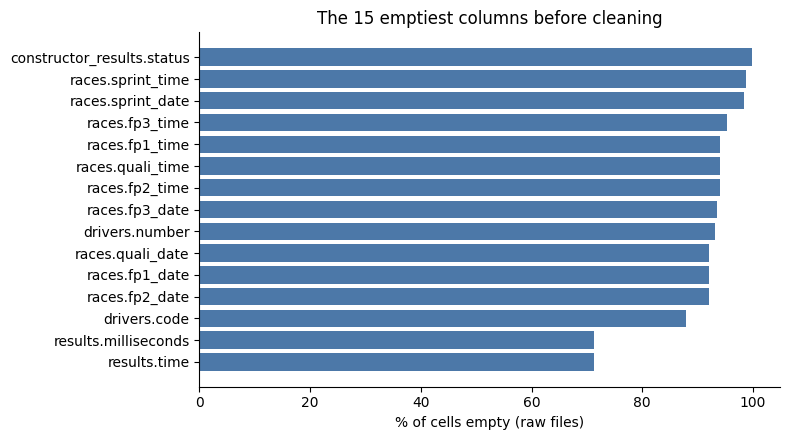

In [3]:
rows = []
for n in NAMES:
    m = RAW[n].isin(NA_VALUES)
    for c in m.columns:
        rows.append((n, c, int(m[c].sum()), len(m)))
before = pd.DataFrame(rows, columns=["table", "column", "n_missing", "n_rows"])
before["pct_missing"] = (before["n_missing"] / before["n_rows"] * 100).round(1)
top = before.sort_values("pct_missing", ascending=False).head(15)
display(top.reset_index(drop=True))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(top["table"] + "." + top["column"], top["pct_missing"], color="#4C78A8")
ax.invert_yaxis(); ax.set_xlabel("% of cells empty (raw files)")
ax.set_title("The 15 emptiest columns before cleaning")
plt.tight_layout(); plt.show()

**Reading the result.** The emptiest columns are structural, not accidental: `constructor_results.status` (99.9 % empty), the sprint and practice session columns of `races` (they exist only for recent seasons), and `drivers.number` / `drivers.code`. None of these can be a feature. The columns that matter for modelling (grid, positions, qualifying times) are far fuller; their gaps are examined where they are used (sections 6 and 7).

### 2.3 Do numbers and text mix inside a column?

**Question.** Is any column a mixture of numbers and text? That could hide an unknown "empty" spelling, or a value in the wrong unit.

**What we do and why.** When pandas reads a column, one stray non-numeric token forces the whole column to text. So we list every column kept as text whose non-missing values are *partly* numbers, and print the most frequent non-numeric tokens of each. If the tokens turn out to be legitimate formats (letter codes, `m:ss.sss` times, `+gap` strings), the column is fine; if they were hidden empty markers, we would have to extend the marker list. The letter codes in `positionText` (R, W, F, N, D, E) are meaningful codes, not missing values; the second table shows how they relate to the empty `position`.

In [4]:
rows = []
for n in NAMES:
    for c in T[n].columns:
        if not pd.api.types.is_numeric_dtype(T[n][c]):
            v = T[n][c].dropna()
            if len(v):
                num = pd.to_numeric(v, errors="coerce").notna()
                if num.any():
                    tokens = v[~num].value_counts().head(4)
                    rows.append((n, c, round(float(num.mean()), 3), ", ".join(f"{k} ({x})" for k, x in tokens.items())))
mixed = pd.DataFrame(rows, columns=["table", "column", "share that are plain numbers", "most frequent non-numeric tokens"])
display(mixed)

r = RAW["results"]
code_ = r["positionText"].where(~r["positionText"].str.isdigit(), "a number")
print("\npositionText codes against whether `position` is empty:")
display(pd.crosstab(code_, r["position"].eq(r"\N").rename("position is empty")))

,table,column,share that are plain numbers,most frequent non-numeric tokens
0,sprint_results,positionText,0.958,"R (13), N (1), W (1)"
1,sprint_results,time,0.874,"25:38.426 (1), +1:08.213 (1), +1:17.648 (1), 2..."
2,pit_stops,duration,0.955,"24:16.349 (2), 2:03.124 (1), 6:29.973 (1), 6:3..."
3,results,positionText,0.591,"R (8897), F (1368), W (336), N (190)"
4,results,time,0.568,"+8:22.19 (5), +1:29.6 (4), +1:15.9 (3), +1:16...."
5,constructor_standings,positionText,0.999,E (17)
6,driver_standings,positionText,1.000,D (1)



positionText codes against whether `position` is empty:


position is empty,False,True
positionText,,
D,0,151
E,0,9
F,0,1368
N,0,190
R,0,8897
W,0,336
a number,15806,2


**Reading the result.** Seven columns mix numbers and text, and in every case the text is a legitimate format, not a hidden empty marker: `positionText` holds the position codes (R retired 8,897, F failed to qualify 1,368, W withdrew 336, N not classified 190), the `time` columns hold gaps such as `+1:29.6` and long durations, `pit_stops.duration` holds stops longer than a minute (`24:16.349`). The crosstab shows the codes line up with the empty `position`: every R/F/W/N/D/E row has an empty `position`, and only 2 numeric-`positionText` rows do (an anomaly, which is one reason the target uses `positionOrder`, which is filled for every row). Every non-numeric token here is a real format, so no empty marker exists beyond the two of 2.1.

### 2.4 Keys: primary keys unique and non-null, foreign keys reconcile

**Question.** Does every table have a column (or column pair) that identifies each row uniquely, and does every reference to another table point to a row that exists? If not, joins would silently drop or duplicate rows.

**What we do and why.** For each table we test its primary key (no nulls, no duplicates) and for every foreign key we count the values that do not exist in the table they point to (orphans). Zero orphans means every join in this notebook is safe, and any row count change after a join must come from our own decisions.

In [5]:
PK = {"status": ["statusId"], "sprint_results": ["resultId"], "seasons": ["year"], "races": ["raceId"],
      "qualifying": ["qualifyId"], "drivers": ["driverId"], "pit_stops": ["raceId", "driverId", "stop"],
      "constructors": ["constructorId"], "results": ["resultId"], "constructor_standings": ["constructorStandingsId"],
      "circuits": ["circuitId"], "constructor_results": ["constructorResultsId"],
      "driver_standings": ["driverStandingsId"], "lap_times": ["raceId", "driverId", "lap"]}
pk_rows = []
for n, cols in PK.items():
    d = T[n]
    pk_rows.append((n, "+".join(cols), int(d[cols].isna().any(axis=1).sum()), int(d.duplicated(cols).sum()), int(d.duplicated().sum())))
pk_check = pd.DataFrame(pk_rows, columns=["table", "primary key", "null keys", "duplicate keys", "fully identical rows"])
display(pk_check)

FK = [("results", "raceId", "races"), ("results", "driverId", "drivers"), ("results", "constructorId", "constructors"),
      ("results", "statusId", "status"), ("qualifying", "raceId", "races"), ("qualifying", "driverId", "drivers"),
      ("qualifying", "constructorId", "constructors"), ("pit_stops", "raceId", "races"), ("pit_stops", "driverId", "drivers"),
      ("lap_times", "raceId", "races"), ("lap_times", "driverId", "drivers"), ("sprint_results", "raceId", "races"),
      ("sprint_results", "driverId", "drivers"), ("sprint_results", "constructorId", "constructors"),
      ("sprint_results", "statusId", "status"), ("driver_standings", "raceId", "races"), ("driver_standings", "driverId", "drivers"),
      ("constructor_standings", "raceId", "races"), ("constructor_standings", "constructorId", "constructors"),
      ("constructor_results", "raceId", "races"), ("constructor_results", "constructorId", "constructors"),
      ("races", "circuitId", "circuits"), ("races", "year", "seasons")]
fk_rows = []
for child, col, parent in FK:
    pcol = col if col in T[parent].columns else PK[parent][0]
    vals = T[child][col]
    fk_rows.append((f"{child}.{col}", f"{parent}.{pcol}", int(vals.isna().sum()), int((~vals.dropna().isin(T[parent][pcol])).sum())))
fk_check = pd.DataFrame(fk_rows, columns=["foreign key", "points to", "null values", "orphans"])
print("foreign keys checked:", len(fk_check), "| total orphans:", int(fk_check["orphans"].sum()), "| total nulls:", int(fk_check["null values"].sum()))
display(fk_check)

,table,primary key,null keys,duplicate keys,fully identical rows
0,status,statusId,0,0,0
1,sprint_results,resultId,0,0,0
2,seasons,year,0,0,0
3,races,raceId,0,0,0
4,qualifying,qualifyId,0,0,0
5,drivers,driverId,0,0,0
6,pit_stops,raceId+driverId+stop,0,0,0
7,constructors,constructorId,0,0,0
8,results,resultId,0,0,0
9,constructor_standings,constructorStandingsId,0,0,0


foreign keys checked: 23 | total orphans: 0 | total nulls: 0


,foreign key,points to,null values,orphans
0,results.raceId,races.raceId,0,0
1,results.driverId,drivers.driverId,0,0
2,results.constructorId,constructors.constructorId,0,0
3,results.statusId,status.statusId,0,0
4,qualifying.raceId,races.raceId,0,0
5,qualifying.driverId,drivers.driverId,0,0
6,qualifying.constructorId,constructors.constructorId,0,0
7,pit_stops.raceId,races.raceId,0,0
8,pit_stops.driverId,drivers.driverId,0,0
9,lap_times.raceId,races.raceId,0,0


**Reading the result.** All 14 tables pass: no null keys, no duplicate keys, no fully identical rows. All 23 foreign keys reconcile: 0 orphans and 0 nulls, so every join in this notebook is safe.

## 3. Semantic typing and outliers

### 3.1 Dates and durations as real types

**What we do and why.** Text cannot be sorted by date or subtracted. Dates become `datetime`, and lap-time strings such as `1:27.452` become seconds (numbers). The conversion is checked to be lossless: the number of missing values must not change.

In [6]:
races = T["races"]
for c in ["date", "fp1_date", "fp2_date", "fp3_date", "quali_date", "sprint_date"]:
    races[c] = pd.to_datetime(races[c])
T["drivers"]["dob"] = pd.to_datetime(T["drivers"]["dob"])
print("race dates:", races["date"].min().date(), "to", races["date"].max().date())

def to_seconds(text):
    # '1:27.452' -> 87.452 ; '23.456' -> 23.456 ; missing or unreadable -> NaN
    if pd.isna(text):
        return np.nan
    try:
        total = 0.0
        for part in str(text).split(":"):          # '1:27.452' = 1 min 27.452 s ; '2:05:05.152' = 2 h 5 min 5.152 s (a red-flag lap)
            total = total * 60 + float(part)
        return total
    except ValueError:
        return np.nan

def convert(table, col, new):
    uniq = T[table][col].dropna().unique()
    mp = {u: to_seconds(u) for u in uniq}
    T[table][new] = T[table][col].map(mp)
    lost = int(T[table][new].isna().sum() - T[table][col].isna().sum())
    return (f"{table}.{col}", f"{new}", int(T[table][col].notna().sum()), lost)

conv = [convert("qualifying", c, c + "_sec") for c in ["q1", "q2", "q3"]]
conv += [convert("results", "fastestLapTime", "fastestLapTime_sec"), convert("lap_times", "time", "time_sec"),
         convert("pit_stops", "duration", "duration_sec")]
conv = pd.DataFrame(conv, columns=["source column", "new column", "values converted", "values lost"])
display(conv)
assert (conv["values lost"] == 0).all(), "a conversion turned a real value into missing"

race dates: 1950-05-13 to 2024-12-08


,source column,new column,values converted,values lost
0,qualifying.q1,q1_sec,10338,0
1,qualifying.q2,q2_sec,5847,0
2,qualifying.q3,q3_sec,3629,0
3,results.fastestLapTime,fastestLapTime_sec,8252,0
4,lap_times.time,time_sec,589081,0
5,pit_stops.duration,duration_sec,11371,0


**Reading the result.** All conversions are lossless (0 values lost). Lap times longer than an hour, such as `2:05:05.152` are read as hours:minutes:seconds, which is why the converter handles any number of `:`-separated parts.

### 3.2 Impossible qualifying times

**Question.** Are there qualifying times that cannot be real lap times?

**What we do and why.** A typo or a unit error would show up as a time many times slower than everyone else in the same session. We compare each time with the **median of its own race** (so the check works in every era, from 1.5-minute laps to 3-minute laps) and flag values above 3 times that median. A flagged value is set to *missing*, never "corrected", because we cannot know the true value.

In [7]:
Q = T["qualifying"]
ratio = Q["q1_sec"] / Q.groupby("raceId")["q1_sec"].transform("median")
display(Q.assign(ratio_to_race_median=ratio).nlargest(5, "ratio_to_race_median")[
    ["raceId", "driverId", "position", "q1", "q1_sec", "ratio_to_race_median"]].round(2))
for c in ["q1", "q2", "q3"]:
    bad = (Q[c + "_sec"] / Q.groupby("raceId")[c + "_sec"].transform("median")) > 3
    print(c, "values above 3x their race median:", int(bad.sum()))
    Q.loc[bad, c + "_sec"] = np.nan
print("slowest Q1 after the fix:", round(Q["q1_sec"].max(), 1), "seconds")

,raceId,driverId,position,q1,q1_sec,ratio_to_race_median
2567,255,87,24,16:42.640,1002.64,9.88
9614,1099,858,20,2:08.510,128.51,1.43
4156,93,47,18,1:46.299,106.30,1.31
2375,247,85,24,1:52.398,112.40,1.23
4038,121,4,20,1:40.405,100.40,1.21


q1 values above 3x their race median: 1
q2 values above 3x their race median: 0
q3 values above 3x their race median: 0
slowest Q1 after the fix: 153.9 seconds


**Reading the result.** One value is impossible: race 255 (1995 Japanese Grand Prix), driver 87, Q1 = 16:42.640 = 1002.6 s, which is **9.88 times** the race median (the next largest ratio is 1.43). It is set to missing. After the fix the slowest Q1 time is 153.9 s, a plausible slow lap.

## 4. Race chronology

**Question.** Every "last 5 races" feature means *the 5 races before this one in time*. Can races be ordered by `raceId`?

**What we do and why.** Compare the order of `raceId` with the order of the race dates, and count how many races sit in a different position. If the two orders differ, any rolling window built on `raceId` would mix the past with the future (leakage). We define `race_order` from `(year, round)` and verify that dates rise monotonically inside every season.

raceId order equals date order: False
races whose raceId position differs from their true position in time: 858 of 1125
share out of place by decade: {1950: 1.0, 1960: 1.0, 1970: 1.0, 1980: 1.0, 1990: 1.0, 2000: 1.0, 2010: 0.1, 2020: 0.18}


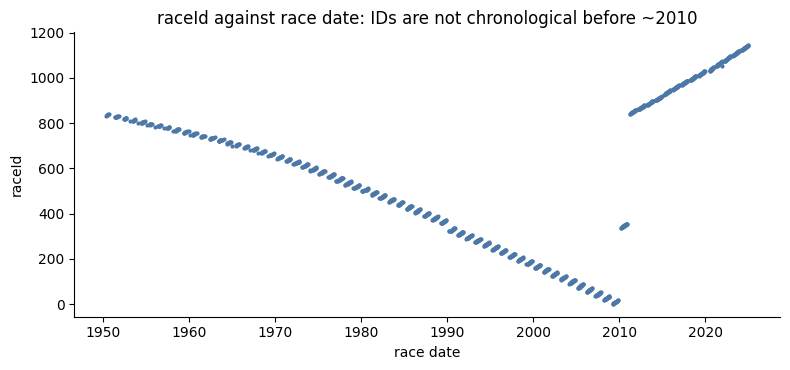

In [8]:
races = T["races"]
print("raceId order equals date order:", races.sort_values("raceId")["raceId"].tolist() == races.sort_values(["date", "raceId"])["raceId"].tolist())
assert not races.duplicated(["year", "round"]).any()
assert races.sort_values(["year", "round"]).groupby("year")["date"].apply(lambda s: s.is_monotonic_increasing).all()

races = races.sort_values(["year", "round"]).reset_index(drop=True)
races["race_order"] = np.arange(len(races))        # 0 = the first race ever; rises with time. The clock of this notebook.
T["races"] = races

r = races.copy()
r["rank_by_id"] = r["raceId"].rank(method="first").astype(int) - 1
wrong = r[r["rank_by_id"] != r["race_order"]]
print("races whose raceId position differs from their true position in time:", len(wrong), "of", len(r))
print("share out of place by decade:", (wrong.groupby(wrong["year"] // 10 * 10).size() / r.groupby(r["year"] // 10 * 10).size()).dropna().round(2).to_dict())

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.scatter(races["date"], races["raceId"], s=4, color="#4C78A8")
ax.set_xlabel("race date"); ax.set_ylabel("raceId"); ax.set_title("raceId against race date: IDs are not chronological before ~2010")
plt.tight_layout(); plt.show()

**Reading the result.** `raceId` order is not date order: **858 of 1,125 races** sit in a different position (100 % of races in every decade up to the 2000s, 10 % in the 2010s, 18 % in the 2020s). The scatter shows two interleaved lines before about 2010. Any "last n races" window built on `raceId` would have mixed past and future; all history features use `race_order`.

## 5. One row per driver per race

**Question.** The modelling table needs exactly one row per `(raceId, driverId)`, because each row is one prediction. Does any driver appear twice in the same race, and which row should we keep?

**What we do and why.** Three steps. (1) Find the repeated pairs and see when they happen. (2) Ask what the rows of a pair say about the driver's race: how many laps each car did and how each ended. If one row is consistently the car that stopped early with a failure, and the other a car that ran on, the first is the car the driver started in. (3) Compare candidate keep-rules on four properties that matter for a pre-race prediction: does the kept row describe the car the driver **started** in (its grid slot and team are the pre-race facts); is the rule chosen **without looking at the outcome**; how many **official podium credits** does the label lose; is the label equal to the official classification.

In [9]:
status_map = T["status"].set_index("statusId")["status"]
res = T["results"].merge(T["races"][["raceId", "year", "race_order"]], on="raceId")
res["status"] = res["statusId"].map(status_map)
res["podium"] = res["positionOrder"] <= 3          # target definition: positionOrder is filled for every row (section 2.3 crosstab)
res["never_started"] = res["positionText"].isin(["F", "W"])
res["_grid0"] = res["grid"].eq(0)

key = ["raceId", "driverId"]
dup_mask = res.duplicated(key, keep=False)
dups = res[dup_mask]
print("duplicate rows:", len(dups), "| (race, driver) pairs:", dups.groupby(key).ngroups,
      "| years:", int(dups["year"].min()), "to", int(dups["year"].max()))
print("rows per pair:", dups.groupby(key).size().value_counts().to_dict(), "| pairs by decade:",
      dups.drop_duplicates(key).groupby(dups["year"] // 10 * 10).size().to_dict())
g = dups.groupby(key)["_grid0"].agg(lambda s: int((~s).sum()))
print("pairs by number of their rows that have a real (non-zero) grid slot:", g.value_counts().sort_index().to_dict())
display(dups.sort_values(key + ["laps"])[["raceId", "year", "driverId", "constructorId", "grid", "positionOrder", "laps", "status"]].head(8))

duplicate rows: 176 | (race, driver) pairs: 85 | years: 1950 to 1978
rows per pair: {2: 79, 3: 6} | pairs by decade: {1950: 79, 1960: 5, 1970: 1}
pairs by number of their rows that have a real (non-zero) grid slot: {0: 3, 2: 76, 3: 6}


,raceId,year,driverId,constructorId,grid,positionOrder,laps,status
13188,540,1978,229,54,0,26,0,Did not qualify
13191,540,1978,229,57,0,29,0,Did not prequalify
24298,717,1964,373,172,1,12,54,Injection
17362,717,1964,373,172,1,7,102,Out of fuel
17740,733,1962,465,172,0,22,0,Withdrew
17743,733,1962,465,97,0,25,0,Withdrew
17963,742,1961,475,172,5,21,44,Brakes
17961,742,1961,475,102,20,19,56,Disqualified


**Reading the result.** **176 rows form 85 repeated (race, driver) pairs** (79 pairs with 2 rows, 6 with 3), in 1950-1978: 79 pairs in the 1950s, 5 in the 1960s, 1 in 1978. The grid column cannot pick the row: in **no** pair does exactly one row have a real grid slot (3 pairs have none, 76 have both, 6 have all three), so the brief's suggestion "keep the non-zero grid" is not a usable rule on its own.

**Which row is the starting car?** For the pairs in which a car actually raced, each row is labelled "fewest laps" or "other row", and we count how each row ended: reached the finish, accident or spin, or another retirement (almost always a failed part), and how often it was a podium. Then two checks of where this reasoning can fail: (a) does `laps` count the driver's own laps or the car's laps (a car driven by two drivers appears once per driver, with the same car number)? (b) a car has one starter, so "fewest laps" must never name the same car as the starting car of two drivers.

In [10]:
# WHICH ROW IS THE STARTING CAR? What do the rows of a repeated pair say about how each car's race went?
reached = lambda s: s.eq("Finished") | s.str.startswith("+")
CRASH = {"Accident", "Collision", "Spun off", "Fatal accident"}
race_name = T["races"].set_index("raceId")["name"]
drv_name = T["drivers"].set_index("driverId")["surname"]
pr = dups[dups.groupby(key)["laps"].transform("max") > 0].copy()          # pairs in which a car raced (the others never started: 6.2)
pr["row"] = np.where(pr.groupby(key)["laps"].rank(method="min").eq(1), "fewest laps", "other row")
pr["ended"] = np.select([reached(pr["status"]), pr["status"].isin(CRASH)], ["reached the finish", "accident or spin"], "other retirement")
print("pairs in which a car raced:", pr.groupby(key).ngroups)
ends = pd.crosstab(pr["row"], pr["ended"], normalize="index").round(3)
ends["podium"] = pr.groupby("row")["podium"].mean().round(3)
ends["rows"] = pr["row"].value_counts()
display(ends)
print("most frequent endings of the fewest-laps rows:", pr.loc[pr["row"] == "fewest laps", "status"].value_counts().head(6).to_dict())

# (a) whose laps does `laps` count? Cars driven by two or more drivers in one race
shared_cars = res[res["laps"] > 0].groupby(["raceId", "number"]).filter(lambda g: g["driverId"].nunique() > 1)
same_laps = shared_cars.groupby(["raceId", "number"])["laps"].nunique().eq(1)
print(f"\n(a) cars driven by two or more drivers in one race: {len(same_laps)} | every driver of the car has the same laps: {int(same_laps.sum())}")

# (b) one car, one starter: drivers who swapped cars have identical rows, so "fewest laps" names the same car for both
first_car = pr[pr["row"] == "fewest laps"].drop_duplicates(key)
clash = first_car.groupby(["raceId", "number"]).filter(lambda g: len(g) > 1)
cl_keys = clash[key].drop_duplicates()
print(f"(b) cars named as the starting car of two drivers: {clash.groupby(['raceId', 'number']).ngroups} | drivers involved: {len(cl_keys)}",
      f"| of them in the Indianapolis 500 (removed in 6.1): {int(cl_keys['raceId'].map(race_name).eq('Indianapolis 500').sum())}")
pair_fin = pr[pr["row"] == "fewest laps"].groupby(key)["ended"].first().eq("reached the finish")
pair_tie = pr.groupby(key)["laps"].apply(lambda s: s.nunique() < len(s))
print(f"pairs in which the fewest-laps car also reached the finish: {int(pair_fin.sum())} | pairs with tied laps: {int(pair_tie.sum())}")

# one example of each case
pr["race"], pr["driver"] = pr["raceId"].map(race_name), pr["driverId"].map(drv_name)
EXAMPLES = {"typical": (1960, "Argentine Grand Prix", ["Moss"]), "swap": (1957, "British Grand Prix", ["Moss", "Brooks"]),
            "both reached the finish": (1956, "Monaco Grand Prix", ["Fangio"])}
ex = pd.concat([pr[(pr["year"] == yr) & (pr["race"] == rc) & pr["driver"].isin(dv)].assign(case=case) for case, (yr, rc, dv) in EXAMPLES.items()])
display(ex.sort_values(["case", "driver", "laps"])[["case", "year", "race", "driver", "number", "grid", "laps", "status", "positionOrder", "row"]].set_index("case"))

pairs in which a car raced: 82


ended,accident or spin,other retirement,reached the finish,podium,rows
row,,,,,
fewest laps,0.169,0.747,0.084,0.012,83
other row,0.057,0.195,0.747,0.264,87


most frequent endings of the fewest-laps rows: {'Engine': 19, 'Accident': 9, 'Gearbox': 6, 'Spun off': 5, 'Magneto': 4, 'Suspension': 4}

(a) cars driven by two or more drivers in one race: 107 | every driver of the car has the same laps: 104
(b) cars named as the starting car of two drivers: 8 | drivers involved: 16 | of them in the Indianapolis 500 (removed in 6.1): 4
pairs in which the fewest-laps car also reached the finish: 7 | pairs with tied laps: 1


,year,race,driver,number,grid,laps,status,positionOrder,row
case,,,,,,,,,
both reached the finish,1956,Monaco Grand Prix,Fangio,20.0,1,99,+1 Lap,4,fewest laps
both reached the finish,1956,Monaco Grand Prix,Fangio,26.0,9,100,Finished,2,other row
swap,1957,British Grand Prix,Brooks,18.0,1,51,Engine,12,fewest laps
swap,1957,British Grand Prix,Brooks,20.0,3,90,Finished,1,other row
swap,1957,British Grand Prix,Moss,18.0,1,51,Engine,12,fewest laps
swap,1957,British Grand Prix,Moss,20.0,3,90,Finished,1,other row
typical,1960,Argentine Grand Prix,Moss,36.0,1,40,Suspension,17,fewest laps
typical,1960,Argentine Grand Prix,Moss,38.0,8,80,Finished,3,other row


**Reading the result.** The rows tell a clear story. In the 82 pairs in which a car raced, the **fewest-laps row** almost always belongs to a car that **stopped early**: 75 % ended in another retirement, almost always a failed part (engine 19, gearbox 6, suspension 4, magneto 4, ...), 17 % in an accident or spin, and only 8 % reached the finish; 1 % was a podium. The **other row** is mostly a car that **ran on**: 75 % reached the finish and 26 % were podiums. So the usual case is a driver whose own car broke and who then took over a teammate's car that was still running, as Moss did in the 1960 Argentine Grand Prix (his car from pole stopped after 40 laps with a suspension failure; the car he took over finished third). **The fewest-laps row is the car the driver started in.**

The two checks show where this fails, and that it is rare:
* **(a) `laps` counts the car, not the driver:** in 104 of the 107 cars driven by two or more drivers in one race, every driver of the car has the same laps. So "fewest laps" means "the car that stopped first".
* **(b) Swaps:** when two drivers swapped cars, both have identical rows, and "fewest laps" names the same car for both. This happens for 8 cars and 16 drivers (4 of them in the 1954 Indianapolis 500, removed in 6.1). Example: in the 1957 British Grand Prix, Moss and Brooks both have car 18 (grid slot 1, 51 laps, engine) and car 20 (grid slot 3, 90 laps, winner). A car has one starter, so in each swap the rule is wrong for one of the two drivers; the data cannot say which.
* **Nothing stopped:** in 7 pairs the fewest-laps car also reached the finish (for example Fangio, 1956 Monaco Grand Prix: 99 laps and 100 laps, both finished), and 1 pair has tied laps. Here the laps cannot show the starting car.

These uncertain pairs are flagged in the next steps instead of being hidden.

In [11]:
r2 = res.sort_values(key + ["laps", "resultId"]).copy()
r2["any_podium"] = r2.groupby(key)["podium"].transform("max")        # official credit: some row of the pair was a podium
pair_min_laps = r2.groupby(key)["laps"].transform("min")

kept = {
    "A  lowest real grid slot":       r2.sort_values(key + ["_grid0", "grid", "resultId"]).drop_duplicates(key),
    "B  best finish":                 r2.sort_values(key + ["positionOrder", "resultId"]).drop_duplicates(key),
    "S  fewest laps (starting car)":  r2.drop_duplicates(key, keep="first"),
    "F  most laps (finishing car)":   r2.drop_duplicates(key, keep="last"),
}
H = kept["S  fewest laps (starting car)"].copy(); H["podium"] = H["any_podium"]
kept["H  starting car + official label"] = H

dkeys = dups[key].drop_duplicates()
by_outcome = {"A": False, "B": True, "S": False, "F": True, "H": False}
start_row = kept["S  fewest laps (starting car)"].merge(dkeys, on=key).set_index(key)
min_laps = r2.groupby(key)["laps"].min()
rows = []
for name, d in kept.items():
    d = d.merge(dkeys, on=key).set_index(key)
    rows.append({"rule": name, "pairs": len(d),
                 "kept row is the fewest-laps row (%)": round(100 * (d["laps"] == min_laps.reindex(d.index)).mean(), 1),
                 "chosen using the outcome": by_outcome[name[0]],
                 "official podium credits lost": int((d["any_podium"] & ~d["podium"]).sum())})
rule_table = pd.DataFrame(rows).set_index("rule")
display(rule_table)

,pairs,kept row is the fewest-laps row (%),chosen using the outcome,official podium credits lost
rule,,,,
A lowest real grid slot,85,69.4,False,17
B best finish,85,3.5,True,0
S fewest laps (starting car),85,100.0,False,21
F most laps (finishing car),85,3.5,True,0
H starting car + official label,85,100.0,False,0


**Reading the result.** Rules B (best finish) and F (most laps) keep the fewest-laps row in only 3.5 % of pairs, and B chooses the row by looking at the outcome. Rule A (lowest real grid slot) keeps the fewest-laps row in 69.4 % of pairs and loses 17 official podium credits; rule S alone (fewest laps) keeps it by definition but loses 21 credits. **Rule H** keeps the fewest-laps row, which the step above shows is the starting car in all but the swaps,, chooses without looking at the outcome, and loses **0** credits, so it is the rule used.

**Decision (rule H).** Keep the features of the **starting car**, the row with the fewest laps (the step above: it is the car that stopped first, usually with a failure, while the driver went on in another car), and give the row the **official podium label** (podium if any of the driver's rows was a podium). Rules B and F choose the row by looking at how the race ended, and A cannot choose in most pairs; S alone loses real podium credits; H keeps the pre-race facts of the starting car **and** the official outcome. The pairs where the evidence cannot settle the starting car are flagged `dedup_ambiguous` instead of being hidden: drivers who swapped cars, pairs where the fewest-laps car also reached the finish, and tied laps.

In [12]:
reached = lambda s: s.eq("Finished") | s.str.startswith("+")
grain = H.drop(columns=["any_podium"]).copy()
grain["podium"] = grain["podium"].astype(bool)

pair_info = r2[dup_mask.reindex(r2.index, fill_value=False)].groupby(key).agg(
    rows=("resultId", "size"), laps_tied=("laps", lambda s: s.nunique() < len(s)))
st = kept["S  fewest laps (starting car)"].merge(dkeys, on=key).set_index(key)["status"]
first_reached = (st.eq("Finished") | st.str.startswith("+")).rename("first_finished")
amb = pair_info.join(first_reached).fillna(False)
amb_keys = pd.concat([amb[(amb["laps_tied"]) | (amb["first_finished"])].reset_index()[key], cl_keys]).drop_duplicates()   # + the swaps found above
grain = grain.merge(amb_keys.assign(dedup_ambiguous=True), on=key, how="left")
grain["dedup_ambiguous"] = grain["dedup_ambiguous"].fillna(False).astype(bool)

assert not grain.duplicated(key).any(), "grain is not unique"
print("rows:", len(grain), "| unique (raceId, driverId):", len(grain.drop_duplicates(key)), "| ambiguous pairs flagged:", int(grain["dedup_ambiguous"].sum()))

pod = grain[grain["podium"]]
shared = pod.groupby(["raceId", "positionOrder"]).size()
print("podium positions held by two or more drivers (shared drives; both kept, official credit):", int((shared > 1).sum()))
n_pod = pod.groupby("raceId").size().reindex(grain["raceId"].unique(), fill_value=0)
odd = n_pod[n_pod != 3]
print("races with other than 3 podium rows:", len(odd), "| years:", int(grain.loc[grain["raceId"].isin(odd.index), "year"].min()), "to", int(grain.loc[grain["raceId"].isin(odd.index), "year"].max()))
print("podium rows in those races:", odd.value_counts().to_dict(),
      "(a driver whose starting car did badly but who took over a podium car gets official credit; his co-driver keeps his own row)")
assert grain.loc[grain["raceId"].isin(odd.index), "year"].max() <= 1960, "an odd podium count outside the shared-drive era needs investigation"

rows: 26668 | unique (raceId, driverId): 26668 | ambiguous pairs flagged: 24
podium positions held by two or more drivers (shared drives; both kept, official credit): 6
races with other than 3 podium rows: 18 | years: 1950 to 1960
podium rows in those races: {4: 16, 5: 2} (a driver whose starting car did badly but who took over a podium car gets official credit; his co-driver keeps his own row)


**Reading the result.** **26,668 rows, one per (race, driver)**. 24 pairs are flagged `dedup_ambiguous`: the 7 pairs in which both cars reached the finish, the tied pair, and the swaps of the step above. 18 races (all 1950-1960) have more than 3 podium rows: in 16 there are 4 and in 2 there are 5. These are shared drives: two drivers share a position (6 shared positions), or a driver gets official podium credit for a car he took over while his own row from his starting car finished lower. Both drivers keep their official credit, and the assertion confirms nothing outside 1950-1960 is odd.

## 6. Scope of the table

### 6.1 The Indianapolis 500

**Question.** The Indianapolis 500 counted as a round of the world championship in 1950-1960. Is it the same kind of race as the others?

**What we do and why.** Compare it with the other races on the three things that matter for a podium model: do its drivers also race elsewhere (so their history can be learned), how many cars start, and how different is the podium rate. If its drivers are strangers to the rest of the data, their rows carry no usable history, and the model would learn a different game from them.

In [13]:
rname = T["races"].set_index("raceId")["name"]
grain["is_indy"] = grain["raceId"].map(rname).str.contains("Indianapolis") & (grain["year"] <= 1960)
per_driver = grain.groupby("driverId").agg(starts=("raceId", "size"), indy=("is_indy", "sum"))
in_indy = per_driver[per_driver["indy"] > 0]
print("Indy rows:", int(grain["is_indy"].sum()), "in", grain.loc[grain["is_indy"], "raceId"].nunique(), "races")
print("drivers who start an Indy 500:", len(in_indy), "| of them who appear ONLY at Indy:", int((in_indy["starts"] == in_indy["indy"]).sum()))
early = grain[grain["year"] <= 1960]
print("podium rate (Indy vs the rest, 1950-60):", early.groupby("is_indy")["podium"].mean().round(3).to_dict())
print("average field size (Indy vs the rest, 1950-60):", early.groupby("is_indy")["raceId"].apply(lambda s: round(len(s) / s.nunique(), 1)).to_dict())
model_base = grain[~grain["is_indy"]].copy()
print("rows:", len(grain), "->", len(model_base))

Indy rows: 381 in 11 races
drivers who start an Indy 500: 107 | of them who appear ONLY at Indy: 103
podium rate (Indy vs the rest, 1950-60): {False: 0.151, True: 0.094}
average field size (Indy vs the rest, 1950-60): {False: 21.2, True: 34.6}
rows: 26668 -> 26287


**Reading the result.** 381 rows in 11 races. **103 of the 107 drivers who start an Indy 500 appear nowhere else**, so their rows carry no history that could be learned from or applied to the other races. The field is also a different size (34.6 cars against 21.2), and the podium rate differs (9.4 % against 15.1 %). The Indy 500 rows are excluded (26,668 to 26,287 rows).

### 6.2 Drivers who never started

**Question.** Results include drivers who failed to qualify or withdrew. Do they belong in a table of "drivers who raced"? And what does `grid = 0` mean?

**What we do and why.** Cross-tabulate `grid = 0` against the position codes F (failed to qualify) and W (withdrew). Three groups can appear: (1) grid 0 **and** never started, which had no place on the grid and cannot take the podium; (2) a real grid slot but code F or W (they had a slot at the cutoff, so they are legitimate rows with label 0); (3) grid 0 **but they did race** (pit-lane starts), for whom 0 is not a position. Each group gets its own treatment, backed by its podium rate.

In [14]:
mb = model_base.copy()
ct = pd.crosstab(mb["grid"].eq(0).rename("grid is 0"), mb["never_started"].rename("never started (F or W)"), margins=True)
display(ct)
g1 = mb[mb["grid"].eq(0) & mb["never_started"]]
g2 = mb[~mb["grid"].eq(0) & mb["never_started"]]
g3 = mb[mb["grid"].eq(0) & ~mb["never_started"]]
print(f"(1) grid 0 and never started: {len(g1)} rows, podium rate {g1['podium'].mean():.3f}")
print(f"(2) real grid slot but F/W:   {len(g2)} rows, podium rate {g2['podium'].mean():.3f}, share with 0 laps {(g2['laps'] == 0).mean():.2f}")
print(f"(3) grid 0 but they raced:    {len(g3)} rows, podium rate {g3['podium'].mean():.3f}, podiums {int(g3['podium'].sum())}; top statuses {g3['status'].value_counts().head(3).to_dict()}")

never started (F or W),False,True,All
grid is 0,,,
False,24499,153,24652
True,87,1548,1635
All,24586,1701,26287


(1) grid 0 and never started: 1548 rows, podium rate 0.000
(2) real grid slot but F/W:   153 rows, podium rate 0.000, share with 0 laps 0.96
(3) grid 0 but they raced:    87 rows, podium rate 0.000, podiums 0; top statuses {'+1 Lap': 27, 'Finished': 22, '+2 Laps': 7}


**Reading the result.** Group (1) has **1,548 rows and a 0 % podium rate**; group (2) has 153 rows, a 0 % podium rate and 96 % with zero laps (so they had a slot but did not run); group (3) has 87 rows who did race (statuses `+1 Lap`, `Finished`), with a 0 % podium rate and no podium among them, showing that `grid = 0` there is a pit-lane or unrecorded start.

**Decision.** Drop group (1): no grid slot and no start, 0 % podium rate. Keep group (2) with label 0 (they hold a slot at the cutoff). For group (3), `grid = 0` is a pit-lane or unrecorded start, so it is recoded to one place behind the last real grid slot of that race, and a flag `grid_unassigned` records that the recode happened (so the model can tell a real back-row start from an assigned one).

In [15]:
drop = mb["never_started"] & mb["grid"].eq(0)
clean = mb[~drop].copy()
clean["field"] = clean.groupby("raceId")["raceId"].transform("size")                 # number of cars that started
back = clean.groupby("raceId")["grid"].transform("max") + 1
clean["grid_unassigned"] = clean["grid"].eq(0).astype(int)
clean["grid"] = np.where(clean["grid"].eq(0), back, clean["grid"]).astype(int)
clean["grid_rel"] = clean["grid"] / clean["field"]
clean["decade"] = clean["year"] // 10 * 10
clean = clean.drop(columns=["_grid0", "is_indy"]).reset_index(drop=True)

assert not clean.duplicated(key).any() and (clean["grid"] > 0).all()
print("rows:", len(mb), "->", len(clean), "| dropped:", int(drop.sum()), "| recoded to the back:", int(clean["grid_unassigned"].sum()))
print("podium rate:", round(mb["podium"].mean(), 4), "->", round(clean["podium"].mean(), 4))

rows: 26287 -> 24739 | dropped: 1548 | recoded to the back: 87
podium rate: 0.1278 -> 0.1358


**Reading the result.** 26,287 to **24,739 rows**: 1,548 dropped, 87 recoded to the back of the grid with `grid_unassigned = 1`. The podium rate moves from 12.78 % to 13.58 % because the dropped rows were all non-podium.

### 6.3 EDA before and after cleaning

**Question.** What did the cleaning change, and for which eras? (The milestone asks for the exploratory analysis both before and after cleaning.)

**What we do and why.** Compare rows, podium rate and field size per decade between the raw results table and the cleaned table. If the cleaning is sound, it should change the early decades (where duplicates, non-starters and the Indy 500 sit) and leave the modern ones almost unchanged.

,rows_raw,rows_clean,podium_rate_raw,podium_rate_clean,field_raw,field_clean
decade,,,,,,
1950,2007,1507,0.1360,0.1579,23.9,20.4
1960,2113,1878,0.1425,0.1587,21.1,19.0
1970,3807,3456,0.1135,0.1250,26.4,24.0
1980,4503,3942,0.1039,0.1187,28.9,25.3
1990,4250,3897,0.1144,0.1247,26.2,24.1
2000,3643,3635,0.1433,0.1436,20.9,20.9
2010,4297,4289,0.1382,0.1385,21.7,21.7
2020,2139,2135,0.1501,0.1504,20.0,20.0


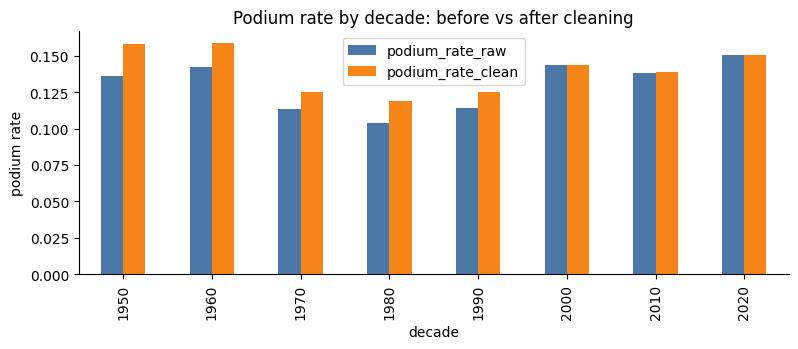

In [16]:
raw_r = res.copy(); raw_r["decade"] = raw_r["year"] // 10 * 10
cmp_ = pd.DataFrame({
    "rows_raw": raw_r.groupby("decade").size(), "rows_clean": clean.groupby("decade").size(),
    "podium_rate_raw": raw_r.groupby("decade")["podium"].mean().round(4), "podium_rate_clean": clean.groupby("decade")["podium"].mean().round(4),
    "field_raw": raw_r.groupby("decade").apply(lambda d: round(len(d) / d["raceId"].nunique(), 1)),
    "field_clean": clean.groupby("decade").apply(lambda d: round(len(d) / d["raceId"].nunique(), 1))})
display(cmp_)
cmp_[["podium_rate_raw", "podium_rate_clean"]].plot.bar(figsize=(8, 3.6), color=["#4C78A8", "#F58518"])
plt.ylabel("podium rate"); plt.title("Podium rate by decade: before vs after cleaning"); plt.tight_layout(); plt.show()

**Reading the result.** Cleaning only touched the early decades: the podium rate moves from 13.6 % to 15.8 % in the 1950s and from 10.4 % to 11.9 % in the 1980s, while the 2000s, 2010s and 2020s are essentially unchanged (14.33 % to 14.36 %, 13.82 % to 13.85 %, 15.01 % to 15.04 %). Field sizes drop by 2 to 4 cars per race in the early decades (non-starters removed). That is the signature of a sound cleaning: it removed the oversized, uneven old fields without disturbing modern data.

**Missing values after cleaning.** Section 2.2 counted the empty cells of the raw tables. The same count is repeated on the cleaned driver-race table (one row per driver per race, non-starters removed, section 6.2) for the columns it shares with `results`, so the effect of the cleaning on missingness can be seen.

,raw results (%),cleaned table (%)
time,71.3,69.5
milliseconds,71.3,69.5
fastestLap,69.2,66.6
fastestLapSpeed,69.2,66.6
fastestLapTime,69.2,66.6
rank,68.2,65.6
position,40.9,37.2


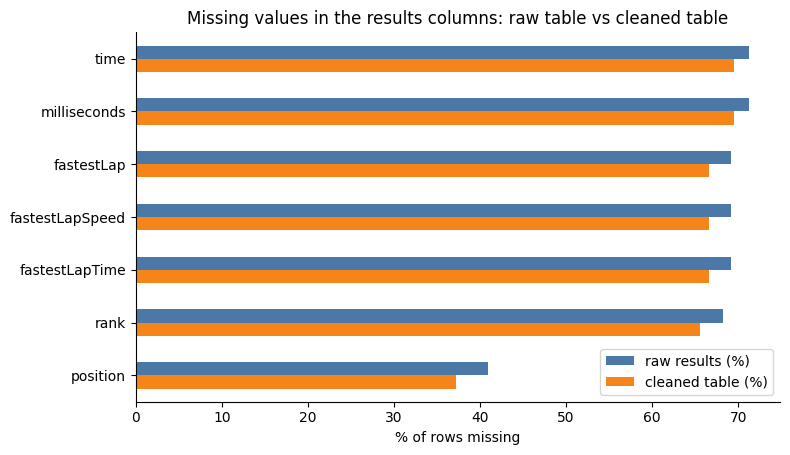

In [17]:
cols_r = [c for c in RAW["results"].columns if c in clean.columns]
miss_cmp = pd.DataFrame({"raw results (%)": RAW["results"][cols_r].isin(NA_VALUES).mean() * 100,
                         "cleaned table (%)": clean[cols_r].isna().mean() * 100}).round(1)
miss_cmp = miss_cmp[(miss_cmp > 0).any(axis=1)].sort_values("raw results (%)", ascending=False)
display(miss_cmp)
miss_cmp.plot.barh(figsize=(8, 0.45 * len(miss_cmp) + 1.5), color=["#4C78A8", "#F58518"])
plt.xlabel("% of rows missing"); plt.title("Missing values in the results columns: raw table vs cleaned table")
plt.gca().invert_yaxis(); plt.tight_layout(); plt.show()


**Reading the result.** Cleaning lowers the share of empty cells a little in every results column (for example `position` 40.9 % to 37.2 %, `time` 71.3 % to 69.5 %), because the removed rows (non-starters, the Indy 500, duplicate shared-drive rows) had no finishing position or time. The columns that stay mostly empty (`time`, `milliseconds`, the fastest-lap columns and `rank`, 66-70 %) are race results, so they are never features: `time` exists only for classified finishers and fastest-lap data only from 2004. The columns the model needs, `grid` and the target `positionOrder`, have no gaps before or after cleaning.

### 6.4 Does the same starting slot mean the same thing in every era?

**Question.** Is the starting grid a stable signal, or does its meaning depend on the era and on how many cars start?

**What we do and why.** Plot the podium rate by grid slot for each decade, then by *relative* grid (slot divided by field size), and the field size by year. If curves differ by decade at the same slot but line up on the relative scale, then the field size explains the difference and the relative grid is a better common scale. This is the evidence for considering `grid_rel` and `field` as candidates in the selection (section 10).

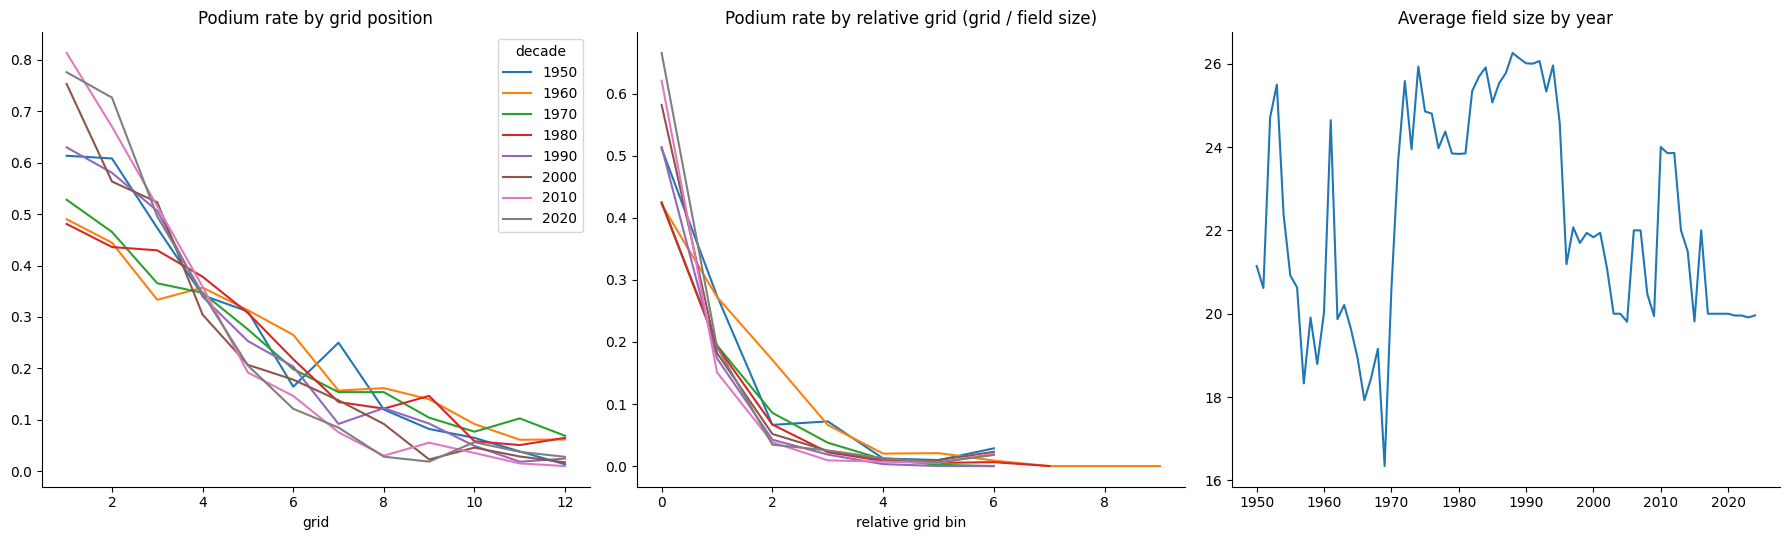

In [18]:
fig, ax = plt.subplots(1, 3, figsize=(18, 5.5))
for dcd, g in clean[clean["grid"] <= 12].groupby("decade"):
    ax[0].plot(g.groupby("grid")["podium"].mean(), label=int(dcd))
ax[0].set_title("Podium rate by grid position"); ax[0].set_xlabel("grid"); ax[0].legend(fontsize=10, title="decade")
clean["rel_bin"] = pd.cut(clean["grid_rel"], 10, labels=False)
for dcd, g in clean.groupby("decade"):
    ax[1].plot(g.groupby("rel_bin")["podium"].mean(), label=int(dcd))
ax[1].set_title("Podium rate by relative grid (grid / field size)"); ax[1].set_xlabel("relative grid bin")
ax[2].plot(clean.groupby("year")["field"].mean()); ax[2].set_title("Average field size by year")
plt.tight_layout(); plt.show()
clean = clean.drop(columns="rel_bin")

**Reading the figure.** (A) In every decade the podium chance falls steeply with the grid slot (about 50-80 % from pole, close to 0 beyond P8). (B) On the relative grid the decade curves lie close together except at the very front, which supports `grid_rel` as a common scale; (C) the average field size falls from about 25 (1980s-90s) to about 20 (2010s on). Both `grid_rel` and `field` therefore go into the candidate list, and section 10 tests whether they add anything beyond the raw slot.

## 7. Qualifying data

### 7.1 Can qualifying be joined safely, and from which season is it usable?

**Question.** (a) Is `(raceId, driverId)` unique in the qualifying table, so the join cannot duplicate rows? (b) From which season do we have qualifying times for (nearly) every driver?

**What we do and why.** (a) Check uniqueness, then left-join onto the clean table with `validate="one_to_one"` (pandas raises an error if the join would duplicate rows). (b) Compute, for each season, the share of rows with a qualifying position, and the share of races that have qualifying at all. This shows from which season qualifying information exists. Older seasons stay in the training data, but a model must be told which rows have no qualifying data, so that a filled value is not read as a real one (section 9.6b).

repeated (race, driver) pairs in qualifying: 0


,rows,share_with_quali,races,races_with_quali
year,,,,
1994,415,0.94,16,15
1995,417,1.00,17,17
1996,338,0.44,16,7
1997,375,0.59,17,10
1998,347,0.44,16,7
1999,351,0.19,16,3
2000,371,0.24,17,4
2001,373,0.06,17,1
2002,358,0.12,17,2


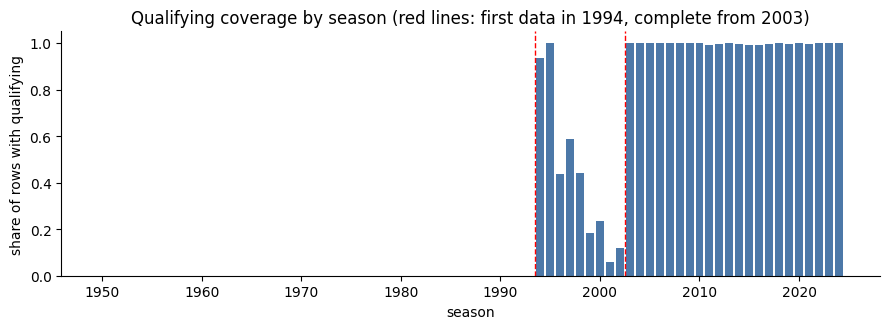

seasons before 1994 with any qualifying data: 0
races with some qualifying: 494 | fully covered: 469 | partially covered: 25
partially covered races by year: {1994: 1, 1996: 3, 1997: 1, 2011: 4, 2012: 3, 2014: 1, 2015: 3, 2016: 5, 2017: 2, 2019: 1, 2021: 1}


In [19]:
Q = T["qualifying"]
print("repeated (race, driver) pairs in qualifying:", int(Q.duplicated(key).sum()))
Qs = Q[key + ["position", "q1_sec", "q2_sec", "q3_sec"]].rename(columns={"position": "q_pos"})
df = clean.merge(Qs, on=key, how="left", validate="one_to_one")
assert len(df) == len(clean)
df["has_q"] = df["q_pos"].notna()

cov = df.groupby("year").agg(rows=("has_q", "size"), share_with_quali=("has_q", "mean"))
cov["races"] = df.groupby("year")["raceId"].nunique()
cov["races_with_quali"] = df.groupby(["year", "raceId"])["has_q"].max().groupby("year").sum()
display(cov.loc[1994:2008].round(2))
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.bar(cov.index, cov["share_with_quali"], color="#4C78A8")
for x_ in (1993.5, 2002.5):
    ax.axvline(x_, color="red", ls="--", lw=1)
ax.set_xlabel("season"); ax.set_ylabel("share of rows with qualifying")
ax.set_title("Qualifying coverage by season (red lines: first data in 1994, complete from 2003)")
plt.tight_layout(); plt.show()

per_race = df.groupby(["year", "raceId"])["has_q"].mean().reset_index(name="share")
covered = per_race[per_race["share"] > 0]
partial = covered[covered["share"] < 0.99]
print("seasons before 1994 with any qualifying data:", int((cov.loc[:1993, "share_with_quali"] > 0).sum()))
print("races with some qualifying:", len(covered), "| fully covered:", int((covered["share"] >= 0.99).sum()), "| partially covered:", len(partial))
print("partially covered races by year:", partial["year"].value_counts().sort_index().to_dict())

**Reading the result.** 0 repeated pairs in qualifying, so the one-to-one join is safe. Three tiers: **1994-95** almost complete, **1996-2002 patchy** (6 % to 59 % of rows, 1 to 10 races per season), and **2003 onward complete** (100 % of rows). 494 races have qualifying data; 469 are fully covered and 25 partly (5 in 1994-97, then single drivers in 2011-2021, such as drivers who set no time). Before 1994 there is no qualifying data at all. These seasons stay in training: their qualifying columns are missing, and the flag `has_quali` (9.6b) tells the models so.

### 7.2 Qualifying features

**What we do and why.** Six qualifying columns are built; all are fixed once the qualifying session ends, so they are valid at the prediction cutoff. `q_pos` is the qualifying position (differs from the grid when penalties apply); `q_gap_pct` is the gap to pole in percent (size of the deficit, comparable across tracks); `q_reached` is the last part of qualifying reached (1, 2 or 3; Q3 means a top-10 car); `grid_minus_q` is grid minus qualifying position (penalties); `q1_gap_pct` is the gap in the first session only (available in every format since 1996); `q_last_gap_pct` is the gap to the fastest time *in the last session the driver took part in*. A seventh column, `q_knockout`, records whether the race used the knockout format (Q1, Q2, Q3); section 7.3 shows why it is needed. Where a race has no qualifying at all, the values stay **missing** (`has_q = 0`), because "no qualifying existed" is not the same as "set no time". The checks below use the training rows of races that have qualifying data (1994-2019); the rows without it are marked by the flag `has_quali` (9.6b).

In [20]:
df["q_best_sec"] = df[["q1_sec", "q2_sec", "q3_sec"]].min(axis=1)
pole = df.groupby("raceId")["q_best_sec"].transform("min")
df["q_gap_pct"] = (df["q_best_sec"] - pole) / pole * 100
q1_best = df.groupby("raceId")["q1_sec"].transform("min")
df["q1_gap_pct"] = (df["q1_sec"] - q1_best) / q1_best * 100

df["last_sess"] = np.select([df["q3_sec"].notna(), df["q2_sec"].notna(), df["q1_sec"].notna()], [3, 2, 1], default=0)
df["last_time"] = np.select([df["last_sess"] == 3, df["last_sess"] == 2, df["last_sess"] == 1], [df["q3_sec"], df["q2_sec"], df["q1_sec"]], default=np.nan)
best_in_sess = df[df["last_sess"] > 0].groupby(["raceId", "last_sess"])["last_time"].transform("min")
df["q_last_gap_pct"] = (df["last_time"] - best_in_sess.reindex(df.index)) / best_in_sess.reindex(df.index) * 100
df["q_reached"] = df["last_sess"].astype(float)
df["race_has_q"] = df.groupby("raceId")["has_q"].transform("max").astype(int)
df.loc[df["race_has_q"] == 0, "q_reached"] = np.nan
df["q_knockout"] = df.groupby("raceId")["q2_sec"].transform(lambda s: int(s.notna().any()))   # 1 = knockout format (some driver in the race has a Q2 time)
df["grid_minus_q"] = df["grid"] - df["q_pos"]
df["has_q"] = df["has_q"].astype(int)
df = df.drop(columns=["last_sess", "last_time"])

# the training rows (up to 2019) of races that have qualifying data (1994 on); races without any qualifying stay missing (has_q = 0)
QCOLS = ["q_pos", "q_gap_pct", "q_reached", "q1_gap_pct", "q_last_gap_pct", "grid_minus_q"]
qrows = df["race_has_q"].eq(1) & df["year"].le(2019)
tier = np.where(df["year"] <= 2002, "1994-2002", "2003-2019")
print("training rows in races with qualifying data:", int(qrows.sum()), "of", int(df["year"].le(2019).sum()))
print("missing share inside races with qualifying data:"); display(df[qrows].groupby(tier[qrows])[QCOLS].apply(lambda g: g.isna().mean()).round(3))
both_q = qrows & df["q_pos"].notna()
print("share of these starters with grid != qualifying position:", round(float((df.loc[both_q, "grid"] != df.loc[both_q, "q_pos"]).mean()), 3))
display(df.loc[qrows, QCOLS].describe().round(2))

training rows in races with qualifying data: 8376 of 22604
missing share inside races with qualifying data:


,q_pos,q_gap_pct,q_reached,q1_gap_pct,q_last_gap_pct,grid_minus_q
1994-2002,0.006,0.027,0.0,0.027,0.027,0.006
2003-2019,0.003,0.018,0.0,0.018,0.018,0.003


share of these starters with grid != qualifying position: 0.224


,q_pos,q_gap_pct,q_reached,q1_gap_pct,q_last_gap_pct,grid_minus_q
count,8345.00,8210.00,8376.0,8210.00,8210.00,8345.00
mean,11.37,2.51,1.8,2.02,1.57,-0.00
std,6.36,2.57,0.9,2.00,1.88,1.41
min,1.00,0.00,0.0,0.00,0.00,-9.00
25%,6.00,0.94,1.0,0.79,0.32,0.00
50%,11.00,1.97,2.0,1.50,1.03,0.00
75%,17.00,3.31,3.0,2.64,2.19,0.00
max,26.00,37.80,3.0,33.29,33.29,23.00


**Reading the result.** 8,376 of the 22,604 training rows come from races with qualifying data (1994-2019); the other 14,228 come from races without any and are marked by `has_quali` (9.6b). Inside races with qualifying data, values are rarely missing: `q_pos` in 0.6 % of rows in 1994-2002 and 0.3 % in 2003-2019, the gap columns in 2.7 % and 1.8 % (drivers who set no time). **22.4 % of these starters have a grid slot different from their qualifying position**, which is why qualifying and grid cannot be treated as the same column. `q_gap_pct` has a long upper tail (maximum 37.8 %), handled in section 11. `q_reached` shows 0 % missing here, which hides a problem: section 7.3.

### 7.3 Does `q_reached` mean the same thing in every season?

**Question.** Qualifying has used a three-round knockout (Q1, Q2, Q3) only since 2006; 2005 mixed formats (newcomers guide, "Qualifying formats through history"). From 1994 to 2004 the data hold only one qualifying time per driver. In a race without Q2 and Q3 every driver has only a Q1 time, so `q_reached` is 1 for the whole field, including the pole-sitter. Does the value 1 then mean two different things?

**What we do and why.** `q_knockout` is 1 when at least one driver in the race has a Q2 time. On the training seasons with qualifying data (1994-2019) we compare the rows with `q_reached = 1` in single-session races and in knockout races: how many rows, their podium rate, their average grid slot and how many pole-sitters they contain. We also show the share of rows with a Q2 time per season, and the Spearman correlation of `q_reached` with the grid slot with and without the single-session races. If the two groups differ sharply, one number describes two different things and every model is forced to fit one weight to both.

**The fix.** In a single-session race `q_reached` and `q_last_gap_pct` do not exist, so they are set to **missing** (filled with the median like any other gap, section 11), and `q_knockout` tells the models which rows these are, the same way `grid_unassigned` marks a recoded grid slot (6.2). `q_gap_pct` (gap to pole) means the same thing in every format and is not changed.

In [21]:
trq = df[df["year"].le(2019) & df["race_has_q"].eq(1)]          # training rows of races with qualifying data (1994-2019)
q1_only = trq[trq["q_reached"] == 1]
fmt = q1_only.groupby("q_knockout").agg(rows=("podium", "size"), podium_rate=("podium", "mean"),
                                        mean_grid=("grid", "mean"), pole_sitters=("q_pos", lambda s: int((s == 1).sum())))
fmt.index = fmt.index.map({0: "single-session race (no Q2)", 1: "knockout race"})
print("rows with q_reached = 1, training seasons with qualifying data (1994-2019):")
display(fmt.round(3))
print("share of rows with a Q2 time, by season (races with qualifying data):")
display(trq[trq["year"].le(2008)].groupby("year")["q2_sec"].apply(lambda s: s.notna().mean()).round(2).to_frame("share with Q2").T)
for label, rows in (("all races", trq), ("knockout races only", trq[trq["q_knockout"] == 1])):
    print(f"Spearman rho of q_reached with grid, 1994-2019, {label}:", round(spearmanr(rows["q_reached"], rows["grid"], nan_policy="omit")[0], 3))

# the fix
single = df["race_has_q"].eq(1) & df["q_knockout"].eq(0)
df.loc[single, ["q_reached", "q_last_gap_pct"]] = np.nan
print("rows set to missing:", int(single.sum()), "| seasons:", int(df.loc[single, "year"].min()), "to", int(df.loc[single, "year"].max()),
      "| all in the training seasons:", bool(df.loc[single, "year"].le(2019).all()))


rows with q_reached = 1, training seasons with qualifying data (1994-2019):


,rows,podium_rate,mean_grid,pole_sitters
q_knockout,,,,
single-session race (no Q2),2406,0.139,11.421,112
knockout race,1547,0.008,18.683,0


share of rows with a Q2 time, by season (races with qualifying data):


year,1994,1995,1996,1997,1998,1999,2000,2001,2002,2003,2004,2005,2006,2007,2008
share with Q2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.28,0.72,0.71,0.73


Spearman rho of q_reached with grid, 1994-2019, all races: -0.592
Spearman rho of q_reached with grid, 1994-2019, knockout races only: -0.888
rows set to missing: 2494 | seasons: 1994 to 2005 | all in the training seasons: True


**Reading the result.** **The value `q_reached = 1` means two different things.** In the training seasons with qualifying data (1994-2019) it covers:
* **2,406 rows from single-session races** (1994-2005): podium rate **13.9 %**, average grid slot 11.4, and **112 pole-sitters**. Here 1 only says "this race had one session".
* **1,547 rows from knockout races:** podium rate **0.8 %**, average grid slot 18.7, no pole-sitter. Here 1 means "eliminated in Q1".

For example, Michael Schumacher on pole in Australia 2004 has `q_reached = 1`, the same value as a car knocked out in Q1 in 2010. The season table confirms the formats: no Q2 times at all from 1994 to 2004, 28 % of rows in 2005, about 72 % from 2006. The mixing weakens the column: its correlation with the grid slot is -0.59 over all these races but -0.89 over knockout races only.

**After the fix** 2,494 rows have `q_reached` and `q_last_gap_pct` missing: every row of a single-session race with qualifying data (1994-2005), all in the training seasons. Section 11 fills them with the median and `q_knockout = 0` marks them. Every validation and test race is a knockout race (`q_knockout = 1`), so the fix only changes what the models learn from 1994-2005.

## 8. Train / validation / test split

### 8.1 Splitting by season

**Question.** How do we split the rows so the reported scores are honest?

**What we do and why.** We split by **season, in time order**, because the real task is to predict future races from the past. A random split would put races of the same weekend (same cars, same weather, same drivers) on both sides and make the model look better than it is.

* **Train: up to 2019.** The models learn from these rows.
* **Validation: 2020-2021.** Used to choose models, thresholds and preprocessing.
* **Test: 2022 onward.** Never used until the final scores are reported.

Section 14.11 checks the choice with an experiment: the final model is also trained on a random 70/30 split, and the two are compared on the same 2022-24 rows.

**Training uses every season from 1950**; the reason is in 8.2.

In [22]:
TRAIN_END, VAL_YEARS, TEST_START = 2019, (2020, 2021), 2022
TRAIN_START = 1950                                   # every season: older seasons are kept, and flags (9.6b) mark what they lack
df["split"] = np.select([df["year"] <= TRAIN_END, df["year"].between(*VAL_YEARS), df["year"] >= TEST_START], ["train", "validation", "test"], default="")
sp = df.groupby("split").agg(rows=("podium", "size"), races=("raceId", "nunique"), first_year=("year", "min"), last_year=("year", "max"), podium_rate=("podium", "mean")).round(3)
sp.loc[f"train ({TRAIN_START}+, used for modelling)"] = [int((df["split"].eq("train") & (df["year"] >= TRAIN_START)).sum()),
    df.loc[df["split"].eq("train") & (df["year"] >= TRAIN_START), "raceId"].nunique(), TRAIN_START, TRAIN_END,
    round(df.loc[df["split"].eq("train") & (df["year"] >= TRAIN_START), "podium"].mean(), 3)]
display(sp)
assert df.loc[df["split"] == "train", "year"].max() < df.loc[df["split"] == "validation", "year"].min() <= df.loc[df["split"] == "validation", "year"].max() < df.loc[df["split"] == "test", "year"].min()

,rows,races,first_year,last_year,podium_rate
split,,,,,
test,1356.0,68.0,2022.0,2024.0,0.150
train,22604.0,1007.0,1950.0,2019.0,0.134
validation,779.0,39.0,2020.0,2021.0,0.150
"train (1950+, used for modelling)",22604.0,1007.0,1950.0,2019.0,0.134


**Reading the result.** Train (up to 2019): 22,604 rows in 1,007 races, podium rate 13.4 %; all of them are used for modelling (8.2). Validation (2020-21): 779 rows, 39 races, podium rate 15.0 %. Test (2022-24): 1,356 rows, 68 races, 15.0 %, untouched in this notebook. The check confirms the blocks do not overlap and are in time order. Validation has only 39 races, so small differences between close models will be hard to trust.

### 8.2 Why training uses every season

**Choice.** The models learn from every training season, 1950 to 2019, not only from the seasons with complete qualifying data.

**Why.**
* **Dropping seasons throws away information.** Most features (grid, recent form, standings, teammate) exist in every season. Only qualifying (from 1994, complete from 2003), lap times (from 1996) and constructor standings (from 1958) do not. Dropping every older season because some columns are missing would also drop the information the other columns still carry.
* **Missing information is marked, not invented.** Where a source does not exist, the value is filled and an availability flag tells the model that the value is not real. This is the standard missing-indicator approach for structural gaps.
* **Old seasons are a different racing world** (weaker reliability, larger fields; 6.4). Whether old rows should count less is tested in 9.4b (recency weights), and whether a later start would predict better is checked with the final features in 10.5.
* **Rows that belong to a different task are still removed, with evidence:** the Indianapolis 500 (6.1) and drivers who never started (6.2).

## 9. Building the candidate features

### 9.1 The registry: all 48 candidates, defined before any test

**Question.** Which features could plausibly help predict a podium from pre-race information, and is each one **valid at the cutoff** (known after qualifying, before the start)?

**What we do and why.** A feature is a **candidate** only if (a) there is a reason it could matter, from the sport or from the exploration above, and (b) it can be computed without anything from the race itself. The registry lists each candidate with its definition, source table, why it might help and why it is valid before the race. Candidates are written down *before* testing, so the selection in section 10 cannot be accused of searching for whatever fits.

A candidate is a **unit**: columns that make no sense alone stay together (`age` with `age^2`, the sine and cosine of the race month, the era indicators). That gives 48 units. History features average the **last W races** (W is chosen in 9.4) and are always shifted so a race never sees itself.

**Sprint races are not used.** A sprint is run before the Sunday race, so its result is technically known at the cutoff (newcomers guide). We do not use it: sprints exist only from 2021, so the training seasons (up to 2019) contain none and no model could learn what a sprint result means; and in 2021-22 the sprint result set the Sunday grid, so for those races its information is already inside `grid`. The cell after the registry checks both claims.

In [23]:
R = []   # (unit, group, columns, definition, source, why it might help, why it is valid before the race, first season available)
def reg(unit, group, cols, definition, source, why, valid, since):
    R.append(dict(unit=unit, group=group, cols=cols, definition=definition, source=source, why_it_may_help=why, valid_before_race=valid, available_from=since))

reg("grid_rel", "grid", ["grid_rel"], "grid slot / number of cars that started", "results", "The same slot means more in a small field (podium rate is about 3 / field size; section 6.4).", "The grid is fixed before the start.", 1950)
reg("field", "grid", ["field"], "number of cars that started", "results", "A bigger field dilutes the chance of any one car finishing in the top 3.", "The number of starters is known at the grid.", 1950)
reg("q_pos", "qualifying", ["q_pos"], "position in qualifying", "qualifying", "Qualifying order is the cleanest read of pure pace, before penalties.", "Qualifying ends before the race.", 1994)
reg("q_gap_pct", "qualifying", ["q_gap_pct"], "best qualifying time as % slower than pole", "qualifying", "The size of the deficit to pole, comparable across tracks, says more than the rank.", "Qualifying ends before the race.", 1994)
reg("q_reached", "qualifying", ["q_reached"], "last part of qualifying reached (1, 2 or 3); missing in single-session races (7.3)", "qualifying", "Reaching Q3 means a top-10 car.", "Qualifying ends before the race.", 1994)
reg("grid_minus_q", "qualifying", ["grid_minus_q"], "grid slot minus qualifying position", "qualifying, results", "Penalties and pit-lane starts: a car that qualified well but starts lower.", "Both numbers are known at the grid.", 1994)
reg("q1_gap_pct", "qualifying", ["q1_gap_pct"], "Q1 time as % slower than the fastest Q1 time", "qualifying", "The one measure available in every qualifying format since 1996.", "Qualifying ends before the race.", 1994)
reg("q_last_gap_pct", "qualifying", ["q_last_gap_pct"], "gap to the fastest time of the last qualifying part the driver took part in; missing in single-session races (7.3)", "qualifying", "Compares a driver with those he actually competed against in his last session.", "Qualifying ends before the race.", 1994)
reg("team_finish_rel_rec", "form", ["team_finish_rel_rec"], "team's average finishing place / field size, last W races", "results (earlier races)", "A team finishing near the front recently has a fast car; the car is the main driver of podiums.", "Uses only races before this one (shifted, leak-tested).", 1950)
reg("team_podium_rec", "form", ["team_podium_rec"], "share of the team's cars on the podium, last W races", "results (earlier races)", "Direct measure of how often this car wins podiums.", "Uses only earlier races.", 1950)
reg("drv_finish_rel_rec", "form", ["drv_finish_rel_rec"], "driver's average finishing place / field size, last W races", "results (earlier races)", "Recent results reflect the driver and car together.", "Uses only earlier races.", 1950)
reg("drv_vs_team_form", "form", ["drv_vs_team_form"], "driver's form minus his team's form", "results (earlier races)", "Isolates what the driver adds beyond his car.", "Uses only earlier races.", 1950)
reg("drv_pts_share_rec", "form", ["drv_pts_share_rec"], "driver's points as a share of the winner's points, last W races", "results (earlier races)", "Points reward finishing high regardless of era; the share removes scoring-system changes.", "Uses only earlier races.", 1950)
reg("team_pts_share_rec", "form", ["team_pts_share_rec"], "team's cars' points as a share of the winner's points, last W races", "results (earlier races)", "A smoother read of car strength than finishing place.", "Uses only earlier races.", 1950)
reg("drv_laps_share_rec", "form", ["drv_laps_share_rec"], "laps completed / winner's laps, last W races", "results (earlier races)", "Separates a driver who is slow from one who keeps retiring.", "Uses only earlier races.", 1950)
reg("drv_fl_rank_rec", "form", ["drv_fl_rank_rec"], "rank of the driver's fastest race lap among the field, last W races", "results (earlier races)", "A fast lap shows speed even in a race with a poor result.", "Uses only earlier races (fastest-lap data starts in 2004).", 2005)
reg("drv_pos_gains_rec", "form", ["drv_pos_gains_rec"], "places gained from grid to finish / field size, last W races", "results (earlier races)", "Drivers who usually move forward in the race may convert a slot better.", "Uses only earlier races.", 1950)
reg("teammate_grid_rel", "teammate", ["teammate_grid_rel"], "teammate's grid slot / field size, this weekend", "results (this weekend's grid)", "The teammate's slot is a second reading of how fast the car is this weekend.", "The grid is fixed before the start.", 1950)
reg("drv_vs_teammate_qgap", "teammate", ["drv_vs_teammate_qgap"], "driver's qualifying gap to pole minus his teammate's", "qualifying", "Same car, so the difference is the driver.", "Qualifying ends before the race.", 1994)
reg("teammate_form_rec", "teammate", ["teammate_form_rec"], "teammate's finishing form, last W races", "results (earlier races)", "A second reading of the car from earlier races.", "Uses only earlier races.", 1950)
reg("drv_pts_share_before", "standings", ["drv_pts_share_before"], "driver's championship points before the race / the leader's points", "driver_standings", "A driver already high in the championship is probably fast.", "Standings after the PREVIOUS round of the same season.", 1950)
reg("team_pts_share_before", "standings", ["team_pts_share_before"], "team's championship points before the race / the leader's points", "constructor_standings", "Same idea for the car.", "Standings after the previous round.", 1958)
reg("drv_champ_rank_before", "standings", ["drv_champ_rank_before"], "driver's championship rank among this race's starters (0 to 1)", "driver_standings", "Rank, unlike the points share, is not distorted by one runaway leader.", "Standings after the previous round.", 1950)
reg("drv_wins_before", "standings", ["drv_wins_before"], "wins so far this season", "driver_standings", "Winners this season are the top performers.", "Standings after the previous round.", 1950)
reg("team_mech_dnf_rec", "reliability", ["team_mech_dnf_rec"], "share of the team's cars retiring with a mechanical failure, recent races (W, at least 10)", "results + status (earlier races)", "An unreliable car cannot hold a podium place.", "Uses only earlier races.", 1950)
reg("drv_incident_rec", "reliability", ["drv_incident_rec"], "share of races the driver retired in a collision or accident, recent races (W, at least 10)", "results + status (earlier races)", "Accident-prone drivers lose podiums.", "Uses only earlier races.", 1950)
reg("team_grid_rel_rec", "qualifying form", ["team_grid_rel_rec"], "team's average relative grid slot, last W races", "results (earlier races)", "Where a team usually starts shows its qualifying pace.", "Uses only earlier races.", 1950)
reg("grid_vs_usual", "qualifying form", ["grid_vs_usual"], "today's relative grid slot minus the driver's average over his last W races", "results (earlier races)", "A slot far below his usual signals a penalty or a bad lap.", "Today's grid is known; the average uses earlier races.", 1950)
reg("team_pace_rec", "race pace", ["team_pace_rec"], "team's typical lap time as % slower than the fastest car, last W races", "lap_times (earlier races)", "Lap times are a cleaner pace measure than finishing place (no safety cars or strategy noise).", "Uses only earlier races (lap times from 1996).", 1997)
reg("drv_pace_vs_team", "race pace", ["drv_pace_vs_team"], "driver's recent pace minus his team's", "lap_times (earlier races)", "Driver's contribution to speed in the same car.", "Uses only earlier races.", 1997)
reg("drv_start_gain_rec", "race pace", ["drv_start_gain_rec"], "places gained on lap 1, average of last W races", "lap_times + results (earlier races)", "Launch skill and early-race aggression.", "Uses only earlier races.", 1997)
reg("drv_lap_spread_rec", "race pace", ["drv_lap_spread_rec"], "spread of the driver's lap times (IQR / median), last W races", "lap_times (earlier races)", "Consistency may separate drivers of equal speed.", "Uses only earlier races.", 1997)
reg("team_pit_s_rec", "pit stops", ["team_pit_s_rec"], "team's average pit-stop time, last W races", "pit_stops (earlier races)", "Quick pit crews lose less time.", "Uses only earlier races (pit data from 2011).", 2012)
reg("team_stops_rec", "pit stops", ["team_stops_rec"], "team's average number of stops per car, last W races", "pit_stops (earlier races)", "Fewer stops can mean better tyre management.", "Uses only earlier races (from 2011).", 2012)
reg("drv_circ_effect", "circuit", ["drv_circ_effect"], "driver's podium rate at this circuit (shrunk toward his overall rate) minus his overall rate", "results (earlier races)", "Some drivers may excel at tracks they know.", "Uses only earlier races.", 1950)
reg("circ_overtake", "circuit", ["circ_overtake", "grid_x_overtake"], "past correlation of grid and finish at this circuit, and its product with the grid slot", "results (earlier races)", "Where overtaking is hard the grid order survives.", "Uses only earlier races at this circuit.", 1950)
reg("team_circ_effect", "circuit", ["team_circ_effect"], "team's podium rate at this circuit minus its overall rate (shrunk)", "results (earlier races)", "Some cars suit particular tracks.", "Uses only earlier races.", 1950)
reg("circ_lat", "circuit", ["circ_lat"], "circuit latitude", "circuits", "Location proxies climate and track character.", "Static.", 1950)
reg("circ_lng", "circuit", ["circ_lng"], "circuit longitude", "circuits", "Same.", "Static.", 1950)
reg("circ_alt", "circuit", ["circ_alt"], "circuit altitude", "circuits", "Thin air affects engines and downforce.", "Static.", 1950)
reg("age", "context", ["age", "age2"], "driver's age on race day and its square", "drivers, races", "Career stage: very young and very old drivers podium less.", "Birth date and race date are known.", 1950)
reg("drv_prior_starts", "context", ["drv_prior_starts"], "number of the driver's earlier starts", "results (earlier races)", "Experience.", "Counts earlier races only.", 1950)
reg("is_home", "context", ["is_home"], "1 if the race is in the driver's home country", "drivers, circuits", "Home crowd and familiarity.", "Nationality and circuit are known.", 1950)
reg("team_is_home", "context", ["team_is_home"], "1 if the race is in the team's home country", "constructors, circuits", "Factory proximity.", "Known.", 1950)
reg("team_age", "context", ["team_age"], "seasons since the team's first appearance", "results", "Long-established teams are more stable.", "The first appearance is in the past.", 1950)
reg("round", "context", ["round"], "round number in the season", "races", "Stage of the season (development of the car).", "Known from the calendar.", 1950)
reg("race_month", "context", ["month_sin", "month_cos"], "month of the race as a point on a circle (sine, cosine)", "races", "Season of the year (weather, temperature).", "Known from the calendar.", 1950)
reg("era", "context", ["era_5", "era_6"], "regulation-era indicators (1995-2008, 2009-13; 2014+ is the reference)", "races (year)", "Rules and cars change by era, so the same slot converts differently.", "Known from the calendar.", 1950)

REGISTRY = pd.DataFrame(R)
UNITS = {r["unit"]: r["cols"] for r in R}
GROUP = {r["unit"]: r["group"] for r in R}
print("candidate units:", len(REGISTRY), "| columns:", sum(len(c) for c in UNITS.values()))
with pd.option_context("display.max_colwidth", 140, "display.width", 250):
    display(REGISTRY.drop(columns=["cols"]).set_index("unit"))

candidate units: 48 | columns: 52


,group,definition,source,why_it_may_help,valid_before_race,available_from
unit,,,,,,
grid_rel,grid,grid slot / number of cars that started,results,The same slot means more in a small field (podium rate is about 3 / field size; section 6.4).,The grid is fixed before the start.,1950
field,grid,number of cars that started,results,A bigger field dilutes the chance of any one car finishing in the top 3.,The number of starters is known at the grid.,1950
q_pos,qualifying,position in qualifying,qualifying,"Qualifying order is the cleanest read of pure pace, before penalties.",Qualifying ends before the race.,1994
q_gap_pct,qualifying,best qualifying time as % slower than pole,qualifying,"The size of the deficit to pole, comparable across tracks, says more than the rank.",Qualifying ends before the race.,1994
q_reached,qualifying,"last part of qualifying reached (1, 2 or 3); missing in single-session races (7.3)",qualifying,Reaching Q3 means a top-10 car.,Qualifying ends before the race.,1994
grid_minus_q,qualifying,grid slot minus qualifying position,"qualifying, results",Penalties and pit-lane starts: a car that qualified well but starts lower.,Both numbers are known at the grid.,1994
q1_gap_pct,qualifying,Q1 time as % slower than the fastest Q1 time,qualifying,The one measure available in every qualifying format since 1996.,Qualifying ends before the race.,1994
q_last_gap_pct,qualifying,gap to the fastest time of the last qualifying part the driver took part in; missing in single-session races (7.3),qualifying,Compares a driver with those he actually competed against in his last session.,Qualifying ends before the race.,1994
team_finish_rel_rec,form,"team's average finishing place / field size, last W races",results (earlier races),A team finishing near the front recently has a fast car; the car is the main driver of podiums.,"Uses only races before this one (shifted, leak-tested).",1950


**Reading the result.** 48 candidate units made of 52 columns, each with its definition, source table, the reason it might help, why it is valid before the race, and the first season in which it exists (`available_from`). Three groups reach back only as far as the data: qualifying from 1994 (complete from 2003), race pace from 1997 and pit stops from 2012. Pit stops are tested in a window of their own (10.1); qualifying and race pace are tested on all seasons, with availability flags marking the rows that do not have them (9.6b).

In [24]:
# SPRINTS: in which seasons do they exist, and did the sprint result set the Sunday grid?
spr = T["sprint_results"].merge(T["races"][["raceId", "year"]], on="raceId")
print("sprint races per season:", spr.groupby("year")["raceId"].nunique().to_dict())
link = spr[["raceId", "driverId", "year", "positionOrder"]].merge(T["results"][["raceId", "driverId", "grid"]], on=["raceId", "driverId"])
link = link[link["grid"] > 0]
display(link.groupby("year").apply(lambda g: pd.Series({"drivers": len(g), "Sunday grid slot = sprint position": (g["positionOrder"] == g["grid"]).mean(),
                                                         "rank correlation": spearmanr(g["positionOrder"], g["grid"])[0]})).round(3))

sprint races per season: {2021: 3, 2022: 3, 2023: 6, 2024: 6}


,drivers,Sunday grid slot = sprint position,rank correlation
year,,,
2021,56.0,0.464,0.886
2022,57.0,0.632,0.989
2023,109.0,0.138,0.619
2024,119.0,0.168,0.542


**Reading the result.** Both claims hold in the data. **Sprints exist only from 2021** (3 sprint races in 2021 and 2022, 6 in 2023 and 2024), so no training season contains one. **In 2021-22 the sprint result set the Sunday grid:** the rank correlation between sprint position and Sunday grid slot is 0.89 and 0.99 (the slots are not always equal because of grid penalties), so for those races the sprint's information is already in `grid`. **From 2023 the sprint no longer set the grid** (correlation 0.62 and 0.54): the sprint is then a separate result, but with no training rows a model could not learn what it means, so it stays out.

### 9.2 Attaching race and driver context

**What we do and why.** Add the facts known before the race from other tables: race date, circuit (country, latitude, longitude, altitude), the driver's birth date and nationality, and the team's nationality. From the lap-time and pit-stop tables we build **per-race values of the race itself** (pace, lap-1 gain, lap spread, pit-stop time); these describe the race that is being predicted, so they are **never** given to a model directly: they only enter later as *shifted rolling averages of earlier races*.

In [25]:
HOME = {
 "American": {"USA", "United States"}, "American-Italian": {"USA", "United States", "Italy"},
 "Argentine": {"Argentina"}, "Argentine-Italian": {"Argentina", "Italy"}, "Australian": {"Australia"}, "Austrian": {"Austria"},
 "Belgian": {"Belgium"}, "Brazilian": {"Brazil"}, "British": {"UK"}, "Canadian": {"Canada"}, "Chinese": {"China"}, "Dutch": {"Netherlands"},
 "French": {"France"}, "German": {"Germany"}, "Hungarian": {"Hungary"}, "Indian": {"India"}, "Italian": {"Italy"}, "Japanese": {"Japan"},
 "Malaysian": {"Malaysia"}, "Mexican": {"Mexico"}, "Monegasque": {"Monaco"}, "Portuguese": {"Portugal"}, "Russian": {"Russia"},
 "South African": {"South Africa"}, "Spanish": {"Spain"}, "Swedish": {"Sweden"}, "Swiss": {"Switzerland"}}

circ = T["circuits"][["circuitId", "country", "lat", "lng", "alt"]].rename(columns={"country": "circuit_country", "lat": "circ_lat", "lng": "circ_lng", "alt": "circ_alt"})
base = (df.merge(T["races"][["raceId", "circuitId", "date", "round"]], on="raceId", how="left", validate="many_to_one")
          .merge(T["drivers"][["driverId", "dob", "nationality"]], on="driverId", how="left", validate="many_to_one")
          .merge(T["constructors"][["constructorId", "nationality"]].rename(columns={"nationality": "team_nationality"}), on="constructorId", how="left", validate="many_to_one")
          .merge(circ, on="circuitId", how="left", validate="many_to_one"))
assert len(base) == len(df)
base["age"] = (base["date"] - base["dob"]).dt.days / 365.25
base["age2"] = base["age"] ** 2
base["month_sin"] = np.sin(2 * np.pi * base["date"].dt.month / 12)
base["month_cos"] = np.cos(2 * np.pi * base["date"].dt.month / 12)
nat = base["nationality"].str.strip().replace({"Argentinian": "Argentine"})
tnat = base["team_nationality"].str.strip()
base["is_home"] = [int(c in HOME.get(n, set())) for n, c in zip(nat, base["circuit_country"])]
base["team_is_home"] = [int(c in HOME.get(n, set())) for n, c in zip(tnat, base["circuit_country"])]
first_year = T["results"].merge(T["races"][["raceId", "year"]], on="raceId").groupby("constructorId")["year"].min().rename("team_first_year")
base = base.merge(first_year, on="constructorId", how="left")
base["team_age"] = base["year"] - base["team_first_year"]

# eras fixed from the project brief's era table BEFORE any testing; 2022+ is treated as the latest era (the model cannot know a regime it never saw)
edges = [1957, 1965, 1976, 1988, 1994, 2008, 2013, 2021]
base["era"] = np.digitize(base["year"], edges, right=True)
base["era"] = base["era"].replace({8: 7})
ERA_ALL = [f"era_{i}" for i in range(1, 7)]
for i in range(1, 7):
    base[f"era_{i}"] = (base["era"] == i).astype(float)      # era 7 (2014+, includes 2022+) is the reference level

# per-race lap-time measures (describe THIS race; used only after shifting)
lt = T["lap_times"][["raceId", "driverId", "lap", "position", "milliseconds"]]
gl = lt.groupby(["raceId", "driverId"])["milliseconds"]
pace = pd.concat([gl.median().rename("med_lap"), gl.size().rename("n_laps"),
                  (gl.quantile(0.75) - gl.quantile(0.25)).rename("iqr_lap"),
                  lt[lt["lap"] == 1].set_index(["raceId", "driverId"])["position"].rename("lap1_pos")], axis=1).reset_index()
short = pace["n_laps"] < 10                          # a driver who stopped early has no representative pace
pace.loc[short, ["med_lap", "iqr_lap"]] = np.nan
pace["pace_rel"] = (pace["med_lap"] / pace.groupby("raceId")["med_lap"].transform("min") - 1) * 100
pace["lap_spread"] = pace["iqr_lap"] / pace["med_lap"]
base = base.merge(pace[["raceId", "driverId", "pace_rel", "lap_spread", "lap1_pos"]], on=["raceId", "driverId"], how="left", validate="one_to_one")
base["start_gain"] = base["grid"] - base["lap1_pos"]

# per-race pit-stop measures (from 2011); NaN where the race has no pit data at all, 0 stops where it has data and the driver did not stop
ps = T["pit_stops"][["raceId", "driverId", "milliseconds"]]
pit = ps[ps["milliseconds"] <= 60000].groupby(["raceId", "driverId"])["milliseconds"].mean().div(1000).rename("pit_s").reset_index()   # > 60 s = red-flag stops
nst = ps.groupby(["raceId", "driverId"]).size().rename("n_stops").reset_index()
base = base.merge(pit, on=["raceId", "driverId"], how="left").merge(nst, on=["raceId", "driverId"], how="left")
race_has_pit = base["raceId"].isin(ps["raceId"])
base["n_stops"] = np.where(race_has_pit, base["n_stops"].fillna(0), np.nan)
base = base.drop(columns=["lap1_pos"])
base = base.sort_values(["race_order", "driverId"]).reset_index(drop=True)
print("rows:", len(base), "| unmapped driver nationalities:", sorted(set(nat) - set(HOME)))
print("unmapped team nationalities:", sorted(set(tnat.dropna()) - set(HOME)))
print("home-race rows:", int(base["is_home"].sum()), "| team-home rows:", int(base["team_is_home"].sum()))

rows: 24739 | unmapped driver nationalities: ['Chilean', 'Colombian', 'Czech', 'Danish', 'East German', 'Finnish', 'Indonesian', 'Irish', 'Liechtensteiner', 'New Zealander', 'Polish', 'Rhodesian', 'Thai', 'Uruguayan', 'Venezuelan']
unmapped team nationalities: ['East German', 'Hong Kong', 'Irish', 'New Zealander']
home-race rows: 1943 | team-home rows: 1971


### 9.3 The yardstick: how every feature is judged

The tools are explained in "How we judge a choice" at the top. This is how they are set up for the features.

**Rolling folds.** Train on the early seasons, predict the next block, widen the training set, repeat. All three folds are inside the training years, so validation (2020-21) and test (2022+) stay untouched:

| fold | train on | predict |
|---|---|---|
| 1 | 1950-2009 | 2010-2012 |
| 2 | 1950-2012 | 2013-2015 |
| 3 | 1950-2015 | 2016-2019 |

A fold cannot train on the seasons it predicts, so the last fold trains only to 2015. The final models use all of 1950-2019. Three folds cover the decade before validation with blocks of 3-4 seasons; 9.4c checks that five smaller folds lead to the same decisions.

**Gain and range.** For each feature: gain = log-loss without it minus log-loss with it, over the predictions of the three folds; the 95% range comes from 500 redraws of whole races. A gain is **real** if its range is above 0 **and** it is at least **0.0005** (about 0.2 % of the baseline log-loss of about 0.24; the folds hold about 198 races, which cannot resolve much less). The 0.0005 is a judgement.

**Two lenses.** *Lens 1* is a logistic regression with an L2 penalty (straight-line effects). *Lens 2* is boosted trees of depth 3 (thresholds, curves, interactions such as `grid_minus_q`). Their settings are fixed in advance and **not tuned on these folds**, because tuning on the selection folds would leak the selection data into the evidence. For the logistic regression, missing values are filled with the median inside each fold; the trees take them as they are.

**The baseline.** Every candidate is compared with the starting slot: `grid`, plus two flags that tell the models how to read the starting columns: `grid_unassigned` (pit-lane or unrecorded start, 6.2) and `q_knockout` (single-session or knockout qualifying, 7.3). The flags carry no pace information of their own. From 9.6b on, the five availability flags join the baseline too.

**Season weights.** Every fit uses the season weights chosen in 9.4b: equal weights for every season, unless that test shows that older seasons should count less.

**Rule: keep a feature if either lens finds a real gain; drop it only if both reject.** The feature list is then shared by all models, as the brief requires.

**The p-value.** For every feature we also print the likelihood-ratio p-value. It is evidence, not the decision (Trial A in 10.6 shows what the decision would cost).

In [26]:
BASE = ["grid", "grid_unassigned", "q_knockout"]                     # the baseline every candidate is compared with: the starting slot and its two flags
FOLDS = [(TRAIN_START, 2009, (2010, 2012)), (TRAIN_START, 2012, (2013, 2015)), (TRAIN_START, 2015, (2016, 2019))]
FOLDS_LATE = [(2011, 2013, (2014, 2016)), (2011, 2016, (2017, 2019))]      # for pit-stop features, which only exist from 2011
LATE_UNITS = {"team_pit_s_rec", "team_stops_rec"}
N_BOOT = 500
MIN_GAIN = 0.0005                                                    # smallest improvement worth keeping a feature for (see the note below)
LR_C = 1.0                                                           # L2 strength: sklearn default (C = 1), fixed in advance; checked in 14.5

HALF_LIFE = None                                                     # equal weight for every season unless the test of 9.4b decides otherwise

def train_weights(d):
    """Weight of each training row: 1 for every row (HALF_LIFE None), or 0.5 per HALF_LIFE seasons before the last training season."""
    if HALF_LIFE is None:
        return None
    return (0.5 ** ((d["year"].max() - d["year"]) / HALF_LIFE)).to_numpy()

def make_lr():
    return LogisticRegression(C=LR_C, max_iter=3000)      # penalty L2 and solver lbfgs: defaults; max_iter changed from 100 so the solver always finishes
def make_gbm():
    # changed from the defaults: max_depth 3 (default: no limit), learning_rate 0.07 (default 0.1), early_stopping off (default "auto");
    # max_iter 100 and min_samples_leaf 20 are the defaults. Reasons in the settings table of section 14; tuned in 14.4
    return HistGradientBoostingClassifier(max_depth=3, learning_rate=0.07, max_iter=100, random_state=SEED, early_stopping=False)

def fit_predict(tr, te, cols, model):
    ytr = tr["podium"].astype(int)
    if model == "lr":
        imp = SimpleImputer(strategy="median").fit(tr[cols])          # changed from the default "mean": the median (section 11.3)
        sc = StandardScaler().fit(imp.transform(tr[cols]))            # default settings
        m = make_lr().fit(sc.transform(imp.transform(tr[cols])), ytr, sample_weight=train_weights(tr))
        return m.predict_proba(sc.transform(imp.transform(te[cols])))[:, 1]
    m = make_gbm().fit(tr[cols].to_numpy(float), ytr, sample_weight=train_weights(tr))
    return m.predict_proba(te[cols].to_numpy(float))[:, 1]

def fold_predictions(d, cols, model, folds):
    ys, ps, rs = [], [], []
    for a, b, (c, e) in folds:
        tr, te = d[d["year"].between(a, b)], d[d["year"].between(c, e)]
        if len(tr) < 300 or len(te) == 0:
            continue
        ys.append(te["podium"].astype(int).to_numpy()); ps.append(fit_predict(tr, te, cols, model)); rs.append(te["raceId"].to_numpy())
    return np.concatenate(ys), np.concatenate(ps), np.concatenate(rs)

def row_loss(y, p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return -(y * np.log(p) + (1 - y) * np.log(1 - p))

def pooled_gain(y, p0, p1, race, n_boot=N_BOOT, seed=SEED):
    # gain = mean log-loss without - mean log-loss with; the 95% range resamples WHOLE RACES (ratio of sums over resampled races)
    l0, l1 = row_loss(y, p0), row_loss(y, p1)
    t = pd.DataFrame({"r": race, "d": l0 - l1, "n": 1.0}).groupby("r").sum()
    gain = t["d"].sum() / t["n"].sum()
    R = len(t)
    counts = np.random.default_rng(seed).multinomial(R, np.full(R, 1.0 / R), size=n_boot)
    boot = (counts @ t["d"].to_numpy()) / (counts @ t["n"].to_numpy())
    lo, hi = np.percentile(boot, [2.5, 97.5])
    return gain, lo, hi, l0.mean(), l1.mean()

def lr_test(d, without, with_):
    # classical likelihood-ratio test on complete rows of the training window: does adding the new columns improve the logistic fit?
    sub = d.dropna(subset=list(dict.fromkeys(with_)))
    varies = lambda cols: [c for c in cols if sub[c].nunique() > 1]       # a column constant in this window (q_knockout after 2006) carries nothing
    without, with_ = varies(without), varies(with_)
    added = [c for c in with_ if c not in without]
    Z = (sub[with_] - sub[with_].mean()) / sub[with_].std(ddof=0).replace(0, 1)
    y = sub["podium"].astype(int)
    def fit(cols):
        X = sm.add_constant(Z[cols], has_constant="add")
        try:
            return sm.Logit(y, X).fit(disp=0, maxiter=200)
        except Exception:
            return sm.Logit(y, X).fit(disp=0, maxiter=1000, method="bfgs")
    try:
        m0, m1 = fit(without), fit(with_)
        out = {"p": float(chi2.sf(max(2 * (m1.llf - m0.llf), 0.0), df=len(added))), "p_rows": len(sub)}
        if len(added) == 1:
            ci = m1.conf_int().loc[added[0]]
            out.update({"coef_per_sd": float(m1.params[added[0]]), "ci_lo": float(ci[0]), "ci_hi": float(ci[1])})
        return out
    except Exception:
        return {"p": np.nan, "p_rows": len(sub)}

def lr_drop_pvalues(d, cols_all, drop_sets):
    # likelihood-ratio p-values for removing each set of columns from ONE full logistic model (the full model is fitted once)
    sub = d.dropna(subset=cols_all)
    cols_all = [c for c in cols_all if sub[c].nunique() > 1]               # skip columns constant in this window
    drop_sets = {k: [c for c in v if c in cols_all] for k, v in drop_sets.items()}
    Z = (sub[cols_all] - sub[cols_all].mean()) / sub[cols_all].std(ddof=0).replace(0, 1)
    y = sub["podium"].astype(int)
    def fit(cols):
        X = sm.add_constant(Z[cols], has_constant="add")
        try:
            return sm.Logit(y, X).fit(disp=0, maxiter=200)
        except Exception:
            return sm.Logit(y, X).fit(disp=0, maxiter=1000, method="bfgs")
    out = {}
    try:
        m1 = fit(cols_all)
    except Exception:
        return {k: np.nan for k in drop_sets}, len(sub)
    for lab, dc in drop_sets.items():
        without = [c for c in cols_all if c not in dc]
        try:
            m0 = fit(without)
            out[lab] = float(chi2.sf(max(2 * (m1.llf - m0.llf), 0.0), df=len(dc)))
        except Exception:
            out[lab] = np.nan
    return out, len(sub)

def evaluate(data, without, with_, window=(TRAIN_START, 2019), folds=FOLDS, p_test=True):
    need = list(dict.fromkeys(without + with_))
    d = data[data["year"].between(*window)]
    out = {"rows": len(d), "races": d["raceId"].nunique()}
    for mdl in ("lr", "gbm"):
        y, p0, r = fold_predictions(d, without, mdl, folds)
        _, p1, _ = fold_predictions(d, with_, mdl, folds)
        g, lo, hi, _, _ = pooled_gain(y, p0, p1, r)
        out.update({f"{mdl}_gain": g, f"{mdl}_lo": lo, f"{mdl}_hi": hi})
    out["test_races"] = int(pd.Series(r).nunique())
    if p_test:
        out.update(lr_test(d, without, with_))
    return out

def passes(gain, lo):
    # a lens "finds the gain real" if the 95% range is above 0 AND the gain itself is at least MIN_GAIN
    return bool(lo > 0 and gain >= MIN_GAIN)

def lens_keep(r):
    return passes(r["lr_gain"], r["lr_lo"]), passes(r["gbm_gain"], r["gbm_lo"])

### 9.4 How many recent races? The window length W

**Question.** History features average "the last *n* races". Does *n* matter?

**What we do and why.** For driver form and team form (finishing place as a share of the field) we compare *n* = 3, 5, 10 and 20 with the yardstick of section 9.3, each added to the grid baseline. A short window reacts fast but is noisy; a long one is smooth but slow to notice a team's step change. Five is the usual default, so it is the **reference**: another window is adopted only if its gain over the 5-race window has a 95% range above 0 in at least one lens; otherwise 5 stays. The window found here is used for all history features (reliability events, which are rare, use at least 10 races).

In [27]:
def roll(s, n):
    return s.shift(1).rolling(n, min_periods=1).mean()        # shift FIRST: race t sees races t-1, t-2, ... only

WINDOWS = (3, 5, 10, 20)
tmp = base.sort_values(["race_order", "driverId"]).reset_index(drop=True).copy()
tmp["finish_rel"] = tmp["positionOrder"] / tmp["field"]
gtmp = tmp.groupby("driverId")
for n in WINDOWS:
    tmp[f"drv_w{n}"] = gtmp["finish_rel"].transform(lambda s, n=n: roll(s, n))
team_ = tmp.groupby(["constructorId", "race_order"], as_index=False)["finish_rel"].mean().sort_values(["constructorId", "race_order"])
for n in WINDOWS:
    team_[f"team_w{n}"] = team_.groupby("constructorId")["finish_rel"].transform(lambda s, n=n: roll(s, n))
tmp = tmp.merge(team_[["constructorId", "race_order"] + [f"team_w{n}" for n in WINDOWS]], on=["constructorId", "race_order"], how="left")

dw = tmp[tmp["year"].between(TRAIN_START, 2019)]
p_base = {m: fold_predictions(dw, BASE, m, FOLDS) for m in ("lr", "gbm")}
p_win = {n: {m: fold_predictions(dw, BASE + [f"drv_w{n}", f"team_w{n}"], m, FOLDS) for m in ("lr", "gbm")} for n in WINDOWS}
rows = []
for n in WINDOWS:
    row = {"window": n}
    for m, lab in (("lr", "logistic"), ("gbm", "trees")):
        y, p, r = p_win[n][m]
        g, lo, hi, _, _ = pooled_gain(y, p_base[m][1], p, r)
        g5, lo5, hi5, _, _ = pooled_gain(y, p_win[5][m][1], p, r)
        row[f"{lab} gain vs grid slot"] = g
        row[f"{lab} gain vs the 5-race window"] = "reference" if n == 5 else f"{g5:+.4f} ({lo5:+.4f} to {hi5:+.4f})"
        row[f"_{m}_lo"] = lo5 if n != 5 else np.nan; row[f"_{m}_g"] = g5 if n != 5 else 0.0
    rows.append(row)
window_table = pd.DataFrame(rows).set_index("window")
display(window_table[[c for c in window_table.columns if not c.startswith("_")]].round(4))
better = window_table[((window_table["_lr_lo"] > 0) & (window_table["_lr_g"] >= MIN_GAIN)) | ((window_table["_gbm_lo"] > 0) & (window_table["_gbm_g"] >= MIN_GAIN))]
WINDOW = 5 if better.empty else int((better["_lr_g"] + better["_gbm_g"]).idxmax())
W, W_REL = WINDOW, max(WINDOW, 10)
print("window adopted: W =", W, "(reliability features use", W_REL, "races)")

,logistic gain vs grid slot,logistic gain vs the 5-race window,trees gain vs grid slot,trees gain vs the 5-race window
window,,,,
3,0.0160,-0.0026 (-0.0043 to -0.0006),0.0121,-0.0012 (-0.0036 to +0.0011)
5,0.0186,reference,0.0133,reference
10,0.0224,+0.0038 (+0.0020 to +0.0055),0.0181,+0.0048 (+0.0024 to +0.0074)
20,0.0243,+0.0057 (+0.0029 to +0.0080),0.0188,+0.0055 (+0.0024 to +0.0082)


window adopted: W = 20 (reliability features use 20 races)


**Reading the result.** Longer windows help. Against the grid baseline alone, the logistic gain is 0.0160 with the 3-race window, 0.0186 with 5, 0.0224 with 10 and 0.0243 with 20. Against the 5-race reference, **10 races gain +0.0038 (95% range +0.0020 to +0.0055) and 20 races +0.0057 (+0.0029 to +0.0080)**; the trees agree (+0.0048 and +0.0055, both ranges above 0), and 3 races are worse (logistic -0.0026, range -0.0043 to -0.0006). The 20-race window is best in both lenses, so **W = 20** is used for every history feature. The strength of a car changes slowly compared with the noise of a single race, so a longer average describes it better. Rows with fewer than 20 earlier races use the races available (a driver's first start has no history and stays missing).

### 9.4b Should older seasons count less? (recency weights)

**Question.** Training uses every season from 1950. Cars, reliability and field sizes changed a lot (section 6.4: the podium chance from the same grid slot differs by decade), so an old race may teach the model a relationship that no longer holds. Should older seasons count less than recent ones?

**What we do and why.** A **recency weight** gives every training row a weight of 0.5 for each *half-life* of seasons before the last training season: with a half-life of 10, a race 10 seasons older counts half, 20 seasons older a quarter. We compare equal weights (every season counts the same) with half-lives of 5, 10, 20 and 40 seasons, on the same rolling folds and with the same small model as 9.4 (the grid slot plus the driver's and the team's form over the chosen window). These features exist in every season, so the test is fair to the old years.

**Rule (fixed before the result).** Weights are adopted only if a half-life beats equal weights in the logistic lens with a 95% range above 0 and a gain of at least 0.0005. If several pass, the longest half-life is taken, because it discards the least information. Otherwise every season counts the same. A second table shows how much of the data each half-life really uses: the effective number of rows, (sum of weights)² / sum of squared weights, a standard measure for weighted samples (Kish, 1965). Whatever is chosen is used by every model from here on (selection, tuning and final models).

In [28]:
HALF_LIVES = [5, 10, 20, 40]
cols_w = BASE + [f"drv_w{W}", f"team_w{W}"]
p_equal = {m: fold_predictions(dw, cols_w, m, FOLDS) for m in ("lr", "gbm")}       # HALF_LIFE is None here: equal weights
rows = []
for h in HALF_LIVES:
    HALF_LIFE = h
    row = {"half-life (seasons)": h}
    for m, lab in (("lr", "logistic"), ("gbm", "trees")):
        y_h, p_h, r_h = fold_predictions(dw, cols_w, m, FOLDS)
        g, lo, hi, _, _ = pooled_gain(y_h, p_equal[m][1], p_h, r_h)
        row.update({f"{lab} gain vs equal weights": g, f"{lab} range low": lo, f"{lab} range high": hi})
    rows.append(row)
HALF_LIFE = None
weight_table = pd.DataFrame(rows).set_index("half-life (seasons)")
display(weight_table.round(4))
winners = weight_table[(weight_table["logistic range low"] > 0) & (weight_table["logistic gain vs equal weights"] >= MIN_GAIN)]
HALF_LIFE = int(winners.index.max()) if len(winners) else None
# how much of the data does each half-life really use? effective number of rows = (sum of weights)^2 / sum of squared weights
ess = {}
for h in [None] + HALF_LIVES:
    w_ = np.ones(len(dw)) if h is None else 0.5 ** ((dw["year"].max() - dw["year"]) / h)
    ess[h if h else "equal"] = {"effective rows": int(round(w_.sum() ** 2 / (w_ ** 2).sum())), "share of all rows": round(float(w_.sum() ** 2 / (w_ ** 2).sum() / len(dw)), 2),
                                "share of the total weight on seasons before 1994": round(float(w_[dw["year"] < 1994].sum() / w_.sum()), 3)}
display(pd.DataFrame(ess).T)
print("DECISION:", f"recency weights with a half-life of {HALF_LIFE} seasons" if HALF_LIFE else "equal weights for every season",
      "| rule: adopt only if the logistic gain has a 95% range above 0 and is at least", MIN_GAIN)


,logistic gain vs equal weights,logistic range low,logistic range high,trees gain vs equal weights,trees range low,trees range high
half-life (seasons),,,,,,
5,0.0031,0.0013,0.0047,0.0016,-0.0011,0.0040
10,0.0024,0.0012,0.0035,0.0015,-0.0006,0.0031
20,0.0016,0.0009,0.0022,0.0019,0.0007,0.0031
40,0.0009,0.0005,0.0012,0.0011,0.0002,0.0019


,effective rows,share of all rows,share of the total weight on seasons before 1994
equal,22604.0,1.00,0.550
5,5815.0,0.26,0.026
10,10830.0,0.48,0.144
20,16926.0,0.75,0.306
40,20693.0,0.92,0.421


DECISION: recency weights with a half-life of 40 seasons | rule: adopt only if the logistic gain has a 95% range above 0 and is at least 0.0005


**Reading the result.** **Recency weights are adopted, with a half-life of 40 seasons.**
* **Every half-life beats equal weights in the logistic lens**, and the shorter the half-life, the larger the gain: 5 seasons +0.0031 (95% range +0.0013 to +0.0047), 10 seasons +0.0024 (+0.0012 to +0.0035), 20 seasons +0.0016 (+0.0009 to +0.0022) and 40 seasons +0.0009 (+0.0005 to +0.0012). Old races do teach a slightly different relationship than recent ones.
* **The trees agree for the long half-lives** (20 seasons +0.0019, range +0.0007 to +0.0031; 40 seasons +0.0011, +0.0002 to +0.0019); for 5 and 10 seasons their ranges include 0.
* **Why 40 and not 5.** The rule fixed before the result takes the longest half-life that passes, because a short half-life discards the old seasons almost as completely as starting later would: with a half-life of 5, a 1990 race counts about 2 % of a 2019 race, which brings back the problem section 8.2 set out to fix. With 40, a 1980 race still counts about half and the 1950 season about 30 % (0.5 to the power 69/40).
* **How much data each half-life really uses** (second table). The effective number of rows is 20,693 with a half-life of 40 (92 % of the 22,604), 16,926 with 20 (75 %), 10,830 with 10 (48 %) and only 5,815 with 5 (26 %). A half-life of 5 also puts just 2.6 % of the total weight on the seasons before 1994 (55 % with equal weights, 42 % with 40). So 5 does discard the old data: it behaves almost like the old 2003-only window (6,822 rows).
* From here on every fit uses these weights (`train_weights`): selection, preprocessing experiments, tuning and the final models. In each fit the weights are counted back from the last season of that fit's own training rows.

### 9.4c Does the number of folds matter?

**Question.** Every decision uses three rolling folds (9.3). Would the decisions change with more, smaller folds?

**What we do and why.** The precision of a comparison comes from the number of races predicted (about 198 over the three test blocks), not from the number of folds; more folds means smaller blocks and many more fits. To check that three folds do not drive the results, the two decisions taken so far are repeated with **five folds of two seasons each** (predicting 2010-11, 2012-13, 2014-15, 2016-17 and 2018-19), same models, same rule: the 20-race window against the 5-race window (9.4), and the half-life of 40 seasons against equal weights (9.4b).

In [29]:
FOLDS5 = [(TRAIN_START, a - 1, (a, a + 1)) for a in (2010, 2012, 2014, 2016, 2018)]
HL_CHOSEN = HALF_LIFE

def gain_text(folds, cols_ref, cols_new, m, hl_ref, hl_new):
    global HALF_LIFE
    HALF_LIFE = hl_ref; y_, p0, r_ = fold_predictions(dw, cols_ref, m, folds)
    HALF_LIFE = hl_new; _, p1, _ = fold_predictions(dw, cols_new, m, folds)
    HALF_LIFE = HL_CHOSEN
    g, lo, hi, _, _ = pooled_gain(y_, p0, p1, r_)
    return f"{g:+.4f} ({lo:+.4f} to {hi:+.4f})"

CHECKS = {"20-race window vs 5-race window (9.4)": (BASE + ["drv_w5", "team_w5"], BASE + ["drv_w20", "team_w20"], None, None),
          f"half-life {HL_CHOSEN} vs equal weights (9.4b)": (cols_w, cols_w, None, HL_CHOSEN)}
rows = []
for lab, (c0, c1, h0, h1) in CHECKS.items():
    for folds, fl in ((FOLDS, "3 folds (used)"), (FOLDS5, "5 folds of 2 seasons")):
        rows.append({"decision": lab, "folds": fl, "logistic gain (95% range)": gain_text(folds, c0, c1, "lr", h0, h1),
                     "trees gain (95% range)": gain_text(folds, c0, c1, "gbm", h0, h1)})
display(pd.DataFrame(rows).set_index(["decision", "folds"]))

logistic gain (95% range)        trees gain (95% range)
decision                              folds                                                                           
20-race window vs 5-race window (9.4) 3 folds (used)        +0.0057 (+0.0029 to +0.0080)  +0.0055 (+0.0024 to +0.0082)
                                      5 folds of 2 seasons  +0.0058 (+0.0030 to +0.0082)  +0.0052 (+0.0018 to +0.0080)
half-life 40 vs equal weights (9.4b)  3 folds (used)        +0.0009 (+0.0005 to +0.0012)  +0.0011 (+0.0002 to +0.0019)
                                      5 folds of 2 seasons  +0.0009 (+0.0005 to +0.0012)  +0.0008 (-0.0001 to +0.0018)

**Reading the result.** **Five folds lead to the same decisions as three.** The 20-race window beats the 5-race window by +0.0057 with three folds and +0.0058 with five in the logistic lens (ranges +0.0029 to +0.0080 and +0.0030 to +0.0082), and the trees agree in both (+0.0055 and +0.0052, ranges above 0). The half-life of 40 beats equal weights by +0.0009 in the logistic lens with both fold sets (range +0.0005 to +0.0012), which is the lens the rule of 9.4b uses; in the tree lens its gain is +0.0011 with three folds (range +0.0002 to +0.0019) and +0.0008 with five (range -0.0001 to +0.0018), so the trees' support is weaker but points the same way. The number of folds does not drive the decisions.

### 9.5 History features, built by one function and tested for leakage

**Question.** How do we describe "how well is this driver / this team doing lately" without ever using the race being predicted, or any later race?

**What we do and why.** One function computes every history feature, so the same rule applies to all of them: **shift by one race first, then take the rolling average** (the value for race *t* uses races *t-1, t-2, ...* only). Team features first collapse the team to **one value per race** and only then roll, because two cars of one team run in the same race: rolling over rows would let a teammate's result in the same race leak into the window. Circuit effects are shrunk toward the overall rate with 3 imaginary average races.

**The leak test.** Rather than trusting the code by inspection, we test it: erase the outcome of race *t* and of every later race, rebuild all the features from scratch, and check that the feature values for race *t* are **identical** to the full-data values. A feature that touched race *t* or the future would change. We repeat it at 6 random cut-off races.

In [30]:
MECH = {"Engine", "Gearbox", "Hydraulics", "Brakes", "Suspension", "Power Unit", "Electrical", "Transmission", "Mechanical", "Oil leak",
        "Driveshaft", "Fuel pressure", "Clutch", "Overheating", "Electronics", "Water pressure", "Exhaust", "Water leak", "Steering",
        "Throttle", "Fuel system", "Turbo", "ERS", "Battery", "Technical", "Radiator", "Oil pressure", "Pneumatics", "Fuel pump",
        "Alternator", "Fuel leak", "Differential", "Track rod", "Heat shield fire", "Water pump", "Spark plugs", "Fire", "Drivetrain",
        "Oil line", "Engine fire", "Brake duct", "Engine misfire", "Cooling system", "Launch control", "Power loss", "Fuel"}
INCIDENT = {"Collision", "Accident", "Spun off", "Collision damage"}
# MECHANICAL = a component of the car failed (brief's definition). Tyre, wing and 'Retired' statuses could be a crash, a pit error or a part
# failure, so they are NOT counted as mechanical (conservative); crashes and driver errors are INCIDENT.

OUTCOME_COLS = ["positionOrder", "positionText", "podium", "points", "laps", "status", "rank",
                "pace_rel", "lap_spread", "start_gain", "pit_s", "n_stops", "grid_rel"]       # everything that is only known during or after the race (grid_rel is blanked too to test the grid-history features)
M = 3                                                                                         # shrinkage strength: "3 imaginary average races"

DRV_SPEC = [("drv_finish_rel_rec", "finish_rel", W), ("drv_pts_share_rec", "pts_share", W), ("drv_laps_share_rec", "laps_share", W),
            ("drv_fl_rank_rec", "fl_rank_rel", W), ("drv_pos_gains_rec", "pos_gain_rel", W), ("drv_lap_spread_rec", "lap_spread", W),
            ("drv_start_gain_rec", "start_gain", W), ("drv_pace_rec", "pace_rel", W), ("drv_grid_rel_rec", "grid_rel", W),
            ("drv_incident_rec", "incident", W_REL)]
TEAM_SPEC = [("team_finish_rel_rec", "finish_rel", W), ("team_podium_rec", "podium_f", W), ("team_pts_share_rec", "pts_share", W),
             ("team_pace_rec", "pace_rel", W), ("team_grid_rel_rec", "grid_rel", W), ("team_pit_s_rec", "pit_s", W),
             ("team_stops_rec", "n_stops", W), ("team_mech_dnf_rec", "mech_dnf", W_REL)]
HIST_COLS = [n for n, _, _ in DRV_SPEC + TEAM_SPEC] + ["drv_prior_starts", "drv_circ_effect", "team_circ_effect", "circ_overtake"]

def prior_sum(d, by, col):
    # sum of `col` over the EARLIER rows of the same group (shift first, then cumulative sum)
    x = d.groupby(by)[col].shift(1).fillna(0.0)
    return x.groupby([d[b] for b in by]).cumsum()

def add_all_history(d):
    d = d.sort_values(["race_order", "driverId"]).reset_index(drop=True).copy()
    d["podium_f"] = d["podium"].astype(float)
    d["finish_rel"] = d["positionOrder"] / d["field"]
    mx = d.groupby("raceId")["points"].transform("max")
    d["pts_share"] = np.where(mx > 0, d["points"] / mx, np.nan)
    d["laps_share"] = d["laps"] / d.groupby("raceId")["laps"].transform("max")
    d["fl_rank_rel"] = d["rank"] / d.groupby("raceId")["rank"].transform("max")
    d["pos_gain_rel"] = (d["grid"] - d["positionOrder"]) / d["field"]
    st = d["status"]
    d["mech_dnf"] = np.where(st.isna(), np.nan, st.isin(MECH).astype(float))
    d["incident"] = np.where(st.isna(), np.nan, st.isin(INCIDENT).astype(float))

    g = d.groupby("driverId")
    for name, src, n in DRV_SPEC:
        d[name] = g[src].transform(lambda s, n=n: roll(s, n))
    d["drv_prior_starts"] = g.cumcount()

    src_cols = sorted({s for _, s, _ in TEAM_SPEC})
    t = d.groupby(["constructorId", "race_order"], as_index=False)[src_cols].mean().sort_values(["constructorId", "race_order"])
    tg = t.groupby("constructorId")
    for name, src, n in TEAM_SPEC:
        t[name] = tg[src].transform(lambda s, n=n: roll(s, n))
    d = d.merge(t[["constructorId", "race_order"] + [n for n, _, _ in TEAM_SPEC]], on=["constructorId", "race_order"], how="left")

    # driver at circuit: his earlier podium rate at this circuit, shrunk toward his overall earlier rate
    by_dc = ["driverId", "circuitId"]
    starts_c = d.groupby(by_dc).cumcount()
    pod_c = prior_sum(d, by_dc, "podium_f")
    starts_all = d.groupby("driverId").cumcount()
    drv_rate = prior_sum(d, ["driverId"], "podium_f") / starts_all.replace(0, np.nan)
    d["drv_circ_effect"] = (pod_c + M * drv_rate) / (starts_c + M) - drv_rate

    # team at circuit
    tm = d.groupby(["constructorId", "circuitId", "race_order"], as_index=False)["podium_f"].mean().sort_values(["constructorId", "race_order"]).reset_index(drop=True)
    tm_all = tm.groupby("constructorId").cumcount()
    team_rate = prior_sum(tm, ["constructorId"], "podium_f") / tm_all.replace(0, np.nan)
    tm_c = tm.groupby(["constructorId", "circuitId"]).cumcount()
    tm["team_circ_effect"] = (prior_sum(tm, ["constructorId", "circuitId"], "podium_f") + M * team_rate) / (tm_c + M) - team_rate
    d = d.merge(tm[["constructorId", "race_order", "team_circ_effect"]], on=["constructorId", "race_order"], how="left")

    # overtaking difficulty: earlier correlation of grid and finish (classified finishers) at this circuit
    fin = d[d["positionText"].astype(str).str.isdigit()]
    rc = pd.Series({rid: (spearmanr(x["grid"], x["positionOrder"])[0] if len(x) >= 8 else np.nan) for rid, x in fin.groupby("raceId")}, name="corr").rename_axis("raceId").reset_index()
    rcs = d[["raceId", "circuitId", "race_order"]].drop_duplicates("raceId").merge(rc, on="raceId", how="left").sort_values(["circuitId", "race_order"])
    rcs["circ_overtake"] = rcs.groupby("circuitId")["corr"].transform(lambda s: s.shift(1).expanding().mean())
    d = d.merge(rcs[["raceId", "circ_overtake"]], on="raceId", how="left")
    return d.sort_values(["race_order", "driverId"]).reset_index(drop=True)

t0 = pd.Timestamp.now()
full = add_all_history(base)
print("history built in", round((pd.Timestamp.now() - t0).total_seconds()), "s |", len(HIST_COLS), "history columns | rows:", len(full))
print("rows with no driver history (first ever start):", int((full["drv_prior_starts"] == 0).sum()))

history built in 4 s | 22 history columns | rows: 24739
rows with no driver history (first ever start): 691


**Reading the result.** 22 history columns are built by one function. 691 rows (a driver's first ever start) have no driver history; they stay missing, the flag `has_driver_history` marks them (9.6b), and they are filled in the preprocessing.

In [31]:
def leak_test(full, n_cutoffs=6):
    rng = np.random.default_rng(SEED)
    keep_cols = [c for c in base.columns]
    out = []
    for t in sorted(rng.choice(full["race_order"].unique()[200:], size=n_cutoffs, replace=False)):
        cut = base.copy()
        cut["podium"] = cut["podium"].astype(float)
        cut.loc[cut["race_order"] >= t, OUTCOME_COLS] = np.nan
        cut = add_all_history(cut)
        a = full[full["race_order"] == t].sort_values("driverId")[HIST_COLS].to_numpy(float)
        b = cut[cut["race_order"] == t].sort_values("driverId")[HIST_COLS].to_numpy(float)
        same = np.isclose(a, b, equal_nan=True).all(axis=0)
        out.append((int(t), len(a), int(same.sum()), len(HIST_COLS), [c for c, s in zip(HIST_COLS, same) if not s]))
        print(f"{'PASS' if same.all() else 'FAIL'} | race_order {t}: {same.sum()}/{len(HIST_COLS)} history columns unchanged after erasing its outcome and the future", [] if same.all() else out[-1][4])
    return all(o[2] == o[3] for o in out)

LEAK_OK = leak_test(full)
assert LEAK_OK, "a history feature uses information from the race itself or from the future"

PASS | race_order 292: 22/22 history columns unchanged after erasing its outcome and the future []
PASS | race_order 606: 22/22 history columns unchanged after erasing its outcome and the future []
PASS | race_order 611: 22/22 history columns unchanged after erasing its outcome and the future []
PASS | race_order 807: 22/22 history columns unchanged after erasing its outcome and the future []
PASS | race_order 915: 22/22 history columns unchanged after erasing its outcome and the future []
PASS | race_order 995: 22/22 history columns unchanged after erasing its outcome and the future []


**Reading the result.** **6 of 6 cut-offs PASS with 22/22 history columns unchanged** after erasing the outcome of race *t* and every later race and rebuilding the features from scratch. No history feature can see its own race or the future. The assertion makes the notebook stop if this ever fails.

### 9.6 Standings before the race, teammate features and derived columns

**What we do and why.** The standings tables hold the championship **after** each race. For race *t* we use the standings after the **previous round of the same season**; in round 1 nobody has points yet. Points systems changed (10-6-4 to 25-18-15), so raw points are not comparable across eras: we use each driver's share of the leader's points and his rank among the race's starters. Two independent checks follow: (1) every row uses exactly the previous round of its own season; (2) a driver's points before the race, recomputed from the *results* of earlier rounds, equal the standings value, in every season. Two differences are expected and are not errors: until 1990 only a driver's best results counted towards the championship (dropped scores), so the standings can be lower than the sum of his results; and from 2021 the standings also count sprint-race points, which `results` does not hold. Teammate features use the other car of the same team: its grid slot (fixed at the start), its qualifying gap, and its shifted form.

In [32]:
def add_standings(d):
    rcs_ = T["races"][["raceId", "year", "round", "race_order"]].sort_values("race_order").copy()
    rcs_["prev_raceId"] = rcs_.groupby("year")["raceId"].shift(1)          # previous round of the SAME season (NaN in round 1)
    ds = T["driver_standings"][["raceId", "driverId", "points", "wins"]].rename(columns={"raceId": "prev_raceId", "points": "drv_pts_prev", "wins": "drv_wins_before"})
    cs = T["constructor_standings"][["raceId", "constructorId", "points"]].rename(columns={"raceId": "prev_raceId", "points": "team_pts_prev"})
    lead_d = ds.groupby("prev_raceId")["drv_pts_prev"].max().rename("lead_d")
    lead_c = cs.groupby("prev_raceId")["team_pts_prev"].max().rename("lead_c")
    d = (d.merge(rcs_[["raceId", "prev_raceId"]], on="raceId", how="left", validate="many_to_one")
          .merge(ds, on=["prev_raceId", "driverId"], how="left", validate="many_to_one")
          .merge(cs, on=["prev_raceId", "constructorId"], how="left", validate="many_to_one")
          .merge(lead_d, left_on="prev_raceId", right_index=True, how="left")
          .merge(lead_c, left_on="prev_raceId", right_index=True, how="left"))
    d["drv_pts_prev"] = d["drv_pts_prev"].fillna(0.0)               # round 1, or not yet in the standings: no points yet
    d["drv_wins_before"] = d["drv_wins_before"].fillna(0.0)
    d["drv_pts_share_before"] = np.where(d["lead_d"] > 0, d["drv_pts_prev"] / d["lead_d"], 0.0)
    team_exists = d["year"] >= 1958                                  # constructor standings start in 1958
    d["team_pts_prev"] = np.where(team_exists, d["team_pts_prev"].fillna(0.0), np.nan)
    d["team_pts_share_before"] = np.where(team_exists, np.where(d["lead_c"] > 0, d["team_pts_prev"] / d["lead_c"], 0.0), np.nan)
    d["drv_champ_rank_before"] = d.groupby("raceId")["drv_pts_prev"].rank(method="average", ascending=False, pct=True)   # ties share the average rank
    return d.drop(columns=["lead_d", "lead_c"])

full = add_standings(full)

# CHECK 1: the standings race used is exactly the previous round of the same season
used = full.dropna(subset=["prev_raceId"]).merge(T["races"][["raceId", "race_order", "year"]].rename(columns={"raceId": "prev_raceId", "race_order": "prev_order", "year": "prev_year"}), on="prev_raceId")
assert (used["prev_order"] == used["race_order"] - 1).all() and (used["prev_year"] == used["year"]).all()
print("CHECK 1 PASS | every row uses the standings of the previous round of its own season:", len(used), "rows")

# CHECK 2: recompute the points before the race from the RESULTS of earlier rounds
cum = T["results"][["raceId", "driverId", "points"]].merge(T["races"][["raceId", "year", "race_order"]], on="raceId").sort_values("race_order")
cum["pts_before"] = cum.groupby(["year", "driverId"])["points"].cumsum() - cum["points"]
chk = full[["raceId", "driverId", "year", "drv_pts_prev"]].merge(cum[["raceId", "driverId", "pts_before"]].drop_duplicates(["raceId", "driverId"]), on=["raceId", "driverId"], how="left")
chk["agree"] = np.isclose(chk["drv_pts_prev"], chk["pts_before"], atol=1e-6)
period = np.where(chk["year"] >= 2021, "2021+", np.where(chk["year"] == 2020, "2020", (chk["year"] // 10 * 10).astype(str) + "s"))
agree = chk.groupby(period)["agree"].mean().round(3)
print("CHECK 2 | share of rows where standings-based and results-based points before the race agree:")
print(agree.to_dict())
dis = chk[~chk["agree"] & chk["year"].le(2020)]
print(f"rows that disagree before 2021: {len(dis)} (seasons {int(dis['year'].min())}-{int(dis['year'].max())}) | in all of them the standings are LOWER than the results sum:",
      bool((dis["drv_pts_prev"] < dis["pts_before"]).all()))
assert chk[chk["year"].between(1990, 2020)]["agree"].all(), "standings and results disagree after 1989, before sprint races existed"

CHECK 1 PASS | every row uses the standings of the previous round of its own season: 23123 rows
CHECK 2 | share of rows where standings-based and results-based points before the race agree:
{'1950s': 0.989, '1960s': 0.993, '1970s': 0.994, '1980s': 0.997, '1990s': 1.0, '2000s': 1.0, '2010s': 1.0, '2020': 1.0, '2021+': 0.646}
rows that disagree before 2021: 63 (seasons 1951-1989) | in all of them the standings are LOWER than the results sum: True


**Reading the result.** **Check 1 passes:** all 23,123 rows with a previous round use exactly the previous round of their own season. **Check 2:** the points recomputed from the results agree with the standings in **100 % of rows from 1990 to 2020** and in 98.9-99.7 % per decade before that. The 63 rows that disagree before 2021 are all from 1951-1989, and in every one the standings are *lower* than the sum of the results, which is the signature of the dropped-scores rule (only the best results counted). From 2021 only 64.6 % agree because the standings also count sprint-race points. Either way the standings are the official ones *before* the race, so no information leaks.

In [33]:
def teammate_mean(d, col):
    # mean of `col` over the OTHER cars of the same team in the same race (NaN if the driver is alone)
    g = d.groupby(["raceId", "constructorId"])[col]
    cnt = g.transform("count") - d[col].notna().astype(int)
    tot = g.transform("sum") - d[col].fillna(0)
    return np.where(cnt > 0, tot / cnt.replace(0, np.nan), np.nan)

def add_derived(d):
    d = d.copy()
    d["drv_vs_team_form"] = d["drv_finish_rel_rec"] - d["team_finish_rel_rec"]
    d["grid_vs_usual"] = d["grid_rel"] - d["drv_grid_rel_rec"]
    d["drv_pace_vs_team"] = d["drv_pace_rec"] - d["team_pace_rec"]
    d["teammate_grid_rel"] = teammate_mean(d, "grid") / d["field"]
    d["teammate_q_gap"] = teammate_mean(d, "q_gap_pct")
    d["drv_vs_teammate_qgap"] = d["q_gap_pct"] - d["teammate_q_gap"]
    d["teammate_form_rec"] = teammate_mean(d, "drv_finish_rel_rec")
    d["grid_x_overtake"] = d["grid"] * d["circ_overtake"]
    return d

full = add_derived(full)
missing_cols = [c for cols in UNITS.values() for c in cols if c not in full.columns]
assert not missing_cols, missing_cols
ALL_CAND_COLS = [c for cols in UNITS.values() for c in cols]
print("every registry column exists:", len(ALL_CAND_COLS), "columns | rows:", len(full), "| unique (race, driver):", not full.duplicated(key).any())

every registry column exists: 52 columns | rows: 24739 | unique (race, driver): True


**Reading the result.** Every column named in the registry exists (52 columns), and the grain is unchanged: 24,739 rows, unique on (race, driver).

### 9.6b Availability flags: telling the models which information exists

**Question.** Training uses every season, but some information does not exist in older seasons: qualifying times before 1994, lap times before 1996, constructor standings before 1958, and in every era a driver's first start has no history and a car without a teammate has no teammate values. A missing value is later filled, and a filled value looks like an ordinary one. How does a model know it is not real?

**What we do and why.** Five 0/1 **availability flags**, one per source of information: `has_quali` (a qualifying time exists), `has_lap_times` (the team has lap-time history), `has_team_standings` (constructor standings exist), `has_driver_history` (the driver has earlier starts) and `has_teammate`. A flag is 1 when the information exists. Each flag is a fact known before the race. They join the baseline (`grid`, `grid_unassigned`, `q_knockout`), so every model and every feature test from here on has them: a model can then learn that a filled value carries no information when its flag is 0. This is the standard missing-indicator approach for missing values that are structural. One flag per source, rather than one per feature, keeps the number of extra columns small and each flag readable. The table shows the share of rows with each source, by decade.

In [34]:
FLAGS = {"has_quali": "q_gap_pct", "has_lap_times": "team_pace_rec", "has_team_standings": "team_pts_share_before",
         "has_driver_history": "drv_pts_share_rec", "has_teammate": "teammate_grid_rel"}
for flag, col in FLAGS.items():
    full[flag] = full[col].notna().astype(int)              # 1 = the information exists for this row
BASE = BASE + list(FLAGS)
print("baseline columns from here on:", BASE)
display((full.groupby(full["year"] // 10 * 10)[list(FLAGS)].mean() * 100).round(0).rename_axis("decade"))


baseline columns from here on: ['grid', 'grid_unassigned', 'q_knockout', 'has_quali', 'has_lap_times', 'has_team_standings', 'has_driver_history', 'has_teammate']


,has_quali,has_lap_times,has_team_standings,has_driver_history,has_teammate
decade,,,,,
1950,0.0,0.0,22.0,86.0,95.0
1960,0.0,0.0,100.0,93.0,87.0
1970,0.0,0.0,100.0,97.0,83.0
1980,0.0,0.0,100.0,98.0,86.0
1990,35.0,35.0,100.0,98.0,96.0
2000,72.0,99.0,100.0,99.0,100.0
2010,99.0,100.0,100.0,99.0,100.0
2020,99.0,100.0,100.0,99.0,100.0


**Reading the result.** The flags follow the history of the data, decade by decade:
* `has_quali`: 0 % of rows before the 1990s, 35 % in the 1990s (qualifying data starts in 1994 and is patchy in 1996-2002), 72 % in the 2000s and 99 % from the 2010s (the rest are drivers who set no time).
* `has_lap_times`: 0 % before the 1990s, 35 % in the 1990s (lap times start in 1996), 99-100 % from the 2000s.
* `has_team_standings`: 22 % in the 1950s (constructor standings start in 1958), 100 % afterwards.
* `has_driver_history`: 86 % in the 1950s, when many drivers started only a few races, and 97-99 % from the 1970s.
* `has_teammate`: 83-87 % from the 1960s to the 1980s, when many teams ran one car, and 96-100 % from the 1990s.

So for the older seasons the models learn mostly from the grid, form, standings and teammate features, and qualifying and race pace are learned from the seasons that have them. The baseline now has 8 columns: `grid`, `grid_unassigned`, `q_knockout` and the five flags.

### 9.7 What the candidates look like: coverage and overlap

**Question.** Before testing anything: (a) which candidates are missing for many training rows, and (b) which candidates are strongly correlated with each other?

**What we do and why.** (a) The share of missing values per candidate column in the training window (1950-2019). A candidate that exists only from 2011 (pit stops) cannot be tested on the same rows as the others, so it gets a window of its own. (b) The Spearman correlation between the main column of every unit, ordered by hierarchical clustering on `1 - |rho|` (the approach recommended in the scikit-learn guide on correlated features). Units with an average pairwise `|rho|` of at least 0.8 form a **cluster**: they carry nearly the same information, so section 10 judges them as a group before choosing among them. The 0.8 cut is a judgement.

columns with any missing value in 1950-2019: 33 of 52


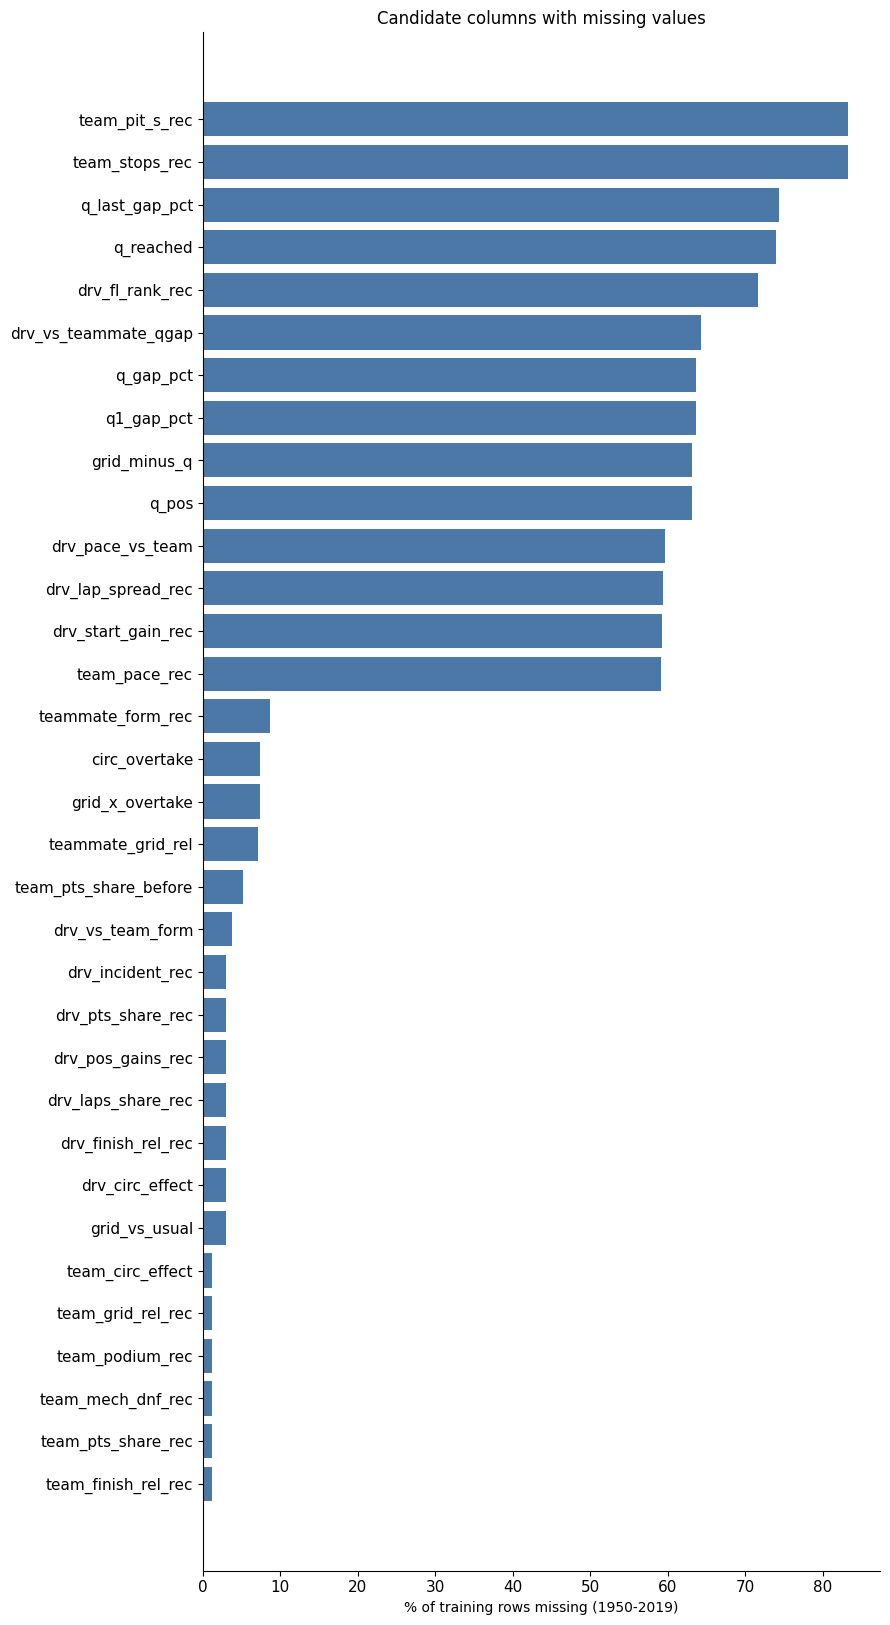

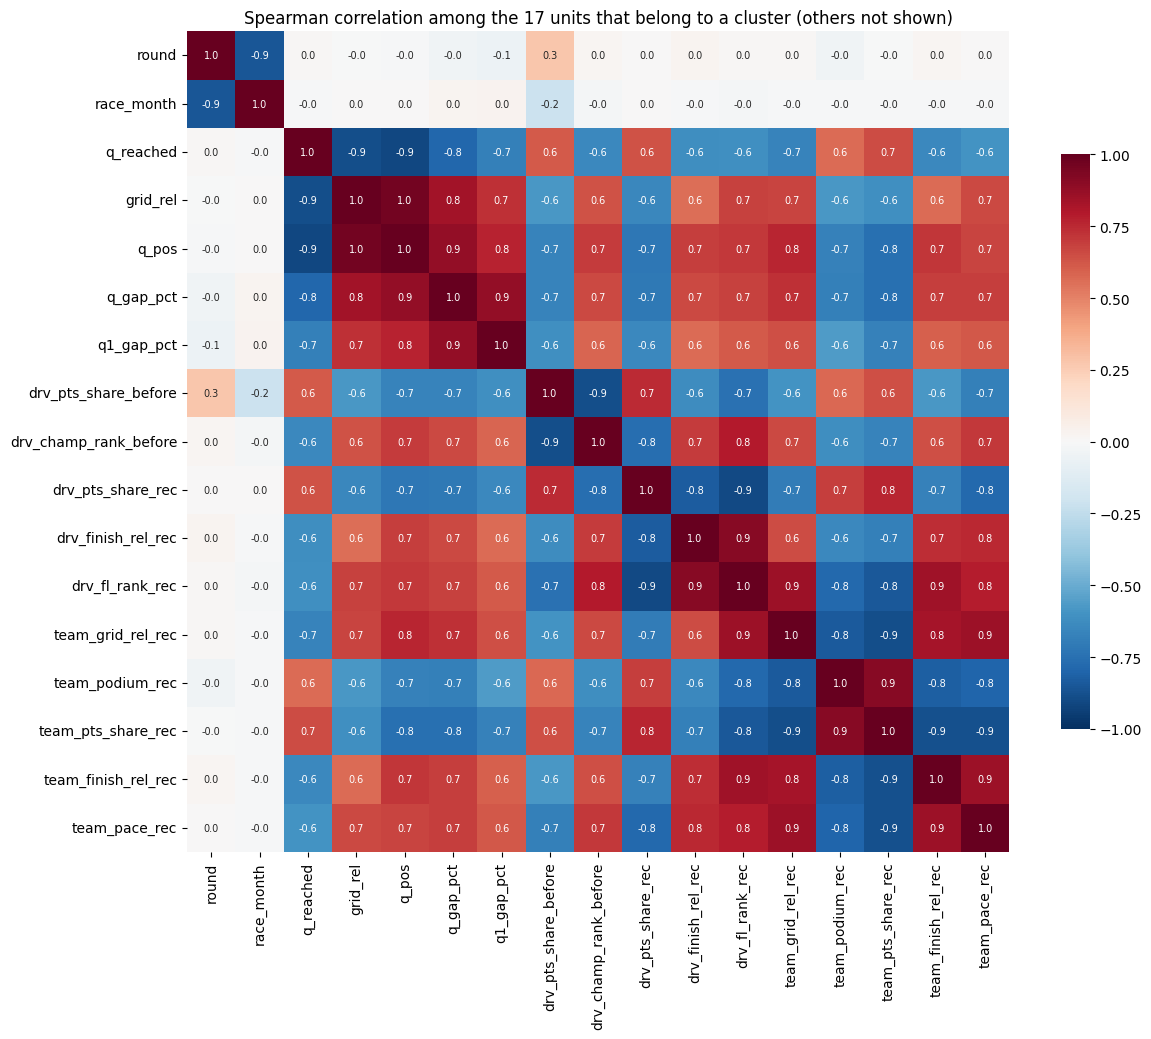

clusters with two or more units (|rho| >= 0.8 on average): 6


,units,size
cluster,,
4,"round, race_month",2
15,"grid_rel, q_pos, q_reached",3
16,"q_gap_pct, q1_gap_pct",2
17,"drv_pts_share_before, drv_champ_rank_before",2
19,"drv_finish_rel_rec, drv_pts_share_rec, drv_fl_rank_rec",3
20,"team_finish_rel_rec, team_podium_rec, team_pts_share_rec, team_grid_rel_rec, team_pace_rec",5


In [35]:
from scipy.cluster import hierarchy
from scipy.spatial.distance import squareform

TRAIN = full[full["year"].between(TRAIN_START, 2019)]
miss_share = pd.Series({c: TRAIN[c].isna().mean() for c in ALL_CAND_COLS}).sort_values(ascending=False)
print(f"columns with any missing value in {TRAIN_START}-2019:", int((miss_share > 0).sum()), "of", len(miss_share))
mm = miss_share[miss_share > 0].sort_values()
fig, ax = plt.subplots(figsize=(9, 0.45 * len(mm) + 1.5))
ax.barh(mm.index, mm.values * 100, color="#4C78A8"); ax.set_xlabel(f"% of training rows missing ({TRAIN_START}-2019)")
ax.set_title("Candidate columns with missing values"); ax.tick_params(labelsize=11)
plt.tight_layout(); plt.show()

PRIMARY = {u: cols[0] for u, cols in UNITS.items()}
P = TRAIN[[PRIMARY[u] for u in UNITS]].copy(); P.columns = list(UNITS)
rho_v = P.corr(method="spearman", min_periods=200).fillna(0.0).to_numpy().copy()
np.fill_diagonal(rho_v, 1.0)
rho = pd.DataFrame(rho_v, index=P.columns, columns=P.columns)
dist = 1 - rho.abs()
Z = hierarchy.linkage(squareform(dist.values, checks=False), method="average")
order = hierarchy.leaves_list(Z)
def clusters_at(cut):
    lab = hierarchy.fcluster(Z, t=cut, criterion="distance")
    return pd.Series(lab, index=rho.columns)
CL = clusters_at(0.2)
multi = CL.groupby(CL).filter(lambda s: len(s) > 1)
members_cl = [u for u in rho.columns[order] if u in multi.index]          # only units that sit in a cluster, in cluster order
n = len(members_cl)
fig, ax = plt.subplots(figsize=(0.55 * n + 3, 0.5 * n + 2))
sns.heatmap(rho.loc[members_cl, members_cl], cmap="RdBu_r", vmin=-1, vmax=1, annot=True, fmt=".1f", annot_kws={"size": 7}, ax=ax, cbar_kws={"shrink": 0.7})
ax.tick_params(labelsize=10); ax.set_title(f"Spearman correlation among the {n} units that belong to a cluster (others not shown)")
plt.tight_layout(); plt.show()
cluster_table = multi.rename("cluster").reset_index().rename(columns={"index": "unit"}).groupby("cluster")["unit"].apply(list)
print("clusters with two or more units (|rho| >= 0.8 on average):", len(cluster_table))
with pd.option_context("display.max_colwidth", None):
    display(cluster_table.to_frame("units").assign(size=lambda x: x["units"].map(len), units=lambda x: x["units"].map(", ".join)))

**Reading the figure.** 33 of the 52 candidate columns have gaps in 1950-2019. The large gaps are structural, because the source does not exist yet: pit stops (83 % of training rows, data from 2011), qualifying (63-74 %, from 1994), fastest-lap rank (72 %, from 2004) and race pace (about 59 %, lap times from 1996). The rest are small (1-9 %): first races, cars without a teammate, new circuits. The cluster table shows **6 groups of related units** (average |rho| of at least 0.8). Correlations use the rows where both columns exist, so for qualifying they describe 1994-2019.

### 9.8 How much does each candidate overlap with the grid slot itself?

**Question.** The grid slot is the baseline every candidate is added to, so it is not in the matrix above. Which candidates are near-copies of the grid slot, and does that mean they add nothing?

**What we do and why.** The Spearman correlation of the main column of every unit with `grid` on the training rows (1950-2019), and the share of starters whose grid slot differs from their qualifying position. A correlation only says that two columns order the rows in a similar way. It cannot say whether the part where they differ (for example a penalty that moves a fast car back) carries information about the podium. That is why section 10 does not drop a feature for being correlated with the grid: it measures what each feature adds **on top of** the grid slot, on seasons the model has not seen. The correlation tells us where to expect only small gains.

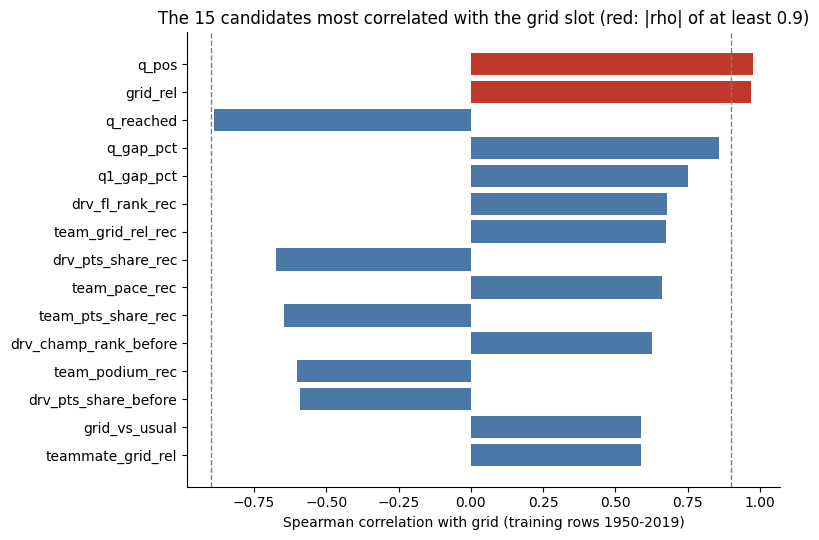

,rho with grid
grid_rel,0.970
q_pos,0.976
q_gap_pct,0.857
q_reached,-0.888
q_last_gap_pct,0.152
grid_minus_q,-0.022


share of training starters whose grid slot differs from their qualifying position: 0.224


In [36]:
rho_grid = pd.Series({u: spearmanr(TRAIN[PRIMARY[u]], TRAIN["grid"], nan_policy="omit")[0] for u in UNITS}).dropna()
top = rho_grid.reindex(rho_grid.abs().sort_values(ascending=False).index).head(15)[::-1]
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(top.index, top.values, color=["#C0392B" if abs(v) >= 0.9 else "#4C78A8" for v in top.values])
for v in (-0.9, 0.9):
    ax.axvline(v, color="grey", ls="--", lw=1)
ax.set_xlabel(f"Spearman correlation with grid (training rows {TRAIN_START}-2019)")
ax.set_title("The 15 candidates most correlated with the grid slot (red: |rho| of at least 0.9)")
plt.tight_layout(); plt.show()
display(rho_grid[["grid_rel", "q_pos", "q_gap_pct", "q_reached", "q_last_gap_pct", "grid_minus_q"]].round(3).to_frame("rho with grid"))
both = TRAIN.dropna(subset=["q_pos"])
print("share of training starters whose grid slot differs from their qualifying position:", round(float((both["grid"] != both["q_pos"]).mean()), 3))


**Reading the result.** Two candidates are near-copies of the grid slot (red in the figure): `q_pos` (0.98), because the qualifying order is the starting order for most drivers, and `grid_rel` (0.97, the slot divided by the field size). The other qualifying columns overlap less: `q_reached` -0.89, `q_gap_pct` 0.86, and `q_last_gap_pct` (0.15) and `grid_minus_q` (-0.02) almost not at all. Even the near-copy differs where it matters: **22.4 % of training starters with a qualifying position start from a different slot** (penalties, pit-lane starts). Section 10 therefore tests what each candidate adds **on top of** the grid instead of dropping it for its correlation.

## 10. Feature selection

Every feature is judged by the yardstick of 9.3: **does it help predict podiums in seasons the model has not seen?** A feature is kept if **either** lens (logistic regression or boosted trees) finds a real gain: a feature only trees can use still helps the tree and neural models, and one only the linear model can use still helps the logistic baseline.

**The order of this section.**
* **10.1** every candidate alone: definition, source, both lenses, interpretation, decision.
* **10.2** the 48 candidates grouped into 16 concepts (each concept is one idea about what decides a podium); each concept is tested as a whole.
* **10.3** inside the kept concepts: failed members get a second chance in their group, and near-copies are removed.
* **10.4** the table of all features with their decisions (the final list), and what the strongest ones look like.
* **10.5** the start of the training window, checked with the final list.
* **10.6** two earlier attempts at choosing features (Trial A with the p-value, Trial B one feature at a time), kept as evidence and why each was replaced.

### 10.1 Every candidate alone against the grid baseline

**Question.** Does each candidate add predictive value beyond the starting slot, on seasons the model has not seen?

**What we do and why.** For each of the 48 units we compare the baseline (the grid slot and its flags) with "baseline + this unit" in both lenses, and add the classical test (the likelihood-ratio p-value) as evidence. Pit-stop features exist only from 2011, so they are judged in their own window (2011-2019, two folds) against the same baseline in that window. Below the table, each feature gets its own block; the figure after the blocks summarises them.

In [37]:
import os
os.makedirs("selection_outputs", exist_ok=True)
rows = []
for unit, cols in UNITS.items():
    if unit in LATE_UNITS:
        r = evaluate(full, BASE, BASE + cols, window=(2011, 2019), folds=FOLDS_LATE)
    else:
        r = evaluate(full, BASE, BASE + cols)
    k1, k2 = lens_keep(r)
    rows.append({"unit": unit, "group": GROUP[unit], "window": "2011-19" if unit in LATE_UNITS else f"{TRAIN_START}-19", "test_races": r["test_races"],
                 "p_value": r["p"], "effect_per_sd": r.get("coef_per_sd", np.nan), "effect_lo": r.get("ci_lo", np.nan), "effect_hi": r.get("ci_hi", np.nan),
                 "lr_gain": r["lr_gain"], "lr_lo": r["lr_lo"], "lr_hi": r["lr_hi"], "gbm_gain": r["gbm_gain"], "gbm_lo": r["gbm_lo"], "gbm_hi": r["gbm_hi"],
                 "lens1_keeps": k1, "lens2_keeps": k2, "keep_step1": k1 or k2})
step1 = pd.DataFrame(rows).set_index("unit")
step1.to_csv("selection_outputs/step1_alone_vs_grid.csv")
show = step1[["group", "window", "p_value", "effect_per_sd", "lr_gain", "lr_lo", "gbm_gain", "gbm_lo", "lens1_keeps", "lens2_keeps", "keep_step1"]].sort_values("lr_gain", ascending=False)
display(show.round(4))
print("units kept by lens 1:", int(step1["lens1_keeps"].sum()), "| by lens 2:", int(step1["lens2_keeps"].sum()),
      "| by either:", int(step1["keep_step1"].sum()), "| by both:", int((step1["lens1_keeps"] & step1["lens2_keeps"]).sum()), "| by neither:", int((~step1["keep_step1"]).sum()))

,group,window,p_value,effect_per_sd,lr_gain,lr_lo,gbm_gain,gbm_lo,lens1_keeps,lens2_keeps,keep_step1
unit,,,,,,,,,,,
team_pts_share_rec,form,1950-19,0.0000,0.6145,0.0236,0.0186,0.0196,0.0147,True,True,True
drv_pts_share_rec,form,1950-19,0.0000,0.5546,0.0230,0.0175,0.0196,0.0144,True,True,True
drv_fl_rank_rec,form,1950-19,0.0000,-1.0955,0.0223,0.0182,0.0182,0.0125,True,True,True
team_finish_rel_rec,form,1950-19,0.0000,-0.6569,0.0211,0.0172,0.0177,0.0128,True,True,True
team_podium_rec,form,1950-19,0.0000,0.5423,0.0207,0.0154,0.0195,0.0141,True,True,True
drv_finish_rel_rec,form,1950-19,0.0000,-0.5977,0.0198,0.0155,0.0185,0.0131,True,True,True
team_pace_rec,race pace,1950-19,0.0000,-1.1886,0.0182,0.0144,0.0141,0.0092,True,True,True
team_grid_rel_rec,qualifying form,1950-19,0.0000,-0.6736,0.0165,0.0131,0.0152,0.0108,True,True,True
drv_pts_share_before,standings,1950-19,0.0000,0.4219,0.0152,0.0114,0.0172,0.0123,True,True,True


units kept by lens 1: 24 | by lens 2: 18 | by either: 24 | by both: 18 | by neither: 24


**Reading the result (Step 1).** Of 48 units, **24 are kept by either lens**: 24 by the logistic regression, 18 by the trees (all 18 also kept by the logistic regression), 24 by neither.
* **Strongest:** the form and car-strength units, about +0.020 to +0.024 log-loss each in the logistic lens (`team_pts_share_rec` +0.0236, `drv_pts_share_rec` +0.0230, `drv_fl_rank_rec` +0.0223, `team_finish_rel_rec` +0.0211, `team_podium_rec` +0.0207, `drv_finish_rel_rec` +0.0198), then race pace (`team_pace_rec` +0.0182), qualifying form and the standings units (+0.014 to +0.017).
* **Qualifying:** `q_last_gap_pct` (+0.0087 logistic, +0.0032 trees), `q_gap_pct` (+0.0081, +0.0056) and `q_pos` (+0.0073, +0.0023) pass in both lenses; `q1_gap_pct` (+0.0021) passes in the logistic lens only. `grid_minus_q` (+0.0019, range from -0.0008) and `q_reached` (-0.0001) add nothing reliable beyond the baseline.
* **Kept by the logistic lens only, by small margins:** `drv_laps_share_rec`, `drv_prior_starts`, `q1_gap_pct`, `drv_incident_rec`, `drv_start_gain_rec` and `drv_vs_teammate_qgap` (gains +0.0008 to +0.0026).
* **Nothing:** the circuit units, `is_home`, `team_is_home`, `round`, `race_month`, `era`, `field`, `grid_rel`, `drv_vs_team_form`, `drv_pos_gains_rec`, `drv_pace_vs_team`, `drv_lap_spread_rec` and `team_mech_dnf_rec`. `era`, now tested over 70 seasons, adds nothing on top of the baseline. **Worse than nothing** on later seasons: `age` (trees -0.0112) and `team_age` (trees -0.0053). The pit-stop units, judged in 2011-2019, fail clearly (`team_stops_rec` trees -0.0250).

In [38]:
from IPython.display import Markdown
CONCEPTS = {
 "Grid": ["grid_rel", "field"],
 "Qualifying": ["q_pos", "q_gap_pct", "q_reached", "grid_minus_q", "q1_gap_pct", "q_last_gap_pct"],
 "Qualifying form": ["team_grid_rel_rec", "grid_vs_usual"],
 "Driver form": ["drv_finish_rel_rec", "drv_pts_share_rec", "drv_laps_share_rec", "drv_fl_rank_rec", "drv_pos_gains_rec"],
 "Team form": ["team_finish_rel_rec", "team_podium_rec", "team_pts_share_rec"],
 "Driver versus team": ["drv_vs_team_form"],
 "Teammate": ["teammate_grid_rel", "drv_vs_teammate_qgap", "teammate_form_rec"],
 "Standings": ["drv_pts_share_before", "team_pts_share_before", "drv_champ_rank_before", "drv_wins_before"],
 "Reliability": ["team_mech_dnf_rec", "drv_incident_rec"],
 "Race pace": ["team_pace_rec", "drv_pace_vs_team", "drv_start_gain_rec", "drv_lap_spread_rec"],
 "Pit stops": ["team_pit_s_rec", "team_stops_rec"],
 "Circuit history": ["drv_circ_effect", "circ_overtake", "team_circ_effect"],
 "Circuit description": ["circ_lat", "circ_lng", "circ_alt"],
 "Driver profile": ["age", "drv_prior_starts"],
 "Home": ["is_home", "team_is_home"],
 "Calendar and era": ["round", "race_month", "era", "team_age"],
}
flat = [u for us in CONCEPTS.values() for u in us]
assert sorted(flat) == sorted(UNITS) and len(flat) == len(set(flat)), "every candidate must belong to exactly one concept"
CONCEPT_OF = {u: c for c, us in CONCEPTS.items() for u in us}
REGISTRY["concept"] = REGISTRY["unit"].map(CONCEPT_OF)
REG = REGISTRY.set_index("unit")
def verdict(g, lo, hi):
    if lo > 0 and g >= MIN_GAIN: return f"**real gain** ({g:+.4f}, 95% range {lo:+.4f} to {hi:+.4f})"
    if lo > 0: return f"range above 0 but the gain ({g:+.4f}) is below the minimum {MIN_GAIN}: too small to matter"
    if hi < 0: return f"**hurts** ({g:+.4f}, range {lo:+.4f} to {hi:+.4f})"
    return f"no reliable gain ({g:+.4f}, range {lo:+.4f} to {hi:+.4f} includes 0)"
blocks = []
for c, us in CONCEPTS.items():
    blocks.append(f"#### {c}")
    for u in us:
        s1, r = step1.loc[u], REG.loc[u]
        p = s1["p_value"]
        ptxt = "not available" if pd.isna(p) else (("below 0.0001" if p < 0.0001 else f"{p:.4f}") + (": unlikely to be chance" if p < 0.05 else ": could be chance"))
        l1, l2 = bool(s1["lens1_keeps"]), bool(s1["lens2_keeps"])
        if l1 and l2: reading = "Helps in both lenses: it carries signal a straight line can use, and trees confirm it."
        elif l1: reading = "Helps only as a straight-line effect; the trees find no gain on top of the baseline."
        elif l2: reading = "Helps only when the model may use thresholds or curves; the linear lens finds no usable gain."
        elif (not pd.isna(p)) and p < 0.05: reading = "Looks significant on the training data (p below 0.05) but does not improve predictions on later seasons in either lens: it fits the past, not the future."
        else: reading = "No reliable gain in either lens beyond the baseline."
        dec = "INCLUDE (alone)" if (l1 or l2) else "EXCLUDE (alone; re-checked inside its group in 10.3)"
        win = f" Tested only in 2011-2019, because it exists from {int(r['available_from'])}." if u in LATE_UNITS else ""
        blocks.append(f"""**`{u}`**
- *Definition:* {r['definition']}. *Source:* {r['source']}. *Why it might help:* {r['why_it_may_help']} *Valid before the race:* {r['valid_before_race']}{win}
- *Linear lens (vs the baseline):* {verdict(s1['lr_gain'], s1['lr_lo'], s1['lr_hi'])}
- *Tree lens (vs the baseline):* {verdict(s1['gbm_gain'], s1['gbm_lo'], s1['gbm_hi'])}
- *Likelihood-ratio p-value (evidence only):* {ptxt}
- *Interpretation:* {reading}
- *Decision:* **{dec}**
""")
display(Markdown("\n\n".join(blocks)))

#### Grid

**`grid_rel`**
- *Definition:* grid slot / number of cars that started. *Source:* results. *Why it might help:* The same slot means more in a small field (podium rate is about 3 / field size; section 6.4). *Valid before the race:* The grid is fixed before the start.
- *Linear lens (vs the baseline):* range above 0 but the gain (+0.0002) is below the minimum 0.0005: too small to matter
- *Tree lens (vs the baseline):* no reliable gain (+0.0001, range -0.0010 to +0.0010 includes 0)
- *Likelihood-ratio p-value (evidence only):* 0.5927: could be chance
- *Interpretation:* No reliable gain in either lens beyond the baseline.
- *Decision:* **EXCLUDE (alone; re-checked inside its group in 10.3)**


**`field`**
- *Definition:* number of cars that started. *Source:* results. *Why it might help:* A bigger field dilutes the chance of any one car finishing in the top 3. *Valid before the race:* The number of starters is known at the grid.
- *Linear lens (vs the baseline):* no reliable gain (+0.0000, range -0.0000 to +0.0000 includes 0)
- *Tree lens (vs the baseline):* no reliable gain (-0.0004, range -0.0010 to +0.0004 includes 0)
- *Likelihood-ratio p-value (evidence only):* 0.7816: could be chance
- *Interpretation:* No reliable gain in either lens beyond the baseline.
- *Decision:* **EXCLUDE (alone; re-checked inside its group in 10.3)**


#### Qualifying

**`q_pos`**
- *Definition:* position in qualifying. *Source:* qualifying. *Why it might help:* Qualifying order is the cleanest read of pure pace, before penalties. *Valid before the race:* Qualifying ends before the race.
- *Linear lens (vs the baseline):* **real gain** (+0.0073, 95% range +0.0052 to +0.0092)
- *Tree lens (vs the baseline):* **real gain** (+0.0023, 95% range +0.0005 to +0.0050)
- *Likelihood-ratio p-value (evidence only):* below 0.0001: unlikely to be chance
- *Interpretation:* Helps in both lenses: it carries signal a straight line can use, and trees confirm it.
- *Decision:* **INCLUDE (alone)**


**`q_gap_pct`**
- *Definition:* best qualifying time as % slower than pole. *Source:* qualifying. *Why it might help:* The size of the deficit to pole, comparable across tracks, says more than the rank. *Valid before the race:* Qualifying ends before the race.
- *Linear lens (vs the baseline):* **real gain** (+0.0081, 95% range +0.0059 to +0.0100)
- *Tree lens (vs the baseline):* **real gain** (+0.0056, 95% range +0.0026 to +0.0084)
- *Likelihood-ratio p-value (evidence only):* below 0.0001: unlikely to be chance
- *Interpretation:* Helps in both lenses: it carries signal a straight line can use, and trees confirm it.
- *Decision:* **INCLUDE (alone)**


**`q_reached`**
- *Definition:* last part of qualifying reached (1, 2 or 3); missing in single-session races (7.3). *Source:* qualifying. *Why it might help:* Reaching Q3 means a top-10 car. *Valid before the race:* Qualifying ends before the race.
- *Linear lens (vs the baseline):* no reliable gain (-0.0001, range -0.0002 to +0.0000 includes 0)
- *Tree lens (vs the baseline):* no reliable gain (+0.0004, range -0.0006 to +0.0013 includes 0)
- *Likelihood-ratio p-value (evidence only):* below 0.0001: unlikely to be chance
- *Interpretation:* Looks significant on the training data (p below 0.05) but does not improve predictions on later seasons in either lens: it fits the past, not the future.
- *Decision:* **EXCLUDE (alone; re-checked inside its group in 10.3)**


**`grid_minus_q`**
- *Definition:* grid slot minus qualifying position. *Source:* qualifying, results. *Why it might help:* Penalties and pit-lane starts: a car that qualified well but starts lower. *Valid before the race:* Both numbers are known at the grid.
- *Linear lens (vs the baseline):* no reliable gain (+0.0019, range -0.0008 to +0.0057 includes 0)
- *Tree lens (vs the baseline):* no reliable gain (+0.0007, range -0.0011 to +0.0029 includes 0)
- *Likelihood-ratio p-value (evidence only):* below 0.0001: unlikely to be chance
- *Interpretation:* Looks significant on the training data (p below 0.05) but does not improve predictions on later seasons in either lens: it fits the past, not the future.
- *Decision:* **EXCLUDE (alone; re-checked inside its group in 10.3)**


**`q1_gap_pct`**
- *Definition:* Q1 time as % slower than the fastest Q1 time. *Source:* qualifying. *Why it might help:* The one measure available in every qualifying format since 1996. *Valid before the race:* Qualifying ends before the race.
- *Linear lens (vs the baseline):* **real gain** (+0.0021, 95% range +0.0011 to +0.0029)
- *Tree lens (vs the baseline):* no reliable gain (+0.0016, range -0.0016 to +0.0050 includes 0)
- *Likelihood-ratio p-value (evidence only):* 0.2076: could be chance
- *Interpretation:* Helps only as a straight-line effect; the trees find no gain on top of the baseline.
- *Decision:* **INCLUDE (alone)**


**`q_last_gap_pct`**
- *Definition:* gap to the fastest time of the last qualifying part the driver took part in; missing in single-session races (7.3). *Source:* qualifying. *Why it might help:* Compares a driver with those he actually competed against in his last session. *Valid before the race:* Qualifying ends before the race.
- *Linear lens (vs the baseline):* **real gain** (+0.0087, 95% range +0.0047 to +0.0121)
- *Tree lens (vs the baseline):* **real gain** (+0.0032, 95% range +0.0006 to +0.0063)
- *Likelihood-ratio p-value (evidence only):* below 0.0001: unlikely to be chance
- *Interpretation:* Helps in both lenses: it carries signal a straight line can use, and trees confirm it.
- *Decision:* **INCLUDE (alone)**


#### Qualifying form

**`team_grid_rel_rec`**
- *Definition:* team's average relative grid slot, last W races. *Source:* results (earlier races). *Why it might help:* Where a team usually starts shows its qualifying pace. *Valid before the race:* Uses only earlier races.
- *Linear lens (vs the baseline):* **real gain** (+0.0165, 95% range +0.0131 to +0.0200)
- *Tree lens (vs the baseline):* **real gain** (+0.0152, 95% range +0.0108 to +0.0201)
- *Likelihood-ratio p-value (evidence only):* below 0.0001: unlikely to be chance
- *Interpretation:* Helps in both lenses: it carries signal a straight line can use, and trees confirm it.
- *Decision:* **INCLUDE (alone)**


**`grid_vs_usual`**
- *Definition:* today's relative grid slot minus the driver's average over his last W races. *Source:* results (earlier races). *Why it might help:* A slot far below his usual signals a penalty or a bad lap. *Valid before the race:* Today's grid is known; the average uses earlier races.
- *Linear lens (vs the baseline):* **real gain** (+0.0140, 95% range +0.0106 to +0.0175)
- *Tree lens (vs the baseline):* **real gain** (+0.0136, 95% range +0.0097 to +0.0177)
- *Likelihood-ratio p-value (evidence only):* below 0.0001: unlikely to be chance
- *Interpretation:* Helps in both lenses: it carries signal a straight line can use, and trees confirm it.
- *Decision:* **INCLUDE (alone)**


#### Driver form

**`drv_finish_rel_rec`**
- *Definition:* driver's average finishing place / field size, last W races. *Source:* results (earlier races). *Why it might help:* Recent results reflect the driver and car together. *Valid before the race:* Uses only earlier races.
- *Linear lens (vs the baseline):* **real gain** (+0.0198, 95% range +0.0155 to +0.0243)
- *Tree lens (vs the baseline):* **real gain** (+0.0185, 95% range +0.0131 to +0.0242)
- *Likelihood-ratio p-value (evidence only):* below 0.0001: unlikely to be chance
- *Interpretation:* Helps in both lenses: it carries signal a straight line can use, and trees confirm it.
- *Decision:* **INCLUDE (alone)**


**`drv_pts_share_rec`**
- *Definition:* driver's points as a share of the winner's points, last W races. *Source:* results (earlier races). *Why it might help:* Points reward finishing high regardless of era; the share removes scoring-system changes. *Valid before the race:* Uses only earlier races.
- *Linear lens (vs the baseline):* **real gain** (+0.0230, 95% range +0.0175 to +0.0283)
- *Tree lens (vs the baseline):* **real gain** (+0.0196, 95% range +0.0144 to +0.0255)
- *Likelihood-ratio p-value (evidence only):* below 0.0001: unlikely to be chance
- *Interpretation:* Helps in both lenses: it carries signal a straight line can use, and trees confirm it.
- *Decision:* **INCLUDE (alone)**


**`drv_laps_share_rec`**
- *Definition:* laps completed / winner's laps, last W races. *Source:* results (earlier races). *Why it might help:* Separates a driver who is slow from one who keeps retiring. *Valid before the race:* Uses only earlier races.
- *Linear lens (vs the baseline):* **real gain** (+0.0026, 95% range +0.0011 to +0.0040)
- *Tree lens (vs the baseline):* no reliable gain (+0.0014, range -0.0013 to +0.0042 includes 0)
- *Likelihood-ratio p-value (evidence only):* below 0.0001: unlikely to be chance
- *Interpretation:* Helps only as a straight-line effect; the trees find no gain on top of the baseline.
- *Decision:* **INCLUDE (alone)**


**`drv_fl_rank_rec`**
- *Definition:* rank of the driver's fastest race lap among the field, last W races. *Source:* results (earlier races). *Why it might help:* A fast lap shows speed even in a race with a poor result. *Valid before the race:* Uses only earlier races (fastest-lap data starts in 2004).
- *Linear lens (vs the baseline):* **real gain** (+0.0223, 95% range +0.0182 to +0.0260)
- *Tree lens (vs the baseline):* **real gain** (+0.0182, 95% range +0.0125 to +0.0241)
- *Likelihood-ratio p-value (evidence only):* below 0.0001: unlikely to be chance
- *Interpretation:* Helps in both lenses: it carries signal a straight line can use, and trees confirm it.
- *Decision:* **INCLUDE (alone)**


**`drv_pos_gains_rec`**
- *Definition:* places gained from grid to finish / field size, last W races. *Source:* results (earlier races). *Why it might help:* Drivers who usually move forward in the race may convert a slot better. *Valid before the race:* Uses only earlier races.
- *Linear lens (vs the baseline):* **hurts** (-0.0008, range -0.0011 to -0.0003)
- *Tree lens (vs the baseline):* **hurts** (-0.0013, range -0.0026 to -0.0002)
- *Likelihood-ratio p-value (evidence only):* 0.0079: unlikely to be chance
- *Interpretation:* Looks significant on the training data (p below 0.05) but does not improve predictions on later seasons in either lens: it fits the past, not the future.
- *Decision:* **EXCLUDE (alone; re-checked inside its group in 10.3)**


#### Team form

**`team_finish_rel_rec`**
- *Definition:* team's average finishing place / field size, last W races. *Source:* results (earlier races). *Why it might help:* A team finishing near the front recently has a fast car; the car is the main driver of podiums. *Valid before the race:* Uses only races before this one (shifted, leak-tested).
- *Linear lens (vs the baseline):* **real gain** (+0.0211, 95% range +0.0172 to +0.0252)
- *Tree lens (vs the baseline):* **real gain** (+0.0177, 95% range +0.0128 to +0.0224)
- *Likelihood-ratio p-value (evidence only):* below 0.0001: unlikely to be chance
- *Interpretation:* Helps in both lenses: it carries signal a straight line can use, and trees confirm it.
- *Decision:* **INCLUDE (alone)**


**`team_podium_rec`**
- *Definition:* share of the team's cars on the podium, last W races. *Source:* results (earlier races). *Why it might help:* Direct measure of how often this car wins podiums. *Valid before the race:* Uses only earlier races.
- *Linear lens (vs the baseline):* **real gain** (+0.0207, 95% range +0.0154 to +0.0255)
- *Tree lens (vs the baseline):* **real gain** (+0.0195, 95% range +0.0141 to +0.0251)
- *Likelihood-ratio p-value (evidence only):* below 0.0001: unlikely to be chance
- *Interpretation:* Helps in both lenses: it carries signal a straight line can use, and trees confirm it.
- *Decision:* **INCLUDE (alone)**


**`team_pts_share_rec`**
- *Definition:* team's cars' points as a share of the winner's points, last W races. *Source:* results (earlier races). *Why it might help:* A smoother read of car strength than finishing place. *Valid before the race:* Uses only earlier races.
- *Linear lens (vs the baseline):* **real gain** (+0.0236, 95% range +0.0186 to +0.0287)
- *Tree lens (vs the baseline):* **real gain** (+0.0196, 95% range +0.0147 to +0.0246)
- *Likelihood-ratio p-value (evidence only):* below 0.0001: unlikely to be chance
- *Interpretation:* Helps in both lenses: it carries signal a straight line can use, and trees confirm it.
- *Decision:* **INCLUDE (alone)**


#### Driver versus team

**`drv_vs_team_form`**
- *Definition:* driver's form minus his team's form. *Source:* results (earlier races). *Why it might help:* Isolates what the driver adds beyond his car. *Valid before the race:* Uses only earlier races.
- *Linear lens (vs the baseline):* no reliable gain (+0.0000, range -0.0002 to +0.0002 includes 0)
- *Tree lens (vs the baseline):* no reliable gain (-0.0010, range -0.0021 to +0.0003 includes 0)
- *Likelihood-ratio p-value (evidence only):* 0.6741: could be chance
- *Interpretation:* No reliable gain in either lens beyond the baseline.
- *Decision:* **EXCLUDE (alone; re-checked inside its group in 10.3)**


#### Teammate

**`teammate_grid_rel`**
- *Definition:* teammate's grid slot / field size, this weekend. *Source:* results (this weekend's grid). *Why it might help:* The teammate's slot is a second reading of how fast the car is this weekend. *Valid before the race:* The grid is fixed before the start.
- *Linear lens (vs the baseline):* **real gain** (+0.0059, 95% range +0.0042 to +0.0078)
- *Tree lens (vs the baseline):* **real gain** (+0.0079, 95% range +0.0043 to +0.0119)
- *Likelihood-ratio p-value (evidence only):* below 0.0001: unlikely to be chance
- *Interpretation:* Helps in both lenses: it carries signal a straight line can use, and trees confirm it.
- *Decision:* **INCLUDE (alone)**


**`drv_vs_teammate_qgap`**
- *Definition:* driver's qualifying gap to pole minus his teammate's. *Source:* qualifying. *Why it might help:* Same car, so the difference is the driver. *Valid before the race:* Qualifying ends before the race.
- *Linear lens (vs the baseline):* **real gain** (+0.0008, 95% range +0.0003 to +0.0013)
- *Tree lens (vs the baseline):* no reliable gain (+0.0008, range -0.0012 to +0.0028 includes 0)
- *Likelihood-ratio p-value (evidence only):* 0.0001: unlikely to be chance
- *Interpretation:* Helps only as a straight-line effect; the trees find no gain on top of the baseline.
- *Decision:* **INCLUDE (alone)**


**`teammate_form_rec`**
- *Definition:* teammate's finishing form, last W races. *Source:* results (earlier races). *Why it might help:* A second reading of the car from earlier races. *Valid before the race:* Uses only earlier races.
- *Linear lens (vs the baseline):* **real gain** (+0.0107, 95% range +0.0078 to +0.0139)
- *Tree lens (vs the baseline):* **real gain** (+0.0080, 95% range +0.0044 to +0.0124)
- *Likelihood-ratio p-value (evidence only):* below 0.0001: unlikely to be chance
- *Interpretation:* Helps in both lenses: it carries signal a straight line can use, and trees confirm it.
- *Decision:* **INCLUDE (alone)**


#### Standings

**`drv_pts_share_before`**
- *Definition:* driver's championship points before the race / the leader's points. *Source:* driver_standings. *Why it might help:* A driver already high in the championship is probably fast. *Valid before the race:* Standings after the PREVIOUS round of the same season.
- *Linear lens (vs the baseline):* **real gain** (+0.0152, 95% range +0.0114 to +0.0189)
- *Tree lens (vs the baseline):* **real gain** (+0.0172, 95% range +0.0123 to +0.0225)
- *Likelihood-ratio p-value (evidence only):* below 0.0001: unlikely to be chance
- *Interpretation:* Helps in both lenses: it carries signal a straight line can use, and trees confirm it.
- *Decision:* **INCLUDE (alone)**


**`team_pts_share_before`**
- *Definition:* team's championship points before the race / the leader's points. *Source:* constructor_standings. *Why it might help:* Same idea for the car. *Valid before the race:* Standings after the previous round.
- *Linear lens (vs the baseline):* **real gain** (+0.0150, 95% range +0.0114 to +0.0186)
- *Tree lens (vs the baseline):* **real gain** (+0.0161, 95% range +0.0116 to +0.0208)
- *Likelihood-ratio p-value (evidence only):* below 0.0001: unlikely to be chance
- *Interpretation:* Helps in both lenses: it carries signal a straight line can use, and trees confirm it.
- *Decision:* **INCLUDE (alone)**


**`drv_champ_rank_before`**
- *Definition:* driver's championship rank among this race's starters (0 to 1). *Source:* driver_standings. *Why it might help:* Rank, unlike the points share, is not distorted by one runaway leader. *Valid before the race:* Standings after the previous round.
- *Linear lens (vs the baseline):* **real gain** (+0.0141, 95% range +0.0105 to +0.0175)
- *Tree lens (vs the baseline):* **real gain** (+0.0157, 95% range +0.0100 to +0.0214)
- *Likelihood-ratio p-value (evidence only):* below 0.0001: unlikely to be chance
- *Interpretation:* Helps in both lenses: it carries signal a straight line can use, and trees confirm it.
- *Decision:* **INCLUDE (alone)**


**`drv_wins_before`**
- *Definition:* wins so far this season. *Source:* driver_standings. *Why it might help:* Winners this season are the top performers. *Valid before the race:* Standings after the previous round.
- *Linear lens (vs the baseline):* **real gain** (+0.0107, 95% range +0.0068 to +0.0145)
- *Tree lens (vs the baseline):* **real gain** (+0.0116, 95% range +0.0066 to +0.0173)
- *Likelihood-ratio p-value (evidence only):* below 0.0001: unlikely to be chance
- *Interpretation:* Helps in both lenses: it carries signal a straight line can use, and trees confirm it.
- *Decision:* **INCLUDE (alone)**


#### Reliability

**`team_mech_dnf_rec`**
- *Definition:* share of the team's cars retiring with a mechanical failure, recent races (W, at least 10). *Source:* results + status (earlier races). *Why it might help:* An unreliable car cannot hold a podium place. *Valid before the race:* Uses only earlier races.
- *Linear lens (vs the baseline):* no reliable gain (+0.0011, range -0.0000 to +0.0022 includes 0)
- *Tree lens (vs the baseline):* no reliable gain (+0.0001, range -0.0014 to +0.0015 includes 0)
- *Likelihood-ratio p-value (evidence only):* below 0.0001: unlikely to be chance
- *Interpretation:* Looks significant on the training data (p below 0.05) but does not improve predictions on later seasons in either lens: it fits the past, not the future.
- *Decision:* **EXCLUDE (alone; re-checked inside its group in 10.3)**


**`drv_incident_rec`**
- *Definition:* share of races the driver retired in a collision or accident, recent races (W, at least 10). *Source:* results + status (earlier races). *Why it might help:* Accident-prone drivers lose podiums. *Valid before the race:* Uses only earlier races.
- *Linear lens (vs the baseline):* **real gain** (+0.0018, 95% range +0.0010 to +0.0026)
- *Tree lens (vs the baseline):* no reliable gain (-0.0005, range -0.0017 to +0.0006 includes 0)
- *Likelihood-ratio p-value (evidence only):* below 0.0001: unlikely to be chance
- *Interpretation:* Helps only as a straight-line effect; the trees find no gain on top of the baseline.
- *Decision:* **INCLUDE (alone)**


#### Race pace

**`team_pace_rec`**
- *Definition:* team's typical lap time as % slower than the fastest car, last W races. *Source:* lap_times (earlier races). *Why it might help:* Lap times are a cleaner pace measure than finishing place (no safety cars or strategy noise). *Valid before the race:* Uses only earlier races (lap times from 1996).
- *Linear lens (vs the baseline):* **real gain** (+0.0182, 95% range +0.0144 to +0.0219)
- *Tree lens (vs the baseline):* **real gain** (+0.0141, 95% range +0.0092 to +0.0201)
- *Likelihood-ratio p-value (evidence only):* below 0.0001: unlikely to be chance
- *Interpretation:* Helps in both lenses: it carries signal a straight line can use, and trees confirm it.
- *Decision:* **INCLUDE (alone)**


**`drv_pace_vs_team`**
- *Definition:* driver's recent pace minus his team's. *Source:* lap_times (earlier races). *Why it might help:* Driver's contribution to speed in the same car. *Valid before the race:* Uses only earlier races.
- *Linear lens (vs the baseline):* no reliable gain (-0.0000, range -0.0002 to +0.0002 includes 0)
- *Tree lens (vs the baseline):* no reliable gain (+0.0008, range -0.0010 to +0.0026 includes 0)
- *Likelihood-ratio p-value (evidence only):* 0.7246: could be chance
- *Interpretation:* No reliable gain in either lens beyond the baseline.
- *Decision:* **EXCLUDE (alone; re-checked inside its group in 10.3)**


**`drv_start_gain_rec`**
- *Definition:* places gained on lap 1, average of last W races. *Source:* lap_times + results (earlier races). *Why it might help:* Launch skill and early-race aggression. *Valid before the race:* Uses only earlier races.
- *Linear lens (vs the baseline):* **real gain** (+0.0014, 95% range +0.0009 to +0.0020)
- *Tree lens (vs the baseline):* no reliable gain (+0.0012, range -0.0005 to +0.0029 includes 0)
- *Likelihood-ratio p-value (evidence only):* 0.0049: unlikely to be chance
- *Interpretation:* Helps only as a straight-line effect; the trees find no gain on top of the baseline.
- *Decision:* **INCLUDE (alone)**


**`drv_lap_spread_rec`**
- *Definition:* spread of the driver's lap times (IQR / median), last W races. *Source:* lap_times (earlier races). *Why it might help:* Consistency may separate drivers of equal speed. *Valid before the race:* Uses only earlier races.
- *Linear lens (vs the baseline):* no reliable gain (+0.0002, range -0.0000 to +0.0005 includes 0)
- *Tree lens (vs the baseline):* no reliable gain (-0.0007, range -0.0017 to +0.0005 includes 0)
- *Likelihood-ratio p-value (evidence only):* 0.0660: could be chance
- *Interpretation:* No reliable gain in either lens beyond the baseline.
- *Decision:* **EXCLUDE (alone; re-checked inside its group in 10.3)**


#### Pit stops

**`team_pit_s_rec`**
- *Definition:* team's average pit-stop time, last W races. *Source:* pit_stops (earlier races). *Why it might help:* Quick pit crews lose less time. *Valid before the race:* Uses only earlier races (pit data from 2011). Tested only in 2011-2019, because it exists from 2012.
- *Linear lens (vs the baseline):* **hurts** (-0.0107, range -0.0139 to -0.0076)
- *Tree lens (vs the baseline):* **hurts** (-0.0198, range -0.0301 to -0.0102)
- *Likelihood-ratio p-value (evidence only):* 0.0031: unlikely to be chance
- *Interpretation:* Looks significant on the training data (p below 0.05) but does not improve predictions on later seasons in either lens: it fits the past, not the future.
- *Decision:* **EXCLUDE (alone; re-checked inside its group in 10.3)**


**`team_stops_rec`**
- *Definition:* team's average number of stops per car, last W races. *Source:* pit_stops (earlier races). *Why it might help:* Fewer stops can mean better tyre management. *Valid before the race:* Uses only earlier races (from 2011). Tested only in 2011-2019, because it exists from 2012.
- *Linear lens (vs the baseline):* **hurts** (-0.0003, range -0.0006 to -0.0000)
- *Tree lens (vs the baseline):* **hurts** (-0.0250, range -0.0329 to -0.0169)
- *Likelihood-ratio p-value (evidence only):* 0.9984: could be chance
- *Interpretation:* No reliable gain in either lens beyond the baseline.
- *Decision:* **EXCLUDE (alone; re-checked inside its group in 10.3)**


#### Circuit history

**`drv_circ_effect`**
- *Definition:* driver's podium rate at this circuit (shrunk toward his overall rate) minus his overall rate. *Source:* results (earlier races). *Why it might help:* Some drivers may excel at tracks they know. *Valid before the race:* Uses only earlier races.
- *Linear lens (vs the baseline):* no reliable gain (-0.0001, range -0.0001 to +0.0000 includes 0)
- *Tree lens (vs the baseline):* no reliable gain (+0.0024, range -0.0005 to +0.0052 includes 0)
- *Likelihood-ratio p-value (evidence only):* 0.8326: could be chance
- *Interpretation:* No reliable gain in either lens beyond the baseline.
- *Decision:* **EXCLUDE (alone; re-checked inside its group in 10.3)**


**`circ_overtake`**
- *Definition:* past correlation of grid and finish at this circuit, and its product with the grid slot. *Source:* results (earlier races). *Why it might help:* Where overtaking is hard the grid order survives. *Valid before the race:* Uses only earlier races at this circuit.
- *Linear lens (vs the baseline):* no reliable gain (+0.0002, range -0.0000 to +0.0004 includes 0)
- *Tree lens (vs the baseline):* **hurts** (-0.0016, range -0.0032 to -0.0003)
- *Likelihood-ratio p-value (evidence only):* below 0.0001: unlikely to be chance
- *Interpretation:* Looks significant on the training data (p below 0.05) but does not improve predictions on later seasons in either lens: it fits the past, not the future.
- *Decision:* **EXCLUDE (alone; re-checked inside its group in 10.3)**


**`team_circ_effect`**
- *Definition:* team's podium rate at this circuit minus its overall rate (shrunk). *Source:* results (earlier races). *Why it might help:* Some cars suit particular tracks. *Valid before the race:* Uses only earlier races.
- *Linear lens (vs the baseline):* no reliable gain (+0.0000, range -0.0004 to +0.0005 includes 0)
- *Tree lens (vs the baseline):* no reliable gain (+0.0017, range -0.0002 to +0.0039 includes 0)
- *Likelihood-ratio p-value (evidence only):* 0.1567: could be chance
- *Interpretation:* No reliable gain in either lens beyond the baseline.
- *Decision:* **EXCLUDE (alone; re-checked inside its group in 10.3)**


#### Circuit description

**`circ_lat`**
- *Definition:* circuit latitude. *Source:* circuits. *Why it might help:* Location proxies climate and track character. *Valid before the race:* Static.
- *Linear lens (vs the baseline):* range above 0 but the gain (+0.0000) is below the minimum 0.0005: too small to matter
- *Tree lens (vs the baseline):* no reliable gain (-0.0001, range -0.0008 to +0.0004 includes 0)
- *Likelihood-ratio p-value (evidence only):* 0.8131: could be chance
- *Interpretation:* No reliable gain in either lens beyond the baseline.
- *Decision:* **EXCLUDE (alone; re-checked inside its group in 10.3)**


**`circ_lng`**
- *Definition:* circuit longitude. *Source:* circuits. *Why it might help:* Same. *Valid before the race:* Static.
- *Linear lens (vs the baseline):* no reliable gain (-0.0000, range -0.0000 to +0.0000 includes 0)
- *Tree lens (vs the baseline):* **hurts** (-0.0009, range -0.0017 to -0.0002)
- *Likelihood-ratio p-value (evidence only):* 0.9508: could be chance
- *Interpretation:* No reliable gain in either lens beyond the baseline.
- *Decision:* **EXCLUDE (alone; re-checked inside its group in 10.3)**


**`circ_alt`**
- *Definition:* circuit altitude. *Source:* circuits. *Why it might help:* Thin air affects engines and downforce. *Valid before the race:* Static.
- *Linear lens (vs the baseline):* no reliable gain (-0.0000, range -0.0000 to +0.0000 includes 0)
- *Tree lens (vs the baseline):* **hurts** (-0.0014, range -0.0032 to -0.0001)
- *Likelihood-ratio p-value (evidence only):* 0.9473: could be chance
- *Interpretation:* No reliable gain in either lens beyond the baseline.
- *Decision:* **EXCLUDE (alone; re-checked inside its group in 10.3)**


#### Driver profile

**`age`**
- *Definition:* driver's age on race day and its square. *Source:* drivers, races. *Why it might help:* Career stage: very young and very old drivers podium less. *Valid before the race:* Birth date and race date are known.
- *Linear lens (vs the baseline):* no reliable gain (+0.0008, range -0.0000 to +0.0016 includes 0)
- *Tree lens (vs the baseline):* **hurts** (-0.0112, range -0.0174 to -0.0058)
- *Likelihood-ratio p-value (evidence only):* 0.0036: unlikely to be chance
- *Interpretation:* Looks significant on the training data (p below 0.05) but does not improve predictions on later seasons in either lens: it fits the past, not the future.
- *Decision:* **EXCLUDE (alone; re-checked inside its group in 10.3)**


**`drv_prior_starts`**
- *Definition:* number of the driver's earlier starts. *Source:* results (earlier races). *Why it might help:* Experience. *Valid before the race:* Counts earlier races only.
- *Linear lens (vs the baseline):* **real gain** (+0.0022, 95% range +0.0005 to +0.0038)
- *Tree lens (vs the baseline):* no reliable gain (+0.0021, range -0.0009 to +0.0049 includes 0)
- *Likelihood-ratio p-value (evidence only):* below 0.0001: unlikely to be chance
- *Interpretation:* Helps only as a straight-line effect; the trees find no gain on top of the baseline.
- *Decision:* **INCLUDE (alone)**


#### Home

**`is_home`**
- *Definition:* 1 if the race is in the driver's home country. *Source:* drivers, circuits. *Why it might help:* Home crowd and familiarity. *Valid before the race:* Nationality and circuit are known.
- *Linear lens (vs the baseline):* no reliable gain (+0.0000, range -0.0001 to +0.0002 includes 0)
- *Tree lens (vs the baseline):* no reliable gain (-0.0002, range -0.0006 to +0.0001 includes 0)
- *Likelihood-ratio p-value (evidence only):* 0.5031: could be chance
- *Interpretation:* No reliable gain in either lens beyond the baseline.
- *Decision:* **EXCLUDE (alone; re-checked inside its group in 10.3)**


**`team_is_home`**
- *Definition:* 1 if the race is in the team's home country. *Source:* constructors, circuits. *Why it might help:* Factory proximity. *Valid before the race:* Known.
- *Linear lens (vs the baseline):* no reliable gain (-0.0000, range -0.0002 to +0.0001 includes 0)
- *Tree lens (vs the baseline):* no reliable gain (-0.0003, range -0.0008 to +0.0000 includes 0)
- *Likelihood-ratio p-value (evidence only):* 0.4476: could be chance
- *Interpretation:* No reliable gain in either lens beyond the baseline.
- *Decision:* **EXCLUDE (alone; re-checked inside its group in 10.3)**


#### Calendar and era

**`round`**
- *Definition:* round number in the season. *Source:* races. *Why it might help:* Stage of the season (development of the car). *Valid before the race:* Known from the calendar.
- *Linear lens (vs the baseline):* no reliable gain (+0.0000, range -0.0000 to +0.0000 includes 0)
- *Tree lens (vs the baseline):* no reliable gain (-0.0010, range -0.0024 to +0.0001 includes 0)
- *Likelihood-ratio p-value (evidence only):* 0.8289: could be chance
- *Interpretation:* No reliable gain in either lens beyond the baseline.
- *Decision:* **EXCLUDE (alone; re-checked inside its group in 10.3)**


**`race_month`**
- *Definition:* month of the race as a point on a circle (sine, cosine). *Source:* races. *Why it might help:* Season of the year (weather, temperature). *Valid before the race:* Known from the calendar.
- *Linear lens (vs the baseline):* no reliable gain (-0.0000, range -0.0000 to +0.0000 includes 0)
- *Tree lens (vs the baseline):* no reliable gain (-0.0006, range -0.0015 to +0.0002 includes 0)
- *Likelihood-ratio p-value (evidence only):* 0.9592: could be chance
- *Interpretation:* No reliable gain in either lens beyond the baseline.
- *Decision:* **EXCLUDE (alone; re-checked inside its group in 10.3)**


**`era`**
- *Definition:* regulation-era indicators (1995-2008, 2009-13; 2014+ is the reference). *Source:* races (year). *Why it might help:* Rules and cars change by era, so the same slot converts differently. *Valid before the race:* Known from the calendar.
- *Linear lens (vs the baseline):* no reliable gain (-0.0000, range -0.0000 to +0.0000 includes 0)
- *Tree lens (vs the baseline):* **hurts** (-0.0007, range -0.0014 to -0.0001)
- *Likelihood-ratio p-value (evidence only):* 0.9874: could be chance
- *Interpretation:* No reliable gain in either lens beyond the baseline.
- *Decision:* **EXCLUDE (alone; re-checked inside its group in 10.3)**


**`team_age`**
- *Definition:* seasons since the team's first appearance. *Source:* results. *Why it might help:* Long-established teams are more stable. *Valid before the race:* The first appearance is in the past.
- *Linear lens (vs the baseline):* no reliable gain (-0.0001, range -0.0036 to +0.0032 includes 0)
- *Tree lens (vs the baseline):* **hurts** (-0.0053, range -0.0099 to -0.0010)
- *Likelihood-ratio p-value (evidence only):* below 0.0001: unlikely to be chance
- *Interpretation:* Looks significant on the training data (p below 0.05) but does not improve predictions on later seasons in either lens: it fits the past, not the future.
- *Decision:* **EXCLUDE (alone; re-checked inside its group in 10.3)**


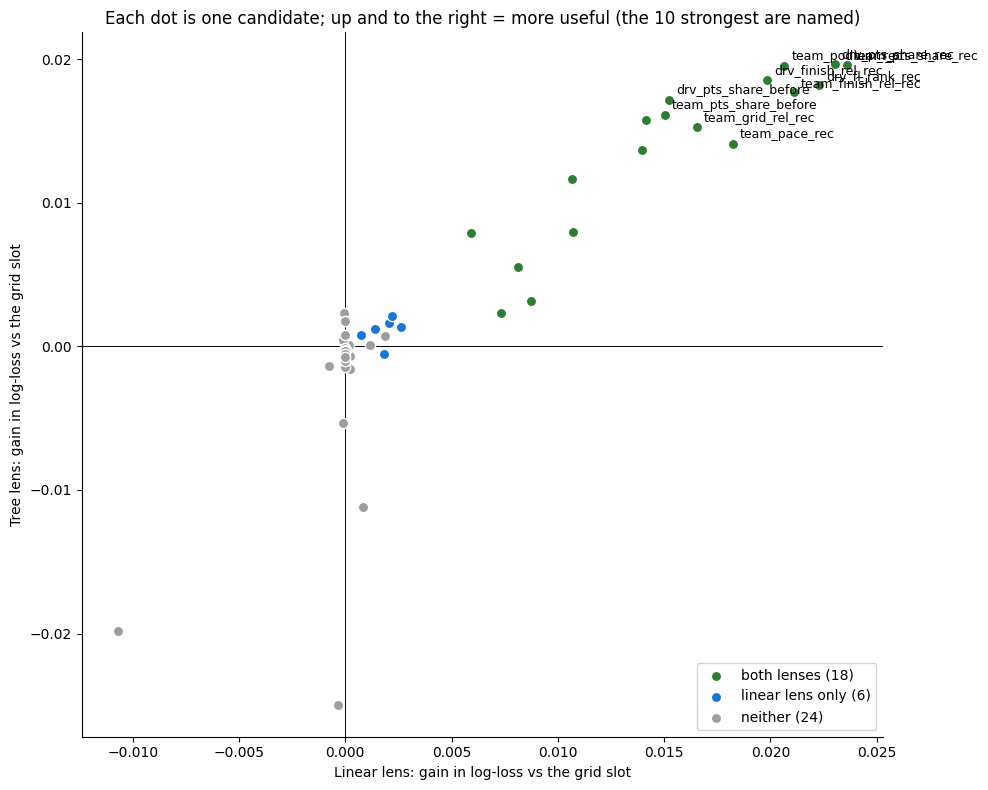

In [39]:
t = step1.copy()
t["tot"] = t["lr_gain"] + t["gbm_gain"]
t["status"] = np.select([t["lens1_keeps"] & t["lens2_keeps"], t["lens1_keeps"], t["lens2_keeps"]], ["both lenses", "linear lens only", "tree lens only"], "neither")
pal = {"both lenses": "#2E7D32", "linear lens only": "#1976D2", "tree lens only": "#F57C00", "neither": "#9E9E9E"}
fig, ax = plt.subplots(figsize=(10, 8))
for k, g in t.groupby("status"):
    ax.scatter(g["lr_gain"], g["gbm_gain"], s=55, c=pal[k], label=f"{k} ({len(g)})", edgecolor="white", zorder=3)
for u in t.sort_values("tot", ascending=False).index[:10]:
    ax.annotate(u, (t.loc[u, "lr_gain"], t.loc[u, "gbm_gain"]), xytext=(5, 4), textcoords="offset points", fontsize=9)
ax.axhline(0, color="black", lw=0.7); ax.axvline(0, color="black", lw=0.7)
ax.set_xlabel("Linear lens: gain in log-loss vs the grid slot"); ax.set_ylabel("Tree lens: gain in log-loss vs the grid slot")
ax.set_title("Each dot is one candidate; up and to the right = more useful (the 10 strongest are named)"); ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

**Reading the figure.** Each dot is one candidate: left to right is its gain in the linear lens, bottom to top its gain in the tree lens. **Green** dots (both lenses find a real gain) sit at the top right: the form, standings, car-strength and qualifying units. **Grey** dots cluster around the origin: no reliable gain in either lens. **Blue** (linear lens only) and **orange** (tree lens only) are the disagreements, which is why the rule keeps a feature if *either* lens finds a gain. The exact numbers are in the table above and in the per-feature blocks.

### 10.2 Concepts: is the idea useful, taken as a whole?

**Question.** Several features are different measurements of one idea (how strong the car is, how fast the driver qualified, how the season stands). Judged one at a time, near-identical measurements can knock each other out, and a whole idea can vanish because its members are interchangeable. So we first ask the question about the **idea**.

**What we do and why.** The 48 units are grouped into 16 concepts by what they measure (first table). Each concept is added **as a whole** to the grid slot and judged in both lenses with the usual rule (range above 0 and gain of at least 0.0005; kept if either lens passes). The last two columns, `loo_lr` and `loo_gbm`, are a side check: how much the predictions lose when the concept is removed from a model that contains all the others. They do not decide: a strong concept can show no loss there when another concept measures the same thing.

In [40]:
display(pd.DataFrame({"units": {c: len(us) for c, us in CONCEPTS.items()}, "members": {c: ", ".join(us) for c, us in CONCEPTS.items()}}))

cols_of_units = lambda us: [c for u in us for c in UNITS[u]]
ALL_NONLATE = BASE + cols_of_units([u for u in UNITS if u not in LATE_UNITS])
rows = []
for cname, us in CONCEPTS.items():
    late = all(u in LATE_UNITS for u in us)
    kw = dict(window=(2011, 2019), folds=FOLDS_LATE) if late else {}
    r = evaluate(full, BASE, BASE + cols_of_units(us), **kw)
    k1, k2 = lens_keep(r)
    if late:
        loo = {"loo_lr": np.nan, "loo_gbm": np.nan}
    else:
        rl = evaluate(full, [c for c in ALL_NONLATE if c not in cols_of_units(us)], ALL_NONLATE, p_test=False)
        loo = {"loo_lr": rl["lr_gain"], "loo_gbm": rl["gbm_gain"]}
    rows.append({"concept": cname, "units": len(us), "window": "2011-19" if late else f"{TRAIN_START}-19", "p_value": r["p"],
                 "lr_gain": r["lr_gain"], "lr_lo": r["lr_lo"], "lr_hi": r["lr_hi"], "gbm_gain": r["gbm_gain"], "gbm_lo": r["gbm_lo"], "gbm_hi": r["gbm_hi"],
                 "lens1_keeps": k1, "lens2_keeps": k2, "KEEP concept": k1 or k2, **loo})
concept_tab = pd.DataFrame(rows).set_index("concept")
concept_tab.to_csv("selection_outputs/concept_test.csv")
display(concept_tab[["units", "window", "p_value", "lr_gain", "lr_lo", "lr_hi", "gbm_gain", "gbm_lo", "gbm_hi", "lens1_keeps", "lens2_keeps", "KEEP concept", "loo_lr", "loo_gbm"]].round(4))
print("concepts kept:", int(concept_tab["KEEP concept"].sum()), "of", len(concept_tab), "| kept by both lenses:", int((concept_tab["lens1_keeps"] & concept_tab["lens2_keeps"]).sum()))

,units,members
Grid,2,"grid_rel, field"
Qualifying,6,"q_pos, q_gap_pct, q_reached, grid_minus_q, q1_..."
Qualifying form,2,"team_grid_rel_rec, grid_vs_usual"
Driver form,5,"drv_finish_rel_rec, drv_pts_share_rec, drv_lap..."
Team form,3,"team_finish_rel_rec, team_podium_rec, team_pts..."
Driver versus team,1,drv_vs_team_form
Teammate,3,"teammate_grid_rel, drv_vs_teammate_qgap, teamm..."
Standings,4,"drv_pts_share_before, team_pts_share_before, d..."
Reliability,2,"team_mech_dnf_rec, drv_incident_rec"
Race pace,4,"team_pace_rec, drv_pace_vs_team, drv_start_gai..."


,units,window,p_value,lr_gain,lr_lo,lr_hi,gbm_gain,gbm_lo,gbm_hi,lens1_keeps,lens2_keeps,KEEP concept,loo_lr,loo_gbm
concept,,,,,,,,,,,,,,
Grid,2,1950-19,0.4223,0.0006,0.0003,0.0008,-0.0005,-0.0018,0.0006,True,False,True,0.0003,-0.0000
Qualifying,6,1950-19,0.0000,0.0130,0.0079,0.0182,0.0074,0.0036,0.0108,True,True,True,0.0023,0.0017
Qualifying form,2,1950-19,0.0000,0.0181,0.0138,0.0222,0.0166,0.0119,0.0215,True,True,True,0.0001,0.0001
Driver form,5,1950-19,0.0000,0.0253,0.0190,0.0309,0.0201,0.0141,0.0264,True,True,True,-0.0002,0.0017
Team form,3,1950-19,0.0000,0.0234,0.0186,0.0284,0.0207,0.0156,0.0258,True,True,True,0.0002,0.0002
Driver versus team,1,1950-19,0.6741,0.0000,-0.0002,0.0002,-0.0010,-0.0021,0.0003,False,False,False,-0.0000,-0.0003
Teammate,3,1950-19,0.0000,0.0118,0.0091,0.0148,0.0100,0.0056,0.0154,True,True,True,0.0002,0.0001
Standings,4,1950-19,0.0000,0.0189,0.0145,0.0233,0.0187,0.0127,0.0251,True,True,True,0.0009,0.0004
Reliability,2,1950-19,0.0000,0.0029,0.0012,0.0042,0.0008,-0.0012,0.0026,True,False,True,-0.0004,-0.0002


concepts kept: 10 of 16 | kept by both lenses: 7


**Reading the result.** **10 of the 16 concepts are kept** (7 by both lenses, 3 by the logistic lens only).
* **Kept by both lenses:** *Driver form* (+0.0253 logistic, +0.0201 trees), *Team form* (+0.0234, +0.0207), *Race pace* (+0.0200, +0.0144), *Standings* (+0.0189, +0.0187), *Qualifying form* (+0.0181, +0.0166), *Qualifying* (+0.0130, +0.0074) and *Teammate* (+0.0118, +0.0100).
* **Kept by the logistic lens only:** *Driver profile* (+0.0030; the trees are worse, -0.0027, range -0.0088 to +0.0028), *Reliability* (+0.0029; trees +0.0008, range includes 0) and *Grid* extras (+0.0006, range +0.0003 to +0.0008, just above the minimum). Under the either-lens rule all three are kept.
* **Excluded whole (6):** *Driver versus team*, *Circuit history* (trees +0.0024, but the range starts at -0.0006), *Circuit description*, *Home*, *Pit stops* (2011-19: -0.0147 / -0.0313, they hurt) and *Calendar and era* (-0.0014 / -0.0039). The era indicators are now tested over 70 seasons and still add nothing on top of the baseline.


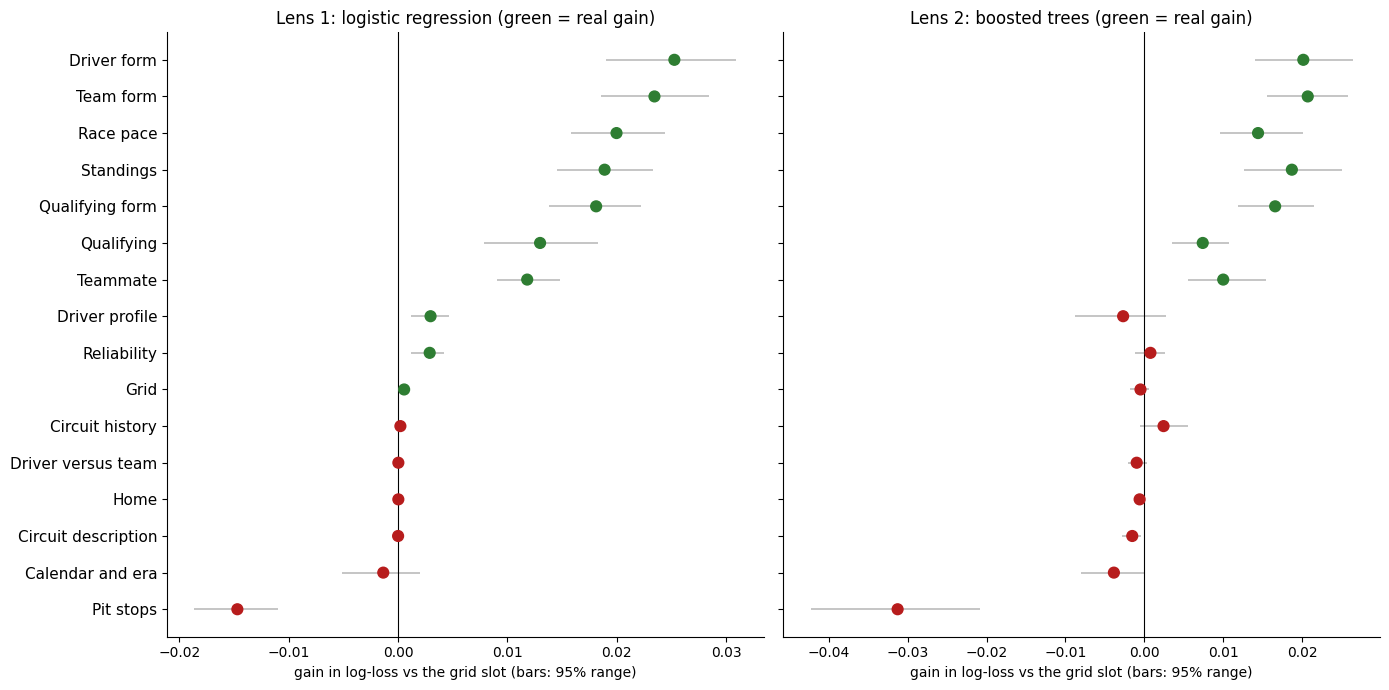

In [41]:
s = concept_tab.sort_values("lr_gain")
fig, ax = plt.subplots(1, 2, figsize=(14, 7), sharey=True)
for a, (m, ttl) in zip(ax, [("lr", "Lens 1: logistic regression"), ("gbm", "Lens 2: boosted trees")]):
    ok = (s[f"{m}_lo"] > 0) & (s[f"{m}_gain"] >= MIN_GAIN)
    a.errorbar(s[f"{m}_gain"], range(len(s)), xerr=[s[f"{m}_gain"] - s[f"{m}_lo"], s[f"{m}_hi"] - s[f"{m}_gain"]], fmt="none", ecolor="#bbbbbb", lw=1.2)
    a.scatter(s[f"{m}_gain"], range(len(s)), c=np.where(ok, "#2E7D32", "#B71C1C"), s=60, zorder=3)
    a.axvline(0, color="black", lw=0.8); a.set_title(ttl + " (green = real gain)"); a.set_xlabel("gain in log-loss vs the grid slot (bars: 95% range)")
ax[0].set_yticks(range(len(s))); ax[0].set_yticklabels(s.index, fontsize=11)
plt.tight_layout(); plt.show()

**Reading the figure.** Each dot is one concept: its gain in the linear lens on the left, in the tree lens on the right. The seven concepts green in both panels are the ones both lenses agree on; *Driver profile*, *Reliability* and *Grid* are green on the left only (the disagreements). *Pit stops* is clearly below zero in both lenses, and *Calendar and era* is below zero in the tree lens: adding them makes predictions worse.

### 10.3 Inside the kept concepts: which members stay, and which near-duplicates go

**Question.** A concept passing does not mean every member should enter the model. Which members are worth keeping, and which are copies of each other?

**What we do and why.** Three rules, in this order; each decision is printed.

* **(a) Members.** A member of a kept concept stays if it passed the individual test (10.1) in either lens. A member that failed alone gets one chance, judged inside its own concept: it stays only if it adds a real gain to the grid slot plus the members that passed. If no member of a kept concept passed alone, its best member represents it (and this is flagged).
* **(b) Near-duplicates.** Among the units left, any pair with Spearman `|rho|` of at least 0.9 (section 9.7) measures almost the same thing: the one with the lower individual gain (both lenses added) is removed. 0.9 is strict on purpose: it removes copies, not relatives.
* **(c)** What is left is the final list. Excluded concepts are excluded whole.

In [42]:
log_m = []
members = []                                                # units that survive (a)
score = (step1["lr_gain"] + step1["gbm_gain"])
for cname, us in CONCEPTS.items():
    if not concept_tab.loc[cname, "KEEP concept"]:
        for u in us:
            log_m.append({"concept": cname, "unit": u, "step": "(a) concept", "decision": "EXCLUDE", "reason": "concept shows no real gain in either lens"})
        continue
    late = all(u in LATE_UNITS for u in us)
    kw = dict(window=(2011, 2019), folds=FOLDS_LATE) if late else {}
    passers = [u for u in us if step1.loc[u, "keep_step1"]]
    failers = [u for u in us if u not in passers]
    chosen = list(passers)
    if not passers:
        best = max(us, key=lambda u: score[u])
        chosen = [best]
        log_m.append({"concept": cname, "unit": best, "step": "(a) member", "decision": "INCLUDE", "reason": "concept passes jointly, no member passes alone: best member represents it (flagged)"})
        failers = [u for u in us if u != best]
    for u in passers:
        log_m.append({"concept": cname, "unit": u, "step": "(a) member", "decision": "INCLUDE", "reason": "passes alone in at least one lens"})
    base_c = BASE + cols_of_units(chosen)
    for u in failers:
        r = evaluate(full, base_c, base_c + UNITS[u], p_test=False, **kw)
        k1, k2 = lens_keep(r)
        if k1 or k2:
            chosen.append(u)
            log_m.append({"concept": cname, "unit": u, "step": "(a) member", "decision": "INCLUDE", "reason": f"fails alone, adds a real gain inside its concept (lens 1 {r['lr_gain']:+.4f}, lens 2 {r['gbm_gain']:+.4f})"})
        else:
            log_m.append({"concept": cname, "unit": u, "step": "(a) member", "decision": "EXCLUDE", "reason": f"fails alone and adds no real gain inside its concept (lens 1 {r['lr_gain']:+.4f}, lens 2 {r['gbm_gain']:+.4f})"})
    members += chosen

pairs = sorted([(abs(rho.loc[a, b]), a, b) for i, a in enumerate(members) for b in members[i + 1:] if abs(rho.loc[a, b]) >= 0.9], reverse=True)
removed_dup, dup_log = set(), []
for r_, a, b in pairs:
    if a in removed_dup or b in removed_dup:
        continue
    drop, keep_ = (a, b) if score[a] < score[b] else (b, a)
    removed_dup.add(drop)
    dup_log.append({"pair": f"{a}  ~  {b}", "|rho|": round(r_, 3), "removed": drop, "kept": keep_, "gain of removed": round(score[drop], 4), "gain of kept": round(score[keep_], 4)})
    log_m.append({"concept": CONCEPT_OF[drop], "unit": drop, "step": "(b) near-duplicate", "decision": "EXCLUDE", "reason": f"|rho| {r_:.2f} with {keep_}, which has the higher gain"})
FINAL_C = [u for u in UNITS if u in members and u not in removed_dup]
member_log = pd.DataFrame(log_m)
member_log.to_csv("selection_outputs/concept_member_log.csv", index=False)
print("units in kept concepts:", len(members), "| removed as near-duplicates:", len(removed_dup), "| FINAL units:", len(FINAL_C))
display(pd.DataFrame(dup_log))
print("\nmember decisions inside kept concepts:")
display(member_log[member_log["step"] != "(a) concept"].set_index(["concept", "unit"]))
print("\nexcluded whole concepts:", [c for c in CONCEPTS if not concept_tab.loc[c, "KEEP concept"]])
print("FINAL units by concept:", {c: [u for u in FINAL_C if CONCEPT_OF[u] == c] for c in CONCEPTS if any(CONCEPT_OF[u] == c for u in FINAL_C)})
pd.Series(FINAL_C, name="unit").to_csv("selection_outputs/final_units_method_C.csv", index=False)

units in kept concepts: 28 | removed as near-duplicates: 4 | FINAL units: 24


,pair,|rho|,removed,kept,gain of removed,gain of kept
0,grid_rel ~ q_pos,0.962,grid_rel,q_pos,0.0003,0.0096
1,team_podium_rec ~ team_pts_share_rec,0.914,team_podium_rec,team_pts_share_rec,0.0402,0.0431
2,drv_finish_rel_rec ~ drv_fl_rank_rec,0.913,drv_finish_rel_rec,drv_fl_rank_rec,0.0384,0.0404
3,drv_pts_share_rec ~ drv_fl_rank_rec,0.902,drv_fl_rank_rec,drv_pts_share_rec,0.0404,0.0426



member decisions inside kept concepts:


step decision                                             reason
concept         unit                                                                                                 
Grid            grid_rel                       (a) member  INCLUDE  concept passes jointly, no member passes alone...
                field                          (a) member  EXCLUDE  fails alone and adds no real gain inside its c...
Qualifying      q_pos                          (a) member  INCLUDE                  passes alone in at least one lens
                q_gap_pct                      (a) member  INCLUDE                  passes alone in at least one lens
                q1_gap_pct                     (a) member  INCLUDE                  passes alone in at least one lens
                q_last_gap_pct                 (a) member  INCLUDE                  passes alone in at least one lens
                q_reached                      (a) member  EXCLUDE  fails alone and adds no real gain inside its c...
                grid_minus_q                   (a) member  EXCLUDE  fails alone and adds no real gain inside its c...
Qualifying form team_grid_rel_rec              (a) member  INCLUDE                  passes alone in at least one lens
                grid_vs_usual                  (a) member  INCLUDE                  passes alone in at least one lens
Driver form     drv_finish_rel_rec             (a) member  INCLUDE                  passes alone in at least one lens
                drv_pts_share_rec              (a) member  INCLUDE                  passes alone in at least one lens
                drv_laps_share_rec             (a) member  INCLUDE                  passes alone in at least one lens
                drv_fl_rank_rec                (a) member  INCLUDE                  passes alone in at least one lens
                drv_pos_gains_rec              (a) member  EXCLUDE  fails alone and adds no real gain inside its c...
Team form       team_finish_rel_rec            (a) member  INCLUDE                  passes alone in at least one lens
                team_podium_rec                (a) member  INCLUDE                  passes alone in at least one lens
                team_pts_share_rec             (a) member  INCLUDE                  passes alone in at least one lens
Teammate        teammate_grid_rel              (a) member  INCLUDE                  passes alone in at least one lens
                drv_vs_teammate_qgap           (a) member  INCLUDE                  passes alone in at least one lens
                teammate_form_rec              (a) member  INCLUDE                  passes alone in at least one lens
Standings       drv_pts_share_before           (a) member  INCLUDE                  passes alone in at least one lens
                team_pts_share_before          (a) member  INCLUDE                  passes alone in at least one lens
                drv_champ_rank_before          (a) member  INCLUDE                  passes alone in at least one lens
                drv_wins_before                (a) member  INCLUDE                  passes alone in at least one lens
Reliability     drv_incident_rec               (a) member  INCLUDE                  passes alone in at least one lens
                team_mech_dnf_rec              (a) member  EXCLUDE  fails alone and adds no real gain inside its c...
Race pace       team_pace_rec                  (a) member  INCLUDE                  passes alone in at least one lens
                drv_start_gain_rec             (a) member  INCLUDE                  passes alone in at least one lens
                drv_pace_vs_team               (a) member  INCLUDE  fails alone, adds a real gain inside its conce...
                drv_lap_spread_rec             (a) member  INCLUDE  fails alone, adds a real gain inside its conce...
Driver profile  drv_prior_starts               (a) member  INCLUDE                  passes alone in at least one lens
                age                      


excluded whole concepts: ['Driver versus team', 'Pit stops', 'Circuit history', 'Circuit description', 'Home', 'Calendar and era']
FINAL units by concept: {'Qualifying': ['q_pos', 'q_gap_pct', 'q1_gap_pct', 'q_last_gap_pct'], 'Qualifying form': ['team_grid_rel_rec', 'grid_vs_usual'], 'Driver form': ['drv_pts_share_rec', 'drv_laps_share_rec'], 'Team form': ['team_finish_rel_rec', 'team_pts_share_rec'], 'Teammate': ['teammate_grid_rel', 'drv_vs_teammate_qgap', 'teammate_form_rec'], 'Standings': ['drv_pts_share_before', 'team_pts_share_before', 'drv_champ_rank_before', 'drv_wins_before'], 'Reliability': ['drv_incident_rec'], 'Race pace': ['team_pace_rec', 'drv_pace_vs_team', 'drv_start_gain_rec', 'drv_lap_spread_rec'], 'Driver profile': ['age', 'drv_prior_starts']}


**Reading the result.**
* **Members.** The 10 kept concepts hold 33 units. Five members fail alone and add nothing inside their concept, so they go: `field`, `q_reached`, `grid_minus_q`, `drv_pos_gains_rec` and `team_mech_dnf_rec`. Three members fail alone but add a real gain inside their concept and stay: `drv_pace_vs_team` (logistic +0.0015), `drv_lap_spread_rec` (trees +0.0009) and `age` (logistic +0.0008, although the trees lose 0.0048). No member of *Grid* passes alone, so its best member, `grid_rel`, represents it (flagged). 28 units survive rule (a).
* **Near-duplicates (the correlation step of 9.7).** Rule (b) removes **4 units**: `grid_rel` (|rho| 0.96 with `q_pos`), `team_podium_rec` (0.91 with `team_pts_share_rec`), `drv_finish_rel_rec` (0.91 with `drv_fl_rank_rec`) and `drv_fl_rank_rec` (0.90 with `drv_pts_share_rec`, the most borderline). The pairs are taken from the most to the least correlated, so `drv_finish_rel_rec` goes against `drv_fl_rank_rec`, which then goes against `drv_pts_share_rec`; all three describe the driver's recent results, and `drv_pts_share_rec` keeps that information. In every pair the two gains are close (for example 0.0402 against 0.0431), so which copy survives matters little. The *Grid* concept is left without members: its information is carried by `q_pos`.
* **The final list is 24 units in 9 concepts** (33 columns with the 8 baseline columns and the square of `age`): Qualifying `q_pos`, `q_gap_pct`, `q1_gap_pct`, `q_last_gap_pct`; Qualifying form `team_grid_rel_rec`, `grid_vs_usual`; Driver form `drv_pts_share_rec`, `drv_laps_share_rec`; Team form `team_finish_rel_rec`, `team_pts_share_rec`; Teammate `teammate_grid_rel`, `drv_vs_teammate_qgap`, `teammate_form_rec`; Standings `drv_pts_share_before`, `team_pts_share_before`, `drv_champ_rank_before`, `drv_wins_before`; Reliability `drv_incident_rec`; Race pace `team_pace_rec`, `drv_pace_vs_team`, `drv_start_gain_rec`, `drv_lap_spread_rec`; Driver profile `age`, `drv_prior_starts`.

### 10.4 All features with their decisions (the final list)

**What we do and why.** One row per candidate: its concept, the verdict of its own test (10.1), what the concept test (10.2) and the group step (10.3) did to it, and the final decision. The **final feature list is generated from this table**.

In [43]:
fate_map = member_log.groupby("unit")["reason"].apply(lambda s: "; then ".join(s))
rows = []
for u in UNITS:
    c = CONCEPT_OF[u]
    rows.append({"unit": u, "concept": c, "alone (10.1)": "include" if step1.loc[u, "keep_step1"] else "exclude",
                 "concept kept (10.2)": "yes" if concept_tab.loc[c, "KEEP concept"] else "no",
                 "group step (10.3)": fate_map.get(u, "concept excluded"), "FINAL": "INCLUDE" if u in FINAL_C else "EXCLUDE"})
DECISION_LOG = pd.DataFrame(rows).set_index("unit")
DECISION_LOG.to_csv("selection_outputs/decision_log.csv")
with pd.option_context("display.max_colwidth", 90, "display.max_rows", 100):
    display(DECISION_LOG)
FINAL_UNITS = [u for u in UNITS if u in FINAL_C]
FINAL_FEATURES = BASE + [c for u in FINAL_UNITS for c in UNITS[u]]
print("FINAL feature list:", len(FINAL_UNITS), "units,", len(FINAL_FEATURES), "columns (including the baseline columns", BASE, ")")
print(DECISION_LOG.groupby(["concept", "FINAL"]).size().unstack(fill_value=0))
assert not (set(FINAL_FEATURES) & {"positionOrder", "points", "laps", "status", "rank", "pace_rel", "lap_spread", "start_gain", "pit_s", "n_stops", "podium", "positionText"}), "a post-race column is in the feature list"

,concept,alone (10.1),concept kept (10.2),group step (10.3),FINAL
unit,,,,,
grid_rel,Grid,exclude,yes,"concept passes jointly, no member passes alone: best member represents it (flagged); t...",EXCLUDE
field,Grid,exclude,yes,"fails alone and adds no real gain inside its concept (lens 1 +0.0004, lens 2 -0.0006)",EXCLUDE
q_pos,Qualifying,include,yes,passes alone in at least one lens,INCLUDE
q_gap_pct,Qualifying,include,yes,passes alone in at least one lens,INCLUDE
q_reached,Qualifying,exclude,yes,"fails alone and adds no real gain inside its concept (lens 1 +0.0003, lens 2 +0.0003)",EXCLUDE
grid_minus_q,Qualifying,exclude,yes,"fails alone and adds no real gain inside its concept (lens 1 -0.0001, lens 2 +0.0002)",EXCLUDE
q1_gap_pct,Qualifying,include,yes,passes alone in at least one lens,INCLUDE
q_last_gap_pct,Qualifying,include,yes,passes alone in at least one lens,INCLUDE
team_finish_rel_rec,Team form,include,yes,passes alone in at least one lens,INCLUDE


FINAL feature list: 24 units, 33 columns (including the baseline columns ['grid', 'grid_unassigned', 'q_knockout', 'has_quali', 'has_lap_times', 'has_team_standings', 'has_driver_history', 'has_teammate'] )
FINAL                EXCLUDE  INCLUDE
concept                              
Calendar and era           4        0
Circuit description        3        0
Circuit history            3        0
Driver form                3        2
Driver profile             0        2
Driver versus team         1        0
Grid                       2        0
Home                       2        0
Pit stops                  2        0
Qualifying                 2        4
Qualifying form            0        2
Race pace                  0        4
Reliability                1        1
Standings                  0        4
Team form                  1        2
Teammate                   0        3


**Reading the table.** **Included: 24 units in 9 concepts** (33 columns with the 8 baseline columns and the square of `age`). **Excluded:** 6 concepts whole (15 units) and, inside kept concepts, 5 members that fail alone and 4 near-duplicates; the *Grid* concept passes, but none of its members survive. Within qualifying, `q_pos`, `q_gap_pct`, `q1_gap_pct` and `q_last_gap_pct` stay; `q_reached` and `grid_minus_q` go (neither adds anything inside the concept).

**One entry needs care:** `age` enters through the logistic lens inside *Driver profile* (+0.0008), although alone it makes the trees worse (-0.0112). The either-lens rule keeps it; 14.3 ranks it last. The two trials of 10.6 end with different lists: Trial A keeps 8 units, Trial B 8.

**What the strongest included features look like.** The tables say how much each feature adds; this figure shows what the features actually do. For the six included features with the largest gains, the training rows (1950-2019) are cut into five equal-size bands of the feature, and each bar is the podium rate in that band with its 95% interval. A feature that matters shows a clear slope from the lowest to the highest band; flat bars would mean it does nothing.

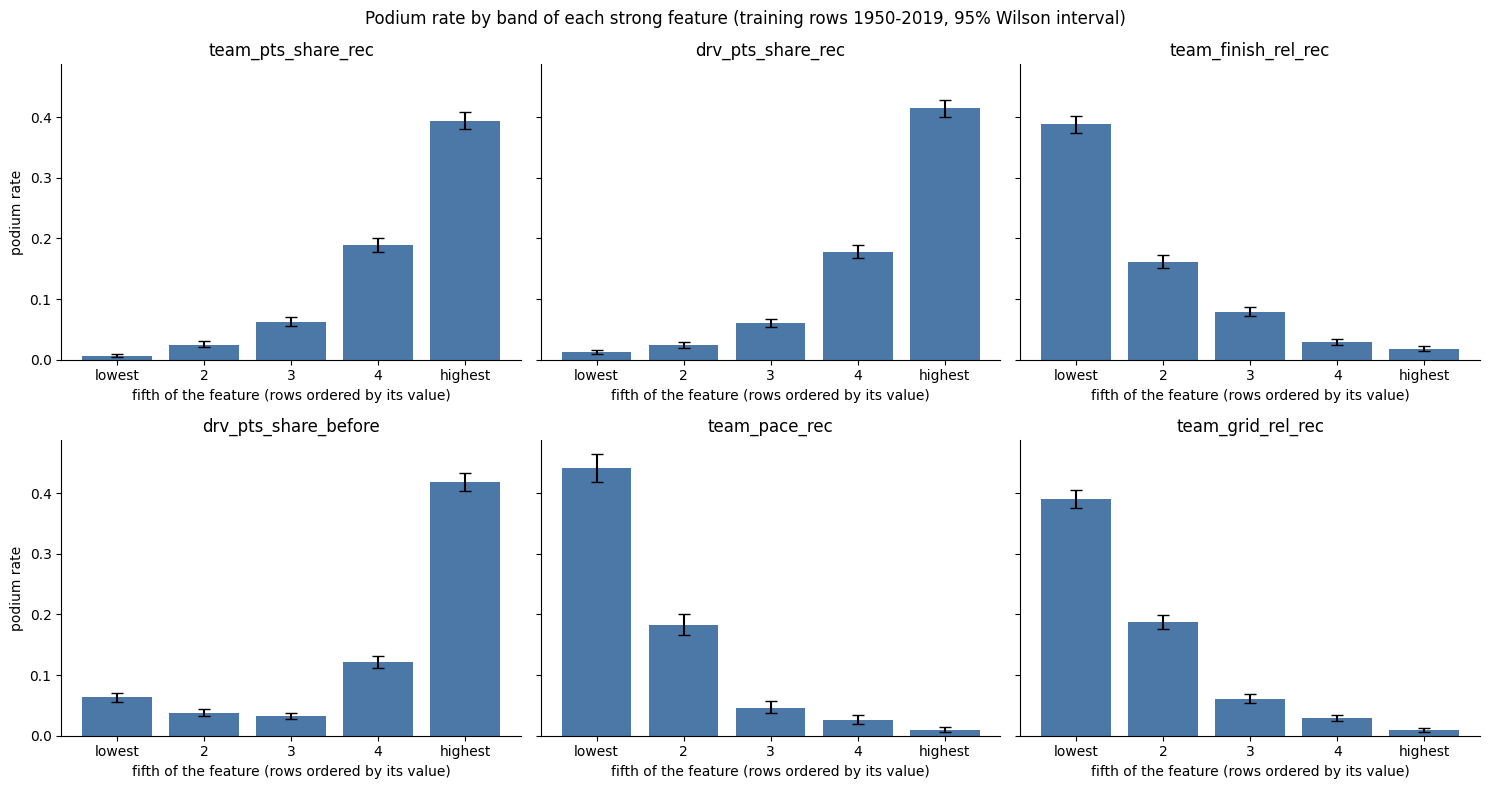

In [44]:
tr_eff = full[full["year"].between(TRAIN_START, 2019)]
inc = [u for u in FINAL_UNITS]
strong = (step1.loc[inc, "lr_gain"] + step1.loc[inc, "gbm_gain"]).sort_values(ascending=False).head(6).index.tolist()
def wilson_ci(k, n, z=1.96):
    p = k / n; d = 1 + z * z / n
    c = (p + z * z / (2 * n)) / d; h = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return c - h, c + h
fig, ax = plt.subplots(2, 3, figsize=(15, 8), sharey=True)
for a, u in zip(ax.ravel(), strong):
    col = UNITS[u][0]
    d_ = tr_eff[[col, "podium"]].dropna()
    band = pd.qcut(d_[col].rank(method="first"), 5, labels=False)
    g = d_.groupby(band)["podium"].agg(["sum", "size"])
    rate = g["sum"] / g["size"]
    ci = np.array([wilson_ci(k, n) for k, n in zip(g["sum"], g["size"])])
    a.bar(range(5), rate, color="#4C78A8", yerr=[rate - ci[:, 0], ci[:, 1] - rate], capsize=4)
    a.set_title(col, fontsize=12); a.set_xticks(range(5)); a.set_xticklabels(["lowest", "2", "3", "4", "highest"])
    a.set_xlabel("fifth of the feature (rows ordered by its value)")
ax[0, 0].set_ylabel("podium rate"); ax[1, 0].set_ylabel("podium rate")
plt.suptitle(f"Podium rate by band of each strong feature (training rows {TRAIN_START}-2019, 95% Wilson interval)")
plt.tight_layout(); plt.show()

**Reading the figure.** All six features show a clear slope of the podium rate across their bands (each band holds about 4,400-4,500 rows; `team_pace_rec` about 1,850, because lap times start in 1996).
* **The shape is a threshold, not a straight line.** For the two recent points shares the bottom bands are low and the rate then jumps: `team_pts_share_rec` 0.6 %, 2.5 %, 6.2 %, 18.9 %, 39.4 %; `drv_pts_share_rec` 1.3 %, 2.3 %, 6.0 %, 17.8 %, 41.4 %.
* **The same threshold the other way round** for the three features where a small value is good: `team_finish_rel_rec` (best band 38.8 %, then 16.2 %, 7.9 %, 3.0 %, 1.8 %), `team_grid_rel_rec` (39.0 %, 18.8 %, 6.1 %, 2.9 %, 0.9 %) and `team_pace_rec` (the fastest cars 44.1 %, then 18.3 %, 4.6 %, 2.7 %, 0.9 %).
* This threshold shape is why the tree lens finds gains a straight line cannot.
* **The dip in `drv_pts_share_before`** (6.3 % in the lowest band, 3.8 % and 3.2 % in the next two): 9,369 training rows (41 %) tie at exactly 0, because in older seasons only the first five or six scored points. 1,516 of them are first races of a season, where every driver has 0 points (14.1 % podiums); the other 7,853 are drivers who really have no points yet (3.2 % podiums). The bands are cut after ranking with ties broken by row order, so how the first-race rows spread over the three lowest bands is arbitrary. In the first race of a season this feature carries no information.

### 10.5 Training window: would a later start predict better?

**Question.** Training uses every season (8.2). With the final feature list, would a later start, where more of the features exist, predict the validation seasons better?

**Candidates.** All seasons from 1950 (the reference), 1958 (constructor standings exist), 1994 (first qualifying data), 2003 (complete qualifying) and 2014 (the closest era). The season weights of 9.4b apply to all of them.

**Test.** The same logistic regression for every window, on the final features, with the median fill and the scaling fitted on that window's rows only, scored on the validation seasons 2020-21 with **PR-AUC**. The 95% range of "PR-AUC minus all seasons" comes from redrawing whole races. As a second check, boosted trees are trained and scored the same way.

**Rule (fixed before the result).** All seasons stay **unless** a later start beats them in the logistic lens with the 95% range above 0; if one did, it would be reported and the selection of section 10 rerun on that window.

In [45]:
FE = list(FINAL_FEATURES)
NUM_COLS = list(FE)

def make_prep(train_rows):
    """Fill with the training median, then standardise; both fitted on the given training rows ONLY."""
    imp = SimpleImputer(strategy="median").fit(train_rows[NUM_COLS])
    sc = StandardScaler().fit(imp.transform(train_rows[NUM_COLS]))
    return lambda d: sc.transform(imp.transform(d[NUM_COLS]))

def race_bootstrap_indices(d, n=1000, seed=SEED):
    """Row indices of n resamples of WHOLE RACES (drivers of one race are not independent)."""
    idx = d.groupby("raceId").indices
    ids = list(idx)
    rng_b = np.random.default_rng(seed)
    return [np.concatenate([idx[r] for r in rng_b.choice(ids, len(ids))]) for _ in range(n)]

va_ = full[full["year"].between(2020, 2021)].reset_index(drop=True)
REF = f"{TRAIN_START} (all seasons)"
CANDIDATES = [(REF, TRAIN_START), ("1958", 1958), ("1994", 1994), ("2003", 2003), ("2014", 2014)]

preds, preds_tree, sizes = {}, {}, {}
for name, start in CANDIDATES:
    tr_ = full[full["year"].between(start, 2019)]
    prep = make_prep(tr_)
    clf = LogisticRegression(max_iter=3000).fit(prep(tr_), tr_["podium"].astype(int), sample_weight=train_weights(tr_))
    preds[name] = clf.predict_proba(prep(va_))[:, 1]
    gb = make_gbm().fit(tr_[FE].to_numpy(float), tr_["podium"].astype(int), sample_weight=train_weights(tr_))
    preds_tree[name] = gb.predict_proba(va_[FE].to_numpy(float))[:, 1]
    sizes[name] = len(tr_)

y = va_["podium"].astype(int).to_numpy()
boots = race_bootstrap_indices(va_)
rows = []
for name in preds:
    row = {"window": name, "training rows": sizes[name]}
    for lens, P in (("logistic", preds), ("trees", preds_tree)):
        d_ = [average_precision_score(y[i], P[name][i]) - average_precision_score(y[i], P[REF][i]) for i in boots]
        lo, hi = np.percentile(d_, [2.5, 97.5])
        row.update({f"{lens} PR-AUC": average_precision_score(y, P[name]), f"{lens} log-loss": log_loss(y, P[name]),
                    f"{lens} vs all seasons": average_precision_score(y, P[name]) - average_precision_score(y, P[REF]), f"{lens} range low": lo, f"{lens} range high": hi})
    rows.append(row)
window_table = pd.DataFrame(rows).set_index("window").round(4)
display(window_table[["training rows", "logistic PR-AUC", "logistic log-loss", "logistic vs all seasons", "logistic range low", "logistic range high"]])
display(window_table[["trees PR-AUC", "trees log-loss", "trees vs all seasons", "trees range low", "trees range high"]])
win = window_table[(window_table.index != REF) & (window_table["logistic range low"] > 0)]
print("DECISION:", ("a later start (" + win.sort_values("logistic vs all seasons").index[-1] + ") beats all seasons: report it and rerun section 10 on that window") if len(win) else "KEEP all seasons",
      "| rule: a later start replaces all seasons only if it beats them with the 95% range above 0 (logistic)")
print("check with the trees: later starts beating all seasons with the range above 0:", list(window_table[(window_table.index != REF) & (window_table["trees range low"] > 0)].index) or "none")
print("random-guess PR-AUC (= validation podium rate):", round(float(y.mean()), 3))


,training rows,logistic PR-AUC,logistic log-loss,logistic vs all seasons,logistic range low,logistic range high
window,,,,,,
1950 (all seasons),22604,0.7355,0.2198,0.0000,0.0000,0.0000
1958,21432,0.7333,0.2199,-0.0022,-0.0050,0.0003
1994,10167,0.7450,0.2186,0.0095,-0.0029,0.0221
2003,6822,0.7512,0.2158,0.0157,-0.0044,0.0352
2014,2485,0.7461,0.2217,0.0106,-0.0131,0.0345


,trees PR-AUC,trees log-loss,trees vs all seasons,trees range low,trees range high
window,,,,,
1950 (all seasons),0.7464,0.2169,0.0000,0.0000,0.0000
1958,0.7439,0.2196,-0.0025,-0.0108,0.0066
1994,0.7451,0.2204,-0.0013,-0.0147,0.0144
2003,0.7214,0.2206,-0.0250,-0.0444,-0.0059
2014,0.7190,0.2265,-0.0274,-0.0524,0.0006


DECISION: KEEP all seasons | rule: a later start replaces all seasons only if it beats them with the 95% range above 0 (logistic)
check with the trees: later starts beating all seasons with the range above 0: none
random-guess PR-AUC (= validation podium rate): 0.15


**Reading the result.** **Keep all seasons.** No later start beats all seasons in the logistic lens with the range above 0: 1958 -0.0022 (95% range -0.0050 to +0.0003), 1994 +0.0095 (-0.0029 to +0.0221), 2003 +0.0157 (-0.0044 to +0.0352) and 2014 +0.0106 (-0.0131 to +0.0345). All seasons score a validation PR-AUC of 0.7355 (random guessing 0.150).
* **The logistic point estimates lean towards a later start** (2003: 0.7512), but the ranges are wide: 39 validation races cannot tell these windows apart, and the rule fixed in advance requires a range above 0.
* **The trees lean the other way:** every later start scores lower than all seasons (1958 -0.0025, 1994 -0.0013, 2003 -0.0250, 2014 -0.0274), and for 2003 the range is entirely below 0 (-0.0444 to -0.0059): for the trees, all seasons are measurably better than starting in 2003.
* The two lenses point in opposite directions, both inside the noise, so there is no evidence that dropping old seasons helps.

### 10.6 Earlier attempts (recorded, then replaced)

Two earlier ways of choosing features were run as real attempts, each with its own reading.

**Trial A: the classical p-value rule.** Keep a feature when its likelihood-ratio p-value is below 0.05: (1) keep every unit whose p-value against the grid slot is below 0.05; (2) put the survivors in one logistic regression and remove, one at a time, the unit with the highest p-value until all remaining units have p < 0.05 (**backward elimination**). It is replaced because the p-value measures fit on the training data, not prediction of later seasons, and overlapping features each look redundant given the others.

In [46]:
WIN = full[full["year"].between(TRAIN_START, 2019)]
combinable = [u for u in UNITS if u not in LATE_UNITS]

survA = [u for u in combinable if step1.loc[u, "p_value"] < 0.05]
print("Trial A, step 1: units with p < 0.05 alone vs the grid:", len(survA), "of", len(combinable), "(late-coverage pit-stop units judged separately)")
log_A = []
cur = list(survA)
while True:
    cols_all = BASE + [c for u in cur for c in UNITS[u]]
    pv, n_rows_A = lr_drop_pvalues(WIN, cols_all, {u: UNITS[u] for u in cur})
    worst = max(pv, key=lambda k: (np.nan_to_num(pv[k], nan=1.0)))
    if np.nan_to_num(pv[worst], nan=1.0) < 0.05:
        break
    log_A.append((worst, pv[worst], len(cur)))
    cur.remove(worst)
print("Trial A, step 2: removed one at a time (unit, its p-value when removed):")
display(pd.DataFrame(log_A, columns=["removed unit", "p-value", "units before removal"]).round(4))
FINAL_A = list(cur)
final_A_p = pd.Series(pv).rename("p in the final model").round(4)
print("\nTrial A final list:", len(FINAL_A), "units | complete-case rows in its logistic model:", n_rows_A)
display(final_A_p.to_frame())

Trial A, step 1: units with p < 0.05 alone vs the grid: 30 of 46 (late-coverage pit-stop units judged separately)
Trial A, step 2: removed one at a time (unit, its p-value when removed):


,removed unit,p-value,units before removal
0,q_pos,1.0000,30
1,q_last_gap_pct,0.9048,29
2,drv_pos_gains_rec,0.9051,28
3,circ_overtake,0.8682,27
4,drv_pts_share_before,0.8115,26
5,drv_finish_rel_rec,0.7027,25
6,drv_vs_teammate_qgap,0.6896,24
7,drv_laps_share_rec,0.7108,23
8,teammate_form_rec,0.6320,22
9,team_finish_rel_rec,0.6947,21



Trial A final list: 8 units | complete-case rows in its logistic model: 5757


,p in the final model
q_reached,0.0000
grid_minus_q,0.0001
drv_pts_share_rec,0.0000
teammate_grid_rel,0.0105
team_pts_share_before,0.0081
team_pace_rec,0.0002
age,0.0406
drv_prior_starts,0.0342


**Reading the result (Trial A).** 30 of 46 units have p < 0.05 alone. Backward elimination then removes them one at a time, always the highest p-value: `q_pos` goes **first (p = 1.00)**, `q_last_gap_pct` second (p = 0.90) and `q_gap_pct` last (p = 0.070), because these columns overlap with each other and with `grid`. The final list has 8 units (`q_reached`, `grid_minus_q`, `drv_pts_share_rec`, `teammate_grid_rel`, `team_pts_share_before`, `team_pace_rec`, `age`, `drv_prior_starts`; all p < 0.05 in the final model, the highest 0.041). Two failures of the p-value rule show here. (1) It keeps `age`, although 10.1 shows that `age` alone makes the trees' predictions on later seasons worse: the p-value measures fit on the training rows, not prediction. (2) The classical model needs complete rows, so it is fitted on only **5,757 rows** (about a quarter of the training data, the rows with every value): the p-value rule silently throws away the older seasons this version set out to keep.

**Trial B: removing one feature at a time by out-of-sample gain.** Put every unit that passed 10.1 into one model with the grid slot. First remove whole clusters of near-duplicates (|rho| of at least 0.8, section 9.7) that add nothing together, then the single weakest unit that fails both lenses; refit and repeat. Finally give every dropped unit a second chance against the survivors. It is replaced because units that are statistical twins knock each other out, so which twin survives is close to arbitrary, and it ends with too few columns per idea for a feature-group ablation to compare.

In [47]:
def combined_tables(units_now, groups):
    # for every unit AND every multi-unit group: gain of keeping it, measured as loss(without) - loss(with everything), in both lenses
    cols_all = BASE + [c for u in units_now for c in UNITS[u]]
    d = WIN
    full_preds = {m: fold_predictions(d, cols_all, m, FOLDS) for m in ("lr", "gbm")}
    sets = {u: UNITS[u] for u in units_now}
    sets.update({f"group {g}: " + " + ".join(m): [c for u in m for c in UNITS[u]] for g, m in groups.items()})
    pmap, _ = lr_drop_pvalues(d, cols_all, sets)
    def one(label, drop_units):
        drop_cols = {c for u in drop_units for c in UNITS[u]}
        without = [c for c in cols_all if c not in drop_cols]
        r = {"item": label, "n_units": len(drop_units)}
        for m in ("lr", "gbm"):
            y, p0, rr = fold_predictions(d, without, m, FOLDS)
            g, lo, hi, _, _ = pooled_gain(y, p0, full_preds[m][1], rr)
            r.update({f"{m}_gain": g, f"{m}_lo": lo, f"{m}_hi": hi})
        r["p_value"] = pmap[label]
        r["keep"] = bool(passes(r["lr_gain"], r["lr_lo"]) or passes(r["gbm_gain"], r["gbm_lo"]))
        return r
    units_tab = pd.DataFrame([one(u, [u]) for u in units_now]).set_index("item")
    group_tab = pd.DataFrame([one(f"group {g}: " + " + ".join(m), m) for g, m in groups.items()]).set_index("item") if groups else pd.DataFrame()
    return units_tab, group_tab

def current_groups(units_now):
    lab = CL.loc[[u for u in units_now]]
    return {int(g): list(s.index) for g, s in lab.groupby(lab) if len(s) > 1}

survB = [u for u in combinable if step1.loc[u, "keep_step1"]]
print("Step 2 starts with", len(survB), "units that passed Step 1 in either lens")
log_B, cur = [], list(survB)
rnd = 0
while True:
    rnd += 1
    groups = current_groups(cur)
    ut, gt = combined_tables(cur, groups)
    remove = {}
    for name, row in gt.iterrows():                          # (a) a group that adds nothing jointly goes entirely
        if not row["keep"]:
            gid = int(name.split(":")[0].replace("group ", ""))
            for u in groups[gid]:
                remove[u] = f"whole group {gid} adds nothing jointly (lens 1 range {row['lr_lo']:+.4f}, lens 2 range {row['gbm_lo']:+.4f})"
    if not remove:                                           # (b) otherwise ONE unit per round: the weakest of those failing both lenses
        failing = [u for u in cur if not ut.loc[u, "keep"]]
        if failing:
            weakest = min(failing, key=lambda u: ut.loc[u, "lr_gain"] + ut.loc[u, "gbm_gain"])
            remove[weakest] = f"fails both lenses (lens 1 range {ut.loc[weakest, 'lr_lo']:+.4f}, lens 2 range {ut.loc[weakest, 'gbm_lo']:+.4f}); the weakest of {len(failing)} failing"
    print(f"round {rnd}: {len(cur)} units | rows in the combined model: {len(WIN)} | groups tested: {len(groups)} | removed: {list(remove)}")
    if not remove:
        FINAL_TABLE = ut
        break
    for u, why in remove.items():
        log_B.append({"round": rnd, "unit": u, "reason": why})
        cur.remove(u)
    if rnd >= 60:
        FINAL_TABLE = ut
        break
SURV_B2 = list(cur)
log_B = pd.DataFrame(log_B)
display(log_B)
print("\nStep 2 survivors:", len(SURV_B2))

Step 2 starts with 24 units that passed Step 1 in either lens
round 1: 24 units | rows in the combined model: 22604 | groups tested: 4 | removed: ['q_gap_pct', 'q1_gap_pct', 'drv_pts_share_before', 'drv_champ_rank_before', 'drv_finish_rel_rec', 'drv_pts_share_rec', 'drv_fl_rank_rec']
round 2: 17 units | rows in the combined model: 22604 | groups tested: 1 | removed: ['drv_incident_rec']
round 3: 16 units | rows in the combined model: 22604 | groups tested: 1 | removed: ['teammate_form_rec']
round 4: 15 units | rows in the combined model: 22604 | groups tested: 1 | removed: ['team_pts_share_before']
round 5: 14 units | rows in the combined model: 22604 | groups tested: 1 | removed: ['team_grid_rel_rec']
round 6: 13 units | rows in the combined model: 22604 | groups tested: 1 | removed: ['drv_prior_starts']
round 7: 12 units | rows in the combined model: 22604 | groups tested: 1 | removed: ['drv_vs_teammate_qgap']
round 8: 11 units | rows in the combined model: 22604 | groups tested: 1 |

,round,unit,reason
0,1,q_gap_pct,whole group 16 adds nothing jointly (lens 1 ra...
1,1,q1_gap_pct,whole group 16 adds nothing jointly (lens 1 ra...
2,1,drv_pts_share_before,whole group 17 adds nothing jointly (lens 1 ra...
3,1,drv_champ_rank_before,whole group 17 adds nothing jointly (lens 1 ra...
4,1,drv_finish_rel_rec,whole group 19 adds nothing jointly (lens 1 ra...
5,1,drv_pts_share_rec,whole group 19 adds nothing jointly (lens 1 ra...
6,1,drv_fl_rank_rec,whole group 19 adds nothing jointly (lens 1 ra...
7,2,drv_incident_rec,"fails both lenses (lens 1 range -0.0002, lens ..."
8,3,teammate_form_rec,"fails both lenses (lens 1 range -0.0000, lens ..."
9,4,team_pts_share_before,"fails both lenses (lens 1 range -0.0010, lens ..."



Step 2 survivors: 3


**Reading the result (Trial B, Step 2).** The combined model starts with the 24 units that passed Step 1. In round 1 **three whole clusters** go, because each adds nothing once everything else is in the model: the two qualifying gaps (`q_gap_pct`, `q1_gap_pct`), two standings units (`drv_pts_share_before`, `drv_champ_rank_before`) and the three driver-results units (`drv_finish_rel_rec`, `drv_pts_share_rec`, `drv_fl_rank_rec`). Then one unit is removed per round, the weakest first, for 14 more rounds. **3 units survive:** `team_finish_rel_rec`, `team_pace_rec` and `drv_wins_before`. This shows the weakness of the method: `drv_pts_share_rec`, the second-strongest single unit of 10.1 (+0.0230), goes in round 1 with its cluster, because the team-form units carry similar information. In every round the failing ranges are tiny, so the removed units are interchangeable with their twins, not worthless.

In [48]:
dropped = [u for u in combinable if u not in SURV_B2]
final_B = list(SURV_B2)
log_3 = []
for rnd3 in range(1, 6):
    base_cols = BASE + [c for u in final_B for c in UNITS[u]]
    res3 = {}
    for u in dropped:
        r = evaluate(full, base_cols, base_cols + UNITS[u], p_test=False)
        res3[u] = r
    passing = {u: r for u, r in res3.items() if passes(r["lr_gain"], r["lr_lo"]) or passes(r["gbm_gain"], r["gbm_lo"])}
    print(f"second chance, round {rnd3}: {len(dropped)} dropped units retested against {len(final_B)} survivors | passing: {list(passing)}")
    if not passing:
        last3 = pd.DataFrame(res3).T[["lr_gain", "lr_lo", "gbm_gain", "gbm_lo"]].astype(float).round(4)
        break
    best = max(passing, key=lambda u: passing[u]["lr_gain"] + passing[u]["gbm_gain"])
    log_3.append({"round": rnd3, "unit added back": best, "lens 1 range": f"{passing[best]['lr_lo']:+.4f} to {passing[best]['lr_hi']:+.4f}", "lens 2 range": f"{passing[best]['gbm_lo']:+.4f} to {passing[best]['gbm_hi']:+.4f}"})
    final_B.append(best); dropped.remove(best)
else:
    last3 = pd.DataFrame(res3).T[["lr_gain", "lr_lo", "gbm_gain", "gbm_lo"]].astype(float).round(4)
display(pd.DataFrame(log_3))
print("retest of the units that stay dropped (gain against the final survivors):")
display(last3.sort_values("lr_gain", ascending=False).head(15))
FINAL_B = list(final_B)
late_passed = [u for u in LATE_UNITS if step1.loc[u, "keep_step1"]]
print("\nTrial B final list:", len(FINAL_B), "units | late-coverage units that passed Step 1 but cannot join the combined model (window 2011+):", late_passed)
pd.Series(FINAL_B, name="unit").to_csv("selection_outputs/final_units_trial_B.csv", index=False)

second chance, round 1: 43 dropped units retested against 3 survivors | passing: ['q_pos', 'q_gap_pct', 'drv_finish_rel_rec', 'drv_vs_team_form', 'drv_pts_share_rec', 'drv_fl_rank_rec', 'round', 'race_month']
second chance, round 2: 42 dropped units retested against 4 survivors | passing: ['grid_rel', 'field', 'q_gap_pct', 'round', 'race_month']
second chance, round 3: 41 dropped units retested against 5 survivors | passing: ['q_reached', 'team_mech_dnf_rec', 'round', 'race_month']
second chance, round 4: 40 dropped units retested against 6 survivors | passing: ['round']
second chance, round 5: 39 dropped units retested against 7 survivors | passing: ['circ_alt']


,round,unit added back,lens 1 range,lens 2 range
0,1,drv_fl_rank_rec,+0.0014 to +0.0041,-0.0001 to +0.0047
1,2,q_gap_pct,+0.0002 to +0.0015,+0.0006 to +0.0039
2,3,q_reached,+0.0003 to +0.0031,-0.0004 to +0.0008
3,4,round,+0.0003 to +0.0013,-0.0009 to +0.0011
4,5,circ_alt,-0.0001 to -0.0000,+0.0000 to +0.0012


retest of the units that stay dropped (gain against the final survivors):


,lr_gain,lr_lo,gbm_gain,gbm_lo
drv_champ_rank_before,0.0006,-0.0006,0.0002,-0.0014
q_pos,0.0005,-0.0004,-0.0002,-0.0008
teammate_grid_rel,0.0004,-0.0002,-0.0007,-0.0017
q1_gap_pct,0.0003,-0.0003,-0.0005,-0.0014
age,0.0001,-0.0000,-0.0031,-0.0058
drv_pace_vs_team,0.0001,-0.0005,-0.0006,-0.0014
grid_rel,0.0000,-0.0001,0.0000,-0.0009
circ_overtake,-0.0000,-0.0002,-0.0003,-0.0014
circ_alt,-0.0000,-0.0001,0.0006,0.0000
is_home,0.0000,-0.0000,0.0001,-0.0001



Trial B final list: 8 units | late-coverage units that passed Step 1 but cannot join the combined model (window 2011+): []


**Reading the result (Trial B, Step 3).** The dropped units get a second chance against the survivors, one per round: `drv_fl_rank_rec` comes back (logistic range +0.0014 to +0.0041), then `q_gap_pct` (logistic +0.0002 to +0.0015, trees +0.0006 to +0.0039), `q_reached` (logistic +0.0003 to +0.0031), `round` (+0.0003 to +0.0013) and finally `circ_alt` (the circuit's altitude; trees +0.0000 to +0.0012), so **Trial B ends with 8 units**. The closest of the rest are `drv_champ_rank_before` (logistic +0.0006, range from -0.0006) and `q_pos` (+0.0005, range from -0.0004). That `round` (the race's place in the calendar) and `circ_alt` come back shows how fragile the procedure is: against three survivors, a weak unit can pass by a margin close to the minimum. The Trial B list is **recorded, not used**: which twin survives depends on the order of removal, and it leaves one or two columns per idea, so the feature-group ablation would have little to compare.

## 11. Preprocessing of the final features

The final list is fixed (10.4) and the training window is settled (10.5: 1950-2019). This section prepares the 33 columns for the models, in this order: **11.1** extreme values, **11.2** missing values and the fill rules, **11.3** mean or median for the fill, **11.4** the experiments (fill then scale or scale then fill; capping the tails; two labelled extra checks), **11.5** the adopted recipe and its effect on the values. All reports use the training rows (1950-2019). Everything that is *learned* (medians, means, spreads, caps) is learned on the training rows only and then applied unchanged to validation and test, so nothing from the future leaks in.

### 11.1 Tails: do any inputs have extreme values?

**Question.** Does any input have an extreme tail? After standardising, one value far out in a tail stretches the spread and squeezes all other rows together; in a logistic regression or a neural network a few such rows can also drag a coefficient.

**Method.** For every numeric input (not the 0/1 flags), on the training rows: how far the **largest** and the **smallest** values sit from the mean, in standard deviations ("sd units"). **Screening rule** (each side separately): a heavy tail = the extreme value is more than **5 sd** from the mean **and** the feature is clearly skewed to that side (|skew| > 1). For a bell-shaped feature with about 22,600 rows the maximum is expected near 4 sd, so 5 is clearly beyond that; the skew condition avoids flagging a symmetric feature with one far-out value. The thresholds were set after seeing a first version of this table, so this is a transparent screen; the real test of capping is the experiment in 11.4.

,feature,skew,min,1st pct,median,99th pct,max,min (sd units),max (sd units),heavy UPPER tail,heavy LOWER tail
0,drv_pace_vs_team,9.99,-6.69,-2.46,-0.02,2.94,44.28,-6.21,41.05,True,False
1,q_last_gap_pct,5.57,0.00,0.00,0.71,5.29,33.01,-0.80,23.98,True,False
2,drv_lap_spread_rec,3.35,0.01,0.01,0.03,0.08,0.37,-1.83,19.94,True,False
3,drv_vs_teammate_qgap,0.00,-30.12,-3.66,0.00,3.66,30.12,-16.39,16.39,False,False
4,q1_gap_pct,3.38,0.00,0.00,1.50,8.99,33.29,-1.01,15.67,True,False
5,q_gap_pct,4.20,0.00,0.00,1.97,11.51,37.80,-0.98,13.71,True,False
6,drv_wins_before,4.86,0.00,0.00,0.00,5.00,13.00,-0.31,12.27,True,False
7,drv_start_gain_rec,0.62,-9.00,-2.33,0.30,3.83,15.00,-7.52,11.80,False,False
8,drv_incident_rec,2.40,0.00,0.00,0.10,0.50,1.00,-0.99,7.66,True,False
9,age2,1.27,304.64,416.71,873.02,2036.99,3113.35,-1.89,6.58,True,False


heavy UPPER tail: ['drv_pace_vs_team', 'q_last_gap_pct', 'drv_lap_spread_rec', 'q1_gap_pct', 'q_gap_pct', 'drv_wins_before', 'drv_incident_rec', 'age2', 'drv_pts_share_rec'] | heavy LOWER tail: []


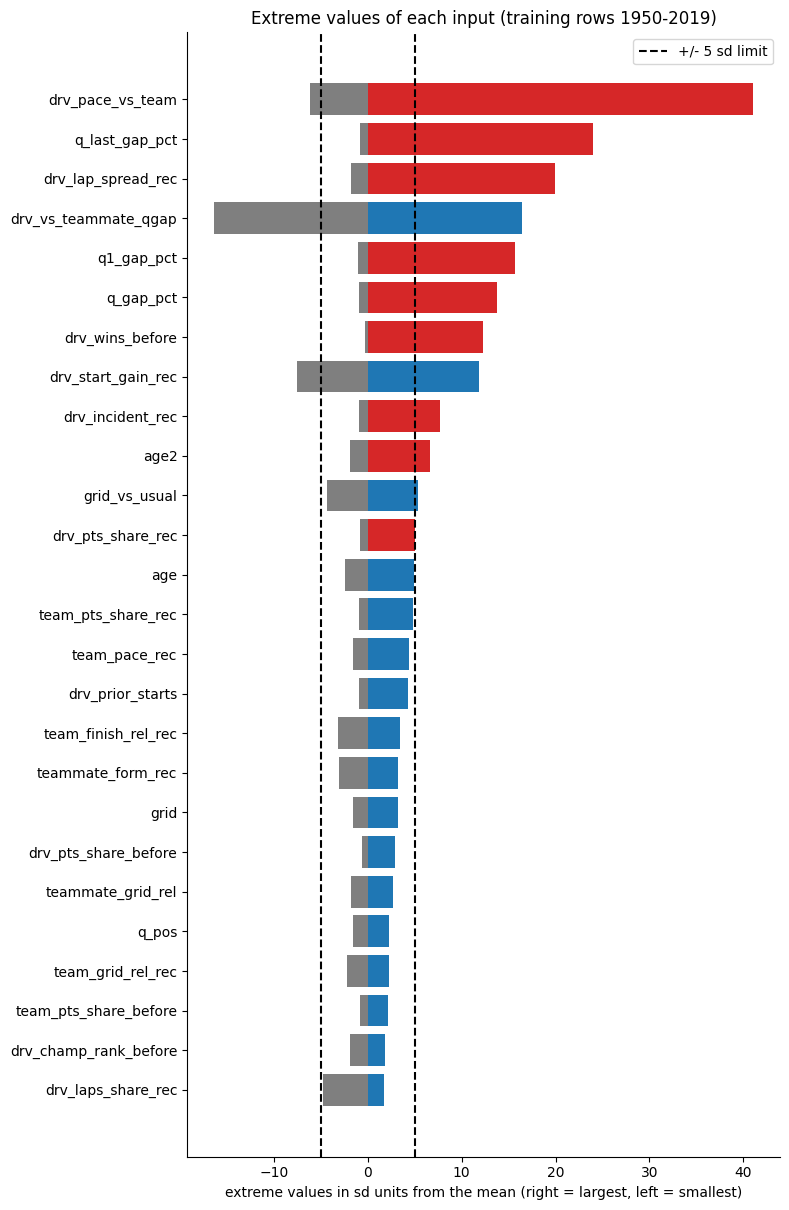

In [49]:
# TAILS: how far do the largest AND the smallest values of every numeric input sit from its mean (in sd units), on training rows?
tail_rows = full[full["year"].between(TRAIN_START, 2019)]
records = []
for c in NUM_COLS:
    s = tail_rows[c].dropna()
    if s.nunique() <= 2:                       # skip 0/1 flags
        continue
    records.append({"feature": c, "skew": s.skew(), "min": s.min(), "1st pct": s.quantile(0.01), "median": s.median(),
                    "99th pct": s.quantile(0.99), "max": s.max(),
                    "min (sd units)": (s.min() - s.mean()) / s.std(), "max (sd units)": (s.max() - s.mean()) / s.std()})
tail_report = pd.DataFrame(records).sort_values("max (sd units)", ascending=False).reset_index(drop=True)

# SCREENING RULE, applied to each side separately: heavy tail = extreme value more than 5 sd from the mean AND clearly skewed to that
# side (|skew| > 1). (Thresholds set after looking at the first version of this table; the real test of clipping is the experiment below.)
SD_LIMIT, SKEW_LIMIT = 5, 1
tail_report["heavy UPPER tail"] = (tail_report["max (sd units)"] > SD_LIMIT) & (tail_report["skew"] > SKEW_LIMIT)
tail_report["heavy LOWER tail"] = (tail_report["min (sd units)"] < -SD_LIMIT) & (tail_report["skew"] < -SKEW_LIMIT)
TAIL_UP = tail_report.loc[tail_report["heavy UPPER tail"], "feature"].tolist()
TAIL_LOW = tail_report.loc[tail_report["heavy LOWER tail"], "feature"].tolist()
display(tail_report.round(2))
print("heavy UPPER tail:", TAIL_UP, "| heavy LOWER tail:", TAIL_LOW)

order_ = tail_report.sort_values("max (sd units)", ascending=False)
y_ = np.arange(len(order_))
plt.figure(figsize=(8, 0.4 * len(order_) + 1.8))
plt.barh(y_, order_["max (sd units)"], color=["tab:red" if f else "tab:blue" for f in order_["heavy UPPER tail"]])
plt.barh(y_, order_["min (sd units)"], color=["tab:orange" if f else "tab:gray" for f in order_["heavy LOWER tail"]])
plt.axvline(SD_LIMIT, color="black", ls="--"); plt.axvline(-SD_LIMIT, color="black", ls="--", label=f"+/- {SD_LIMIT} sd limit")
plt.yticks(y_, order_["feature"]); plt.gca().invert_yaxis()
plt.xlabel("extreme values in sd units from the mean (right = largest, left = smallest)")
plt.title(f"Extreme values of each input (training rows {TRAIN_START}-2019)"); plt.legend()
plt.tight_layout(); plt.show()

**Reading the result.** Nine columns have a heavy upper tail by the rule; none has a heavy lower tail.
* **The most extreme:** `drv_pace_vs_team` (41.0 sd from the mean, skew 10.0), `q_last_gap_pct` (24.0 sd, skew 5.6), `drv_lap_spread_rec` (19.9 sd, skew 3.4), `q1_gap_pct` (15.7 sd, skew 3.4) and `q_gap_pct` (13.7 sd, skew 4.2).
* **Milder:** `drv_wins_before` (12.3 sd, skew 4.9), `drv_incident_rec` (7.7 sd, skew 2.4), `age2` (the square of age, 6.6 sd) and `drv_pts_share_rec` (5.1 sd, skew 1.6).
* In the figure these are the bars that cross the dashed lines at plus or minus 5 sd.
* Eight of the nine are never negative, so `log(1 + x)` can be tried on them; `drv_pace_vs_team` has negative values, so a log does not fit it.
* `drv_vs_teammate_qgap` reaches plus and minus 16.4 sd but is perfectly symmetric (skew 0.00), and `drv_start_gain_rec` reaches -7.5 and +11.8 sd with a skew of only 0.62, so the rule flags neither. The screen cannot see heavy tails that are (nearly) symmetric; we state that.

Whether any of this hurts the predictions is tested in 11.4.

### 11.2 Missing values: how much, where, and why

**Question.** For every model input: how much is missing, **why**, and therefore how should it be filled? The cause decides the fix. **Method.** The share of missing values per feature and era (the eras are the ones fixed in section 9.2), on the final feature list.

In [50]:
era_names = ["1950-57", "1958-65", "1966-76", "1977-88", "1989-94", "1995-2008", "2009-13", "2014+"]
miss = (full[NUM_COLS].isna().groupby(full["era"]).mean() * 100).round(1)
miss.index = [era_names[int(i)] for i in miss.index]
print("% missing, by era (rows = feature, columns = era):")
display(miss.T)
overall = (full[NUM_COLS].isna().mean() * 100).round(1)
print("features with any missing values (% of all rows):")
print(overall[overall > 0].sort_values(ascending=False).to_string())
gap_train = (tail_rows[NUM_COLS].isna().mean() * 100).round(1)
print(f"\nin the training window {TRAIN_START}-2019 only (% of rows):", gap_train[gap_train > 0].sort_values(ascending=False).to_dict())

% missing, by era (rows = feature, columns = era):


,1950-57,1958-65,1966-76,1977-88,1989-94,1995-2008,2009-13,2014+
grid,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
grid_unassigned,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
q_knockout,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
has_quali,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
has_lap_times,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
has_team_standings,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
has_driver_history,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
has_teammate,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
q_pos,100.0,100.0,100.0,100.0,84.4,34.6,0.3,0.3
q_gap_pct,100.0,100.0,100.0,100.0,84.4,36.5,0.9,1.4


features with any missing values (% of all rows):
q_last_gap_pct           68.0
drv_vs_teammate_qgap     58.9
q_gap_pct                58.3
q1_gap_pct               58.3
q_pos                    57.6
drv_pace_vs_team         54.5
drv_lap_spread_rec       54.3
drv_start_gain_rec       54.2
team_pace_rec            54.0
teammate_form_rec         8.0
teammate_grid_rel         6.6
team_pts_share_before     4.7
drv_incident_rec          2.8
drv_laps_share_rec        2.8
drv_pts_share_rec         2.8
grid_vs_usual             2.8
team_pts_share_rec        1.1
team_finish_rel_rec       1.1
team_grid_rel_rec         1.1

in the training window 1950-2019 only (% of rows): {'q_last_gap_pct': 74.3, 'drv_vs_teammate_qgap': 64.3, 'q_gap_pct': 63.7, 'q1_gap_pct': 63.7, 'q_pos': 63.1, 'drv_pace_vs_team': 59.6, 'drv_lap_spread_rec': 59.4, 'drv_start_gain_rec': 59.3, 'team_pace_rec': 59.1, 'teammate_form_rec': 8.6, 'teammate_grid_rel': 7.2, 'team_pts_share_before': 5.2, 'drv_incident_rec': 3.0, 'drv_la

**Reading the result.**
* **Qualifying columns** (`q_pos`, `q_gap_pct`, `q1_gap_pct`, `q_last_gap_pct`, `drv_vs_teammate_qgap`): structural. 100 % missing from 1950 to 1988 and 84-85 % in 1989-94 (qualifying data starts in 1994; `q_last_gap_pct` 100 %, because 1994 qualifying had no knockout parts). In 1995-2008 35-38 % are missing (patchy 1996-2002) and `q_last_gap_pct` 76 % (it does not exist in single-session races, 7.3). From 2009 at most 2.9 %.
* **Race-pace columns** (`team_pace_rec`, `drv_pace_vs_team`, `drv_start_gain_rec`, `drv_lap_spread_rec`, which need lap times): 100 % missing before 1995, 9-11 % in 1995-2008, under 2 % from 2009.
* **`team_pts_share_before`:** missing only in 1950-57 (constructor standings start in 1958).
* **Form and reliability columns:** 5-16 % in 1950-57, under 1 % from 2014 (a driver's or team's first starts have no history).
* **Teammate columns:** 15-18 % in 1966-88 (many teams ran one car), about 1 % or less from 2009.
* **Complete in every era:** `grid`, the seven 0/1 baseline columns, `drv_pts_share_before`, `drv_champ_rank_before`, `drv_wins_before`, `age` and `drv_prior_starts`.

**In the training window (1950-2019)** the qualifying columns are missing in 63-74 % of rows and the race-pace columns in 59-60 %; every other gap is 1.2 % to 8.6 %.

**Fill rules (decided from this evidence):**

| Case | Rule | Why |
|---|---|---|
| Structural gaps: qualifying before 1994 (patchy to 2002), lap times before 1996, constructor standings before 1958 | **Training median, plus the availability flag** (`has_quali`, `has_lap_times`, `has_team_standings`, 9.6b) | There is no source for the values. The filled value is a placeholder; the flag tells the models it carries no information. |
| `q_last_gap_pct` in single-session races (1994-2005) | **Training median, plus the flag `q_knockout`** | The value does not exist in that format (7.3). |
| Small gaps (no time set, first starts, no teammate) | **Training median** (11.3), with `has_driver_history` and `has_teammate` where they apply. An extra "was missing" column per feature is tested in 11.4. | Few rows, and the median is not moved by the tails. |
| Where fills happen | Inside one function, **fitted on the training rows only**. | A median over all years would put validation and test information into every filled cell. The inference function uses the same values. |

### 11.3 Mean or median for the values we fill?

**Question.** Does the choice between mean and median change the values we fill? For every input with gaps in the **training** rows: how many rows get filled, and how far apart are the mean and the median (in standard deviations)? A large gap means the choice matters; a gap near 0 means it does not. The table also shows the skew, because the tails of 11.1 are the reason a mean can be pulled away from the typical value.

In [51]:
# MEAN OR MEDIAN? For every feature that has missing values in the TRAINING rows: how many rows get filled, and how far
# apart are the mean and the median (in standard deviations)? A large gap = the choice changes the filled value.
fill_rows = full[full["year"].between(TRAIN_START, 2019)]
report = []
for c in NUM_COLS:
    s = fill_rows[c]
    n_missing = int(s.isna().sum())
    if n_missing == 0:
        continue
    obs = s.dropna()
    report.append({"feature": c, "rows to fill": n_missing, "% of rows": 100 * n_missing / len(fill_rows),
                   "mean": obs.mean(), "median": obs.median(),
                   "mean - median (sd units)": (obs.mean() - obs.median()) / obs.std(), "skew": obs.skew(),
                   "heavy tail (11.1)": c in TAIL_UP or c in TAIL_LOW})
fill_report = pd.DataFrame(report).sort_values("mean - median (sd units)", key=abs, ascending=False)
display(fill_report.round(3))
print("training rows:", len(fill_rows))

,feature,rows to fill,% of rows,mean,median,mean - median (sd units),skew,heavy tail (11.1)
11,team_pts_share_before,1172,5.185,0.271,0.113,0.476,1.144,False
6,team_pts_share_rec,260,1.150,0.142,0.078,0.407,1.412,False
5,drv_pts_share_rec,677,2.995,0.139,0.070,0.407,1.569,True
3,q_last_gap_pct,16800,74.323,1.064,0.710,0.266,5.565,True
2,q1_gap_pct,14394,63.679,2.024,1.502,0.262,3.380,True
1,q_gap_pct,14394,63.679,2.510,1.966,0.211,4.202,True
18,drv_lap_spread_rec,13420,59.370,0.037,0.034,0.184,3.347,True
15,team_pace_rec,13356,59.087,2.389,2.176,0.144,1.148,False
12,drv_incident_rec,677,2.995,0.114,0.100,0.121,2.398,True
4,team_finish_rel_rec,260,1.150,0.520,0.534,-0.099,-0.217,False


training rows: 22604


**Reading the result.** 19 of the 33 final columns have gaps in training, from 260 to 16,800 rows out of 22,604.
* **Mean and median are at most 0.48 standard deviations apart** (`team_pts_share_before`: mean 0.271, median 0.113). The widest gaps are in right-skewed columns, where a few large values pull the mean up; 7 of the 19 have a heavy tail (11.1). Outliers pull the mean towards them, which is why the median is the better choice.

**Decision: the median, for every column.** It is the typical value, so a filled row looks like a typical row, and one rule is simple to apply in the inference function. For example, the mean of `q_gap_pct` (2.51 %) would put a driver with no time further from pole than the typical driver (1.97 %).

**With the flags, the fill value is only a placeholder.** Most fills are structural (64 % of training rows have no qualifying time). In those rows the filled column is one constant and its flag is 0, so a linear model absorbs the constant into the flag's weight: the flag, not the median, tells the model that the value is missing.

### 11.4 The fill / scale / clip experiments

**Question.** The milestone asks for at least two preprocessing-order experiments. Two choices could plausibly matter:

* **Experiment 1: fill then scale (our standard), or scale then fill?** The filled values land in the same place either way; the only difference is whether the filled rows take part in computing the mean and the spread.
* **Experiment 2: cap the heavy-tailed inputs of 11.1** at the 99th percentile (upper tail) or the 1st percentile (lower tail) of the training rows (winsorizing, a standard outlier treatment: Kuhn & Johnson, 2019), either **before** filling and scaling, **after** scaling, or not at all.

**Two extra checks, labelled as extras** (not order experiments, but the two standard remedies for the problems of 11.1 and 11.2): **`log(1 + x)`** on the flagged right-tailed, non-negative features (it compresses large values smoothly and keeps their order; it cannot be used on negative values), and a **missing-value indicator** (an extra 0/1 column for each feature with gaps; standard advice when missingness may carry information; Kuhn & Johnson, 2019).

**Setup.** Same data and model for every variant (train 1950-2019, validate 2020-21, logistic regression), so only the preprocessing changes. Metric: validation **PR-AUC**, with a paired bootstrap by race for the difference from the standard order. **Rule (fixed before the result):** keep the standard order (fill then scale, no capping, no extras) unless an alternative's improvement has a 95% range entirely above 0.

In [52]:
# EXPERIMENT 1: fill then scale (standard)  vs  scale then fill.   EXPERIMENT 2: cap the heavy-tailed inputs found above at the 99th (upper)
# / 1st (lower) percentile of the TRAINING rows - before filling and scaling, after scaling, or not at all.
# EXTRAS: log(1 + x) on the right-tailed non-negative flagged features, and a missing-value indicator per feature with gaps.
# Same data and model for every variant (the training window, validate 2020-21, logistic regression); metric: validation PR-AUC.
# RULE (fixed before the result): keep the standard order unless an alternative's improvement has a 95% range (paired bootstrap over
# whole races) entirely above 0.
train_pre = full[full["year"].between(TRAIN_START, 2019)]
valid_pre = full[full["year"].between(2020, 2021)].reset_index(drop=True)
cap_hi = {c: train_pre[c].quantile(0.99) for c in TAIL_UP}
cap_lo = {c: train_pre[c].quantile(0.01) for c in TAIL_LOW}
tail_idx = {c: NUM_COLS.index(c) for c in TAIL_UP + TAIL_LOW}
LOG_COLS = [c for c in TAIL_UP if train_pre[c].min() >= 0]          # right-tailed AND non-negative
print("log(1 + x) is applicable to:", LOG_COLS, "| flagged but not applicable (negative values or left tail):", [c for c in TAIL_UP + TAIL_LOW if c not in LOG_COLS])

def clip_raw(d):
    out = d[NUM_COLS].copy()
    for c in TAIL_UP:  out[c] = out[c].clip(upper=cap_hi[c])
    for c in TAIL_LOW: out[c] = out[c].clip(lower=cap_lo[c])
    return out

def log_raw(d):
    out = d[NUM_COLS].copy()
    for c in LOG_COLS: out[c] = np.log1p(out[c].clip(lower=0))      # test rows are clipped at 0 (a log cannot take values below -1)
    return out

GAP_COLS = [c for c in NUM_COLS if train_pre[c].isna().any()]

def build_prep(train, order):
    """Return a function that turns rows into model-ready numbers; every statistic is fitted on `train` only."""
    imp, sc = SimpleImputer(strategy="median"), StandardScaler()
    if order == "fill_then_scale":
        imp.fit(train[NUM_COLS]); sc.fit(imp.transform(train[NUM_COLS]))
        f = lambda d: sc.transform(imp.transform(d[NUM_COLS]))
    elif order == "scale_then_fill":
        sc.fit(train[NUM_COLS]); imp.fit(sc.transform(train[NUM_COLS]))
        f = lambda d: imp.transform(sc.transform(d[NUM_COLS]))
    elif order == "clip_then_fill_then_scale":            # cap in raw units: the spread is computed WITHOUT the extremes
        imp.fit(clip_raw(train)); sc.fit(imp.transform(clip_raw(train)))
        f = lambda d: sc.transform(imp.transform(clip_raw(d)))
    elif order == "fill_then_scale_then_clip":            # cap in scaled units: the spread is computed WITH the extremes
        imp.fit(train[NUM_COLS]); z_train = sc.fit_transform(imp.transform(train[NUM_COLS]))
        zhi = {c: np.percentile(z_train[:, tail_idx[c]], 99) for c in TAIL_UP}
        zlo = {c: np.percentile(z_train[:, tail_idx[c]], 1) for c in TAIL_LOW}
        def f(d):
            z = sc.transform(imp.transform(d[NUM_COLS]))
            for c in TAIL_UP:  z[:, tail_idx[c]] = np.minimum(z[:, tail_idx[c]], zhi[c])
            for c in TAIL_LOW: z[:, tail_idx[c]] = np.maximum(z[:, tail_idx[c]], zlo[c])
            return z
    elif order == "log_then_fill_then_scale":             # EXTRA: log(1 + x) on the right-tailed non-negative features
        imp.fit(log_raw(train)); sc.fit(imp.transform(log_raw(train)))
        f = lambda d: sc.transform(imp.transform(log_raw(d)))
    elif order == "fill_then_scale_with_indicators":      # EXTRA: standard order plus one 0/1 "was missing" column per feature with gaps
        imp.fit(train[NUM_COLS]); sc.fit(imp.transform(train[NUM_COLS]))
        f = lambda d: np.hstack([sc.transform(imp.transform(d[NUM_COLS])), d[GAP_COLS].isna().to_numpy(float)])
    return f

ORDERS = ["fill_then_scale", "scale_then_fill", "clip_then_fill_then_scale", "fill_then_scale_then_clip",
          "log_then_fill_then_scale", "fill_then_scale_with_indicators"]
EXTRAS = ["log_then_fill_then_scale", "fill_then_scale_with_indicators"]
y_pre = valid_pre["podium"].to_numpy()
pred_pre = {}
for o in ORDERS:
    prep_o = build_prep(train_pre, o)
    clf = LogisticRegression(max_iter=3000).fit(prep_o(train_pre), train_pre["podium"], sample_weight=train_weights(train_pre))
    pred_pre[o] = clf.predict_proba(prep_o(valid_pre))[:, 1]

boots_pre = race_bootstrap_indices(valid_pre)
rows = []
for o in ORDERS:
    diffs = [average_precision_score(y_pre[i], pred_pre[o][i]) - average_precision_score(y_pre[i], pred_pre["fill_then_scale"][i]) for i in boots_pre]
    lo, hi = np.percentile(diffs, [2.5, 97.5])
    rows.append((o + (" (extra)" if o in EXTRAS else ""), average_precision_score(y_pre, pred_pre[o]), log_loss(y_pre, pred_pre[o]),
                 average_precision_score(y_pre, pred_pre[o]) - average_precision_score(y_pre, pred_pre["fill_then_scale"]), lo, hi))
order_table = pd.DataFrame(rows, columns=["order", "val PR-AUC", "val log-loss", "vs fill_then_scale", "range low", "range high"]).round(4)
display(order_table)

effect = []
for c in TAIL_UP + TAIL_LOW:
    raw_ = train_pre[c].dropna()
    cap_ = raw_.clip(upper=cap_hi.get(c, np.inf), lower=cap_lo.get(c, -np.inf))
    effect.append({"feature": c, "capped side": "upper" if c in TAIL_UP else "lower", "cap": cap_hi.get(c, cap_lo.get(c)),
                   "max before": raw_.max(), "max after": cap_.max(), "min before": raw_.min(), "min after": cap_.min(),
                   "max in sd units before": (raw_.max() - raw_.mean()) / raw_.std(), "max in sd units after": (cap_.max() - cap_.mean()) / cap_.std(),
                   "share of rows capped": ((raw_ != cap_).mean())})
display(pd.DataFrame(effect).round(3))

for o in ORDERS[1:]:
    r_ = order_table.set_index("order").loc[o + (" (extra)" if o in EXTRAS else "")]
    print(f"{'SWITCH' if r_['range low'] > 0 else 'KEEP the standard order'} | {o}: improvement {r_['vs fill_then_scale']:+.4f} (95% range {r_['range low']:+.4f} to {r_['range high']:+.4f})")

log(1 + x) is applicable to: ['q_last_gap_pct', 'drv_lap_spread_rec', 'q1_gap_pct', 'q_gap_pct', 'drv_wins_before', 'drv_incident_rec', 'age2', 'drv_pts_share_rec'] | flagged but not applicable (negative values or left tail): ['drv_pace_vs_team']


,order,val PR-AUC,val log-loss,vs fill_then_scale,range low,range high
0,fill_then_scale,0.7355,0.2198,0.0000,0.0000,0.0000
1,scale_then_fill,0.7348,0.2197,-0.0007,-0.0038,0.0012
2,clip_then_fill_then_scale,0.7302,0.2203,-0.0053,-0.0135,0.0018
3,fill_then_scale_then_clip,0.7285,0.2207,-0.0070,-0.0160,0.0008
4,log_then_fill_then_scale (extra),0.7299,0.2213,-0.0056,-0.0147,0.0028
5,fill_then_scale_with_indicators (extra),0.7381,0.2178,0.0026,-0.0012,0.0093


,feature,capped side,cap,max before,max after,min before,min after,max in sd units before,max in sd units after,share of rows capped
0,drv_pace_vs_team,upper,2.939,44.280,2.939,-6.690,-6.690,41.048,3.569,0.010
1,q_last_gap_pct,upper,5.294,33.010,5.294,0.000,0.000,23.982,3.947,0.010
2,drv_lap_spread_rec,upper,0.085,0.371,0.085,0.006,0.006,19.939,3.314,0.010
3,q1_gap_pct,upper,8.991,33.285,8.991,0.000,0.000,15.668,3.985,0.010
4,q_gap_pct,upper,11.513,37.797,11.513,0.000,0.000,13.715,4.317,0.010
5,drv_wins_before,upper,5.000,13.000,5.000,0.000,0.000,12.275,5.319,0.010
6,drv_incident_rec,upper,0.500,1.000,0.500,0.000,0.000,7.660,3.706,0.006
7,age2,upper,2036.986,3113.350,2036.986,304.635,304.635,6.585,3.470,0.010
8,drv_pts_share_rec,upper,0.711,1.000,0.711,0.000,0.000,5.073,3.420,0.010


KEEP the standard order | scale_then_fill: improvement -0.0007 (95% range -0.0038 to +0.0012)
KEEP the standard order | clip_then_fill_then_scale: improvement -0.0053 (95% range -0.0135 to +0.0018)
KEEP the standard order | fill_then_scale_then_clip: improvement -0.0070 (95% range -0.0160 to +0.0008)
KEEP the standard order | log_then_fill_then_scale: improvement -0.0056 (95% range -0.0147 to +0.0028)
KEEP the standard order | fill_then_scale_with_indicators: improvement +0.0026 (95% range -0.0012 to +0.0093)


**Reading the result.**

| Variant | Val PR-AUC | vs standard | 95% range | Verdict |
|---|---|---|---|---|
| fill then scale (standard) | 0.7355 | 0 | n/a | |
| scale then fill | 0.7348 | -0.0007 | -0.0038 to +0.0012 | keep standard |
| cap, then fill, then scale | 0.7302 | -0.0053 | -0.0135 to +0.0018 | keep standard |
| fill, scale, then cap | 0.7285 | -0.0070 | -0.0160 to +0.0008 | keep standard |
| `log(1 + x)` on eight columns (extra) | 0.7299 | -0.0056 | -0.0147 to +0.0028 | keep standard |
| missing-value indicators (extra) | 0.7381 | +0.0026 | -0.0012 to +0.0093 | keep standard |

**All five verdicts: keep the standard (median fill, then scale).** No alternative beats it with a range above 0.
* **Experiment 1:** the two orders score almost the same (0.7355 and 0.7348), although about 64 % of the qualifying values are filled. The order changes only whether the filled rows count when the mean and spread are computed, which moves where the filled constant lands on the scaled axis; the flags absorb that constant (11.3).
* **Experiment 2:** capping does what it should to the data (`drv_pace_vs_team` from 41.0 to 3.6 sd, `q_last_gap_pct` from 24.0 to 3.9, `drv_lap_spread_rec` from 19.9 to 3.3, `q_gap_pct` from 13.7 to 4.3) but does not improve validation predictions; both capping orders have the lowest point estimates.
* **Extras:** the log is not better (-0.0056). Per-feature indicators, added on top of the five availability flags, have the best point estimate (+0.0026, log-loss 0.2178 against 0.2198), but the range includes 0, so they are not adopted.

### 11.5 The adopted recipe and its effect on the values

**What we do and why.** The recipe follows the rule of 11.4: the standard (**median fill, then standardise**) unless a variant beat it with a 95% range above 0. The milestone also asks for the effect of the step on the data: mean, standard deviation, minimum, maximum and gaps **before** (raw) and **after** the adopted preprocessing, on the training window, and the same for three features as histograms.

ADOPTED preprocessing: fill_then_scale | rule: an alternative is adopted only if its 95% range is above 0; otherwise the standard stays


,raw mean,raw std,raw min,raw max,raw missing,after mean,after std,after min,after max,after missing
grid,11.940,6.831,1.000,34.000,0,0.0,1.0,-1.602,3.229,0
grid_unassigned,0.002,0.039,0.000,1.000,0,0.0,1.0,-0.039,25.765,0
q_knockout,0.260,0.439,0.000,1.000,0,0.0,1.0,-0.593,1.686,0
has_quali,0.363,0.481,0.000,1.000,0,0.0,1.0,-0.755,1.324,0
has_lap_times,0.409,0.492,0.000,1.000,0,-0.0,1.0,-0.832,1.202,0
has_team_standings,0.948,0.222,0.000,1.000,0,0.0,1.0,-4.276,0.234,0
has_driver_history,0.970,0.170,0.000,1.000,0,-0.0,1.0,-5.691,0.176,0
has_teammate,0.928,0.258,0.000,1.000,0,0.0,1.0,-3.595,0.278,0
q_pos,11.365,6.361,1.000,26.000,14259,-0.0,1.0,-2.620,3.843,0
q_gap_pct,2.510,2.573,0.000,37.797,14394,0.0,1.0,-1.376,22.662,0


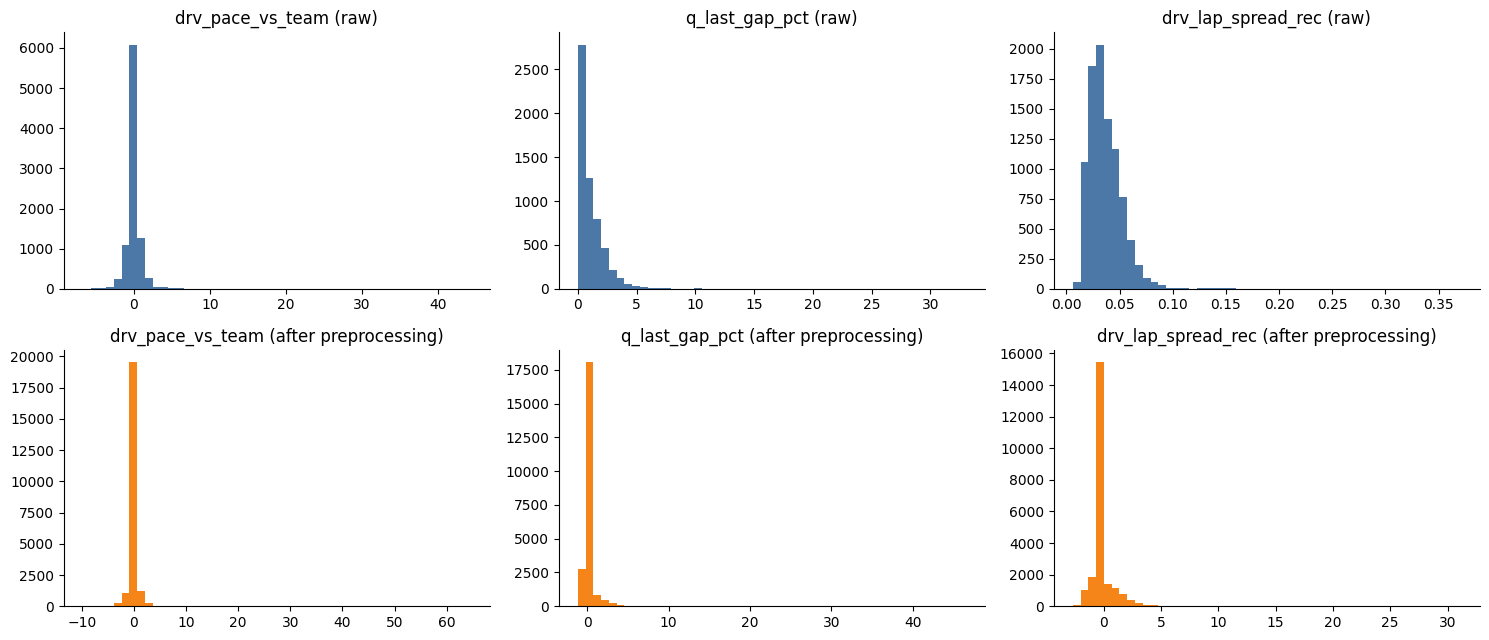

In [53]:
ot = order_table.set_index("order")
winners = ot[(ot.index != "fill_then_scale") & (ot["range low"] > 0)]
ADOPTED = winners["vs fill_then_scale"].idxmax().replace(" (extra)", "") if len(winners) else "fill_then_scale"
print("ADOPTED preprocessing:", ADOPTED, "| rule: an alternative is adopted only if its 95% range is above 0; otherwise the standard stays")
PREP_KW = {"order": ADOPTED, "fill": "median", "log_features": LOG_COLS if ADOPTED == "log_then_fill_then_scale" else [],
           "cap_upper": cap_hi if ADOPTED.startswith("clip") or ADOPTED.endswith("clip") else {}, "cap_lower": cap_lo if ADOPTED.startswith("clip") or ADOPTED.endswith("clip") else {},
           "indicator_columns": GAP_COLS if ADOPTED.endswith("indicators") else []}

prep_final = build_prep(train_pre, ADOPTED)
A_tr = prep_final(train_pre)
names_after = NUM_COLS + ([f"{c}__missing" for c in GAP_COLS] if ADOPTED.endswith("indicators") else [])
after = pd.DataFrame(A_tr, columns=names_after)
eff = pd.DataFrame({"raw mean": train_pre[NUM_COLS].mean(), "raw std": train_pre[NUM_COLS].std(), "raw min": train_pre[NUM_COLS].min(), "raw max": train_pre[NUM_COLS].max(),
                    "raw missing": train_pre[NUM_COLS].isna().sum(), "after mean": after[NUM_COLS].mean().values, "after std": after[NUM_COLS].std().values,
                    "after min": after[NUM_COLS].min().values, "after max": after[NUM_COLS].max().values, "after missing": after[NUM_COLS].isna().sum().values})
display(eff.round(3))
show = (TAIL_UP + TAIL_LOW + [c for c in NUM_COLS if c not in TAIL_UP + TAIL_LOW])[:3]
fig, ax = plt.subplots(2, len(show), figsize=(5 * len(show), 6.5))
ax = np.atleast_2d(ax).reshape(2, len(show))
for j, f in enumerate(show):
    ax[0, j].hist(train_pre[f].dropna(), bins=50, color="#4C78A8"); ax[0, j].set_title(f + " (raw)", fontsize=12)
    ax[1, j].hist(after[f], bins=50, color="#F58518"); ax[1, j].set_title(f + " (after preprocessing)", fontsize=12)
plt.tight_layout(); plt.show()

**Reading the result.** The adopted recipe is the standard one: **median fill, then standardise**, fitted on 1950-2019. Every column now has mean 0, standard deviation 1 and no gaps. The filled rows (for example 16,800 in `q_last_gap_pct`) show in the histograms as a spike at the median.

**Filling makes the tails look longer.** When most rows of a column share one value, its standard deviation shrinks, so the extreme values sit further out after scaling: `q_last_gap_pct` reaches 46.5 sd against 24.0 on the observed values (11.1), `drv_pace_vs_team` 64.6 against 41.0. Trees see only the order, which does not change. For the logistic regression and the network these tails are a stated limitation: capping and `log(1 + x)` did not improve predictions (11.4). `grid_unassigned` reaches 25.8 sd because it is 1 in only 34 training rows.

## 12. The modelling table

**What we do and why.** Assemble the table the models will use: one row per (race, driver), the identifiers, the split, the target and the final features **unprocessed**. The preprocessing is a fitted object applied after the split, so validation and test rows never influence the fitted fill and scale values. The table is saved to a file, and its first rows and one recent race are shown. The last table lists each selected feature with its definition and why it is valid at the pre-race cutoff.

In [54]:
ID_COLS = ["raceId", "driverId", "constructorId", "year", "race_order", "split", "dedup_ambiguous"]
model_table = full[ID_COLS + ["podium"] + FE].copy()
model_table["podium"] = model_table["podium"].astype(int)
assert not model_table.duplicated(["raceId", "driverId"]).any()
model_table.to_csv("f1_modeling_table.csv", index=False)
import json
json.dump({"final_units": FINAL_UNITS, "features": FE, "preprocessing": {k: (list(v) if isinstance(v, tuple) else v) for k, v in PREP_KW.items()},
           "training_window": [TRAIN_START, 2019], "half_life": HALF_LIFE, "validation_years": [2020, 2021], "test_from": 2022}, open("final_feature_list.json", "w"), indent=1)

summary = model_table.assign(modelling_window=model_table["year"] >= TRAIN_START).groupby("split").agg(rows=("podium", "size"), races=("raceId", "nunique"), podium_rate=("podium", "mean"))
display(summary.round(3))
print("features:", len(FE), "| table saved to f1_modeling_table.csv and final_feature_list.json")

# what the table looks like: its first rows (1950: older sources missing, marked by the flags) and one recent race
show_cols = ["raceId", "driverId", "year", "split", "dedup_ambiguous", "podium", "grid", "q_pos", "q_gap_pct",
             "team_pts_share_rec", "drv_pts_share_rec", "drv_pts_share_before", "has_quali", "has_lap_times", "has_driver_history"]
print("\nFirst rows of the table (1950):")
display(model_table[show_cols].head(5).round(3))
first_2023 = model_table.loc[model_table["year"] == 2023, "race_order"].min()
print("One recent race (first race of 2023), top five on the grid:")
display(model_table.loc[model_table["race_order"] == first_2023, show_cols].sort_values("grid").head(5).round(3))
valid = REGISTRY[REGISTRY["unit"].isin(FINAL_UNITS)][["unit", "concept", "definition", "valid_before_race"]].set_index("unit")
with pd.option_context("display.max_colwidth", 120):
    display(valid)

,rows,races,podium_rate
split,,,
test,1356,68,0.150
train,22604,1007,0.134
validation,779,39,0.150


features: 33 | table saved to f1_modeling_table.csv and final_feature_list.json

First rows of the table (1950):


,raceId,driverId,year,split,dedup_ambiguous,podium,grid,q_pos,q_gap_pct,team_pts_share_rec,drv_pts_share_rec,drv_pts_share_before,has_quali,has_lap_times,has_driver_history
0,833,579,1950,train,False,0,3,NaN,NaN,NaN,NaN,0.0,0,0,0
1,833,589,1950,train,False,0,11,NaN,NaN,NaN,NaN,0.0,0,0,0
2,833,619,1950,train,False,0,13,NaN,NaN,NaN,NaN,0.0,0,0,0
3,833,627,1950,train,False,0,9,NaN,NaN,NaN,NaN,0.0,0,0,0
4,833,640,1950,train,False,0,8,NaN,NaN,NaN,NaN,0.0,0,0,0


One recent race (first race of 2023), top five on the grid:


,raceId,driverId,year,split,dedup_ambiguous,podium,grid,q_pos,q_gap_pct,team_pts_share_rec,drv_pts_share_rec,drv_pts_share_before,has_quali,has_lap_times,has_driver_history
23828,1098,830,2023,test,False,1,1,1.0,0.000,0.680,0.807,0.0,1,1,1
23825,1098,815,2023,test,False,1,2,2.0,0.154,0.680,0.552,0.0,1,1,1
23833,1098,844,2023,test,False,0,3,3.0,0.326,0.436,0.485,0.0,1,1,1
23829,1098,832,2023,test,False,0,4,4.0,0.497,0.436,0.386,0.0,1,1,1
23823,1098,4,2023,test,False,1,5,5.0,0.700,0.055,0.156,0.0,1,1,1


,concept,definition,valid_before_race
unit,,,
q_pos,Qualifying,position in qualifying,Qualifying ends before the race.
q_gap_pct,Qualifying,best qualifying time as % slower than pole,Qualifying ends before the race.
q1_gap_pct,Qualifying,Q1 time as % slower than the fastest Q1 time,Qualifying ends before the race.
q_last_gap_pct,Qualifying,gap to the fastest time of the last qualifying part the driver took part in; missing in single-session races (7.3),Qualifying ends before the race.
team_finish_rel_rec,Team form,"team's average finishing place / field size, last W races","Uses only races before this one (shifted, leak-tested)."
drv_pts_share_rec,Driver form,"driver's points as a share of the winner's points, last W races",Uses only earlier races.
team_pts_share_rec,Team form,"team's cars' points as a share of the winner's points, last W races",Uses only earlier races.
drv_laps_share_rec,Driver form,"laps completed / winner's laps, last W races",Uses only earlier races.
teammate_grid_rel,Teammate,"teammate's grid slot / field size, this weekend",The grid is fixed before the start.


**Reading the result.** One row per (race, driver) with the identifiers, the split, the target and **33 unprocessed feature columns**: the 8 baseline columns (`grid`, `grid_unassigned`, `q_knockout` and the five availability flags), the 24 selected units and the square of `age`. It is saved as `f1_modeling_table.csv` together with `final_feature_list.json` (features, adopted preprocessing, split years, season weights). Train has 22,604 rows in 1,007 races (podium rate 13.4 %; all are used, 8.2), validation 779 rows in 39 races (15.0 %) and test 1,356 rows in 68 races (15.0 %). The last table gives each feature's definition and why it is valid before the race. The sample rows show what *unprocessed* means: in 1950 the qualifying and lap-time columns are empty and `has_quali` and `has_lap_times` are 0, while in 2023 every source exists; the gaps are filled only later, by the preprocessing fitted on the training seasons.

## 13. The three data-engineering questions

The brief asks three questions. Each needs a chain of joins and is answered with a table, a figure and a short note on the **grain** (what one row is), the **missingness** (what is absent and what we did) and the **pre-race cutoff** (could the quantity be a feature?). All three are **descriptive**: they use every season, including the validation and test years, because they describe what happened. **No feature, window or model decision depends on them**, so nothing from the test years leaks into the models.

The table used throughout is the cleaned table of sections 5-6 (one row per race and driver, `full`), joined again to the raw tables where a question needs more. Every join states `validate=` and is followed by a row-count check, so the grain stays one row per (race, driver).

### 13.1 Which circuits convert a front-row start into a podium, and does the ranking change after 2014?

**Question.** For each circuit: of the drivers who start from the front row (slot 1 or 2), what share finish on the podium? Is the ranking of circuits different in the hybrid era (2014 onwards) than before?

**Joins.** `results` (the cleaned rows: grid, target) → `races` (which circuit, which year) → `circuits` (name) and `results` → `qualifying` (qualifying position, already joined in section 7). Four tables.

**Qualifying position or grid?** They are different things: the grid is the qualifying order *after penalties and pit-lane starts*. We compute the conversion twice: **front row by qualifying** (`q_pos` 1 or 2) and **front row by grid** (`grid` 1 or 2). The comparison shows how much the penalties change the answer.

**Choices, and why.** (1) Seasons 2003-2024. This is a choice for this question, not the training window of the models (8.2), and the check below backs it: the question compares the hybrid era with the era just before it, so both sides should be equally long and comparable. Using every season before 2014 would mix in decades in which a front-row start meant much less and most circuits were different, so the comparison would measure decades of change rather than the hybrid era. Qualifying data is also complete only from 2003 (section 7.1), so both definitions use the same rows. (2) Two eras: **2003-2013** and **2014-2024** (the hybrid power units start in 2014). (3) **Part A** ranks circuits over all seasons, with at least **20 front-row starts** (about 10 races); **Part B** compares the two eras and needs at least **10 front-row starts in each era** (about 5 races), a low bar chosen because a stricter one leaves too few circuits (with 20 per era only five circuits remain), so the intervals there are wide and say so. Every rate carries a 95% Wilson interval (the standard interval for a proportion, better than the normal one when the rate is near 0 or 1). (4) Ranking agreement is measured with the Spearman rank correlation, and the overall change between eras with Fisher's exact test.

In [55]:
# WHY 2003-2024 FOR THIS QUESTION? Does a front-row start mean the same thing in every era? The grid exists in every season,
# so the conversion by decade can be measured on all of them; and are the circuits of older decades still raced today?
front = clean[clean["grid"].isin([1, 2])]
by_decade = front.groupby(front["year"] // 10 * 10)["podium"].agg(front_row_starts="size", podium_rate="mean")
by_decade.index = [f"{d}s" for d in by_decade.index]
display(by_decade.round(3))
recent = set(T["races"].loc[T["races"]["year"].between(2003, 2024), "circuitId"])
still = {f"{d}s": round(float(T["races"].loc[T["races"]["year"].between(d, d + 9), "circuitId"].drop_duplicates().isin(recent).mean()), 2)
         for d in (1950, 1960, 1970, 1980, 1990)}
print("share of each decade's circuits that are also raced in 2003-2024:", still)


,front_row_starts,podium_rate
1950s,149,0.611
1960s,199,0.467
1970s,288,0.497
1980s,312,0.458
1990s,324,0.605
2000s,348,0.658
2010s,395,0.742
2020s,213,0.751


share of each decade's circuits that are also raced in 2003-2024: {'1950s': 0.37, '1960s': 0.32, '1970s': 0.46, '1980s': 0.48, '1990s': 0.69}


**Reading the result.** A front-row start does not mean the same thing in every era: it led to a podium 46-50 % of the time in the 1960s-1980s, 61 % in the 1990s, 66 % in the 2000s and 74-75 % from the 2010s. And most older circuits are no longer raced: only 32-48 % of the circuits of the 1950s-1980s also appear in 2003-2024 (69 % of the 1990s). A "before 2014" group starting in 1950 would therefore be dominated by a different sport on different tracks, and any difference from the hybrid era would mostly be that drift. Two blocks of 11 seasons, 2003-2013 and 2014-2024, compare like with like.

rows 2003-2024: 8957 | rows with a qualifying position: 8935 | circuits: 38
front row by qualifying: 855 | by grid: 854 | in both: 818 | qualified front row but not on the grid front row: 37 | on the grid front row but not by qualifying: 36

Share of front-row starters who finish on the podium, all circuits:


,front row by qualifying,front row by grid
era,,
2003-2013,0.672,0.68
2014-2024,0.738,0.76


front_row_by_qualifying: 2003-2013 269/400, 2014-2024 336/455, Fisher exact p = 0.035
front_row_by_grid: 2003-2013 272/400, 2014-2024 345/454, Fisher exact p = 0.011

PART A, all seasons 2003-2024: 18 circuits with at least 20 front-row starts


,front-row starts,podiums,rate,low,high,rate (grid),rank (qualifying),rank (grid)
name,,,,,,,,
Suzuka Circuit,36,29,0.81,0.65,0.90,0.81,1.0,3.0
Circuit of the Americas,24,19,0.79,0.60,0.91,0.83,2.0,1.0
Circuit de Spa-Francorchamps,40,31,0.78,0.62,0.88,0.78,3.0,5.0
Circuit de Monaco,42,32,0.76,0.61,0.87,0.81,4.0,2.0
Silverstone Circuit,46,35,0.76,0.62,0.86,0.74,5.0,9.0
Yas Marina Circuit,32,24,0.75,0.58,0.87,0.78,6.0,4.0
Shanghai International Circuit,34,25,0.74,0.57,0.85,0.71,7.0,10.0
Autodromo Nazionale di Monza,44,32,0.73,0.58,0.84,0.75,8.0,6.0
Circuit de Barcelona-Catalunya,44,32,0.73,0.58,0.84,0.75,8.0,6.0


Spearman correlation between the qualifying ranking and the grid ranking: 0.89

PART B: circuits with at least 10 front-row starts in BOTH eras: by qualifying 14, by grid 14


,rate 2003-2013,rate 2014-2024,starts 2003-2013,starts 2014-2024,rank 2003-2013,rank 2014-2024
name,,,,,,
Suzuka Circuit,0.72,0.89,18.0,18.0,3.0,1.0
Circuit de Monaco,0.68,0.85,22.0,20.0,6.0,2.0
Circuit de Spa-Francorchamps,0.72,0.82,18.0,22.0,3.0,3.0
Yas Marina Circuit,0.60,0.82,10.0,22.0,9.0,3.0
Circuit de Barcelona-Catalunya,0.64,0.82,22.0,22.0,8.0,3.0
Shanghai International Circuit,0.70,0.79,20.0,14.0,5.0,6.0
Silverstone Circuit,0.77,0.75,22.0,24.0,1.0,7.0
Autodromo Nazionale di Monza,0.73,0.73,22.0,22.0,2.0,8.0
Circuit Gilles Villeneuve,0.60,0.72,20.0,18.0,9.0,9.0


Spearman correlation of the circuit ranking between eras: by qualifying 0.55 (p = 0.042), by grid 0.30 (p = 0.292)
biggest rank gains in the hybrid era: {'Circuit de Barcelona-Catalunya': 5.0, 'Marina Bay Street Circuit': 5.0, 'Yas Marina Circuit': 6.0} | biggest losses: {'Silverstone Circuit': -6.0, 'Autodromo Nazionale di Monza': -6.0, 'Bahrain International Circuit': -6.0}
circuits whose two 95% intervals do not overlap: none


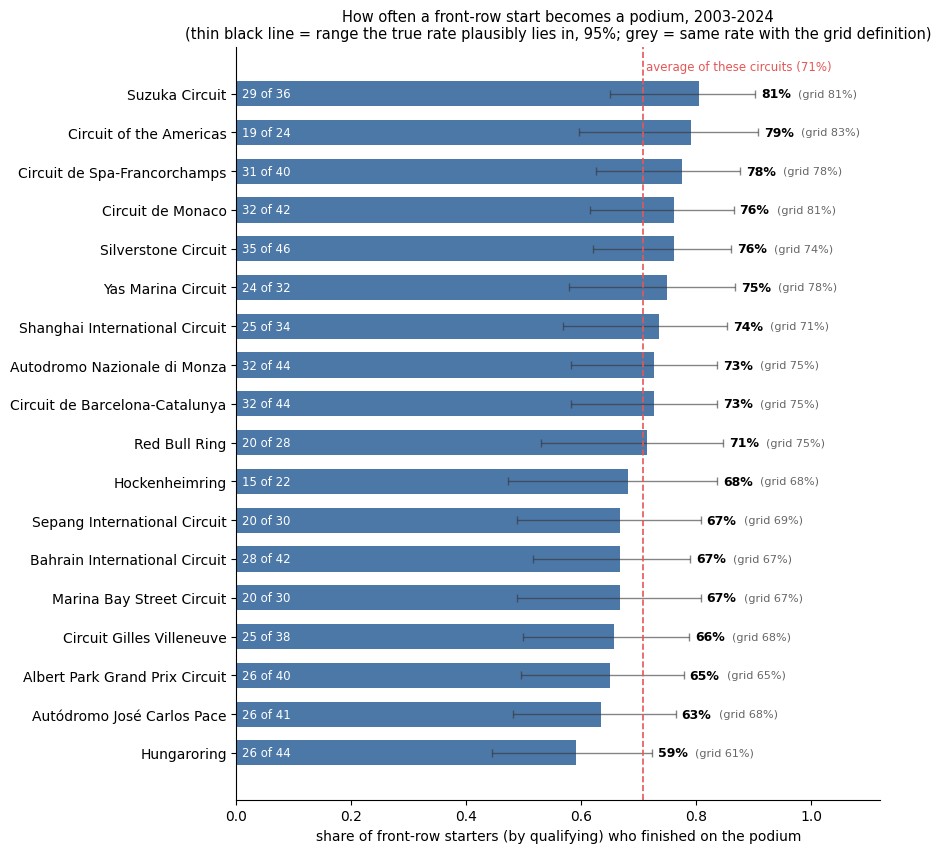

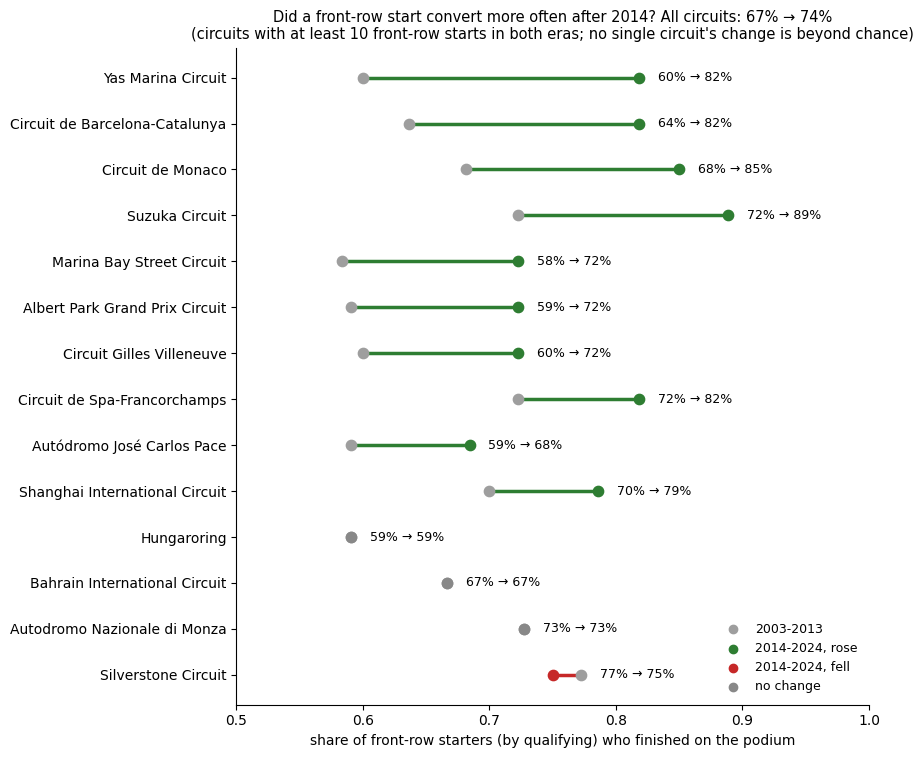

In [56]:
from statsmodels.stats.proportion import proportion_confint
from scipy.stats import fisher_exact

def wilson(k, n):
    lo, hi = proportion_confint(k, n, alpha=0.05, method="wilson")
    return lo, hi

# joins: cleaned (race, driver) rows -> races (circuit, year) -> circuits (name, country); qualifying position came in through section 7
q1 = (full[["raceId", "driverId", "year", "grid", "q_pos", "podium"]]
      .merge(T["races"][["raceId", "circuitId"]], on="raceId", how="left", validate="many_to_one")
      .merge(T["circuits"][["circuitId", "name", "country"]], on="circuitId", how="left", validate="many_to_one"))
assert len(q1) == len(full) and not q1.duplicated(["raceId", "driverId"]).any()
q1 = q1[q1["year"] >= 2003].copy()
q1["era"] = np.where(q1["year"] <= 2013, "2003-2013", "2014-2024")
q1["podium"] = q1["podium"].astype(int)
print("rows 2003-2024:", len(q1), "| rows with a qualifying position:", int(q1["q_pos"].notna().sum()), "| circuits:", q1["circuitId"].nunique())

# how often do the two definitions disagree?
fr_q, fr_g = q1["q_pos"].le(2), q1["grid"].le(2)
print("front row by qualifying:", int(fr_q.sum()), "| by grid:", int(fr_g.sum()), "| in both:", int((fr_q & fr_g).sum()),
      "| qualified front row but not on the grid front row:", int((fr_q & ~fr_g).sum()), "| on the grid front row but not by qualifying:", int((~fr_q & fr_g).sum()))

def conversion(df, flag, by, min_n):
    d = df[df[flag]]
    t = d.groupby(by)["podium"].agg(["size", "sum"]).rename(columns={"size": "front-row starts", "sum": "podiums"}).reset_index()
    t["rate"] = t["podiums"] / t["front-row starts"]
    t[["low", "high"]] = [wilson(k, n) for k, n in zip(t["podiums"], t["front-row starts"])]
    return t[t["front-row starts"] >= min_n]

q1["front_row_by_qualifying"] = q1["q_pos"].le(2)
q1["front_row_by_grid"] = q1["grid"].le(2)

# overall effect of the era, with a test: did front-row starters convert more often after 2014?
overall = pd.DataFrame({"front row by qualifying": q1[q1["front_row_by_qualifying"]].groupby("era")["podium"].mean(),
                        "front row by grid": q1[q1["front_row_by_grid"]].groupby("era")["podium"].mean()})
print("\nShare of front-row starters who finish on the podium, all circuits:"); display(overall.round(3))
for flag in ("front_row_by_qualifying", "front_row_by_grid"):
    tt = q1[q1[flag]].groupby("era")["podium"].agg(["sum", "size"])
    p_era = fisher_exact([[tt.loc["2003-2013", "sum"], tt.loc["2003-2013", "size"] - tt.loc["2003-2013", "sum"]],
                          [tt.loc["2014-2024", "sum"], tt.loc["2014-2024", "size"] - tt.loc["2014-2024", "sum"]]])[1]
    print(f"{flag}: 2003-2013 {tt.loc['2003-2013', 'sum']}/{tt.loc['2003-2013', 'size']}, 2014-2024 {tt.loc['2014-2024', 'sum']}/{tt.loc['2014-2024', 'size']}, Fisher exact p = {p_era:.3f}")

# PART A: ranking of circuits over all seasons 2003-2024 (at least 20 front-row starts, about 10 races)
rank_q = conversion(q1, "front_row_by_qualifying", "name", 20).set_index("name")
rank_g = conversion(q1, "front_row_by_grid", "name", 20).set_index("name")
rank = rank_q[["front-row starts", "podiums", "rate", "low", "high"]].join(rank_g[["rate"]].rename(columns={"rate": "rate (grid)"}), how="left").sort_values("rate", ascending=False)
rank["rank (qualifying)"] = rank["rate"].rank(ascending=False, method="min")
rank["rank (grid)"] = rank["rate (grid)"].rank(ascending=False, method="min")
print(f"\nPART A, all seasons 2003-2024: {len(rank)} circuits with at least 20 front-row starts")
display(rank.round(2))
print("Spearman correlation between the qualifying ranking and the grid ranking:", round(spearmanr(rank["rate"], rank["rate (grid)"], nan_policy="omit").correlation, 2))

# PART B: the two eras separately (at least 10 front-row starts per era, about 5 races: a low bar, so the intervals are wide)
def era_table(flag, min_n=10):
    conv = conversion(q1, flag, ["name", "era"], min_n)
    w = conv.pivot(index="name", columns="era", values="rate"); n = conv.pivot(index="name", columns="era", values="front-row starts")
    lo = conv.pivot(index="name", columns="era", values="low"); hi = conv.pivot(index="name", columns="era", values="high")
    both = w.dropna()
    out = both.copy(); out.columns = [f"rate {c}" for c in out.columns]
    out["starts 2003-2013"], out["starts 2014-2024"] = n.loc[both.index, "2003-2013"], n.loc[both.index, "2014-2024"]
    out["rank 2003-2013"] = both["2003-2013"].rank(ascending=False, method="min")
    out["rank 2014-2024"] = both["2014-2024"].rank(ascending=False, method="min")
    for e in ("2003-2013", "2014-2024"):
        out[f"low {e}"], out[f"high {e}"] = lo.loc[both.index, e], hi.loc[both.index, e]
    return out.sort_values("rate 2014-2024", ascending=False)

tab_q, tab_g = era_table("front_row_by_qualifying"), era_table("front_row_by_grid")
print(f"\nPART B: circuits with at least 10 front-row starts in BOTH eras: by qualifying {len(tab_q)}, by grid {len(tab_g)}")
display(tab_q[["rate 2003-2013", "rate 2014-2024", "starts 2003-2013", "starts 2014-2024", "rank 2003-2013", "rank 2014-2024"]].round(2))
rho_q = spearmanr(tab_q["rate 2003-2013"], tab_q["rate 2014-2024"])
rho_g = spearmanr(tab_g["rate 2003-2013"], tab_g["rate 2014-2024"])
print(f"Spearman correlation of the circuit ranking between eras: by qualifying {rho_q.correlation:.2f} (p = {rho_q.pvalue:.3f}), by grid {rho_g.correlation:.2f} (p = {rho_g.pvalue:.3f})")
move = (tab_q["rank 2003-2013"] - tab_q["rank 2014-2024"]).sort_values()
print("biggest rank gains in the hybrid era:", move.tail(3).to_dict(), "| biggest losses:", move.head(3).to_dict())
sig = [(n_, round(r["rate 2014-2024"] - r["rate 2003-2013"], 2)) for n_, r in tab_q.iterrows() if r["low 2014-2024"] > r["high 2003-2013"] or r["high 2014-2024"] < r["low 2003-2013"]]
print("circuits whose two 95% intervals do not overlap:", sig or "none")

# figure 1: ranking over all seasons. Bar = share of front-row starters (by qualifying) who reached the podium;
# thin black line = 95% Wilson interval; the grid-based rate is printed beside each bar.
fig, ax = plt.subplots(figsize=(9, 0.38 * len(rank) + 1.8))
r1 = rank.iloc[::-1]
yy = np.arange(len(r1))
ax.barh(yy, r1["rate"], color="#4C78A8", height=0.65)
ax.errorbar(r1["rate"], yy, xerr=[r1["rate"] - r1["low"], r1["high"] - r1["rate"]], fmt="none", ecolor="#333333", lw=1, capsize=3, alpha=0.6)
for y_, (nm, r) in zip(yy, r1.iterrows()):
    ax.text(0.01, y_, f"{int(r['podiums'])} of {int(r['front-row starts'])}", va="center", color="white", fontsize=8.5)
    ax.text(r["high"] + 0.01, y_, f"{r['rate']:.0%}", va="center", fontsize=9, fontweight="bold")
    ax.text(r["high"] + 0.075, y_, f"(grid {r['rate (grid)']:.0%})", va="center", fontsize=8, color="#666666")
avg = rank["podiums"].sum() / rank["front-row starts"].sum()
ax.axvline(avg, color="#E45756", ls="--", lw=1.2)
ax.text(avg + 0.005, len(r1) - 0.4, f"average of these circuits ({avg:.0%})", color="#E45756", fontsize=8.5)
ax.set_yticks(yy); ax.set_yticklabels(r1.index); ax.set_xlim(0, 1.12)
ax.set_xlabel("share of front-row starters (by qualifying) who finished on the podium")
ax.set_title("How often a front-row start becomes a podium, 2003-2024\n(thin black line = range the true rate plausibly lies in, 95%; grey = same rate with the grid definition)", fontsize=10.5)
for s in ("top", "right"): ax.spines[s].set_visible(False)
plt.tight_layout(); plt.show()

# figure 2: before -> after 2014, one line per circuit, sorted by the size of the change
ch = tab_q.assign(change=tab_q["rate 2014-2024"] - tab_q["rate 2003-2013"]).sort_values("change")
fig, ax = plt.subplots(figsize=(9, 0.42 * len(ch) + 1.8))
for i, (nm, r) in enumerate(ch.iterrows()):
    a, b = r["rate 2003-2013"], r["rate 2014-2024"]
    c = "#2E7D32" if b > a + 0.005 else ("#C62828" if b < a - 0.005 else "#888888")
    ax.plot([a, b], [i, i], color=c, lw=2.5, zorder=1)
    ax.scatter([a], [i], color="#9E9E9E", s=55, zorder=2); ax.scatter([b], [i], color=c, s=55, zorder=2)
    ax.text(max(a, b) + 0.015, i, f"{a:.0%} → {b:.0%}", va="center", fontsize=9)
ax.set_yticks(range(len(ch))); ax.set_yticklabels(ch.index); ax.set_xlim(0.5, 1.0)
ax.scatter([], [], color="#9E9E9E", label="2003-2013"); ax.scatter([], [], color="#2E7D32", label="2014-2024, rose")
ax.scatter([], [], color="#C62828", label="2014-2024, fell"); ax.scatter([], [], color="#888888", label="no change")
ax.legend(loc="lower right", frameon=False, fontsize=9)
ax.set_xlabel("share of front-row starters (by qualifying) who finished on the podium")
all_rate = q1[q1["front_row_by_qualifying"]].groupby("era")["podium"].mean()
ax.set_title(f"Did a front-row start convert more often after 2014? All circuits: {all_rate['2003-2013']:.0%} → {all_rate['2014-2024']:.0%}\n"
             f"(circuits with at least 10 front-row starts in both eras; no single circuit's change is beyond chance)", fontsize=10.5)
for s in ("top", "right"): ax.spines[s].set_visible(False)
plt.tight_layout(); plt.show()


**Reading the result.**

**Which circuits convert best (2003-2024).** **Suzuka (81 %, 29 podiums from 36 front-row starts), Circuit of the Americas (79 %, only 24 starts), Spa (78 %), Monaco and Silverstone (76 % each)** convert a front-row start into a podium most often; **the Hungaroring (59 %), Interlagos (63 %), Albert Park (65 %) and Montreal (66 %)** least often. The intervals are wide (Suzuka 65-90 %, Hungaroring 44-72 %) and the two extremes overlap, so the order is a tendency, not a proven ranking. The grid-based ranking agrees closely with the qualifying-based one (Spearman 0.89; the grey labels in the first plot). The two definitions differ for 73 starters (37 qualified on the front row but started behind it, 36 reached the front row through others' penalties), and a few circuits move several places (Silverstone is 5th by qualifying and 9th by grid).

**Does the ranking change after 2014?** Front-row starters finished on the podium **67.2 % of the time in 2003-2013 and 73.8 % in 2014-2024** (by qualifying: 269 of 400 against 336 of 455, p = 0.035; by grid 68.0 % against 76.0 %, p = 0.011), so the front row became more valuable overall. Among the 14 circuits with enough starts in both eras, 10 have a higher rate in the hybrid era, 3 are unchanged (Monza, Bahrain, Hungaroring) and 1 is slightly lower (Silverstone, 77 % to 75 %). The *ranking* changes only moderately (Spearman 0.55, p = 0.042, by qualifying; 0.30, p = 0.29, by grid): Yas Marina, Barcelona and Marina Bay climb five or six places, while Silverstone, Monza and Bahrain drop six places **without their own rate changing**, because the circuits around them rose past them. No circuit's two intervals are separated, so we cannot name one circuit whose conversion truly changed; the data supports a general rise. Why it rose is not tested here.

**Grain.** One row is one driver in one race. Front-row starters are the rows with slot 1 or 2 (about two per race), and a circuit's rate pools all its races. **Missingness.** 22 of 8,957 rows since 2003 (0.2 %) have no qualifying position; they cannot be front row by qualifying and are left out of that definition. The grid exists for every row. Seasons before 2003 are not used (incomplete qualifying, section 7.1). **Pre-race cutoff.** Qualifying position and grid are known before the race and the podium is the outcome; these rates are post-race summaries over all seasons and are not used as features.

### 13.2 Do drivers podium more often at home, after controlling for starting position?

**Question.** Is the podium rate of a driver higher at a circuit in his home country than elsewhere, when we compare drivers who start from similar grid positions (so the answer is not just "home drivers qualify better")?

**Joins.** `results` (cleaned rows) → `drivers` (nationality) and `results` → `races` → `circuits` (country). A driver is at home when his nationality maps to the circuit's country (the mapping `HOME` of section 9.2 handles forms such as "British" = UK and dual nationalities). The flag is rebuilt here from the raw tables as a check against the one used in section 9.

**Control, and why.** The brief asks for the grid position as the control. Two complementary views: (1) **stratify**: compare home and away starters inside the same grid band (1, 2, 3, 4-6, 7-10, 11-15, 16+); (2) **model**: a logistic regression `podium ~ home + grid band`, reported as an odds ratio for home with a 95% interval (standard errors clustered by driver, because the same driver appears in many rows) and a likelihood-ratio test of adding the home flag. A third model adds the decade, to rule out that home races are more frequent in decades where podiums are easier to predict. **Grid** (after penalties) is the right control, because it is the position the driver actually starts from.

rows: 24739 | home starts: 1943 (7.9%) | drivers who ever raced at home: 503


,home starts,home podium rate,away starts,away podium rate,home - away
grid band,,,,,
1,83,0.627,1033,0.650,-0.023
2,78,0.564,1034,0.562,0.002
3,70,0.529,1045,0.458,0.070
4-6,227,0.269,3115,0.260,0.008
7-10,337,0.071,4117,0.092,-0.021
11-15,415,0.024,5125,0.030,-0.006
16+,733,0.003,7327,0.007,-0.005


raw podium rate: home 0.118, away 0.137 (not controlled for grid) | mean grid slot: home 12.7, away 11.7


,odds ratio for home,95% low,95% high,p (clustered)
model,,,,
home only (no control),0.844,0.710,1.003,0.054
home + grid band,0.948,0.782,1.150,0.587
home + grid band + decade,0.935,0.765,1.143,0.513


likelihood-ratio test of the home flag, given the grid band: chi2 = 0.38, p = 0.539


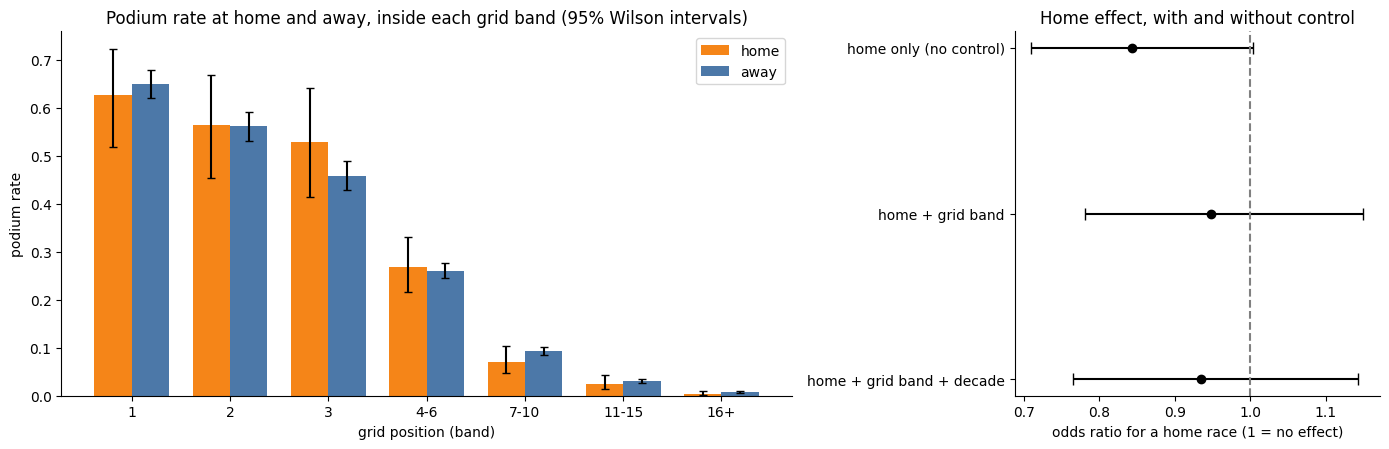

In [57]:
import statsmodels.formula.api as smf

q2 = (full[["raceId", "driverId", "constructorId", "year", "grid", "podium", "is_home"]]
      .merge(T["drivers"][["driverId", "nationality"]], on="driverId", how="left", validate="many_to_one")
      .merge(T["races"][["raceId", "circuitId"]], on="raceId", how="left", validate="many_to_one")
      .merge(T["circuits"][["circuitId", "country"]], on="circuitId", how="left", validate="many_to_one"))
assert len(q2) == len(full)
nat2 = q2["nationality"].str.strip().replace({"Argentinian": "Argentine"})
q2["home"] = [int(c in HOME.get(n, set())) for n, c in zip(nat2, q2["country"])]
assert (q2["home"].to_numpy() == q2["is_home"].to_numpy()).all()
q2["podium"] = q2["podium"].astype(int)
q2["band"] = pd.cut(q2["grid"], [0, 1, 2, 3, 6, 10, 15, 100], labels=["1", "2", "3", "4-6", "7-10", "11-15", "16+"])
q2["decade"] = (q2["year"] // 10 * 10).astype(str)
print("rows:", len(q2), "| home starts:", int(q2["home"].sum()), f"({q2['home'].mean():.1%})", "| drivers who ever raced at home:", q2.loc[q2["home"] == 1, "driverId"].nunique())

rows = []
for b, g in q2.groupby("band", observed=True):
    h, a = g[g["home"] == 1], g[g["home"] == 0]
    rows.append({"grid band": b, "home starts": len(h), "home podium rate": h["podium"].mean() if len(h) else np.nan,
                 "away starts": len(a), "away podium rate": a["podium"].mean(), "home - away": h["podium"].mean() - a["podium"].mean() if len(h) else np.nan})
strat = pd.DataFrame(rows).set_index("grid band")
display(strat.round(3))
pooled_h, pooled_a = q2[q2["home"] == 1]["podium"].mean(), q2[q2["home"] == 0]["podium"].mean()
print(f"raw podium rate: home {pooled_h:.3f}, away {pooled_a:.3f} (not controlled for grid) | mean grid slot: home {q2.loc[q2['home'] == 1, 'grid'].mean():.1f}, away {q2.loc[q2['home'] == 0, 'grid'].mean():.1f}")

m0 = smf.logit("podium ~ home", q2).fit(disp=0)
m1 = smf.logit("podium ~ home + band", q2).fit(disp=0)
m2 = smf.logit("podium ~ home + band + decade", q2).fit(disp=0)
m1c = smf.logit("podium ~ home + band", q2).fit(disp=0, cov_type="cluster", cov_kwds={"groups": q2["driverId"]})
m2c = smf.logit("podium ~ home + band + decade", q2).fit(disp=0, cov_type="cluster", cov_kwds={"groups": q2["driverId"]})
m0c = smf.logit("podium ~ home", q2).fit(disp=0, cov_type="cluster", cov_kwds={"groups": q2["driverId"]})
mb = smf.logit("podium ~ band", q2).fit(disp=0)
lr_stat = 2 * (m1.llf - mb.llf); lr_p = chi2.sf(lr_stat, 1)
res_rows = []
for name, mm in (("home only (no control)", m0c), ("home + grid band", m1c), ("home + grid band + decade", m2c)):
    b, ci = mm.params["home"], mm.conf_int().loc["home"]
    res_rows.append({"model": name, "odds ratio for home": np.exp(b), "95% low": np.exp(ci[0]), "95% high": np.exp(ci[1]), "p (clustered)": mm.pvalues["home"]})
or_table = pd.DataFrame(res_rows).set_index("model")
display(or_table.round(3))
print(f"likelihood-ratio test of the home flag, given the grid band: chi2 = {lr_stat:.2f}, p = {lr_p:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6), gridspec_kw={"width_ratios": [2, 1]})
ax = axes[0]
x = np.arange(len(strat)); wbar = 0.38
for off, flag, col, lab in ((-wbar / 2, 1, "#F58518", "home"), (wbar / 2, 0, "#4C78A8", "away")):
    sub = q2[q2["home"] == flag].groupby("band", observed=True)["podium"].agg(["sum", "size"]).reindex(strat.index)
    r = sub["sum"] / sub["size"]
    ci = np.array([wilson(k, n) if n > 0 else (np.nan, np.nan) for k, n in zip(sub["sum"], sub["size"])])
    ax.bar(x + off, r, wbar, color=col, label=lab, yerr=[r - ci[:, 0], ci[:, 1] - r], capsize=3)
ax.set_xticks(x); ax.set_xticklabels(strat.index); ax.set_xlabel("grid position (band)"); ax.set_ylabel("podium rate")
ax.set_title("Podium rate at home and away, inside each grid band (95% Wilson intervals)"); ax.legend()
ax = axes[1]
yy = np.arange(len(or_table))[::-1]
ax.errorbar(or_table["odds ratio for home"], yy, xerr=[or_table["odds ratio for home"] - or_table["95% low"], or_table["95% high"] - or_table["odds ratio for home"]], fmt="o", color="black", capsize=4)
ax.axvline(1, color="gray", ls="--"); ax.set_yticks(yy); ax.set_yticklabels(or_table.index); ax.set_xlabel("odds ratio for a home race (1 = no effect)")
ax.set_title("Home effect, with and without control")
plt.tight_layout(); plt.show()

**Reading the result.** **No evidence of a home effect once the starting position is controlled.**
* **Raw rates mislead:** home starters podium **11.8 %** of the time, away starters **13.7 %**, because home starters start further back on average (mean grid slot 12.7 against 11.7).
* **Inside each grid band** the home minus away difference is small and has no consistent sign: -2.3 points on pole, +0.2 on the second slot, **+7.0 on the third slot (only 70 home starts, so this is noise)**, then +0.8, -2.1, -0.6 and -0.5 points further back.
* **Logistic regression:** the odds ratio for a home race is 0.84 (95% interval 0.71 to 1.00) with no control, **0.95 (0.78 to 1.15) with the grid band** and 0.94 (0.77 to 1.14) with the grid band and the decade. The likelihood-ratio test of the home flag given the grid band gives p = 0.54. The interval means a home effect between about -22 % and +15 % in the odds cannot be excluded, but a large advantage (say +30 %) is not supported.

**Limits.** The control is the grid position only, as asked; the **car is not controlled** (a strong team's home driver podiums because of the car), and "home" is the driver's nationality against the circuit's country, so it says nothing about crowds or familiarity as causes. **Grain.** One row is one driver in one race; the same driver appears in many rows, so the intervals are clustered by driver. **Missingness.** Nationality and circuit country exist for every row; 15 driver nationalities (for example Finnish, Colombian, Irish, Polish) are not in the `HOME` table because no circuit exists in their country, so they never count as home. 1,943 of 24,739 rows (7.9 %) are home starts, from 503 drivers; the check against the flag of section 9 passed. **Pre-race cutoff.** Nationality, circuit and grid are known before the race, so a home flag is a legal feature; it was tested as `is_home` in section 10 and not kept, which agrees with the null result here.

### 13.3 Which constructors have the highest mechanical-retirement rate, 2014-2021 against 2022-2024?

**Question.** For each constructor: of its race starts, what share ended early because a component of the car failed? Does the ranking differ between 2014-2021 and 2022-2024?

**Joins.** `results` (cleaned rows) → `status` (the reason a result ended) and `races` (year) and `constructors` (team name). The reason is only in `status`.

**What counts as a mechanical retirement.** The brief's definition: a start that ended early because a component of the car failed, excluding crashes, driver errors and regulation decisions. The statuses of 2014-2024 (65 different texts) are classified one by one in the table below, with the reason. Statuses where the text does not say which of the two it was (for example "Wheel", "Front wing", "Retired") are **ambiguous**: the **strict** count includes only unambiguous component failures, the **broad** count adds the ambiguous ones, and both are reported so the ranking can be checked for sensitivity to this judgement.

**What counts as a start, and the team rule.** A start is a cleaned row whose `positionText` is not "F" or "W" (did not qualify or withdrew). Constructors that were renamed or sold are followed as one team when the cars come from the same factory and organisation (a **lineage**), because a mechanical rate belongs to the team that builds and runs the car: Lotus F1 - Renault - Alpine; Force India - Racing Point - Aston Martin; Toro Rosso - AlphaTauri - RB; Sauber - Alfa Romeo (Sauber again in 2024); Marussia - Manor. A team is ranked in a period only with at least **60 starts** in it (about 30 races with two cars), and every rate has a 95% Wilson interval.

starts 2014-2024: 4598 | statuses: 65
statuses in 2014-2024 that are not classified: []

Starts by class:


,starts
status,
not a retirement,3825
mechanical,362
not mechanical,323
ambiguous,88


,group,class,reason,starts 2014-2024
status,,,,
Retired,ambiguous: could be failure or contact,ambiguous,the text does not say whether a component failed by itself or afte...,49
Wheel,ambiguous: could be failure or contact,ambiguous,the text does not say whether a component failed by itself or afte...,11
Puncture,ambiguous: could be failure or contact,ambiguous,the text does not say whether a component failed by itself or afte...,7
Undertray,ambiguous: could be failure or contact,ambiguous,the text does not say whether a component failed by itself or afte...,4
Tyre,ambiguous: could be failure or contact,ambiguous,the text does not say whether a component failed by itself or afte...,4
Wheel nut,ambiguous: could be failure or contact,ambiguous,the text does not say whether a component failed by itself or afte...,3
Front wing,ambiguous: could be failure or contact,ambiguous,the text does not say whether a component failed by itself or afte...,3
Rear wing,ambiguous: could be failure or contact,ambiguous,the text does not say whether a component failed by itself or afte...,3
Damage,ambiguous: could be failure or contact,ambiguous,the text does not say whether a component failed by itself or afte...,2



Mechanical-retirement rate per start (strict = unambiguous failures, broad = plus ambiguous):


,rate 2014-2021,rate 2022-2024,starts 2014-2021,starts 2022-2024,rate 2014-2021 (broad),rate 2022-2024 (broad)
team,,,,,,
Lotus F1 - Renault - Alpine,0.135,0.104,318.0,135.0,0.170,0.104
Sauber - Alfa Romeo - Sauber,0.078,0.088,319.0,136.0,0.097,0.103
Toro Rosso - AlphaTauri - RB,0.144,0.059,319.0,136.0,0.163,0.088
Williams,0.072,0.052,319.0,134.0,0.094,0.082
Ferrari,0.047,0.045,318.0,134.0,0.063,0.067
Haas F1 Team,0.075,0.044,241.0,135.0,0.120,0.052
Mercedes,0.038,0.044,320.0,136.0,0.050,0.044
McLaren,0.127,0.037,316.0,136.0,0.152,0.037
Red Bull,0.107,0.037,318.0,136.0,0.116,0.044



highest strict rates 2014-2021: [('Toro Rosso - AlphaTauri - RB', 0.144), ('Lotus F1 - Renault - Alpine', 0.135), ('McLaren', 0.127)]
highest broad rates  2014-2021: [('Lotus F1 - Renault - Alpine', 0.17), ('Toro Rosso - AlphaTauri - RB', 0.163), ('McLaren', 0.152)]

highest strict rates 2022-2024: [('Lotus F1 - Renault - Alpine', 0.104), ('Sauber - Alfa Romeo - Sauber', 0.088), ('Toro Rosso - AlphaTauri - RB', 0.059)]
highest broad rates  2022-2024: [('Lotus F1 - Renault - Alpine', 0.104), ('Sauber - Alfa Romeo - Sauber', 0.103), ('Toro Rosso - AlphaTauri - RB', 0.088)]

rank agreement between the two periods (strict, 10 teams): Spearman 0.38
rank agreement strict vs broad definition: 2014-2021 0.96, 2022-2024 0.87


,rate 2014-2021,rate 2022-2024,p (Fisher),p (Holm),change
McLaren,0.127,0.037,0.003,0.031,-0.090
Toro Rosso - AlphaTauri - RB,0.144,0.059,0.011,0.096,-0.085
Red Bull,0.107,0.037,0.016,0.131,-0.070
Lotus F1 - Renault - Alpine,0.135,0.104,0.439,1.000,-0.032
Haas F1 Team,0.075,0.044,0.281,1.000,-0.030
Force India - Racing Point - Aston Martin,0.060,0.030,0.243,1.000,-0.030
Williams,0.072,0.052,0.537,1.000,-0.020
Ferrari,0.047,0.045,1.000,1.000,-0.002
Mercedes,0.038,0.044,0.794,1.000,0.007
Sauber - Alfa Romeo - Sauber,0.078,0.088,0.711,1.000,0.010


whole field, strict rate per start: {'2014-2021': 0.089, '2022-2024': 0.054} | broad: {'2014-2021': 0.11, '2022-2024': 0.068}


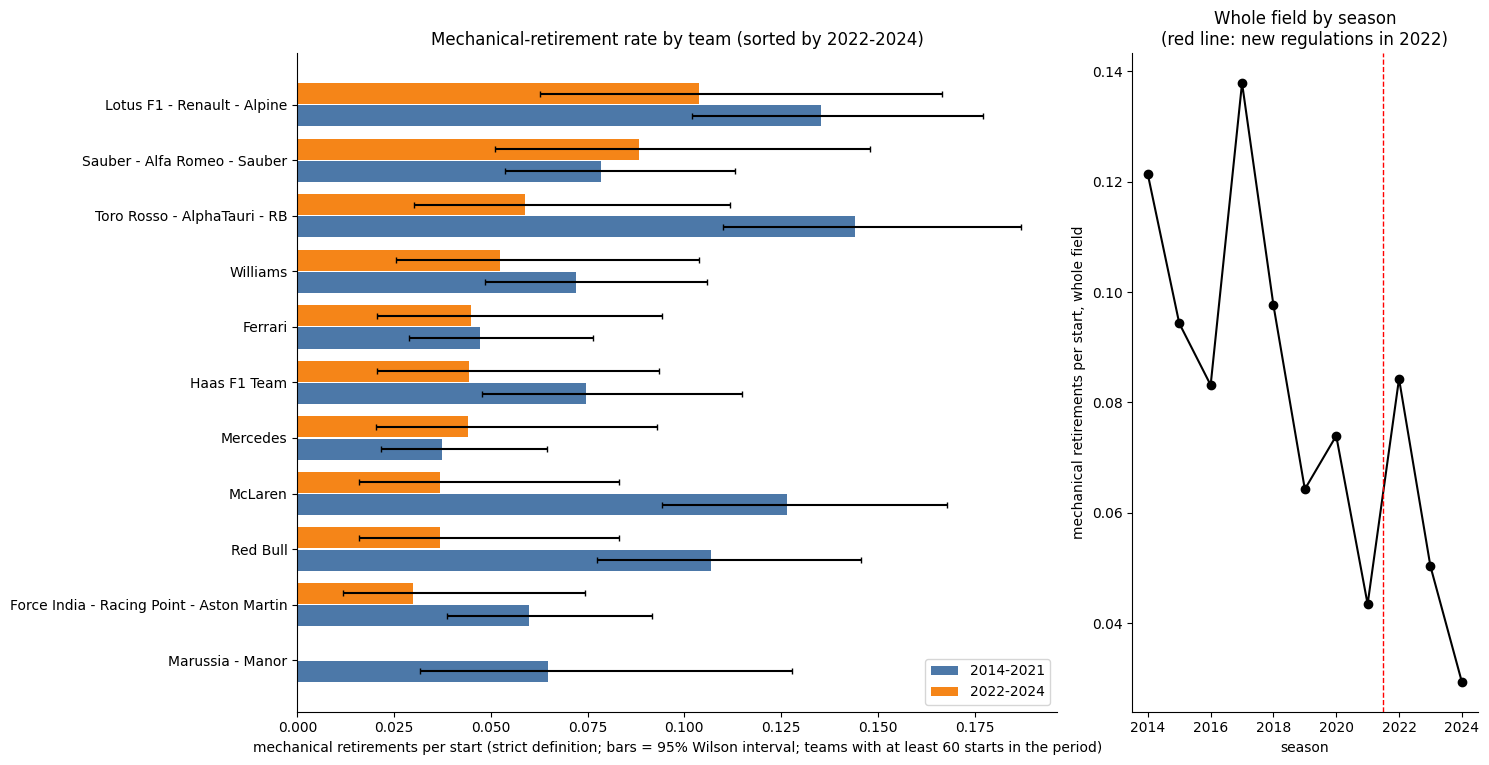

In [58]:
# the cleaned rows already carry the kept result's statusId and positionText (the raw results table still holds the duplicate rows of section 5)
q3 = (full[["raceId", "driverId", "constructorId", "year", "podium", "statusId", "positionText"]]
      .merge(T["status"], on="statusId", how="left", validate="many_to_one")
      .merge(T["constructors"][["constructorId", "name"]], on="constructorId", how="left", validate="many_to_one"))
assert len(q3) == len(full) and q3["status"].notna().all()
q3 = q3[q3["year"].between(2014, 2024) & ~q3["positionText"].isin(["F", "W"])].copy()
q3["period"] = np.where(q3["year"] <= 2021, "2014-2021", "2022-2024")
print("starts 2014-2024:", len(q3), "| statuses:", q3["status"].nunique())

CLASSES = {
 "finished (classified or lapped)": (["Finished", "+1 Lap", "+2 Laps", "+3 Laps", "+4 Laps", "+5 Laps", "+6 Laps", "+7 Laps", "+8 Laps"], "not a retirement", "the car ran to the end or was classified"),
 "power unit and drivetrain": (["Engine", "Power Unit", "Turbo", "ERS", "Battery", "Exhaust", "Spark plugs", "Gearbox", "Transmission", "Clutch", "Driveshaft", "Differential", "Drivetrain"], "mechanical", "a named component of the power unit or drivetrain failed"),
 "cooling, oil and fuel": (["Overheating", "Water pressure", "Water leak", "Water pump", "Radiator", "Cooling system", "Oil leak", "Oil pressure", "Fuel pressure", "Fuel leak", "Fuel system", "Fuel pump", "Out of fuel"], "mechanical", "a fluid system failed or ran out"),
 "chassis, brakes and hydraulics": (["Brakes", "Brake duct", "Suspension", "Hydraulics", "Steering", "Throttle", "Seat"], "mechanical", "a named chassis, brake or control component failed"),
 "electrical and unspecified technical": (["Electrical", "Electronics", "Power loss", "Mechanical", "Technical"], "mechanical", "the status itself says the failure was electrical or mechanical"),
 "ambiguous: could be failure or contact": (["Wheel", "Wheel nut", "Front wing", "Rear wing", "Undertray", "Damage", "Puncture", "Tyre", "Vibrations", "Retired"], "ambiguous", "the text does not say whether a component failed by itself or after contact, or whether it was a team error"),
 "crash and driver": (["Collision", "Accident", "Collision damage", "Spun off", "Debris"], "not mechanical", "contact, a crash or an off-track excursion"),
 "regulation or personal": (["Disqualified", "Excluded", "Withdrew", "Illness"], "not mechanical", "a regulation decision, a team withdrawal or the driver's health"),
}
rows = []
for grp, (sts, cls, why) in CLASSES.items():
    for s_ in sts:
        rows.append({"status": s_, "group": grp, "class": cls, "reason": why})
cls_table = pd.DataFrame(rows).set_index("status")
assert cls_table.index.is_unique
unclassified = sorted(set(q3["status"]) - set(cls_table.index))
print("statuses in 2014-2024 that are not classified:", unclassified)
counts = q3["status"].value_counts().rename("starts 2014-2024")
show_cls = cls_table.join(counts).dropna(subset=["starts 2014-2024"]).sort_values(["class", "starts 2014-2024"], ascending=[True, False])
print("\nStarts by class:"); display(q3["status"].map(cls_table["class"]).value_counts().to_frame("starts"))
with pd.option_context("display.max_rows", 100, "display.max_colwidth", 70):
    display(show_cls.astype({"starts 2014-2024": int}))
assert not unclassified

q3["cls"] = q3["status"].map(cls_table["class"])
q3["mech_strict"] = q3["cls"].eq("mechanical").astype(int)
q3["mech_broad"] = q3["cls"].isin(["mechanical", "ambiguous"]).astype(int)

LINEAGE = {208: "Lotus F1 - Renault - Alpine", 4: "Lotus F1 - Renault - Alpine", 214: "Lotus F1 - Renault - Alpine",
           10: "Force India - Racing Point - Aston Martin", 211: "Force India - Racing Point - Aston Martin", 117: "Force India - Racing Point - Aston Martin",
           5: "Toro Rosso - AlphaTauri - RB", 213: "Toro Rosso - AlphaTauri - RB", 215: "Toro Rosso - AlphaTauri - RB",
           15: "Sauber - Alfa Romeo - Sauber", 51: "Sauber - Alfa Romeo - Sauber", 206: "Marussia - Manor", 209: "Marussia - Manor"}
q3["team"] = [LINEAGE.get(c, n) for c, n in zip(q3["constructorId"], q3["name"])]

def rates(flag, min_starts=60):
    g = q3.groupby(["team", "period"])[flag].agg(["size", "sum"]).rename(columns={"size": "starts", "sum": "retirements"}).reset_index()
    g["rate"] = g["retirements"] / g["starts"]
    g[["low", "high"]] = [wilson(k, n) for k, n in zip(g["retirements"], g["starts"])]
    return g[g["starts"] >= min_starts]

rs, rb = rates("mech_strict"), rates("mech_broad")
def wide(g):
    w = g.pivot(index="team", columns="period", values="rate"); s = g.pivot(index="team", columns="period", values="starts")
    out = w.copy(); out.columns = [f"rate {c}" for c in out.columns]
    out["starts 2014-2021"], out["starts 2022-2024"] = s["2014-2021"], s["2022-2024"]
    return out
ws, wb = wide(rs), wide(rb)
wide_tab = ws.join(wb[["rate 2014-2021", "rate 2022-2024"]], rsuffix=" (broad)").sort_values("rate 2022-2024", ascending=False)
print("\nMechanical-retirement rate per start (strict = unambiguous failures, broad = plus ambiguous):"); display(wide_tab.round(3))

for period in ("2014-2021", "2022-2024"):
    g = rs[rs["period"] == period].sort_values("rate", ascending=False)
    print(f"\nhighest strict rates {period}:", [(r.team, round(r.rate, 3)) for r in g.head(3).itertuples()])
    gb_ = rb[rb["period"] == period].sort_values("rate", ascending=False)
    print(f"highest broad rates  {period}:", [(r.team, round(r.rate, 3)) for r in gb_.head(3).itertuples()])
common = ws.dropna()
print(f"\nrank agreement between the two periods (strict, {len(common)} teams): Spearman {spearmanr(common['rate 2014-2021'], common['rate 2022-2024']).correlation:.2f}")
print(f"rank agreement strict vs broad definition: 2014-2021 {spearmanr(wide_tab['rate 2014-2021'].dropna(), wide_tab.loc[wide_tab['rate 2014-2021'].notna(), 'rate 2014-2021 (broad)']).correlation:.2f}, 2022-2024 {spearmanr(wide_tab['rate 2022-2024'].dropna(), wide_tab.loc[wide_tab['rate 2022-2024'].notna(), 'rate 2022-2024 (broad)']).correlation:.2f}")

# did each team's rate change between periods? Fisher exact test per team, Holm correction over the teams tested
both = sorted(common.index)
pv = []
for t in both:
    a = q3[(q3["team"] == t) & (q3["period"] == "2014-2021")]["mech_strict"]; b = q3[(q3["team"] == t) & (q3["period"] == "2022-2024")]["mech_strict"]
    pv.append(fisher_exact([[a.sum(), len(a) - a.sum()], [b.sum(), len(b) - b.sum()]])[1])
adj = multipletests(pv, method="holm")[1]
change = pd.DataFrame({"rate 2014-2021": common.loc[both, "rate 2014-2021"], "rate 2022-2024": common.loc[both, "rate 2022-2024"], "p (Fisher)": pv, "p (Holm)": adj}, index=both)
change["change"] = change["rate 2022-2024"] - change["rate 2014-2021"]
display(change.sort_values("change").round(3))
print("whole field, strict rate per start:", q3.groupby("period")["mech_strict"].mean().round(3).to_dict(), "| broad:", q3.groupby("period")["mech_broad"].mean().round(3).to_dict())
field = q3.groupby("year").agg(starts=("mech_strict", "size"), mech=("mech_strict", "sum")); field["rate"] = field["mech"] / field["starts"]

fig, axes = plt.subplots(1, 2, figsize=(15, 0.45 * len(wide_tab) + 2.8), gridspec_kw={"width_ratios": [2.2, 1]})
ax = axes[0]
order_t = list(wide_tab.index)[::-1]
yy = np.arange(len(order_t))
for per, col, off in (("2014-2021", "#4C78A8", -0.2), ("2022-2024", "#F58518", 0.2)):
    g = rs[rs["period"] == per].set_index("team").reindex(order_t)
    ax.barh(yy + off, g["rate"], 0.38, color=col, label=per, xerr=[(g["rate"] - g["low"]).fillna(0), (g["high"] - g["rate"]).fillna(0)], capsize=2)
ax.set_yticks(yy); ax.set_yticklabels(order_t); ax.set_xlabel("mechanical retirements per start (strict definition; bars = 95% Wilson interval; teams with at least 60 starts in the period)")
ax.set_title("Mechanical-retirement rate by team (sorted by 2022-2024)"); ax.legend(loc="lower right")
ax = axes[1]
ax.plot(field.index, field["rate"], marker="o", color="black"); ax.axvline(2021.5, color="red", ls="--", lw=1)
ax.set_xlabel("season"); ax.set_ylabel("mechanical retirements per start, whole field"); ax.set_title("Whole field by season\n(red line: new regulations in 2022)")
plt.tight_layout(); plt.show()

**Reading the result.**

**Classification.** Of 4,598 starts in 2014-2024, 3,825 ended classified, **362 ended in a clear mechanical failure** (strict), 88 in an ambiguous status (the broad count adds these) and 323 in a crash, a driver error or a regulation decision. All 65 statuses are classified, each with its reason in the table.

**Answer.**
* **2014-2021 (strict):** the highest rates belong to **Toro Rosso and its successors (14.4 %), the Lotus-Renault-Alpine team (13.5 %) and McLaren (12.7 %)**, then Red Bull (10.7 %); the lowest are **Mercedes (3.8 %) and Ferrari (4.7 %)**.
* **2022-2024 (strict):** **Alpine (10.4 %), Sauber / Alfa Romeo (8.8 %) and Toro Rosso / AlphaTauri / RB (5.9 %)** are highest; Mercedes, Ferrari, Haas, McLaren, Red Bull and Aston Martin lie between 3 % and 5 %.
* **The whole field** falls from **8.9 % to 5.4 %** of starts (broad: 11.0 % to 6.8 %). By season (right panel) the fall is not steady: about 12 % in 2014, the highest season in 2017 (about 14 %), about 4.4 % in 2021, back up to about 8.4 % in 2022 (the first season of the new regulations) and about 2.9 % in 2024.
* **Only McLaren's fall is clearly beyond chance** (-9.0 points, adjusted p = 0.031). Toro Rosso (-8.5, p = 0.096) and Red Bull (-7.0, p = 0.13) fall by similar amounts but do not pass after correcting for ten tests; Mercedes, Ferrari and Sauber stay where they were.
* **The ranking** between the periods agrees only weakly (Spearman 0.38 over the ten teams with enough starts in both periods).
* **The definition matters little:** strict and broad rankings agree closely (Spearman 0.96 and 0.87). Ferrari and Mercedes (4-5 %) are clearly separated from McLaren, Toro Rosso and Alpine (13-14 %) in 2014-2021, although neighbouring teams overlap. Why the rates fell is not tested here.

**Grain.** One row is one start by one driver in one race; the rate is mechanical retirements divided by starts, counted per car, so a two-car team has about two starts per race. A start is a row whose `positionText` is not F or W. Renamed or sold teams are followed as one lineage (rule above). Caterham (34 starts) is below the 60-start minimum and is not ranked. **Missingness.** Every row has a status; statuses that do not say whether a part failed by itself are the ambiguous group, handled by the strict and broad counts. **Pre-race cutoff.** The status is known only after the race, so it can never be a feature for the same race; only earlier races' history may be used (the candidate `team_mech_dnf_rec` of section 10 does so and was not kept).

## 14. Predictive models

**Goal.** Predict the podium from the final features and compare models fairly. Every model uses the same rows, the same features, the same split (train 1950-2019, validation 2020-21, test 2022-24, section 8) and the same preprocessing (median fill, then standardise, fitted on the training rows only, section 11.5). The function `score_model` scores every model in exactly the same way on all three splits, so the comparison is fair by construction.

**Scores** (explained at the top). PR-AUC is the primary score and F1 at the frozen threshold the secondary score; ROC-AUC, precision, recall and the top-3 hit rate are reported next to them. **Log-loss** is used only inside the selection and tuning steps, where it compares probabilities. The **threshold** for F1, precision and recall is the value that maximises F1 on the validation rows, then frozen.

**Choosing without the test seasons.** Settings are chosen on the rolling folds inside the training seasons (feature subsets, trees, logistic penalty) or on the validation seasons (network shape, threshold). The test seasons are only scored at the end.

**Baselines and modelling attempts.** Two baselines are fixed first: logistic regression on the grid alone and on all final features (14.2), and boosted trees with settings fixed in advance (14.2b). Three modelling attempts then try to beat them, each in its own section with its before/after comparison: **(1)** tuning the trees (14.4), **(2)** tuning the logistic regression's penalty (14.5), **(3)** a shallow neural network with early stopping, two shapes and five seeds (14.6-14.6c). 14.3 checks whether a shorter feature list would do as well.

### The settings of the models: library defaults and our changes

Every model and method starts from its library's default settings (scikit-learn, Keras, SHAP, LIME). The table lists every setting we use, whether it is the **default** or **changed**, and why. The code carries the same note next to each call.

| Model / step | Setting | Library default | Ours | Why |
|---|---|---|---|---|
| Logistic regression | `C` (penalty strength) | 1.0 | 1.0, **default** | Tested from 0.01 to 30 in 14.5: nothing is better. |
| | penalty, solver | L2, lbfgs | **default** | The standard choice for a linear model with overlapping features. |
| | `max_iter` | 100 | 3000, **changed** | So the solver always finishes; it does not change the model. |
| Boosted trees | `max_depth` | no limit | 3, **changed** | Shallow trees, fixed before the selection (about 1,000 training races); tuning (14.4) found nothing better. |
| | `learning_rate` | 0.1 | 0.07, **changed** | Fixed before the selection (a slightly slower, safer learning rate); tuning (14.4) found nothing better. |
| | `max_iter` (number of trees), `min_samples_leaf`, `l2_regularization` | 100, 20, 0 | **default** | Tuned in 14.4: no other value is better. |
| | `early_stopping` | "auto" | off, **changed** | "auto" switches early stopping on above 10,000 rows, so the full training set (22,604 rows) would be trained differently from the folds and from the later starts of 10.5 (for example 6,822 rows from 2003). Off keeps every comparison fair. |
| Median fill | `strategy` | mean | median, **changed** | Section 11.3: skewed columns pull the mean away from the typical value. |
| Scaling | `StandardScaler` | mean 0, standard deviation 1 | **default** | |
| Season weights | `sample_weight` of every fit | none (every row counts the same) | half-life of 40 seasons, **changed** | Chosen in 9.4b: older seasons count less (the 1950 season about 30 % of 2019), without being dropped. |
| Neural network | layers | (built by us) | 32 and 16 ReLU neurons, sigmoid output | Shallow, as the brief asks; shape chosen in 14.6b. |
| | optimiser | Adam, learning rate 0.001 | **default** | The standard optimiser; the number of epochs is what we control. |
| | `batch_size` | 32 | 32, **default** | |
| | early stopping `patience` | 0 | 15, **changed** | One noisy epoch should not stop the training. |
| | `restore_best_weights` | False (keep the last epoch) | True, **changed** | Keeps the best epoch, not the last one. |
| | epochs of the final fit | (none) | 8 | The median best epoch found by early stopping (14.6b). |
| Permutation importance | shuffles per column | 5 (scikit-learn) | 10, **changed** | A steadier average; we use our own short function so both models are treated the same way. |
| SHAP | background rows | (none) | 100 training rows | A common size; keeps the network fast to explain. |
| LIME | `num_features` | 10 | 8, **changed** | Easier to read. |
| | `discretize_continuous` | True | **default** | Gives readable ranges such as `grid <= 6`. |
| Race bootstrap | number of redraws | (ours) | 500 in sections 9-10, 1,000 for the window, preprocessing and model comparisons, 200 for the weights in 15.1 | The selection repeats the test hundreds of times, so it uses fewer redraws to keep the run time reasonable. |
| Random search (14.4) | trials | (ours) | 30 | A common budget: with 30 trials there is about a 78 % chance that one lands in the best 5 % of the search space. |

### 14.1 Setup: the three splits and the model-ready matrices

**What we do and why.** The modelling table of section 12 holds the feature values unprocessed. Here the splits are cut and the preprocessing adopted in 11.5 (`build_prep`: median fill, then standardise) is **fitted on the training rows only** and applied unchanged to validation and test, so no information from later seasons reaches the models. Every model trains on exactly the same matrices, so the models differ only in the model. The helpers below (threshold search, top-3 hit rate, `score_model`) are shared by all models.

In [59]:
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score, precision_score,
                             recall_score, log_loss, precision_recall_curve)

# the three splits of section 8, from the modelling table of section 12
train_m = model_table[model_table["year"].between(TRAIN_START, 2019)].reset_index(drop=True)
valid_m = model_table[model_table["year"].between(2020, 2021)].reset_index(drop=True)
test_m  = model_table[model_table["year"] >= 2022].reset_index(drop=True)
SPLITS = {"train": train_m, "validation": valid_m, "test": test_m}

MODEL_FEATURES = list(FINAL_FEATURES)
assert list(NUM_COLS) == MODEL_FEATURES, "NUM_COLS (section 11) differs from FINAL_FEATURES"
assert ADOPTED == "fill_then_scale", "section 11.5 adopted a different recipe"
print(len(MODEL_FEATURES), "model features")

prep = build_prep(train_m, ADOPTED)          # the recipe of section 11.5, fitted on the training rows only
X = {k: prep(d) for k, d in SPLITS.items()}
y = {k: d["podium"].to_numpy() for k, d in SPLITS.items()}

summary = pd.DataFrame({k: {"rows": len(d), "races": d["raceId"].nunique(), "podium rate": round(d["podium"].mean(), 3),
                            "seasons": f"{d['year'].min()}-{d['year'].max()}"} for k, d in SPLITS.items()}).T
display(summary)
print("feature matrix:", X["train"].shape, "| missing values left: train", int(np.isnan(X["train"]).sum()), ", test", int(np.isnan(X["test"]).sum()))

def best_threshold(y_val, p_val):
    """The probability cut-off that maximises F1 on the VALIDATION rows (never on test)."""
    prec, rec, thr = precision_recall_curve(y_val, p_val)
    f1 = 2 * prec[:-1] * rec[:-1] / np.clip(prec[:-1] + rec[:-1], 1e-12, None)
    return float(thr[np.argmax(f1)])

def top3_hit_rate(d, p):
    """In every race take the 3 drivers with the highest predicted probability; share of them who finish on the podium."""
    t = d[["raceId", "podium"]].assign(p=p)
    rk = t.groupby("raceId")["p"].rank(ascending=False, method="first")
    return float(t.loc[rk <= 3, "podium"].mean())

def score_model(name, p, thr=None):
    """p = dict of predicted probabilities per split. The threshold comes from validation unless one is given."""
    if thr is None:
        thr = best_threshold(y["validation"], p["validation"])
    rows = []
    for k in SPLITS:
        yhat = (p[k] >= thr).astype(int)
        rows.append({"model": name, "split": k, "ROC-AUC": roc_auc_score(y[k], p[k]), "PR-AUC": average_precision_score(y[k], p[k]),
                     "F1": f1_score(y[k], yhat), "precision": precision_score(y[k], yhat, zero_division=0), "recall": recall_score(y[k], yhat),
                     "log-loss": log_loss(y[k], np.clip(p[k], 1e-6, 1 - 1e-6)), "top-3 hit rate": top3_hit_rate(SPLITS[k], p[k]), "threshold": thr})
    return pd.DataFrame(rows)

MODEL_RESULTS = []          # every model's rows are appended here; the comparison table is built from it at the end

33 model features


,rows,races,podium rate,seasons
train,22604,1007,0.134,1950-2019
validation,779,39,0.15,2020-2021
test,1356,68,0.15,2022-2024


feature matrix: (22604, 33) | missing values left: train 0 , test 0


**Reading the result.** The three splits are separated by time and do not overlap: training 1950-2019 (22,604 rows, 1,007 races), validation 2020-21 (779 rows, 39 races), test 2022-24 (1,356 rows, 68 races). The podium rate is 13.4 % in training and 15.0 % in validation and test, so PR-AUC (random guessing = this rate) can be compared across them. The matrix has 33 columns and no missing values left.

### 14.2 Baselines

**Question.** What do the final features add over the starting slot alone, and what is the reference every later model has to beat?

**What we do and why.** Two logistic regressions with the default penalty (`C = 1`), on the same rows and the same preprocessing: (1) **grid only** (`grid` and `grid_unassigned`), the simplest reasonable predictor; (2) **all final features**, the statistical baseline. The comparison shows whether the engineered features earn their place. Both stay frozen: later attempts are compared with them and never replace them. The second table gives the PR-AUC gain of the features over the grid with a 95% range (whole races redrawn) and a calibration check (mean predicted probability against the real podium rate).

**How logistic regression works.** It adds up the standardised features, each multiplied by a weight, plus a constant, and passes the sum through the sigmoid to get a probability between 0 and 1. A positive weight pushes towards a podium, a negative one away from it, and the size of the weight says how strongly one standard deviation of that feature moves the odds. Training picks the weights that give the lowest log-loss, with an L2 penalty that keeps the weights small (`C = 1`, the default; checked in 14.5). A driver is called "podium" when the probability is above the validation threshold.

**Limitations.**
* **Straight-line effects only.** Each feature shifts the odds by a fixed amount per unit. It cannot see thresholds (in 10.4 the podium rate stays near 0 and then jumps for the top bands of the points shares) or interactions (a strong car matters more from the front row), which is what the trees can do.
* **Overlapping features.** Several kept features measure how strong the car and driver are (form, standings, pace), so the individual weights are unstable and must not be read one by one, and never as causes.
* **Needs complete, scaled inputs,** so gaps are filled with the training median (11.3) before fitting.
* **One rule for every season.** The weights are the same for 1950 and 2019, so it cannot adapt to a change of era; its only signals of era are the availability flags (9.6b).

In [60]:
from sklearn.linear_model import LogisticRegression

def fit_logistic(cols, C=1.0):
    idx = [MODEL_FEATURES.index(c) for c in cols]
    m = LogisticRegression(C=C, max_iter=3000).fit(X["train"][:, idx], y["train"], sample_weight=train_weights(train_m))
    return m, {k: m.predict_proba(X[k][:, idx])[:, 1] for k in SPLITS}

m_grid, p_grid = fit_logistic(["grid", "grid_unassigned"])
m_lr, p_lr = fit_logistic(MODEL_FEATURES)
res_grid = score_model("logistic, grid only", p_grid)
res_lr = score_model("logistic, all features (baseline)", p_lr)
MODEL_RESULTS += [res_grid, res_lr]
display(pd.concat([res_grid, res_lr]).round(4).set_index(["model", "split"]).drop(columns=["log-loss", "threshold"]))

ROC-AUC  PR-AUC      F1  precision  recall  top-3 hit rate
model                             split                                                                 
logistic, grid only               train        0.8838  0.5003  0.5448     0.5461  0.5434          0.5468
                                  validation   0.9093  0.6386  0.6923     0.6923  0.6923          0.6923
                                  test         0.9136  0.6473  0.6486     0.6502  0.6471          0.6520
logistic, all features (baseline) train        0.9028  0.5802  0.5860     0.5289  0.6570          0.5617
                                  validation   0.9322  0.7355  0.7184     0.6875  0.7521          0.6838
                                  test         0.9200  0.7057  0.6462     0.5544  0.7745          0.6373

In [61]:
def paired_gain(p_new, p_ref, split, n=1000):
    d, yy = SPLITS[split], y[split]
    idx = d.groupby("raceId").indices
    ids = list(idx)
    rng = np.random.default_rng(SEED)
    diffs = []
    for _ in range(n):
        i = np.concatenate([idx[r] for r in rng.choice(ids, len(ids))])
        diffs.append(average_precision_score(yy[i], p_new[split][i]) - average_precision_score(yy[i], p_ref[split][i]))
    return np.percentile(diffs, [2.5, 97.5])

rows = []
for k in SPLITS:
    lo, hi = paired_gain(p_lr, p_grid, k)
    rows.append({"split": k, "PR-AUC gain, all features vs grid only": average_precision_score(y[k], p_lr[k]) - average_precision_score(y[k], p_grid[k]),
                 "95% range low": lo, "95% range high": hi,
                 "mean predicted (all features)": p_lr[k].mean(), "actual podium rate": y[k].mean()})
display(pd.DataFrame(rows).set_index("split").round(4))

,"PR-AUC gain, all features vs grid only",95% range low,95% range high,mean predicted (all features),actual podium rate
split,,,,,
train,0.0799,0.0680,0.0912,0.1335,0.1344
validation,0.0969,0.0497,0.1427,0.1473,0.1502
test,0.0584,0.0131,0.1001,0.1542,0.1504


**Reading the result.**
* **The grid alone is already a good predictor:** ROC-AUC 0.91 and PR-AUC 0.64 on validation (random guessing 0.15). On the training seasons it scores lower (PR-AUC 0.50), because the same grid slot meant less in older seasons (6.4).
* **The final features add real information:** PR-AUC rises to 0.736 on validation and 0.706 on test (grid only: 0.639 and 0.647). The gain over the grid is +0.097 on validation (95% range +0.050 to +0.143), +0.058 on test (+0.013 to +0.100) and +0.080 on training (+0.068 to +0.091); all three ranges are above 0. The gain is smaller on test and its range is wide, as expected with 68 races.
* **The probabilities are well calibrated on average:** mean predicted probability against the real podium rate is 0.134 against 0.134 (train), 0.147 against 0.150 (validation) and 0.154 against 0.150 (test).
* **Precision and recall.** At the validation threshold the model finds 75 % of the real podium finishers on validation and 77 % on test, with precision 0.69 and 0.55: it accepts some wrong calls to find most podiums.

### 14.2b Baseline 2: boosted trees

**How it works.** Gradient boosting builds many small decision trees one after another. Each new tree is fitted to the errors of the trees before it, and the final probability is the sum of all trees passed through a sigmoid. Here the trees have depth 3, there are 100 of them, and the learning rate is 0.07. These are the settings used in the selection (sections 9 and 10), so this baseline is comparable with those results.

**Limitations.** Trees can capture thresholds and interactions that logistic regression cannot, but they need more data to do so, their probabilities are often less well calibrated, and with few races per season they can pick up noise. The settings are not tuned yet (14.4).

**What we compare.** The same scores as the logistic baseline, on train, validation and test, with the threshold fixed on validation.

In [62]:
m_gb = make_gbm().fit(X["train"], y["train"], sample_weight=train_weights(train_m))
p_gb = {k: m_gb.predict_proba(X[k])[:, 1] for k in SPLITS}
res_gb = score_model("boosted trees, depth 3 (baseline)", p_gb)
MODEL_RESULTS.append(res_gb)
display(pd.concat([res_lr, res_gb]).round(4).set_index(["model", "split"]).drop(columns=["log-loss", "threshold"]))

ROC-AUC  PR-AUC      F1  precision  recall  top-3 hit rate
model                             split                                                                 
logistic, all features (baseline) train        0.9028  0.5802  0.5860     0.5289  0.6570          0.5617
                                  validation   0.9322  0.7355  0.7184     0.6875  0.7521          0.6838
                                  test         0.9200  0.7057  0.6462     0.5544  0.7745          0.6373
boosted trees, depth 3 (baseline) train        0.9139  0.6151  0.5975     0.5609  0.6392          0.5733
                                  validation   0.9335  0.7444  0.7250     0.7073  0.7436          0.6923
                                  test         0.9383  0.7039  0.6757     0.6287  0.7304          0.6471

**Reading the two baselines.** Neither model is clearly better.
* **PR-AUC** is close: validation 0.744 (trees) against 0.736 (logistic), test 0.706 (logistic) against 0.704 (trees).
* **The trees** have the higher ROC-AUC on test (0.938 against 0.920), the higher F1 on test (0.676 against 0.646) and the higher top-3 hit rate (0.692 against 0.684 on validation, 0.647 against 0.637 on test).
* **Both models score lower on the training rows than on later seasons** (training PR-AUC 0.580 for logistic, 0.615 for the trees). The training rows include the older seasons, which are harder to predict (14.2), so this is a difference between seasons; the gap between training and later scores cannot be read as overfitting here. 14.4 checks the settings directly.
* **Thresholds** differ (0.31 for logistic, 0.35 for trees): logistic gives higher recall, the trees higher precision.
* Both models score lower on test than on validation, and validation has only 39 races, so small differences should not be over-read.

### 14.3 Do we need all the final features?

**Question.** The final features add only a modest gain over the grid alone (14.2). Is the full list needed, or would the grid plus a few of the strongest features do as well?

**What we do and why.** The final features are ranked by their gain over the grid in 10.1 (both lenses added; training seasons only). Then the grid plus the top 2, 3, 5 and 8 features is compared with the full list using the selection method: rolling folds, gain in log-loss with a 95% range from redrawing whole races, in both lenses. **How to read it.** The final list was chosen by the rule of section 10; this step is a **check** of whether fewer features would do as well, judged with the same yardstick: the full list is *shown* to be better than a subset only if its gain has a range above 0 and is at least 0.0005 in at least one lens. Validation PR-AUC is shown to help reading and is not used to decide.

In [63]:
rank = (step1.loc[FINAL_UNITS, "lr_gain"] + step1.loc[FINAL_UNITS, "gbm_gain"]).sort_values(ascending=False)
print("final features, strongest first (gain over the grid in the two lenses of section 10.1, added):")
display(rank.round(4).to_frame("lr_gain + gbm_gain"))

d_sel = full[full["year"].between(TRAIN_START, 2019)]
def cols_for(k):
    return BASE + [c for u in rank.index[:k] for c in UNITS[u]]

SIZES = [0, 2, 3, 5, 8, len(rank)]
label = lambda k: "grid only" if k == 0 else (f"grid + all {k} (full list)" if k == len(rank) else f"grid + top {k}")

# 1) does the FULL list add a real gain over each subset? (rolling folds, training seasons only)
rows = []
for k in SIZES[:-1]:
    small = cols_for(k)
    row = {"features": label(k), "columns": len(small)}
    for mdl in ("lr", "gbm"):
        yy, p_small, rr = fold_predictions(d_sel, small, mdl, FOLDS)
        _, p_full, _ = fold_predictions(d_sel, MODEL_FEATURES, mdl, FOLDS)
        g, lo, hi, _, _ = pooled_gain(yy, p_small, p_full, rr)
        row.update({f"{mdl}: gain of the full list": g, f"{mdl} range low": lo, f"{mdl} range high": hi})
    ok = any(row[f"{m} range low"] > 0 and row[f"{m}: gain of the full list"] >= MIN_GAIN for m in ("lr", "gbm"))
    row["full list justified?"] = "yes" if ok else "no, the subset is enough"
    rows.append(row)
display(pd.DataFrame(rows).set_index("features").round(4))

# 2) for readability: validation PR-AUC of each list (not used to decide)
val_rows = []
for k in SIZES:
    idx = [MODEL_FEATURES.index(c) for c in cols_for(k)]
    p1 = make_lr().fit(X["train"][:, idx], y["train"], sample_weight=train_weights(train_m)).predict_proba(X["validation"][:, idx])[:, 1]
    p2 = make_gbm().fit(X["train"][:, idx], y["train"], sample_weight=train_weights(train_m)).predict_proba(X["validation"][:, idx])[:, 1]
    val_rows.append({"features": label(k), "columns": len(idx),
                     "logistic validation PR-AUC": average_precision_score(y["validation"], p1),
                     "trees validation PR-AUC": average_precision_score(y["validation"], p2)})
display(pd.DataFrame(val_rows).set_index("features").round(4))

final features, strongest first (gain over the grid in the two lenses of section 10.1, added):


,lr_gain + gbm_gain
unit,
team_pts_share_rec,0.0431
drv_pts_share_rec,0.0426
team_finish_rel_rec,0.0388
drv_pts_share_before,0.0324
team_pace_rec,0.0324
team_grid_rel_rec,0.0318
team_pts_share_before,0.0312
drv_champ_rank_before,0.0299
grid_vs_usual,0.0276


,columns,lr: gain of the full list,lr range low,lr range high,gbm: gain of the full list,gbm range low,gbm range high,full list justified?
features,,,,,,,,
grid only,8,0.0314,0.0243,0.0382,0.0218,0.0149,0.0282,yes
grid + top 2,10,0.0047,0.0017,0.0078,-0.0000,-0.0033,0.0029,yes
grid + top 3,11,0.0047,0.0017,0.0080,0.0000,-0.0034,0.0032,yes
grid + top 5,13,0.0028,-0.0002,0.0056,0.0000,-0.0033,0.0031,"no, the subset is enough"
grid + top 8,16,0.0031,-0.0002,0.0063,0.0008,-0.0023,0.0036,"no, the subset is enough"


,columns,logistic validation PR-AUC,trees validation PR-AUC
features,,,
grid only,8,0.6387,0.6395
grid + top 2,10,0.7315,0.7346
grid + top 3,11,0.7330,0.7347
grid + top 5,13,0.7296,0.7445
grid + top 8,16,0.7259,0.7492
grid + all 24 (full list),33,0.7355,0.7444


**Reading the result.** The strongest features are the recent points shares of the team and the driver (`team_pts_share_rec` 0.0431, `drv_pts_share_rec` 0.0426) and the team's recent finishing place (`team_finish_rel_rec` 0.0388); the last of the ranking are very weak, and `age` is negative (-0.0103: alone it makes the trees worse, 10.4).

**The grid plus the three strongest features captures almost the whole validation gain** of the logistic regression: PR-AUC 0.733 with them, against 0.736 for the full list and 0.639 for the grid alone. The trees score about the same with the top 3, 5 or 8 (0.735-0.749) as with the full list (0.744).

**On the rolling folds:**
* **The full list clearly beats the grid alone** in both lenses (logistic +0.0314, range +0.0243 to +0.0382; trees +0.0218, range +0.0149 to +0.0282).
* **It beats the top 2 and the top 3 in the logistic lens** (+0.0047, ranges +0.0017 to +0.0078 and +0.0017 to +0.0080), **but not the top 5** (+0.0028, range -0.0002 to +0.0056) **or the top 8** (+0.0031, range -0.0002 to +0.0063).
* **In the tree lens every subset of two or more features is level with the full list** (gains 0.0000 to +0.0008, every range includes 0): the trees find most of the signal in the strongest few.

**What this means.** The full list is shown to add something over the three strongest features, but not over the five or eight strongest: beyond about five, the extra features cannot be told apart from noise on about 198 races. We keep the full list chosen in section 10, for three reasons: it is the list the selection rule produced, and replacing it after this check would use the same folds twice; its logistic gain is positive against every subset (+0.003 to +0.005); and it keeps the groups (qualifying, standings, form, teammate) that the feature-group ablation of 14.9 compares. The finding itself stands: most of the signal beyond the starting slot comes from a few measures of how strong the car and the driver are.

### 14.4 Tuning the boosted trees

**Question.** The baseline trees (depth 3, 100 trees, learning rate 0.07) were fixed in advance and score higher on the training rows than on later seasons. Do other settings predict unseen seasons better?

**What we do and why.**
* We try **30 random combinations** of five settings: tree depth, learning rate, number of trees, minimum rows per leaf and L2 penalty. The baseline is one of the candidates. Random search finds good regions faster than a full grid because usually only a few settings matter (Bergstra and Bengio, 2012), and 30 trials is a commonly used budget: with 30 trials there is about a 78 % chance that at least one lands in the best 5 % of the search space.
* Each candidate is scored on the same rolling folds inside the training seasons, with the median fill and scaling fitted on that fold's training seasons only. Validation and test are not used.
* **Rule (the one used for every decision in this notebook):** a candidate beats the baseline only if its log-loss gain has a 95% range above 0 and is at least 0.0005. Among candidates that cannot be told apart from the best, we choose the simplest (shallower, then fewer trees).

In [64]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import ParameterSampler

d_tune = train_m.copy()
BASE_PARAMS = dict(max_depth=3, learning_rate=0.07, max_iter=100, min_samples_leaf=20, l2_regularization=0.0)
SPACE = {"max_depth": [2, 3, 4, 5], "learning_rate": [0.02, 0.03, 0.05, 0.07, 0.1],
         "max_iter": [50, 100, 200, 300], "min_samples_leaf": [20, 40, 80, 150],
         "l2_regularization": [0.0, 1.0, 5.0, 20.0]}
cands = [BASE_PARAMS] + list(ParameterSampler(SPACE, n_iter=30, random_state=SEED))

def run_folds(params):
    ys, ps, rs, fs = [], [], [], []
    for i, (a, b, (c, e)) in enumerate(FOLDS):
        tr, te = d_tune[d_tune["year"].between(a, b)], d_tune[d_tune["year"].between(c, e)]
        pp = build_prep(tr, ADOPTED)                      # fill + scale fitted on this fold's training seasons only
        m = HistGradientBoostingClassifier(random_state=SEED, early_stopping=False, **params).fit(pp(tr), tr["podium"].to_numpy(), sample_weight=train_weights(tr))
        ys.append(te["podium"].to_numpy()); ps.append(m.predict_proba(pp(te))[:, 1])
        rs.append(te["raceId"].to_numpy()); fs.append(np.full(len(te), i))
    return np.concatenate(ys), np.concatenate(ps), np.concatenate(rs), np.concatenate(fs)

runs = [run_folds(p) for p in cands]
yy, rr, ff = runs[0][0], runs[0][2], runs[0][3]
p_base = runs[0][1]

rows = []
for i, (p, r) in enumerate(zip(cands, runs)):
    g, lo, hi, l0, l1 = pooled_gain(yy, p_base, r[1], rr)
    rows.append({"id": i, **p, "log-loss": l1, "gain vs baseline": g, "range low": lo, "range high": hi})
tune = pd.DataFrame(rows).set_index("id")

best = int(tune["log-loss"].idxmin())
same = []                                              # candidates that cannot be told apart from the best one
for i, r in enumerate(runs):
    g, lo, hi, _, _ = pooled_gain(yy, r[1], runs[best][1], rr)    # >0 means the best is better
    if lo <= 0:
        same.append(i)
chosen = sorted(same, key=lambda i: (cands[i]["max_depth"], cands[i]["max_iter"], tune.loc[i, "log-loss"]))[0]   # simplest first; ties broken by log-loss

g, lo, hi, _, _ = pooled_gain(yy, p_base, runs[chosen][1], rr)
fold_ok = all(row_loss(yy[ff == k], runs[chosen][1][ff == k]).mean() < row_loss(yy[ff == k], p_base[ff == k]).mean() for k in range(len(FOLDS)))
adopt = bool(lo > 0 and g >= MIN_GAIN and fold_ok)
TREE_PARAMS = cands[chosen] if adopt else BASE_PARAMS

display(tune.sort_values("log-loss").head(10).round(4))
print(f"best by log-loss: id {best} | simplest not distinguishable from it: id {chosen} -> {cands[chosen]}")
print(f"chosen vs baseline: gain {g:+.4f}, 95% range {lo:+.4f} to {hi:+.4f}, better in every fold: {fold_ok}")
print("ADOPT tuned settings" if adopt else "KEEP the baseline settings", "->", TREE_PARAMS)

,max_depth,learning_rate,max_iter,min_samples_leaf,l2_regularization,log-loss,gain vs baseline,range low,range high
id,,,,,,,,,
1,3,0.10,200,20,20.0,0.2021,0.0003,-0.0021,0.0028
14,4,0.02,300,20,0.0,0.2023,0.0002,-0.0011,0.0015
26,4,0.03,300,20,20.0,0.2024,0.0001,-0.0020,0.0021
0,3,0.07,100,20,0.0,0.2025,0.0000,0.0000,0.0000
23,4,0.07,100,150,0.0,0.2027,-0.0002,-0.0018,0.0013
18,3,0.05,300,40,1.0,0.2030,-0.0005,-0.0030,0.0019
19,5,0.10,100,80,1.0,0.2036,-0.0011,-0.0043,0.0020
15,2,0.05,200,80,20.0,0.2044,-0.0019,-0.0036,0.0001
16,2,0.07,300,80,1.0,0.2044,-0.0019,-0.0040,-0.0001


best by log-loss: id 1 | simplest not distinguishable from it: id 22 -> {'min_samples_leaf': 20, 'max_iter': 100, 'max_depth': 2, 'learning_rate': 0.07, 'l2_regularization': 0.0}
chosen vs baseline: gain -0.0025, 95% range -0.0041 to -0.0005, better in every fold: False
KEEP the baseline settings -> {'max_depth': 3, 'learning_rate': 0.07, 'max_iter': 100, 'min_samples_leaf': 20, 'l2_regularization': 0.0}


**Reading the result.** No combination beats the baseline under the rule. The best by log-loss (id 1: depth 3, learning rate 0.10, 200 trees, L2 penalty 20) gains only +0.0003 over it (range -0.0021 to +0.0028), and the baseline itself is fourth of 30 (0.2025). The simplest candidate that cannot be told apart from the best (id 22: depth 2, learning rate 0.07, 100 trees, 20 rows per leaf, no penalty; not among the ten shown) is worse than the baseline (-0.0025, range -0.0041 to -0.0005), so by our rule **the baseline settings stay** (depth 3, 100 trees, learning rate 0.07). No candidate beats the baseline with a range above 0. The ten best candidates lie between 0.2021 and 0.2046, so the trees are not sensitive to these settings. This is the first modelling attempt, kept with its result.

### 14.5 Tuning the logistic regression

**Question.** The baseline logistic regression uses the default penalty strength (`C = 1`). `C` controls how strongly the weights are pulled toward zero: a small `C` means a simpler model, a large `C` a more flexible one. Does another value predict unseen seasons better?

**What we do and why.** Eight values of `C`, from 0.01 to 30, are scored on the same rolling folds as the trees, with the median fill and scaling fitted on each fold's training seasons only. Validation and test are not used. **Rule (the same as everywhere):** a value beats `C = 1` only if its log-loss gain has a 95% range above 0, is at least 0.0005, and holds in every fold. Among values that cannot be told apart from the best, we choose the simplest (the smallest `C`).

In [65]:
from sklearn.linear_model import LogisticRegression

C_GRID = [0.01, 0.03, 0.1, 0.3, 1.0, 3.0, 10.0, 30.0]

def run_folds_lr(C):
    ys, ps, rs, fs = [], [], [], []
    for i, (a, b, (c, e)) in enumerate(FOLDS):
        tr, te = d_tune[d_tune["year"].between(a, b)], d_tune[d_tune["year"].between(c, e)]
        pp = build_prep(tr, ADOPTED)
        m = LogisticRegression(C=C, max_iter=3000).fit(pp(tr), tr["podium"].to_numpy(), sample_weight=train_weights(tr))
        ys.append(te["podium"].to_numpy()); ps.append(m.predict_proba(pp(te))[:, 1])
        rs.append(te["raceId"].to_numpy()); fs.append(np.full(len(te), i))
    return np.concatenate(ys), np.concatenate(ps), np.concatenate(rs), np.concatenate(fs)

runs_lr = {C: run_folds_lr(C) for C in C_GRID}
yy, rr, ff = runs_lr[1.0][0], runs_lr[1.0][2], runs_lr[1.0][3]
p_base_lr = runs_lr[1.0][1]

rows = []
for C, r in runs_lr.items():
    g, lo, hi, _, l1 = pooled_gain(yy, p_base_lr, r[1], rr)
    rows.append({"C": C, "log-loss": l1, "gain vs C=1": g, "range low": lo, "range high": hi})
tune_lr = pd.DataFrame(rows).set_index("C")

best_C = tune_lr["log-loss"].idxmin()
same = [C for C, r in runs_lr.items() if pooled_gain(yy, r[1], runs_lr[best_C][1], rr)[1] <= 0]
chosen_C = min(same)
g, lo, hi, _, _ = pooled_gain(yy, p_base_lr, runs_lr[chosen_C][1], rr)
fold_ok = all(row_loss(yy[ff == k], runs_lr[chosen_C][1][ff == k]).mean() < row_loss(yy[ff == k], p_base_lr[ff == k]).mean() for k in range(len(FOLDS)))
adopt_lr = bool(chosen_C != 1.0 and lo > 0 and g >= MIN_GAIN and fold_ok)
LR_C_FINAL = chosen_C if adopt_lr else 1.0

display(tune_lr.round(4))
print(f"best by log-loss: C = {best_C} | simplest not distinguishable from it: C = {chosen_C}")
print(f"chosen vs C=1: gain {g:+.4f}, 95% range {lo:+.4f} to {hi:+.4f}, better in every fold: {fold_ok}")
print("ADOPT C =" if adopt_lr else "KEEP C =", LR_C_FINAL)

,log-loss,gain vs C=1,range low,range high
C,,,,
0.01,0.2058,0.0000,-0.0016,0.0017
0.03,0.2054,0.0004,-0.0004,0.0012
0.10,0.2055,0.0003,-0.0000,0.0006
0.30,0.2056,0.0002,0.0001,0.0003
1.00,0.2058,0.0000,0.0000,0.0000
3.00,0.2059,-0.0000,-0.0001,0.0000
10.00,0.2059,-0.0001,-0.0001,0.0000
30.00,0.2059,-0.0001,-0.0001,0.0000


best by log-loss: C = 0.03 | simplest not distinguishable from it: C = 0.01
chosen vs C=1: gain +0.0000, 95% range -0.0016 to +0.0017, better in every fold: False
KEEP C = 1.0


**Reading the result.** The penalty barely matters with 22,604 training rows: every `C` from 0.01 to 30 gives a log-loss between 0.2054 and 0.2059 (`C = 1`: 0.2058). The best value, `C = 0.03`, gains +0.0004 (range -0.0004 to +0.0012); the simplest value that cannot be told apart from it, `C = 0.01`, gains +0.0000 (range -0.0016 to +0.0017) and is not better in every fold, so **`C = 1` stays**. `C = 0.3` has a range just above 0 (+0.0001 to +0.0003), but its gain (+0.0002) is below the minimum of 0.0005.

### 14.6 Shallow neural network

**How it works.** A neuron computes a weighted sum of its inputs plus a bias and passes it through an activation function. We use ReLU in the hidden layers (it keeps positive values and sets negatives to 0) and a sigmoid in the output (a probability between 0 and 1, because the podium is a yes/no outcome). Training repeats these steps: the forward pass makes a prediction, the loss (binary cross-entropy, which is log-loss) measures the error, backpropagation works out how much each weight contributed to it, and the Adam optimiser nudges the weights to reduce it. One full pass over the training rows is an **epoch**.

**Early stopping.** Training for too many epochs makes the network memorise the training seasons. We hold out the last five training seasons (2015-2019) as an inner validation set, watch its log-loss after each epoch, and stop when it has not improved for 15 epochs, keeping the weights of the best epoch. For comparison we also train the same network without early stopping.

**Limitations.** The network has about 1,630 weights for about 20,500 training rows, so it can still overfit. Its result depends on the random starting weights, so it is repeated with 5 seeds in 14.6b. Because five seasons are used for early stopping, it learns from fewer seasons than the other models. It is also harder to interpret than logistic regression, and with 33 columns of tabular data simple models often do about as well, so the network is a comparison and not an expected winner.


inner train rows: 20526 | inner validation rows: 2078 (9%)


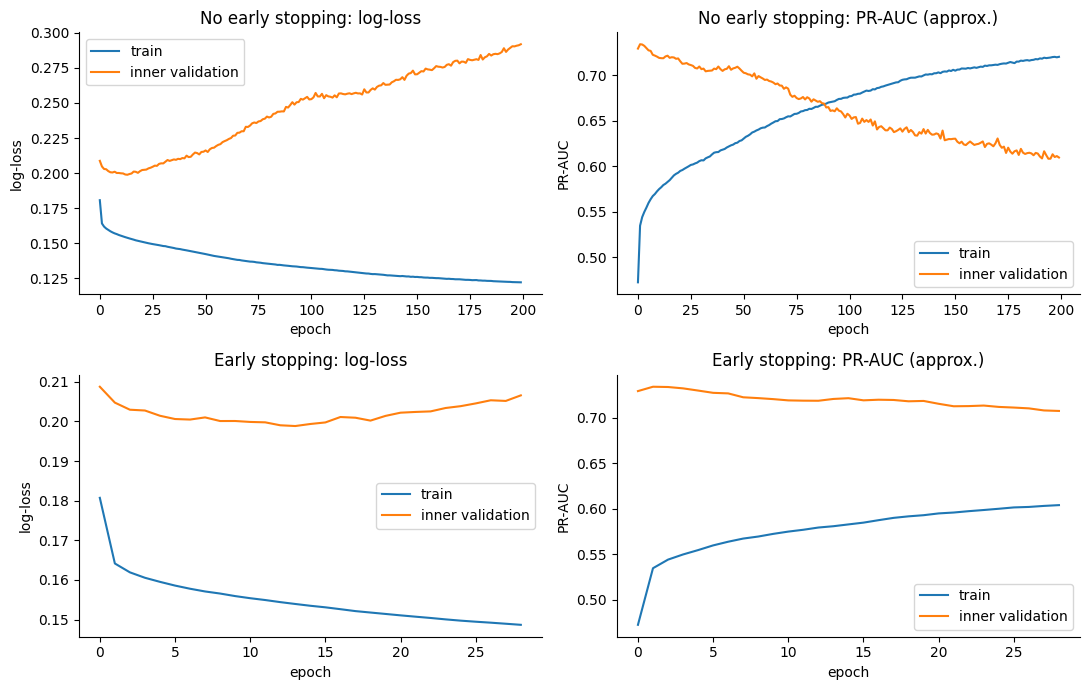

,epochs trained,inner-validation log-loss (best),validation 2020-21 log-loss,validation 2020-21 PR-AUC
"network (32-16, Adam)",,,,
no early stopping,200,0.2918,0.3225,0.6723
early stopping,29,0.1989,0.2254,0.7430


In [66]:
import keras
from keras import layers
from keras.callbacks import EarlyStopping

def build_model(widths, n_in=len(MODEL_FEATURES)):
    model = keras.Sequential([layers.Input(shape=(n_in,))]
                             + [layers.Dense(w, activation="relu") for w in widths]
                             + [layers.Dense(1, activation="sigmoid")])
    model.compile(optimizer="adam", loss="binary_crossentropy",     # Adam with its default learning rate (0.001); the loss is log-loss
                  metrics=[keras.metrics.AUC(curve="PR", name="pr_auc")])
    return model

inner = (train_m["year"] <= 2014).to_numpy()                      # inner training seasons up to 2014, inner validation 2015-2019
w_in = train_weights(train_m[inner])
X_in, y_in = X["train"][inner].astype("float32"), y["train"][inner]
X_iv, y_iv = X["train"][~inner].astype("float32"), y["train"][~inner]
print("inner train rows:", len(y_in), "| inner validation rows:", len(y_iv), f"({len(y_iv)/len(y['train']):.0%})")

WIDTHS = (32, 16)                                                  # funnel; the constant-width shape comes next

keras.utils.set_random_seed(42)
nn_plain = build_model(WIDTHS)
h_plain = nn_plain.fit(X_in, y_in, sample_weight=w_in, validation_data=(X_iv, y_iv), epochs=200, batch_size=32, verbose=0)   # batch_size 32 is the Keras default

keras.utils.set_random_seed(42)
nn_es = build_model(WIDTHS)
stop = EarlyStopping(monitor="val_loss", patience=15, restore_best_weights=True)   # changed: patience 15 (default 0), keep the best epoch (default: the last)
h_es = nn_es.fit(X_in, y_in, sample_weight=w_in, validation_data=(X_iv, y_iv), epochs=200, batch_size=32, verbose=0, callbacks=[stop])

fig, ax = plt.subplots(2, 2, figsize=(11, 7))
for r, (name, h) in enumerate((("No early stopping", h_plain), ("Early stopping", h_es))):
    ax[r, 0].plot(h.history["loss"], label="train"); ax[r, 0].plot(h.history["val_loss"], label="inner validation")
    ax[r, 0].set(title=f"{name}: log-loss", xlabel="epoch", ylabel="log-loss"); ax[r, 0].legend()
    ax[r, 1].plot(h.history["pr_auc"], label="train"); ax[r, 1].plot(h.history["val_pr_auc"], label="inner validation")
    ax[r, 1].set(title=f"{name}: PR-AUC (approx.)", xlabel="epoch", ylabel="PR-AUC"); ax[r, 1].legend()
plt.tight_layout(); plt.show()

rows = []
for name, mdl, h in (("no early stopping", nn_plain, h_plain), ("early stopping", nn_es, h_es)):
    pv = mdl.predict(X["validation"].astype("float32"), verbose=0).ravel()
    rows.append({"network (32-16, Adam)": name, "epochs trained": len(h.history["loss"]),
                 "inner-validation log-loss (best)": min(h.history["val_loss"]) if name == "early stopping" else h.history["val_loss"][-1],
                 "validation 2020-21 log-loss": log_loss(y["validation"], pv),
                 "validation 2020-21 PR-AUC": average_precision_score(y["validation"], pv)})
display(pd.DataFrame(rows).set_index("network (32-16, Adam)").round(4))

**Reading the result.** The plots and the table say the same thing.
* **Without early stopping** the network trains for all 200 epochs. The training log-loss keeps falling, but the inner-validation log-loss reaches its lowest point after about 14 epochs and then rises (to about 0.29 at epoch 200). On the validation seasons the log-loss is 0.323 and PR-AUC 0.672: the network has memorised the training seasons and makes confident wrong predictions on new ones.
* **With early stopping** training stops after 29 epochs (15 after the best one), and on the validation seasons the log-loss is 0.225 with PR-AUC 0.743.

Early stopping is therefore essential for this network. With it, this single run is about level with logistic regression (PR-AUC 0.736, log-loss 0.220) and the baseline trees (0.744, 0.218) on the same seasons. Because the result depends on the random starting weights, the next step repeats it with 5 seeds.

### 14.6b The two shapes, five seeds each

**Question.** Which shape works better, the funnel (32-16) or the constant width (32-32)? And how much does the result depend on the random starting weights?

**What we do.** Each shape is trained 5 times with different seeds, always with early stopping on the inner seasons (2015-2019, patience 15, best weights kept). Every run is then scored on the validation seasons (2020-21), which took no part in training or stopping. For each shape we compare the average over the 5 runs. The shape with the clearly higher average validation PR-AUC is chosen; when two shapes are within 0.01 PR-AUC we take the simpler one. The best epoch of each run is recorded; its median gives the number of epochs for the final fit on all training seasons.

In [67]:
SHAPES = {"funnel 32-16": (32, 16), "constant 32-32": (32, 32)}
SEEDS = [0, 1, 2, 3, 4]

runs = []
for name, w in SHAPES.items():
    for s in SEEDS:
        keras.utils.set_random_seed(s)
        m = build_model(w)
        stop = EarlyStopping(monitor="val_loss", patience=15, restore_best_weights=True)
        h = m.fit(X_in, y_in, sample_weight=w_in, validation_data=(X_iv, y_iv), epochs=200, batch_size=32, verbose=0, callbacks=[stop])
        pv = m.predict(X["validation"].astype("float32"), verbose=0).ravel()
        runs.append({"shape": name, "seed": s,
                     "best epoch": int(np.argmin(h.history["val_loss"])) + 1,
                     "inner log-loss": min(h.history["val_loss"]),
                     "validation log-loss": log_loss(y["validation"], pv),
                     "validation PR-AUC": average_precision_score(y["validation"], pv)})
nn_runs = pd.DataFrame(runs)
display(nn_runs.round(4))

summary = nn_runs.groupby("shape").agg(
    best_epoch=("best epoch", "median"),
    PR_AUC=("validation PR-AUC", "mean"),
    log_loss=("validation log-loss", "mean"))
display(summary.round(4))

ref = pd.concat([res_lr, res_gb])
display(ref[ref["split"] == "validation"][["model", "PR-AUC", "log-loss"]].round(4).set_index("model"))

top = summary["PR_AUC"].idxmax()
close = [s for s in summary.index if summary.loc[top, "PR_AUC"] - summary.loc[s, "PR_AUC"] < 0.01]
NN_SHAPE = min(close, key=lambda s: sum(SHAPES[s]))              # within 0.01 PR-AUC of the best: take the simpler shape
NN_EPOCHS = int(summary.loc[NN_SHAPE, "best_epoch"])
print(f"chosen shape: {NN_SHAPE} | epochs for the refit: {NN_EPOCHS}")

,shape,seed,best epoch,inner log-loss,validation log-loss,validation PR-AUC
0,funnel 32-16,0,8,0.1958,0.2199,0.7466
1,funnel 32-16,1,10,0.1970,0.2242,0.7326
2,funnel 32-16,2,8,0.1947,0.2240,0.7480
3,funnel 32-16,3,13,0.1987,0.2308,0.7484
4,funnel 32-16,4,7,0.2019,0.2293,0.7275
5,constant 32-32,0,14,0.1916,0.2224,0.7466
6,constant 32-32,1,6,0.1945,0.2270,0.7276
7,constant 32-32,2,9,0.1962,0.2246,0.7319
8,constant 32-32,3,8,0.2054,0.2324,0.7488
9,constant 32-32,4,10,0.1994,0.2353,0.7148


,best_epoch,PR_AUC,log_loss
shape,,,
constant 32-32,9.0,0.7339,0.2283
funnel 32-16,8.0,0.7406,0.2256


,PR-AUC,log-loss
model,,
"logistic, all features (baseline)",0.7355,0.2198
"boosted trees, depth 3 (baseline)",0.7444,0.2180


chosen shape: funnel 32-16 | epochs for the refit: 8


**Why the funnel (32-16) is the chosen shape.** The two shapes score almost the same on average: PR-AUC 0.741 for the funnel and 0.734 for the constant width, log-loss 0.226 and 0.228. The difference (0.007) is smaller than the spread between runs of the same shape (funnel 0.728 to 0.748, constant width 0.715 to 0.749), so it cannot be told apart from luck in the starting weights. We apply the rule of the tuning steps: when two options are within 0.01 PR-AUC, take the simpler one. The funnel has fewer neurons (48 against 64), so less room to overfit. Its median best epoch is 8, which is the number of epochs used for the final fit. On average the network is level with logistic regression (PR-AUC 0.736) and the baseline trees (0.744).

### 14.6c Final neural network

**What we do.** The chosen shape (funnel 32-16) is trained again on all training seasons (1950-2019) for the number of epochs found by early stopping (8); no early stopping is needed now, because the number of epochs is fixed. This is the standard way to use early stopping when the final model is retrained on all the data (Goodfellow, Bengio and Courville, *Deep Learning*, 2016, section 7.8): early stopping finds the number of epochs on held-out seasons, and the final fit reuses it, so no training season has to be held out. Because one network depends on its random starting weights, we train 5 networks with different seeds and average their predicted probabilities, which gives one stable prediction per row. This averaged network is the model in the results table. Its threshold is chosen on the validation seasons, in the same way as for the other models. The table below puts the three models side by side. **Choosing the final model.** The models are compared on validation (PR-AUC, paired by race) and, with more races, on the rolling folds (log-loss gain of the trees over logistic regression). The rule is the one used for every choice: the simpler model stays unless a more complex one beats it with a 95% range above 0; when models cannot be told apart, the simpler one is preferred (the one-standard-error rule, Hastie, Tibshirani and Friedman, *The Elements of Statistical Learning*, section 7.10).

In [68]:
NN_WIDTHS = SHAPES[NN_SHAPE]
Xs = {k: X[k].astype("float32") for k in SPLITS}
probs = {k: [] for k in SPLITS}
for s in SEEDS:
    keras.utils.set_random_seed(s)
    m = build_model(NN_WIDTHS)
    m.fit(Xs["train"], y["train"], sample_weight=train_weights(train_m), epochs=NN_EPOCHS, batch_size=32, verbose=0)
    for k in SPLITS:
        probs[k].append(m.predict(Xs[k], verbose=0).ravel())
p_nn = {k: np.mean(v, axis=0) for k, v in probs.items()}

res_nn = score_model(f"neural network, {NN_SHAPE} (average of 5 seeds)", p_nn)
MODEL_RESULTS.append(res_nn)

show = ["model", "split", "ROC-AUC", "PR-AUC", "F1", "precision", "recall", "top-3 hit rate"]
table = pd.concat([res_lr, res_gb, res_nn])
display(table[show].round(4))
print("thresholds chosen on validation:", table.groupby("model")["threshold"].first().round(4).to_dict())

# MODEL CHOICE: can the validation seasons tell the three models apart? Paired race bootstrap of the PR-AUC difference to the
# simplest model (logistic regression). Rule (the same as in 14.4 and 14.5): the simplest model is kept unless another one beats it
# with the 95% range above 0.
cmp_rows = []
for name, p in (("boosted trees", p_gb), ("neural network", p_nn)):
    lo, hi = paired_gain(p, p_lr, "validation")
    cmp_rows.append({"model": name, "validation PR-AUC minus logistic": average_precision_score(y["validation"], p["validation"]) - average_precision_score(y["validation"], p_lr["validation"]),
                     "range low": lo, "range high": hi, "beats logistic": lo > 0})
cmp = pd.DataFrame(cmp_rows).set_index("model")
display(cmp.round(4))
# the same comparison on the rolling folds (198 races, training seasons only): log-loss gain of the trees over logistic regression
y_f, p_lr_f, r_f = fold_predictions(train_m, MODEL_FEATURES, "lr", FOLDS)
_, p_gb_f, _ = fold_predictions(train_m, MODEL_FEATURES, "gbm", FOLDS)
g_f, lo_f, hi_f, ll_lr_f, ll_gb_f = pooled_gain(y_f, p_lr_f, p_gb_f, r_f)
print(f"rolling folds | log-loss logistic {ll_lr_f:.4f}, trees {ll_gb_f:.4f} | gain of the trees {g_f:+.4f} (95% range {lo_f:+.4f} to {hi_f:+.4f})",
      f"| PR-AUC logistic {average_precision_score(y_f, p_lr_f):.4f}, trees {average_precision_score(y_f, p_gb_f):.4f}")
print("CHOICE:", "a more complex model wins" if cmp["beats logistic"].any() else "logistic regression (no other model beats it with the range above 0)" if not (cmp["beats logistic"].any() or lo_f > 0) else "check: a model beats logistic regression")

,model,split,ROC-AUC,PR-AUC,F1,precision,recall,top-3 hit rate
0,"logistic, all features (baseline)",train,0.9028,0.5802,0.5860,0.5289,0.6570,0.5617
1,"logistic, all features (baseline)",validation,0.9322,0.7355,0.7184,0.6875,0.7521,0.6838
2,"logistic, all features (baseline)",test,0.9200,0.7057,0.6462,0.5544,0.7745,0.6373
0,"boosted trees, depth 3 (baseline)",train,0.9139,0.6151,0.5975,0.5609,0.6392,0.5733
1,"boosted trees, depth 3 (baseline)",validation,0.9335,0.7444,0.7250,0.7073,0.7436,0.6923
2,"boosted trees, depth 3 (baseline)",test,0.9383,0.7039,0.6757,0.6287,0.7304,0.6471
0,"neural network, funnel 32-16 (average of 5 seeds)",train,0.9126,0.6096,0.5843,0.5854,0.5833,0.5809
1,"neural network, funnel 32-16 (average of 5 seeds)",validation,0.9298,0.7440,0.7100,0.7193,0.7009,0.6838
2,"neural network, funnel 32-16 (average of 5 seeds)",test,0.9266,0.7031,0.6396,0.6233,0.6569,0.6225


thresholds chosen on validation: {'boosted trees, depth 3 (baseline)': 0.3509, 'logistic, all features (baseline)': 0.3095, 'neural network, funnel 32-16 (average of 5 seeds)': 0.3745}


,validation PR-AUC minus logistic,range low,range high,beats logistic
model,,,,
boosted trees,0.0089,-0.0159,0.0320,False
neural network,0.0084,-0.0109,0.0274,False


rolling folds | log-loss logistic 0.2058, trees 0.2025 | gain of the trees +0.0034 (95% range -0.0010 to +0.0080) | PR-AUC logistic 0.7005, trees 0.7034
CHOICE: logistic regression (no other model beats it with the range above 0)


**Reading the model comparison.** The three models perform similarly.
* **PR-AUC:** on validation the trees and the network are level (0.744 each) and logistic regression is at 0.736; on test (models trained on 1950-2019) logistic regression 0.706, trees 0.704, network 0.703. ROC-AUC is 0.92-0.94 for all three.
* **Can validation tell them apart?** No. Against logistic regression, the trees gain +0.009 PR-AUC (95% range -0.016 to +0.032) and the network +0.008 (-0.011 to +0.027): both ranges include 0.
* **Can the rolling folds tell them apart?** No. With about 198 races instead of 39, the trees' log-loss is 0.2025 against 0.2058 for logistic regression: a gain of +0.0034, range -0.0010 to +0.0080, which includes 0 (PR-AUC on the folds 0.703 against 0.701).
* **Stability:** all three score lower on training (PR-AUC 0.58-0.62) than on validation, because the training rows include the older, harder seasons (14.2).
* **Averaging five networks:** single runs of the funnel ranged from 0.728 to 0.748 PR-AUC on validation; the average of five gives 0.744.
* **Precision and recall:** logistic regression finds the most podiums (recall on validation 0.75) at the lowest precision (0.69); the network is the most precise (0.72) and finds the fewest (0.70); the trees sit in between (0.71 and 0.74).
* **Choice:** by the rule used for every decision in this notebook (a more complex option replaces the simpler one only when it wins with a range above 0), **logistic regression is selected**. The trees are slightly ahead on most scores, but inside the noise on both validation and the folds; when models cannot be told apart, the simpler one is kept (the one-standard-error rule, ESL section 7.10). The test results are reported but were not used to choose.

### 14.7 Final models: refit on train + validation

**What we do and why.** Up to 14.6c the models were trained on the training seasons only, so that validation stayed unseen and could be used to choose: the settings, the network shape, the epochs, the threshold, and the final model (logistic regression). All choices are now made. Following the standard workflow, each chosen model is **refitted once on train + validation (1950-2021)** and scored **once on the test seasons**. These refitted models are the **final models**, and their test scores are the final result. The seasons 2020-21 are closer to the test years, and there is nothing left to tune on validation. The settings are unchanged: logistic regression with `C = 1`, the baseline trees, and the funnel network with 8 epochs (average of 5 seeds). The preprocessing is refitted on the combined data. The **thresholds are the ones chosen on validation before the refit and are not changed**: after the refit there is no unseen validation left to choose a new one, and choosing it on test would let test influence the result. The table shows each final model next to its train-only version.

In [69]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier

tv = pd.concat([train_m, valid_m]).reset_index(drop=True)
pp = build_prep(tv, ADOPTED)
Xtv, ytv, Xte = pp(tv), tv["podium"].to_numpy(), pp(test_m)

final_prep = pp                                                           # the preprocessing fitted on train + validation
final_lr = LogisticRegression(C=1.0, max_iter=3000).fit(Xtv, ytv, sample_weight=train_weights(tv))         # the final logistic regression (kept for the plots, SHAP, LIME and the inference function)
p_refit = {}
p_refit["logistic, all features (baseline)"] = final_lr.predict_proba(Xte)[:, 1]
p_refit["boosted trees, depth 3 (baseline)"] = HistGradientBoostingClassifier(random_state=SEED, early_stopping=False, **TREE_PARAMS).fit(Xtv, ytv, sample_weight=train_weights(tv)).predict_proba(Xte)[:, 1]
nn_p = []
for s in SEEDS:
    keras.utils.set_random_seed(s)
    m = build_model(NN_WIDTHS)
    m.fit(Xtv.astype("float32"), ytv, sample_weight=train_weights(tv), epochs=NN_EPOCHS, batch_size=32, verbose=0)
    nn_p.append(m.predict(Xte.astype("float32"), verbose=0).ravel())
p_refit[res_nn["model"].iloc[0]] = np.mean(nn_p, axis=0)

old = pd.concat([res_lr, res_gb, res_nn])
rows = []
for name, p in p_refit.items():
    thr = old[old["model"] == name]["threshold"].iloc[0]                 # frozen from validation
    pred = (p >= thr).astype(int)
    rows.append({"model": name, "version": "refit on train + validation",
                 "ROC-AUC": roc_auc_score(y["test"], p), "PR-AUC": average_precision_score(y["test"], p),
                 "F1": f1_score(y["test"], pred), "precision": precision_score(y["test"], pred),
                 "recall": recall_score(y["test"], pred), "top-3 hit rate": top3_hit_rate(test_m, p)})
refit = pd.DataFrame(rows)

before = old[old["split"] == "test"].copy()
before["version"] = "train only"
show = ["model", "version", "ROC-AUC", "PR-AUC", "F1", "precision", "recall", "top-3 hit rate"]
display(pd.concat([before[show], refit[show]]).sort_values(["model", "version"], ascending=[True, False]).round(4).set_index("model"))

,version,ROC-AUC,PR-AUC,F1,precision,recall,top-3 hit rate
model,,,,,,,
"boosted trees, depth 3 (baseline)",train only,0.9383,0.7039,0.6757,0.6287,0.7304,0.6471
"boosted trees, depth 3 (baseline)",refit on train + validation,0.9386,0.7027,0.6740,0.6120,0.7500,0.6520
"logistic, all features (baseline)",train only,0.9200,0.7057,0.6462,0.5544,0.7745,0.6373
"logistic, all features (baseline)",refit on train + validation,0.9202,0.7065,0.6517,0.5575,0.7843,0.6373
"neural network, funnel 32-16 (average of 5 seeds)",train only,0.9266,0.7031,0.6396,0.6233,0.6569,0.6225
"neural network, funnel 32-16 (average of 5 seeds)",refit on train + validation,0.9260,0.6983,0.6424,0.6000,0.6912,0.6176


**Reading the result.** The refit changes the test scores a little, in no consistent direction: PR-AUC trees 0.7039 to 0.7027 (-0.0012), logistic regression 0.7057 to 0.7065 (+0.0008), network 0.7031 to 0.6983 (-0.0048); the other scores move by at most 0.035. The changes are inside the noise of 68 races.

**Final test results.** The three final models are close: PR-AUC 0.7065 (logistic regression), 0.7027 (trees) and 0.6983 (network); the trees have the highest ROC-AUC (0.939), F1 (0.674) and top-3 hit rate (0.652). These differences are small compared with the noise of 68 races. **The final model is the logistic regression**, chosen on validation before the test seasons were scored (14.6c). Its test scores: PR-AUC 0.707, ROC-AUC 0.920, F1 0.652, precision 0.557, recall 0.784 and top-3 hit rate 0.637, at the frozen threshold of 0.310.

### 14.8 Plots of the results

**What we plot.** **A and B:** the ROC curve and the precision-recall curve of the three **final models** (refit on train + validation) on the test seasons; the dot on each PR curve is the frozen validation threshold. **C and D:** PR-AUC and top-3 hit rate by split for the models **as compared before the refit** (train-only), because a refit model has seen the validation seasons and has no honest validation score.

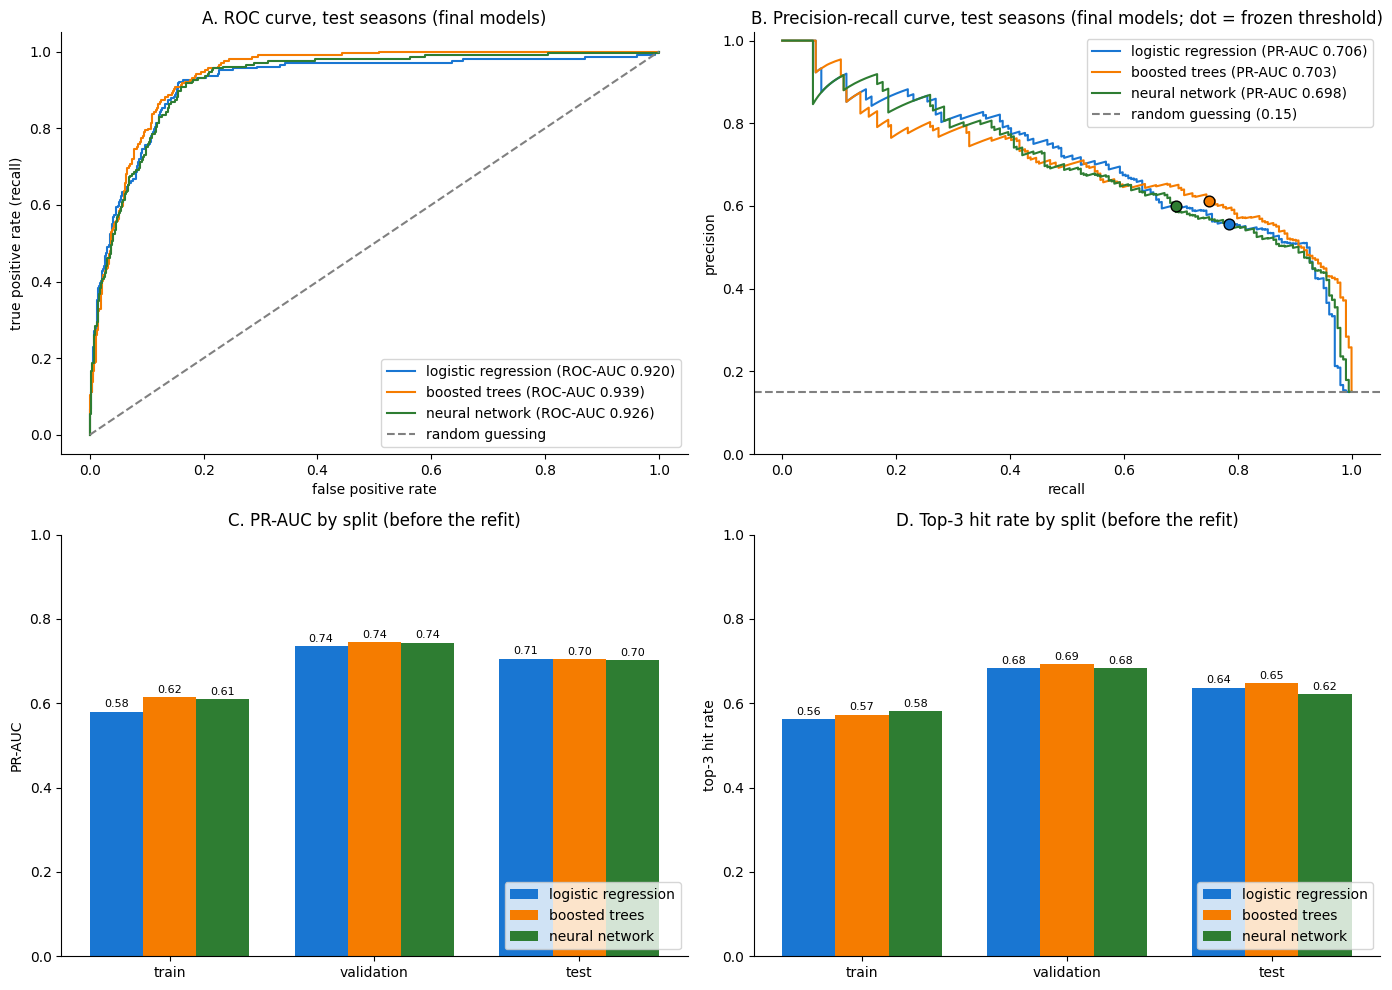

In [70]:
from sklearn.metrics import roc_curve, precision_recall_curve

NAMES = {"logistic regression": "logistic, all features (baseline)", "boosted trees": "boosted trees, depth 3 (baseline)", "neural network": res_nn["model"].iloc[0]}
FINAL = {k: p_refit[v] for k, v in NAMES.items()}
RES = {"logistic regression": res_lr, "boosted trees": res_gb, "neural network": res_nn}
COL = {"logistic regression": "#1976D2", "boosted trees": "#F57C00", "neural network": "#2E7D32"}
yt = y["test"]

fig, ax = plt.subplots(2, 2, figsize=(14, 10))
for name, p in FINAL.items():
    fpr, tpr, _ = roc_curve(yt, p)
    ax[0, 0].plot(fpr, tpr, color=COL[name], label=f"{name} (ROC-AUC {roc_auc_score(yt, p):.3f})")
ax[0, 0].plot([0, 1], [0, 1], "--", color="grey", label="random guessing")
ax[0, 0].set(xlabel="false positive rate", ylabel="true positive rate (recall)", title="A. ROC curve, test seasons (final models)")
ax[0, 0].legend(loc="lower right")

for name, p in FINAL.items():
    pr, rc, _ = precision_recall_curve(yt, p)
    ax[0, 1].plot(rc, pr, color=COL[name], label=f"{name} (PR-AUC {average_precision_score(yt, p):.3f})")
    r_ = refit.set_index("model").loc[NAMES[name]]
    ax[0, 1].scatter([r_["recall"]], [r_["precision"]], color=COL[name], s=60, zorder=3, edgecolor="black")
ax[0, 1].axhline(yt.mean(), ls="--", color="grey", label=f"random guessing ({yt.mean():.2f})")
ax[0, 1].set(xlabel="recall", ylabel="precision", title="B. Precision-recall curve, test seasons (final models; dot = frozen threshold)", ylim=(0, 1.02))
ax[0, 1].legend(loc="upper right")

x, w = np.arange(len(SPLITS)), 0.26
for panel, metric, title in ((ax[1, 0], "PR-AUC", "C. PR-AUC by split (before the refit)"),
                             (ax[1, 1], "top-3 hit rate", "D. Top-3 hit rate by split (before the refit)")):
    for j, (name, r) in enumerate(RES.items()):
        vals = r.set_index("split").loc[list(SPLITS), metric].to_numpy()
        bars = panel.bar(x + (j - 1) * w, vals, w, color=COL[name], label=name)
        for b_, v in zip(bars, vals):
            panel.text(b_.get_x() + b_.get_width() / 2, v + 0.01, f"{v:.2f}", ha="center", fontsize=8)
    panel.set(xticks=x, xticklabels=list(SPLITS), ylim=(0, 1), ylabel=metric, title=title)
    panel.legend(loc="lower right")
plt.tight_layout(); plt.show()

### 14.9 Feature-group ablation: what does each group give the final models?

**What we do.** The final models use 33 columns. We split them into groups that each carry one kind of information (qualifying, form, standings, and so on); each availability flag (9.6b) goes with the columns whose presence it records, so removing a group also removes its flag. For each group we remove its columns, refit the model exactly as the final model was refit (train and validation seasons, same settings) and score it on the test seasons. The drop in PR-AUC compared with the full model is that group's contribution.

**How this differs from the earlier feature steps.** The correlations and Trials A and B justified features *before* training, using exploratory evidence. The ablation measures what each group contributes *after* training, in the models we actually report.

**This is an explanation, not a selection.** No choice in the notebook depends on this table, so using the test seasons here does not contaminate them. We also do not change the feature list after seeing it, because that would turn the test seasons into a selection tool.

**How to read it.** A drop is *measurable* only when its 95% race-bootstrap range lies fully above 0. The test set has only 68 races, so small drops can lie inside the noise. Groups that describe the same thing (for example grid, qualifying and qualifying form all describe where a driver starts) can cover for each other: removing one may cost little because another still carries the information. A small drop therefore means "the model has other ways to get this information", not "the group is useless".

In [71]:
# Fine groups: the concepts defined earlier, restricted to units kept in the final list, plus the starting-slot columns
GROUPS_FINE = {g: [c for u in us if u in set(FINAL_UNITS) for c in UNITS[u]] for g, us in CONCEPTS.items()}
GROUPS_FINE = {g: cols for g, cols in GROUPS_FINE.items() if cols}
GROUPS_FINE["Grid"] = ["grid", "grid_unassigned"] + GROUPS_FINE.get("Grid", [])
GROUPS_FINE["Qualifying"] = GROUPS_FINE.get("Qualifying", []) + ["q_knockout"]       # the format flag goes with the qualifying columns it describes
# each availability flag (9.6b) goes with the columns whose presence it records, so removing a group removes its flag too
for g, flag in (("Qualifying", "has_quali"), ("Race pace", "has_lap_times"), ("Standings", "has_team_standings"),
                ("Driver form", "has_driver_history"), ("Teammate", "has_teammate")):
    GROUPS_FINE[g] = GROUPS_FINE.get(g, []) + [flag]

# Coarse groups: whole information sources, merged from the fine groups (fixed before seeing any result)
fine = lambda *names: [c for n in names for c in GROUPS_FINE.get(n, [])]
GROUPS_COARSE = {
    "Grid and qualifying": fine("Grid", "Qualifying", "Qualifying form"),
    "Recent form": fine("Driver form", "Team form", "Race pace", "Reliability"),
    "Teammate comparison": fine("Teammate"),
    "Standings": fine("Standings"),
    "Driver profile": fine("Driver profile"),
}
rest = [c for c in MODEL_FEATURES if c not in sum(GROUPS_COARSE.values(), [])]
if rest:
    GROUPS_COARSE["Other"] = rest
GROUPS_COARSE = {g: cols for g, cols in GROUPS_COARSE.items() if cols}

# every model column must sit in exactly one group, in both versions
for G in (GROUPS_FINE, GROUPS_COARSE):
    assert sorted(sum(G.values(), [])) == sorted(MODEL_FEATURES)

for name, G in (("FINE", GROUPS_FINE), ("COARSE", GROUPS_COARSE)):
    print(name)
    for g, cols in G.items():
        print(f"  {g} ({len(cols)}): {', '.join(cols)}")


FINE
  Qualifying (6): q_pos, q_gap_pct, q1_gap_pct, q_last_gap_pct, q_knockout, has_quali
  Qualifying form (2): team_grid_rel_rec, grid_vs_usual
  Driver form (3): drv_pts_share_rec, drv_laps_share_rec, has_driver_history
  Team form (2): team_finish_rel_rec, team_pts_share_rec
  Teammate (4): teammate_grid_rel, drv_vs_teammate_qgap, teammate_form_rec, has_teammate
  Standings (5): drv_pts_share_before, team_pts_share_before, drv_champ_rank_before, drv_wins_before, has_team_standings
  Reliability (1): drv_incident_rec
  Race pace (5): team_pace_rec, drv_pace_vs_team, drv_start_gain_rec, drv_lap_spread_rec, has_lap_times
  Driver profile (3): age, age2, drv_prior_starts
  Grid (2): grid, grid_unassigned
COARSE
  Grid and qualifying (10): grid, grid_unassigned, q_pos, q_gap_pct, q1_gap_pct, q_last_gap_pct, q_knockout, has_quali, team_grid_rel_rec, grid_vs_usual
  Recent form (11): drv_pts_share_rec, drv_laps_share_rec, has_driver_history, team_finish_rel_rec, team_pts_share_rec, team_

logistic regression (final): full model, test PR-AUC 0.7065, log-loss 0.2569
check: full model here equals the 14.7 final model, max prediction difference: 0.0


,columns removed,PR-AUC with,PR-AUC without,drop,range low,range high,measurable,log-loss with,log-loss without,log-loss increase
group removed,,,,,,,,,,
Grid,2,0.7065,0.6968,0.0097,-0.0082,0.0271,no,0.2569,0.2542,-0.0027
Standings,5,0.7065,0.7029,0.0036,-0.0083,0.0144,no,0.2569,0.2592,0.0023
Qualifying,6,0.7065,0.7033,0.0032,-0.0080,0.0150,no,0.2569,0.2243,-0.0326
Team form,2,0.7065,0.7055,0.0010,-0.0040,0.0054,no,0.2569,0.2586,0.0017
Reliability,1,0.7065,0.7065,-0.0000,-0.0011,0.0013,no,0.2569,0.2569,-0.0000
Qualifying form,2,0.7065,0.7074,-0.0009,-0.0046,0.0023,no,0.2569,0.2562,-0.0007
Teammate,4,0.7065,0.7074,-0.0010,-0.0079,0.0060,no,0.2569,0.2583,0.0014
Driver profile,3,0.7065,0.7077,-0.0012,-0.0040,0.0013,no,0.2569,0.2571,0.0001
Race pace,5,0.7065,0.7084,-0.0019,-0.0057,0.0025,no,0.2569,0.2569,-0.0000


boosted trees (final): full model, test PR-AUC 0.7027, log-loss 0.2208
14.7 prediction keys: ['logistic, all features (baseline)', 'boosted trees, depth 3 (baseline)', 'neural network, funnel 32-16 (average of 5 seeds)']


,columns removed,PR-AUC with,PR-AUC without,drop,range low,range high,measurable,log-loss with,log-loss without,log-loss increase
group removed,,,,,,,,,,
Grid,2,0.7027,0.6959,0.0067,-0.0049,0.0190,no,0.2208,0.2253,0.0044
Team form,2,0.7027,0.6961,0.0066,-0.0028,0.0161,no,0.2208,0.2206,-0.0003
Standings,5,0.7027,0.7000,0.0026,-0.0074,0.0127,no,0.2208,0.2249,0.0040
Driver form,3,0.7027,0.7004,0.0023,-0.0126,0.0169,no,0.2208,0.2205,-0.0004
Race pace,5,0.7027,0.7013,0.0014,-0.0055,0.0082,no,0.2208,0.2215,0.0007
Qualifying form,2,0.7027,0.7049,-0.0022,-0.0070,0.0027,no,0.2208,0.2201,-0.0007
Reliability,1,0.7027,0.7049,-0.0022,-0.0084,0.0033,no,0.2208,0.2205,-0.0003
Teammate,4,0.7027,0.7050,-0.0024,-0.0113,0.0070,no,0.2208,0.2204,-0.0004
Driver profile,3,0.7027,0.7060,-0.0034,-0.0091,0.0018,no,0.2208,0.2203,-0.0006


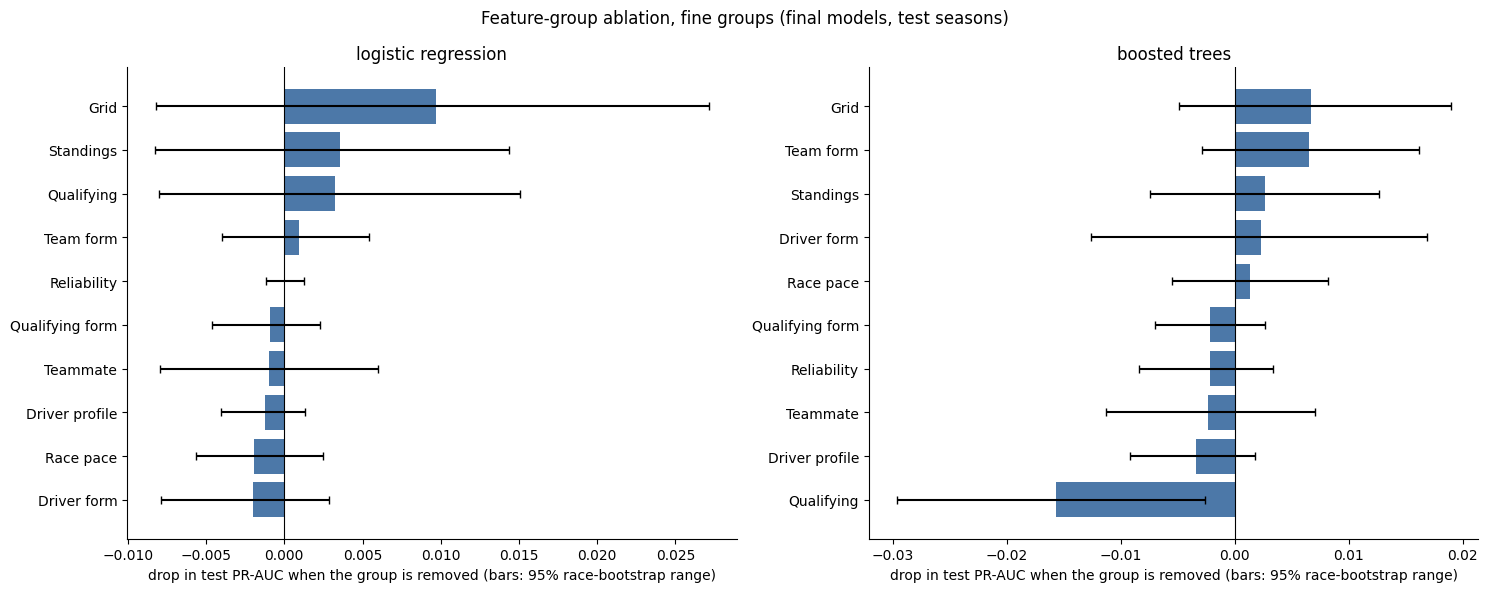

In [72]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, log_loss

# the exact data of the 14.7 final models: Xtv / ytv (train + validation, final preprocessing) and Xte (test)
assert Xtv.shape[1] == len(MODEL_FEATURES) == Xte.shape[1]

def refit_logistic(cols):
    idx = [MODEL_FEATURES.index(c) for c in cols]
    m = LogisticRegression(C=1.0, max_iter=3000).fit(Xtv[:, idx], ytv, sample_weight=train_weights(tv))
    return m.predict_proba(Xte[:, idx])[:, 1]

def refit_trees(cols):
    idx = [MODEL_FEATURES.index(c) for c in cols]
    m = HistGradientBoostingClassifier(random_state=SEED, early_stopping=False, **TREE_PARAMS).fit(Xtv[:, idx], ytv, sample_weight=train_weights(tv))
    return m.predict_proba(Xte[:, idx])[:, 1]

def final_ablation(refit, name, groups):
    p_full = refit(MODEL_FEATURES)
    ap_full, ll_full = average_precision_score(y["test"], p_full), log_loss(y["test"], p_full)
    rows = []
    for g, cols in groups.items():
        p_wo = refit([c for c in MODEL_FEATURES if c not in cols])
        lo, hi = paired_gain({"test": p_full}, {"test": p_wo}, "test")      # PR-AUC(with) - PR-AUC(without), bootstrapped over races
        ap_wo, ll_wo = average_precision_score(y["test"], p_wo), log_loss(y["test"], p_wo)
        rows.append({"group removed": g, "columns removed": len(cols),
                     "PR-AUC with": ap_full, "PR-AUC without": ap_wo, "drop": ap_full - ap_wo,
                     "range low": lo, "range high": hi, "measurable": "helps" if lo > 0 else ("hurts" if hi < 0 else "no"),
                     "log-loss with": ll_full, "log-loss without": ll_wo, "log-loss increase": ll_wo - ll_full})
    print(f"{name}: full model, test PR-AUC {ap_full:.4f}, log-loss {ll_full:.4f}")
    return pd.DataFrame(rows).set_index("group removed").sort_values("drop", ascending=False), p_full

def plot_ablation(t_lr, t_gb, title):
    fig, axes = plt.subplots(1, 2, figsize=(15, max(3.5, 0.45 * len(t_lr) + 1.5)))
    for ax, (name, t) in zip(axes, (("logistic regression", t_lr), ("boosted trees", t_gb))):
        t = t.iloc[::-1]
        err = np.vstack([t["drop"] - t["range low"], t["range high"] - t["drop"]])
        ax.barh(t.index, t["drop"], xerr=err, color="#4C78A8", capsize=3)
        ax.axvline(0, color="black", lw=0.8)
        ax.set_title(f"{name}")
        ax.set_xlabel("drop in test PR-AUC when the group is removed (bars: 95% race-bootstrap range)")
    fig.suptitle(title)
    plt.tight_layout(); plt.show()

abl_lr, p_full_lr = final_ablation(refit_logistic, "logistic regression (final)", GROUPS_FINE)
d = np.abs(p_full_lr - p_refit["logistic, all features (baseline)"]).max()
print("check: full model here equals the 14.7 final model, max prediction difference:", d)
display(abl_lr.round(4))

abl_gb, p_full_gb = final_ablation(refit_trees, "boosted trees (final)", GROUPS_FINE)
print("14.7 prediction keys:", list(p_refit))
display(abl_gb.round(4))

plot_ablation(abl_lr, abl_gb, "Feature-group ablation, fine groups (final models, test seasons)")

**Coarse groups.** Some fine groups hold a single column, and several describe the same thing (grid, qualifying and qualifying form all describe where the driver starts), so removing one of them can be covered by another. To measure whole sources of information, the same test is repeated with five broader groups built by merging the fine ones: *grid and qualifying*, *recent form* (driver form, team form, race pace, reliability), *teammate comparison*, *standings* and *driver profile*. These groupings were fixed before any result was seen.

logistic regression (final), coarse groups: full model, test PR-AUC 0.7065, log-loss 0.2569


,columns removed,PR-AUC with,PR-AUC without,drop,range low,range high,measurable,log-loss with,log-loss without,log-loss increase
group removed,,,,,,,,,,
Grid and qualifying,10,0.7065,0.5939,0.1126,0.0639,0.1560,helps,0.2569,0.2644,0.0075
Recent form,11,0.7065,0.7025,0.0040,-0.0110,0.0207,no,0.2569,0.2622,0.0053
Standings,5,0.7065,0.7029,0.0036,-0.0083,0.0144,no,0.2569,0.2592,0.0023
Teammate comparison,4,0.7065,0.7074,-0.0010,-0.0079,0.0060,no,0.2569,0.2583,0.0014
Driver profile,3,0.7065,0.7077,-0.0012,-0.0040,0.0013,no,0.2569,0.2571,0.0001


boosted trees (final), coarse groups: full model, test PR-AUC 0.7027, log-loss 0.2208


,columns removed,PR-AUC with,PR-AUC without,drop,range low,range high,measurable,log-loss with,log-loss without,log-loss increase
group removed,,,,,,,,,,
Grid and qualifying,10,0.7027,0.6254,0.0772,0.0349,0.1184,helps,0.2208,0.2474,0.0266
Standings,5,0.7027,0.7000,0.0026,-0.0074,0.0127,no,0.2208,0.2249,0.0040
Recent form,11,0.7027,0.7021,0.0006,-0.0156,0.0168,no,0.2208,0.2198,-0.0011
Teammate comparison,4,0.7027,0.7050,-0.0024,-0.0113,0.0070,no,0.2208,0.2204,-0.0004
Driver profile,3,0.7027,0.7060,-0.0034,-0.0091,0.0018,no,0.2208,0.2203,-0.0006


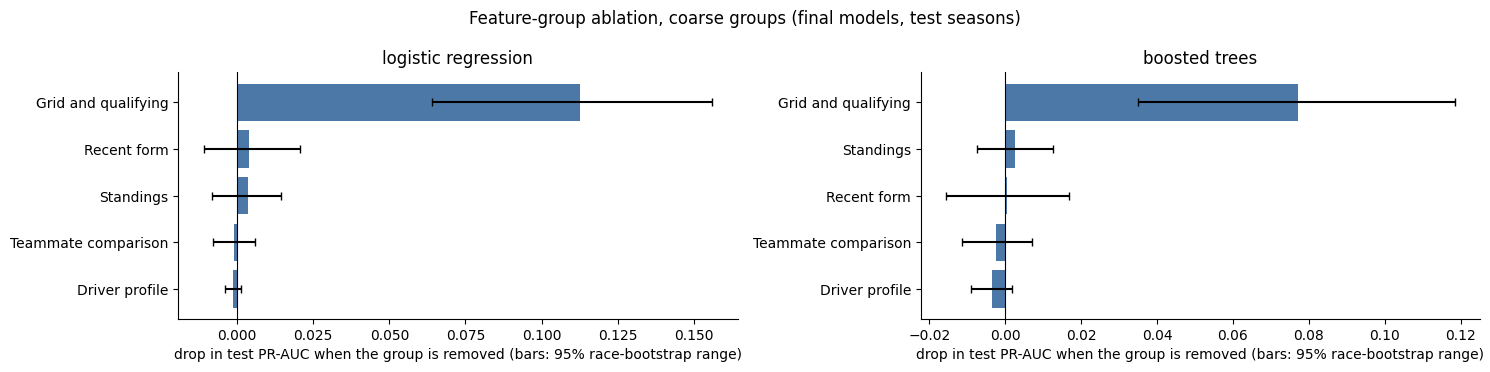

In [73]:
abl_lr_c, _ = final_ablation(refit_logistic, "logistic regression (final), coarse groups", GROUPS_COARSE)
display(abl_lr_c.round(4))
abl_gb_c, _ = final_ablation(refit_trees, "boosted trees (final), coarse groups", GROUPS_COARSE)
display(abl_gb_c.round(4))

plot_ablation(abl_lr_c, abl_gb_c, "Feature-group ablation, coarse groups (final models, test seasons)")

In [74]:
yr = SPLITS["test"]["year"].values
cols_q = GROUPS_FINE["Qualifying"]
rows = []
for name, refit in (("logistic", refit_logistic), ("trees", refit_trees)):
    p_with = refit(MODEL_FEATURES)
    p_wo = refit([c for c in MODEL_FEATURES if c not in cols_q])
    for s in sorted(set(yr)):
        m = yr == s
        rows.append({"model": name, "season": s, "races": SPLITS["test"].loc[m, "raceId"].nunique(),
                     "PR-AUC with": average_precision_score(y["test"][m], p_with[m]),
                     "PR-AUC without": average_precision_score(y["test"][m], p_wo[m]),
                     "log-loss with": log_loss(y["test"][m], p_with[m]),
                     "log-loss without": log_loss(y["test"][m], p_wo[m]),
                     "mean predicted with": p_with[m].mean(), "mean predicted without": p_wo[m].mean(),
                     "actual podium rate": y["test"][m].mean()})
display(pd.DataFrame(rows).round(4))

drift = pd.concat([SPLITS[k][cols_q].assign(split=k) for k in SPLITS])
display(drift.groupby("split")[cols_q].agg(["mean", "std"]).round(3).loc[["train", "validation", "test"]])

,model,season,races,PR-AUC with,PR-AUC without,log-loss with,log-loss without,mean predicted with,mean predicted without,actual podium rate
0,logistic,2022,22,0.7007,0.6917,0.2099,0.2065,0.1494,0.1509,0.1503
1,logistic,2023,22,0.7402,0.7393,0.3120,0.2299,0.1457,0.1456,0.1507
2,logistic,2024,24,0.6697,0.6586,0.2496,0.2355,0.1695,0.1652,0.1503
3,trees,2022,22,0.6518,0.6837,0.2155,0.2102,0.1577,0.1548,0.1503
4,trees,2023,22,0.7455,0.7389,0.2258,0.2290,0.1502,0.1436,0.1507
5,trees,2024,24,0.6983,0.7058,0.2211,0.2183,0.1661,0.1553,0.1503


q_pos        q_gap_pct        q1_gap_pct        q_last_gap_pct        q_knockout        has_quali       
              mean    std      mean    std       mean    std           mean    std       mean    std      mean    std
split                                                                                                                
train       11.365  6.361     2.510  2.573      2.024  1.995          1.064  1.332       0.26  0.439     0.363  0.481
validation  10.479  5.763     2.046  2.249      1.404  1.545          0.899  1.686       1.00  0.000     0.988  0.107
test        10.490  5.760     1.908  2.629      1.072  1.466          0.857  3.183       1.00  0.000     0.990  0.097

**Reading the ablation.**
* **Coarse groups:** only removing *grid and qualifying* together is measurable, in both models: logistic PR-AUC 0.707 to 0.594 (drop 0.113, range 0.064 to 0.156), trees 0.703 to 0.625 (drop 0.077, range 0.035 to 0.118). Every other coarse group has a range that crosses 0.
* **Fine groups:** no single group has a measurable drop in either model. The largest are Grid for the logistic regression (0.010, range -0.008 to 0.027) and Grid (0.007, range -0.005 to 0.019) and Team form (0.007, range -0.003 to 0.016) for the trees. The groups that describe the starting position and the car's strength cover for each other, so removing one costs little while the others remain.

**The Qualifying group does not help the PR-AUC on the test seasons.** Removing its six columns (the four qualifying values, `q_knockout` and `has_quali`) leaves the logistic PR-AUC almost unchanged (0.7065 to 0.7033) but lowers its log-loss from 0.2569 to 0.2243. For the trees, removing them *raises* PR-AUC from 0.703 to 0.718, with a range entirely below 0 (-0.030 to -0.003): the qualifying columns measurably hurt the trees on these seasons.

Two cautions. First, the effect is not the same every season: the logistic log-loss gain comes almost entirely from 2023 (0.312 to 0.230), while the logistic PR-AUC is slightly higher *with* the qualifying columns in every season; the trees do better without them in 2022 (0.652 to 0.684) and 2024 (0.698 to 0.706) and worse in 2023 (0.746 to 0.739). Second, `q_last_gap_pct` is much more spread out in the test seasons (standard deviation 3.18) than in training (1.33) and validation (1.69), so a few extreme values are present; 14.10 looks at them row by row.

**What we do with this.** The qualifying columns were selected on the rolling folds (2010-2019) and we keep them in the final model: changing the feature list after seeing the test results would turn the test seasons into a selection tool and make the reported test score too optimistic. The finding is reported as a limitation.

### 14.10 Error analysis: what goes wrong with the qualifying columns on the test seasons?

**Question.** The ablation found that the qualifying columns do not help the final models on 2022-24, and that `q_last_gap_pct` is about twice as spread out in the test seasons as in training. Is the problem the whole qualifying group, or a few unusual rows?

**What we do and why.** We look at the test rows whose `q_last_gap_pct` is above the 99th percentile of the training rows: which races and drivers they are, how far out they sit in training standard deviations, and how much of the final logistic regression's loss they cause, compared with the same model fitted without the qualifying columns. If a handful of rows causes most of the difference, the problem is a few extreme values, not the information in the columns.

**This is an explanation, not a selection.** It uses the test seasons, so nothing in the final model is changed because of it.

In [75]:
names = T["races"].set_index("raceId")["name"]
surname = T["drivers"].set_index("driverId")["surname"]
cut = train_m["q_last_gap_pct"].quantile(0.99)
mu, sd = train_m["q_last_gap_pct"].mean(), train_m["q_last_gap_pct"].std()
p_with = refit_logistic(MODEL_FEATURES)
p_wo = refit_logistic([c for c in MODEL_FEATURES if c not in GROUPS_FINE["Qualifying"]])

ea = test_m[["year", "raceId", "driverId", "grid", "q_gap_pct", "q_last_gap_pct", "podium"]].copy()
ea["race"], ea["driver"] = ea["raceId"].map(names), ea["driverId"].map(surname)
ea["sd from training mean"] = (ea["q_last_gap_pct"] - mu) / sd
ea["p with qualifying"], ea["p without qualifying"] = p_with, p_wo
ea["loss with"], ea["loss without"] = row_loss(ea["podium"].to_numpy(), p_with), row_loss(ea["podium"].to_numpy(), p_wo)
extreme = ea["q_last_gap_pct"] > cut

print(f"training 99th percentile of q_last_gap_pct: {cut:.2f} % | test rows above it: {int(extreme.sum())} of {len(ea)}")
display(ea[extreme].sort_values("q_last_gap_pct", ascending=False)[["year", "race", "driver", "grid", "q_gap_pct", "q_last_gap_pct", "sd from training mean",
                                                                    "podium", "p with qualifying", "p without qualifying", "loss with", "loss without"]].round(3))
extra_all = (ea["loss with"] - ea["loss without"]).sum()
extra_ext = (ea.loc[extreme, "loss with"] - ea.loc[extreme, "loss without"]).sum()
print(f"test log-loss with minus without the qualifying columns: {extra_all / len(ea):+.4f} per row")
print(f"the same, without the {int(extreme.sum())} extreme rows: {(extra_all - extra_ext) / (~extreme).sum():+.4f} per row")


training 99th percentile of q_last_gap_pct: 5.29 % | test rows above it: 15 of 1356


,year,race,driver,grid,q_gap_pct,q_last_gap_pct,sd from training mean,podium,p with qualifying,p without qualifying,loss with,loss without
602,2023,Austrian Grand Prix,Pérez,15,1.221,93.630,69.489,1,0.000,0.121,13.816,2.116
478,2023,Saudi Arabian Grand Prix,Sargeant,20,45.596,42.886,31.396,0,0.000,0.000,0.000,0.000
212,2022,Austrian Grand Prix,Norris,10,2.071,29.757,21.540,0,0.000,0.048,0.000,0.049
465,2023,Saudi Arabian Grand Prix,Verstappen,15,0.562,22.920,16.407,1,0.000,0.199,9.216,1.613
195,2022,British Grand Prix,Latifi,10,2.894,21.897,15.639,0,0.000,0.007,0.000,0.007
1296,2024,Las Vegas Grand Prix,Hamilton,10,0.276,17.109,12.045,1,0.001,0.129,7.558,2.045
199,2022,Austrian Grand Prix,Hamilton,8,0.756,12.568,8.636,1,0.006,0.257,5.139,1.359
69,2022,Emilia Romagna Grand Prix,Stroll,15,1.966,11.557,7.877,0,0.000,0.005,0.000,0.005
697,2023,Dutch Grand Prix,Sargeant,10,8.759,8.759,5.777,0,0.000,0.010,0.000,0.010
1107,2024,British Grand Prix,Gasly,19,16.296,7.977,5.190,0,0.000,0.002,0.000,0.002


test log-loss with minus without the qualifying columns: +0.0181 per row
the same, without the 15 extreme rows: -0.0023 per row


**Reading the result.** **A handful of rows causes the whole problem.**
* 15 of 1,356 test rows have `q_last_gap_pct` above the training 99th percentile (5.29 %). With the qualifying columns, the test log-loss is higher by **+0.0181 per row**; without these 15 rows the sign flips, and the qualifying columns *lower* the log-loss by 0.0023 per row.
* **The worst row:** Pérez at the 2023 Austrian Grand Prix. His last qualifying time was 93.6 % slower than the fastest in that session, **69 training standard deviations** from the mean, although his best time was only 1.2 % off pole (`q_gap_pct`). A gap like that is not a measure of pace; most likely the recorded lap was not a real attempt (for example an aborted lap). The model, which never saw such a value, put his podium chance at 0.000; he finished on the podium, and this one row costs a log-loss of 13.8 (2.1 without the qualifying columns).
* Three other real podium finishers show the same pattern: Verstappen (2023 Saudi Arabia, 22.9 %), Hamilton (2024 Las Vegas, 17.1 %) and Hamilton (2022 Austria, 12.6 %). Each had a small `q_gap_pct` but a huge `q_last_gap_pct`, and each was given a podium chance under 0.01.

So the qualifying columns are not useless on the test seasons; on the other 1,341 rows they help. The problem is that `q_last_gap_pct` can record a lap that was not a real attempt, which produces values far outside anything in training. This is a weakness of how that column is defined, and it is a limitation of the final model.

**Post-hoc check: would capping the extreme values have helped?** Capping was tested in 11.4 on the validation seasons and not adopted (no gain). Validation has no values like the test rows above, so that test could not show a benefit. Here we cap `q_gap_pct` and `q_last_gap_pct` at the 99th percentile of the training + validation rows, refit the final logistic regression and trees, and score the test seasons.

**This check was prompted by the test result.** It is therefore **not used in the final model**, and its test score is not an unbiased estimate; it only tests whether the extreme values explain the loss.

In [76]:
caps = {c: tv[c].quantile(0.99) for c in ["q_gap_pct", "q_last_gap_pct"]}
capped = lambda d: d.assign(**{c: d[c].clip(upper=v) for c, v in caps.items()})
pp_cap = build_prep(capped(tv), ADOPTED)
Xtv_c, Xte_c = pp_cap(capped(tv)), pp_cap(capped(test_m))
rows = []
for name, make in (("logistic regression", lambda: LogisticRegression(C=1.0, max_iter=3000)),
                   ("boosted trees", lambda: HistGradientBoostingClassifier(random_state=SEED, early_stopping=False, **TREE_PARAMS))):
    p0 = make().fit(Xtv, ytv, sample_weight=train_weights(tv)).predict_proba(Xte)[:, 1]
    p1 = make().fit(Xtv_c, ytv, sample_weight=train_weights(tv)).predict_proba(Xte_c)[:, 1]
    lo, hi = paired_gain({"test": p1}, {"test": p0}, "test")
    rows.append({"model": name, "test PR-AUC (final)": average_precision_score(y["test"], p0), "test PR-AUC (capped)": average_precision_score(y["test"], p1),
                 "change": average_precision_score(y["test"], p1) - average_precision_score(y["test"], p0), "range low": lo, "range high": hi,
                 "test log-loss (final)": log_loss(y["test"], p0), "test log-loss (capped)": log_loss(y["test"], p1)})
print("caps (99th percentile of training + validation rows):", {c: round(float(v), 2) for c, v in caps.items()})
display(pd.DataFrame(rows).set_index("model").round(4))


caps (99th percentile of training + validation rows): {'q_gap_pct': 11.25, 'q_last_gap_pct': 5.25}


,test PR-AUC (final),test PR-AUC (capped),change,range low,range high,test log-loss (final),test log-loss (capped)
model,,,,,,,
logistic regression,0.7065,0.7094,0.0029,-0.0002,0.0066,0.2569,0.2265
boosted trees,0.7027,0.7027,0.0000,0.0000,0.0000,0.2208,0.2208


**Reading the result.** Capping the two gap columns at the 99th percentile (`q_gap_pct` 11.25 %, `q_last_gap_pct` 5.25 %) changes the logistic regression's test PR-AUC from 0.7065 to 0.7094 (+0.0029, range -0.0002 to +0.0066) and its log-loss from 0.2569 to 0.2265, close to the 0.2243 of the model without any qualifying columns (14.9). The trees do not change at all (0.7027): a tree splits on the order of the values, and moving the most extreme values to the cap leaves the same splits. This confirms 14.10: the loss comes from the extreme values, not from the information in the columns. Because the check was prompted by the test result, **the final model is not changed**; for a future version, a cap (or a definition of `q_last_gap_pct` that ignores laps that were not real attempts) should be chosen on training and validation data alone.

### 14.11 Would a random split have given the same score?

**Question.** Section 8 splits by season. A common alternative is a random 70/30 split of all rows. Does the choice change the score?

**What we do and why.** The final logistic regression (same features, same preprocessing) is trained 20 times on a random 70 % of the rows from 1950-2024 and scored on the other 30 %, once drawing single rows and once drawing whole races. A random test set mixes easier and harder seasons, so its overall score cannot be compared with ours directly. The fair comparison uses **the same rows**: in each repeat we take the random test rows that fall in 2022-24 and score both the random-split model and our time-based final model (trained on 1950-2021) on exactly those rows. If the random split scores higher, the difference is the head start it gets from training on races of the very seasons it is tested on, which a real prediction before a future race never has.

In [77]:
from sklearn.model_selection import train_test_split, GroupShuffleSplit

pool_r = pd.concat([train_m, valid_m, test_m]).reset_index(drop=True)
p_time = p_refit["logistic, all features (baseline)"]                                    # our final model, trained up to 2021
first_test = len(train_m) + len(valid_m)                                                # test rows sit at the end of pool_r, in test_m order
rows = []
for kind in ("random rows", "random whole races"):
    for s in range(20):
        if kind == "random rows":
            tr_i, te_i = train_test_split(np.arange(len(pool_r)), test_size=0.3, random_state=s, stratify=pool_r["podium"])
        else:
            tr_i, te_i = next(GroupShuffleSplit(n_splits=1, test_size=0.3, random_state=s).split(pool_r, groups=pool_r["raceId"]))
        prep_r = build_prep(pool_r.iloc[tr_i], ADOPTED)
        m = LogisticRegression(C=1.0, max_iter=3000).fit(prep_r(pool_r.iloc[tr_i]), pool_r["podium"].iloc[tr_i], sample_weight=train_weights(pool_r.iloc[tr_i]))
        late = np.sort(te_i[te_i >= first_test])                                         # random test rows from 2022-24
        yy_ = pool_r["podium"].iloc[late].to_numpy()
        rows.append({"split": kind, "test rows in 2022-24": len(late),
                     "PR-AUC, random-split model": average_precision_score(yy_, m.predict_proba(prep_r(pool_r.iloc[late]))[:, 1]),
                     "PR-AUC, our time-based model (same rows)": average_precision_score(yy_, p_time[late - first_test])})
rs = pd.DataFrame(rows)
rs["head start"] = rs["PR-AUC, random-split model"] - rs["PR-AUC, our time-based model (same rows)"]
display(rs.groupby("split").mean().round(4))
print("repeats in which the random split scores higher:", rs.groupby("split")["head start"].apply(lambda s: f"{int((s > 0).sum())} of {len(s)}").to_dict())


,test rows in 2022-24,"PR-AUC, random-split model","PR-AUC, our time-based model (same rows)",head start
split,,,,
random rows,409.2,0.7135,0.7120,0.0015
random whole races,384.6,0.7152,0.7171,-0.0019


repeats in which the random split scores higher: {'random rows': '12 of 20', 'random whole races': '9 of 20'}


**Reading the result.** **With these features, a random split gives about the same score.** On the same 2022-24 rows, the random-split model scores PR-AUC 0.7135 against 0.7120 for our time-based model when single rows are drawn (+0.0015, higher in 12 of 20 repeats), and 0.7152 against 0.7171 when whole races are drawn (-0.0019, higher in 9 of 20). Both differences are tiny and the random split wins only about half the time.

This means our reported score does not depend on the choice of split, which answers the question directly. We still split by season, because that is the task: the model is used before a race in a future season, never on a random race from the past. A likely reason the random split gains so little here: every history feature already uses only earlier races (9.5), so even in a random split no row can see its own race.

## 15. Explaining the models

The brief asks for global explanations (permutation importance and SHAP) and local explanations (LIME and/or local SHAP). The final model is a logistic regression, so its explanation is its own weights (15.1): for a linear model the SHAP value of a feature is exactly its weight times the feature's distance from the average, so SHAP would only repeat the weights. The methods of 15.2 and 15.3 are applied to the two models that cannot be read directly, the **boosted trees** and the **neural network** (the final versions of 14.7).

**Important: these are not causal effects.** A feature that is important to a model is a feature the model *relies on* to predict; it is not proof that the feature causes podium finishes. For example, a high qualifying position and a podium both result from a fast car, and a model cannot tell them apart.

**Setup.** The final models are rebuilt exactly as in 14.7 (the check prints the largest difference from the 14.7 predictions), and the trees and the network are wrapped as functions from standardised rows to a podium probability, so every method treats them the same way.

In [78]:
import shap
from lime.lime_tabular import LimeTabularExplainer
from sklearn.ensemble import HistGradientBoostingClassifier

Xtv_df = pd.DataFrame(Xtv, columns=MODEL_FEATURES)
Xte_df = pd.DataFrame(Xte, columns=MODEL_FEATURES)

# the three final models of 14.7 (trained on train + validation seasons)
final_lr = LogisticRegression(C=1.0, max_iter=3000).fit(Xtv, ytv, sample_weight=train_weights(tv))
final_gb = HistGradientBoostingClassifier(random_state=SEED, early_stopping=False, **TREE_PARAMS).fit(Xtv, ytv, sample_weight=train_weights(tv))
nn_models = []                                  # the 5 networks of 14.7, kept this time
for s in SEEDS:
    keras.utils.set_random_seed(s)
    m = build_model(NN_WIDTHS)
    m.fit(Xtv.astype("float32"), ytv, sample_weight=train_weights(tv), epochs=NN_EPOCHS, batch_size=32, verbose=0)
    nn_models.append(m)

# each model as a function: standardised rows -> probability of a podium
def predict_lr(A):
    return final_lr.predict_proba(np.asarray(A))[:, 1]

def predict_trees(A):
    return final_gb.predict_proba(np.asarray(A))[:, 1]

def predict_nn(A):
    A = np.asarray(A, dtype="float32")
    return np.mean([m(A, training=False).numpy().ravel() for m in nn_models], axis=0)   # calling the model directly is much faster than .predict

MODELS = {"boosted trees": predict_trees, "neural network": predict_nn}          # the models explained in 15.2 and 15.3

# check: same predictions as 14.7
REFIT_KEY = {"logistic regression": "logistic, all features (baseline)", "boosted trees": "boosted trees, depth 3 (baseline)",
             "neural network": f"neural network, {NN_SHAPE} (average of 5 seeds)"}
for name, f in {"logistic regression": predict_lr, **MODELS}.items():
    print(f"{name}: max difference from 14.7:", round(float(np.abs(f(Xte) - p_refit[REFIT_KEY[name]]).max()), 4))


logistic regression: max difference from 14.7: 0.0
boosted trees: max difference from 14.7: 0.0
neural network: max difference from 14.7: 0.0


### 15.1 The final model: what the logistic regression's weights say

**What we do and why.** The final model is a logistic regression, so its weights are its explanation: each weight is the change in the log-odds of a podium when that feature rises by one standard deviation while the others stay the same. The 95% range comes from refitting the model on whole races redrawn 200 times (the same race bootstrap used everywhere in this notebook). For one prediction, each feature's contribution to the log-odds is its weight times its standardised value, which is exactly what a local SHAP value would show for this model.

**How to read it.** Several features measure the same thing: how strong the car is (form, standings, pace) and where the car starts (grid, qualifying). When features overlap, the model can share their effect between them in many ways, so a single weight can be small, unstable, or even point the opposite way from what one would expect, while the group as a whole still matters (the ablation in 14.9 tests whole groups). Weights are read as groups, never one by one, and never as causes.

,weight per sd,range low,range high
grid,-1.647,-1.816,-1.516
q_last_gap_pct,-0.250,-0.387,-0.134
has_quali,-0.227,-0.350,-0.140
q_pos,-0.221,-0.406,-0.014
team_pace_rec,-0.211,-0.340,-0.097
drv_champ_rank_before,-0.201,-0.306,-0.096
team_finish_rel_rec,-0.155,-0.301,-0.001
q_gap_pct,-0.133,-0.562,0.096
has_lap_times,-0.131,-0.192,-0.085
teammate_grid_rel,-0.130,-0.210,-0.054


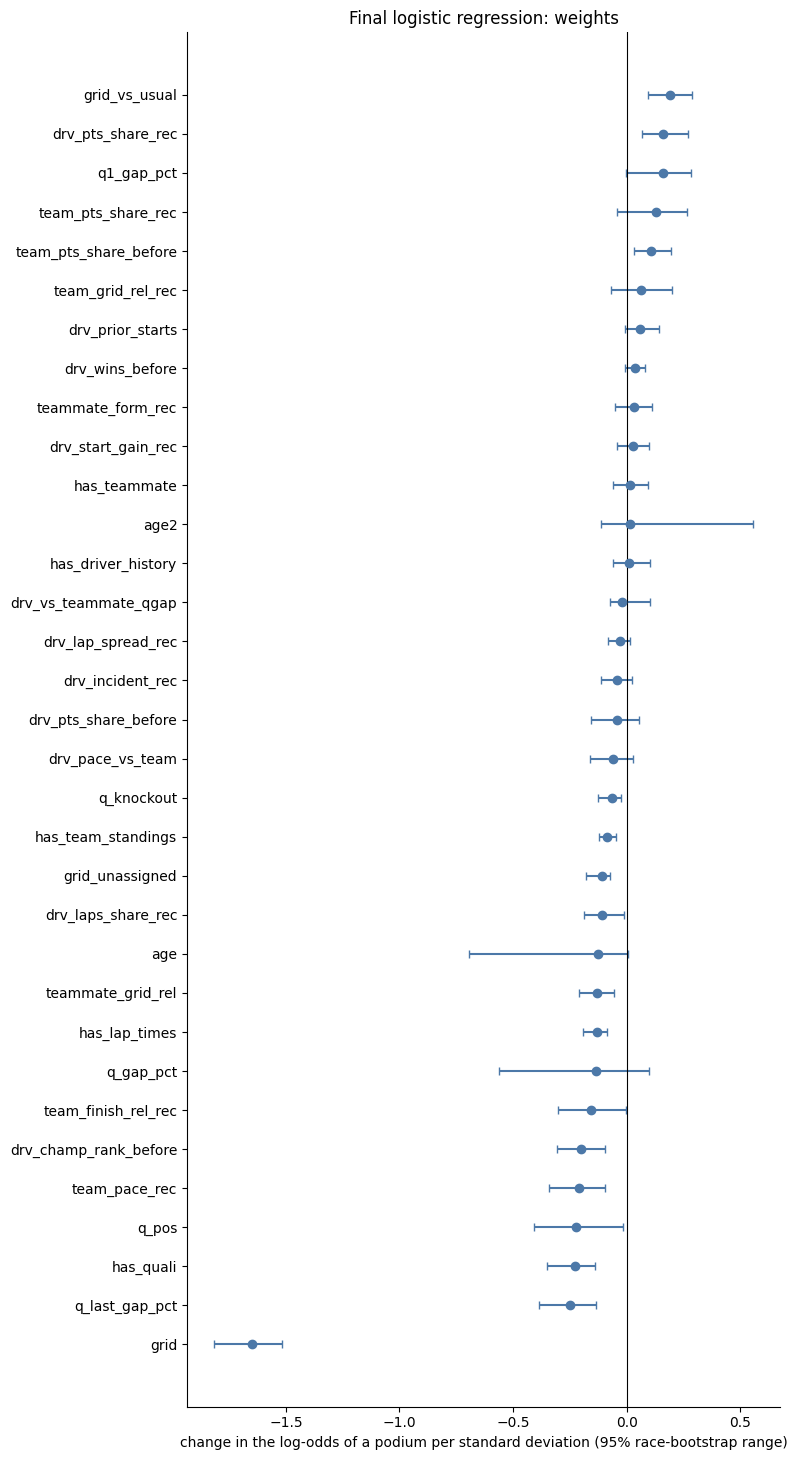

In [79]:
coef = pd.Series(final_lr.coef_[0], index=MODEL_FEATURES)
idx_tv = tv.groupby("raceId").indices
ids_tv = list(idx_tv)
rng_c = np.random.default_rng(SEED)
w_tv = train_weights(tv)
boot = []
for _ in range(200):
    i = np.concatenate([idx_tv[r] for r in rng_c.choice(ids_tv, len(ids_tv))])
    boot.append(LogisticRegression(C=1.0, max_iter=3000).fit(Xtv[i], ytv[i], sample_weight=None if w_tv is None else w_tv[i]).coef_[0])
lo_c, hi_c = np.percentile(boot, [2.5, 97.5], axis=0)
coef_tab = pd.DataFrame({"weight per sd": coef, "range low": lo_c, "range high": hi_c}).sort_values("weight per sd")
display(coef_tab.round(3))

fig, ax = plt.subplots(figsize=(8, 0.4 * len(coef_tab) + 1.5))
ax.errorbar(coef_tab["weight per sd"], range(len(coef_tab)),
            xerr=[coef_tab["weight per sd"] - coef_tab["range low"], coef_tab["range high"] - coef_tab["weight per sd"]], fmt="o", color="#4C78A8", capsize=3)
ax.set_yticks(range(len(coef_tab))); ax.set_yticklabels(coef_tab.index); ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("change in the log-odds of a podium per standard deviation (95% race-bootstrap range)")
ax.set_title("Final logistic regression: weights"); plt.tight_layout(); plt.show()


**Reading the result.** The weights confirm what the earlier sections found, with two lessons about overlapping features and flags.
* **The grid slot dominates:** -1.65 per standard deviation (range -1.82 to -1.52); a slot further back lowers the podium chance strongly.
* **Clear negative weights** (range below 0): the qualifying columns `q_last_gap_pct` -0.25 and `q_pos` -0.22, `team_pace_rec` -0.21 (a slower car), `drv_champ_rank_before` -0.20 (a lower championship rank), `team_finish_rel_rec` -0.16, `teammate_grid_rel` -0.13 and `grid_unassigned` -0.11.
* **Clear positive weights:** `grid_vs_usual` +0.19, `drv_pts_share_rec` +0.16 and `team_pts_share_before` +0.11. The sign of `grid_vs_usual` makes sense once the grid slot is held fixed: for the same slot today, a driver who *usually* starts further forward (a strong driver having a bad qualifying) is more likely to reach the podium.
* **The availability flags have negative weights** (`has_quali` -0.23, `has_lap_times` -0.13, `has_team_standings` -0.09, `q_knockout` -0.07). They are not "having qualifying data is bad news": a flag works together with the filled values of its columns (11.3). In rows without the source, the filled medians plus the flag's weight give the model's best guess; in rows with it, the real values take over. Only the combination can be read.
* **Twins split their effect:** `q_gap_pct` (-0.13) and `q1_gap_pct` (+0.16, range from -0.001) are a near-duplicate pair (9.7); the model uses their difference, so neither weight can be read alone. `age` and its square cross 0 as well.
* **Weights whose range crosses 0** (`q_gap_pct`, `team_pts_share_rec`, `drv_pts_share_before`, `drv_wins_before`, `drv_prior_starts`, the race-pace units and others) cannot be read on their own: their information is shared with the other car-strength columns.

As stated above, these weights describe how the model combines the features, not causes.

### 15.2 Global explanations: which features do the trees and the network rely on?

**Which models.** The final boosted trees and the final network of 14.7 (trained on 1950-2021), explained on the test seasons with the same two methods so they can be compared.

* **Permutation importance** shuffles one column of the test rows and measures how much the test PR-AUC falls; this is repeated 10 times per column, and the table shows the average fall and its spread (standard deviation) over the 10 shuffles. A fall of 0.10 means the PR-AUC drops by 0.10 (for example from 0.70 to 0.60) when the model can no longer use that column. It is an explanation, not a selection: nothing is chosen from it.
* **SHAP** shares each prediction among the features, the way a prize is shared among the players of a team according to what each contributed (Shapley values). We use SHAP's model-agnostic explainer, which only needs a function that returns the podium probability, so exactly the same method is applied to both models. The values are changes in the predicted podium probability. The mean of the absolute SHAP values over many rows gives a global importance, and the beeswarm plot also shows the direction. The background is 100 training rows and the explained rows are 300 randomly chosen test rows (a sample, because the network is slow to explain). SHAP estimates each value from a random sample of feature orderings (the exact value would need 2^33 combinations per row), so the explainer's seed is fixed: every run gives the same values.

**Important: these are not causal effects.** A feature that is important to a model is a feature the model *relies on* to predict; it is not proof that the feature causes podium finishes.

**Correlated features share importance.** Several columns describe the same thing (grid, qualifying, qualifying form). Shuffling one of them leaves the others, so permutation importance understates each of them; the group ablation of 14.9 is the better test of whole sources of information.

PR-AUC on the test seasons before shuffling: {'boosted trees': 0.7027, 'neural network': 0.6983}


boosted trees         neural network        
                          mean fall  spread      mean fall  spread
grid                         0.2398  0.0138         0.0483  0.0104
drv_pts_share_rec            0.0271  0.0095         0.0662  0.0145
team_pts_share_rec           0.0207  0.0109         0.0127  0.0063
drv_champ_rank_before        0.0176  0.0114         0.0004  0.0021
q_gap_pct                    0.0095  0.0108         0.0030  0.0016
drv_wins_before              0.0053  0.0042         0.0139  0.0072
drv_pace_vs_team             0.0039  0.0015        -0.0026  0.0032
q_last_gap_pct               0.0034  0.0049         0.0078  0.0099
grid_vs_usual                0.0034  0.0014         0.0409  0.0120
team_pace_rec                0.0032  0.0028         0.0008  0.0012
drv_pts_share_before         0.0032  0.0032         0.0034  0.0026
q_pos                        0.0030  0.0021         0.0492  0.0121
drv_prior_starts             0.0013  0.0025         0.0018  0.0032
drv_vs_teammate_qgap         0.0013  0.0037         0.0010  0.0057
teammate_form_rec            0.0008  0.0013        -0.0009  0.0028
team_finish_rel_rec          0.0003  0.0026         0.0060  0.0034
has_quali                    0.0000  0.0000         0.0016  0.0028
grid_unassigned              0.0000  0.0000         0.0065  0.0075
age2                         0.0000  0.0000         0.0008  0.0014
has_teammate                 0.0000  0.0000        -0.0002  0.0008
q_knockout                   0.0000  0.0000         0.0000  0.0000
has_driver_history           0.0000  0.0000         0.0027  0.0040
has_team_standings           0.0000  0.0000         0.0000  0.0000
has_lap_times               -0.0000  0.0000        -0.0001  0.0003
drv_incident_rec            -0.0002  0.0005         0.0009  0.0010
q1_gap_pct                  -0.0002  0.0014        -0.0006  0.0010
drv_start_gain_rec          -0.0003  0.0010         0.0026  0.0013
team_pts_share_before       -0.0003  0.0030         0.0001  0.0016
age                         -0.0006  0.0023         0.0001  0.0025
teammate_grid_rel           -0.0011  0.0010         0.0075  0.0037
drv_lap_spread_rec          -0.0015  0.0016        -0.0033  0.0017
team_grid_rel_rec           -0.0017  0.0010         0.0044  0.0012
drv_laps_share_rec          -0.0019  0.0015        -0.0012  0.0017

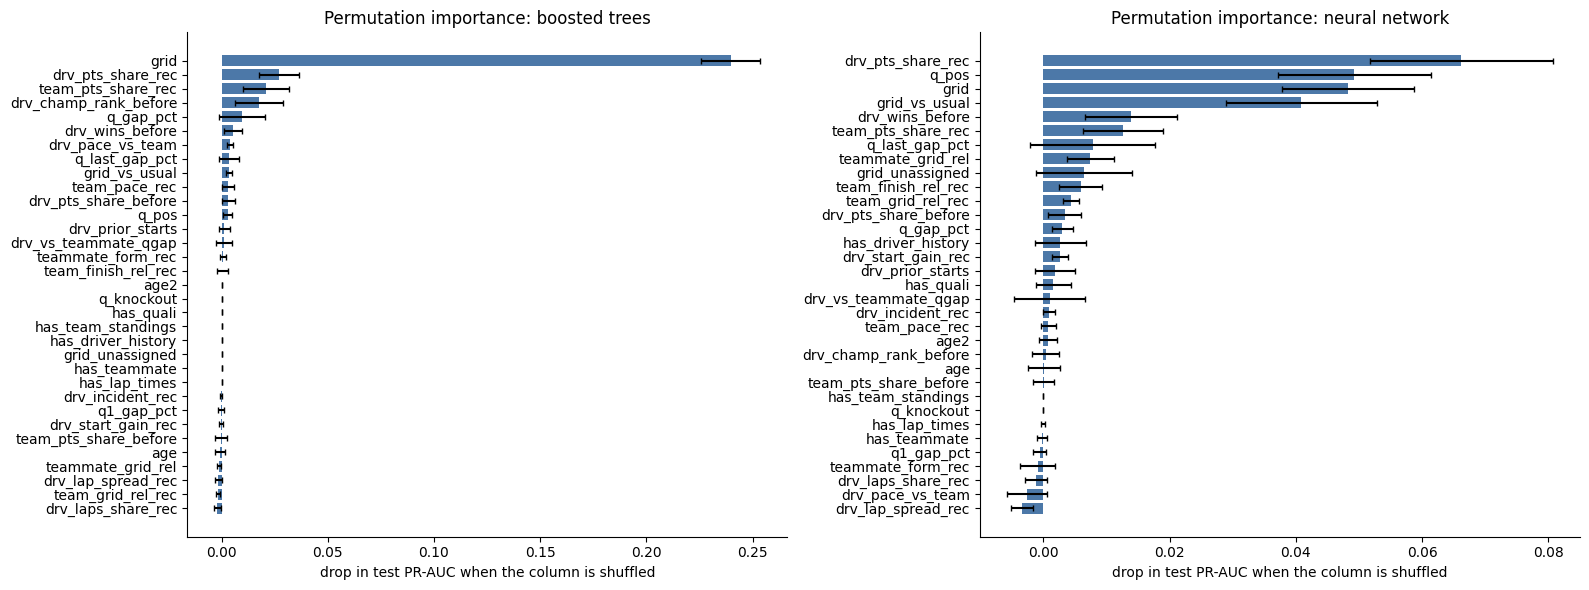

,boosted trees,neural network
grid,0.0899,0.0519
team_pts_share_rec,0.0331,0.0240
drv_pts_share_rec,0.0220,0.0477
drv_champ_rank_before,0.0188,0.0025
q_last_gap_pct,0.0104,0.0109
q_gap_pct,0.0099,0.0026
teammate_grid_rel,0.0052,0.0156
team_grid_rel_rec,0.0051,0.0022
team_finish_rel_rec,0.0050,0.0082
team_pts_share_before,0.0047,0.0062


boosted trees | rank agreement of permutation importance and SHAP (Spearman): 0.411
neural network | rank agreement of permutation importance and SHAP (Spearman): 0.497
rank agreement boosted trees vs neural network (SHAP): 0.491


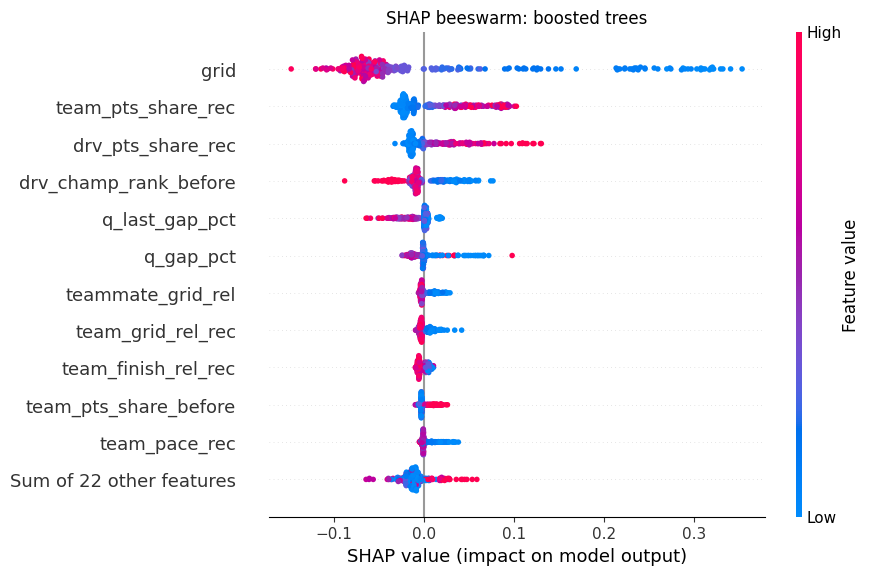

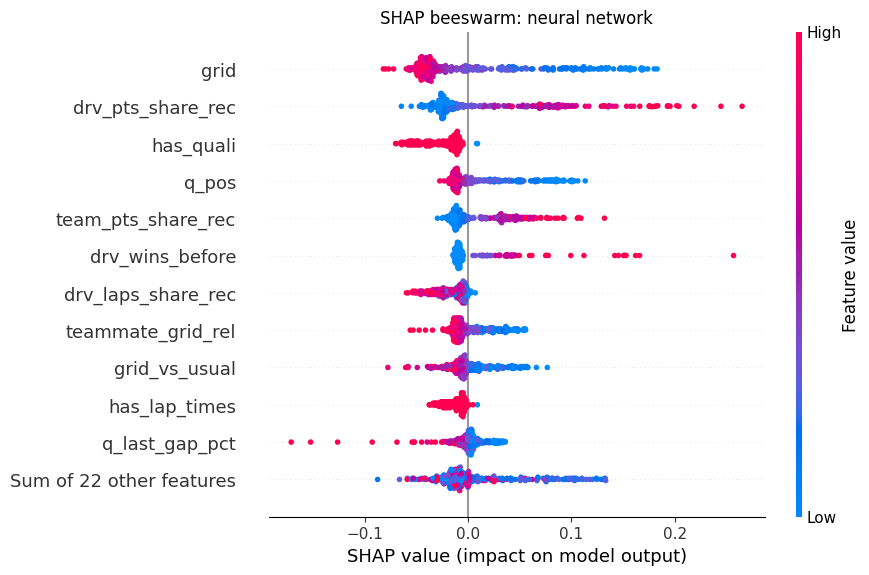

In [80]:
from sklearn.metrics import average_precision_score

# 1. permutation importance: shuffle one column of the test rows, see how much the PR-AUC falls
def permutation_drop(predict, X, y_true, n_repeats=10):      # 10 shuffles per column (scikit-learn's permutation_importance uses 5 by default)
    rng = np.random.default_rng(SEED)
    base = average_precision_score(y_true, predict(X))
    drops = []
    for j in range(X.shape[1]):
        d = []
        for _ in range(n_repeats):
            X_shuffled = X.copy()
            X_shuffled[:, j] = rng.permutation(X_shuffled[:, j])
            d.append(base - average_precision_score(y_true, predict(X_shuffled)))
        drops.append((np.mean(d), np.std(d)))
    return pd.DataFrame(drops, index=MODEL_FEATURES, columns=["mean fall", "spread"])

perm_full = pd.concat({name: permutation_drop(f, Xte, y["test"]) for name, f in MODELS.items()}, axis=1)
print("PR-AUC on the test seasons before shuffling:", {name: round(float(average_precision_score(y["test"], f(Xte))), 4) for name, f in MODELS.items()})
display(perm_full.sort_values(("boosted trees", "mean fall"), ascending=False).round(4))
perm = perm_full.xs("mean fall", axis=1, level=1)            # the average fall, used below

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, name in zip(axes, MODELS):
    o = perm[name].sort_values().index
    ax.barh(o, perm_full.loc[o, (name, "mean fall")], xerr=perm_full.loc[o, (name, "spread")], color="#4C78A8", capsize=2)
    ax.set_title(f"Permutation importance: {name}"); ax.set_xlabel("drop in test PR-AUC when the column is shuffled")
plt.tight_layout(); plt.show()

# 2. SHAP: same background and same test rows for both models
background = shap.sample(Xtv_df, 100, random_state=SEED)   # 100 background rows: a common size that keeps SHAP fast
rows_s = np.random.default_rng(SEED).choice(len(Xte_df), 300, replace=False)
# seed=SEED: SHAP estimates Shapley values from random feature orderings; fixing the seed makes every run give the same values
sv_all = {name: shap.Explainer(f, background, seed=SEED)(Xte_df.iloc[rows_s], silent=True) for name, f in MODELS.items()}

shap_imp = pd.DataFrame({name: np.abs(sv.values).mean(axis=0) for name, sv in sv_all.items()}, index=MODEL_FEATURES)
display(shap_imp.sort_values("boosted trees", ascending=False).round(4))

from scipy.stats import spearmanr
for name in MODELS:
    print(name, "| rank agreement of permutation importance and SHAP (Spearman):", round(spearmanr(perm[name], shap_imp[name])[0], 3))
from itertools import combinations
for a, b in combinations(MODELS, 2):
    print(f"rank agreement {a} vs {b} (SHAP):", round(spearmanr(shap_imp[a], shap_imp[b])[0], 3))

for name, sv in sv_all.items():
    shap.plots.beeswarm(sv, max_display=12, show=False)
    plt.title(f"SHAP beeswarm: {name}"); plt.show()

**Reading the result.** (The final logistic regression is read from its weights in 15.1; here are the trees and the network.)
* **How to read the permutation plot.** Each bar is how much the test PR-AUC falls when one column is shuffled; the error bar is the spread over 10 shuffles. A fall smaller than its spread cannot be told apart from 0, and a negative fall means the model did not gain from that column on these seasons.
* **Both models rely most on the grid slot** (mean absolute SHAP 0.090 for the trees, 0.052 for the network). For the trees it dominates: shuffling it lowers PR-AUC by 0.240, about nine times more than the next column (`drv_pts_share_rec`, 0.027). **The network spreads its reliance:** `drv_pts_share_rec` (0.066), `q_pos` (0.049), `grid` (0.048) and `grid_vs_usual` (0.041) are close in its permutation importance. A tree can split on the grid directly; the network uses several overlapping columns that all describe the starting position.
* **After the grid, each model picks different measures of the same idea:** the trees `team_pts_share_rec` (SHAP 0.033), `drv_pts_share_rec` (0.022) and `drv_champ_rank_before` (0.019); the network `drv_pts_share_rec` (0.048), `q_pos` (0.024) and `drv_wins_before` (0.018). All describe where the car starts or how strong car and driver are, so the two models' SHAP rankings agree only moderately (0.49).
* **Most columns are within their spread:** for example `q_gap_pct` in the trees (0.0095, spread 0.0108) and `q_last_gap_pct` in the network (0.0078, spread 0.0099). A few are slightly negative (trees `drv_laps_share_rec` -0.0019, network `drv_lap_spread_rec` -0.0033). Small or negative values do not prove a feature is useless: a near-copy still carries the information when one column is shuffled, which is why 14.9 removes whole groups.
* **The flags explain why the two methods agree only moderately** (Spearman 0.41 for the trees, 0.50 for the network). In the test seasons the flags are almost always 1, so shuffling them changes nothing: permutation importance about 0. SHAP compares each test row with *training* rows, mostly from seasons without qualifying data, so it gives the network's `has_quali` weight (0.026) for how a modern row differs from an old one, not for anything that varies between test drivers.

These importances describe what the models rely on, not causes, and correlated features share their importance.

### 15.3 Local explanations: why did the models make these two predictions?

**What we explain.** Two predictions, each chosen by a rule fixed before looking, among the 300 sampled test rows:
* **Row A, confident and correct:** the driver who really finished on the podium and whom the two models together gave the highest probability.
* **Row B, confident and wrong:** the driver who did **not** finish on the podium and whom the two models together gave the highest probability.

Row A shows how the models reach a confident correct call; row B shows what misleads them.

* **Local SHAP (waterfall plot)** starts from the average prediction and shows how each feature moves this one prediction up or down, in probability points, until it reaches the model's prediction for the row. It is drawn for both models. The values shown next to the feature names are the real (unscaled) values, so `grid = 1` means pole position.
* **LIME** perturbs the row many times, asks the model for its prediction on each perturbed copy and fits a small linear model around the row. Its weights say which feature ranges push this prediction up or down. It is an approximation. It is drawn for both models, in real (unscaled) units.

As in 15.2, these explanations show what the models rely on for this row and are not causes.



Row A, confident and correct: 2022 Japanese Grand Prix, Verstappen, grid 1, finished on the podium: True
  boosted trees: predicted probability of a podium 0.901
  neural network: predicted probability of a podium 0.891


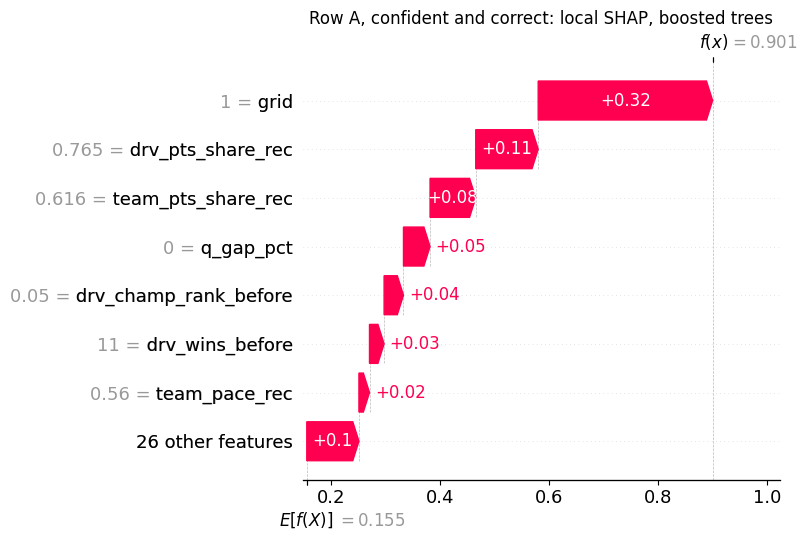

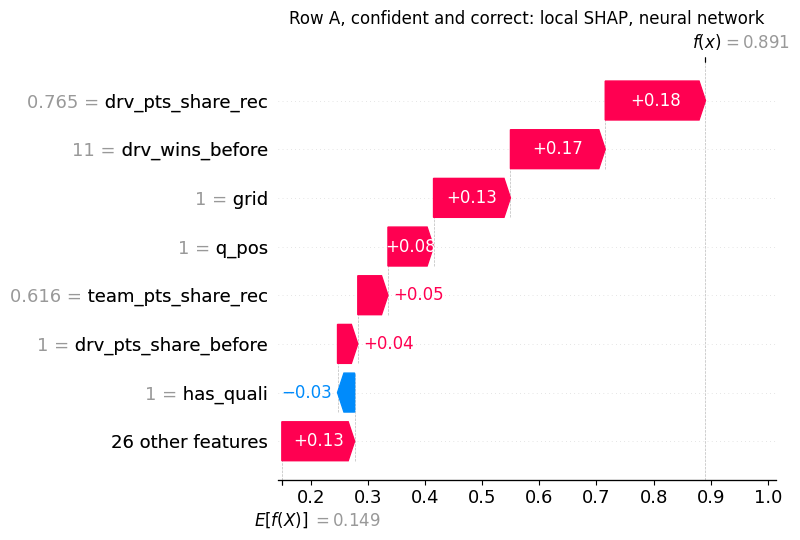

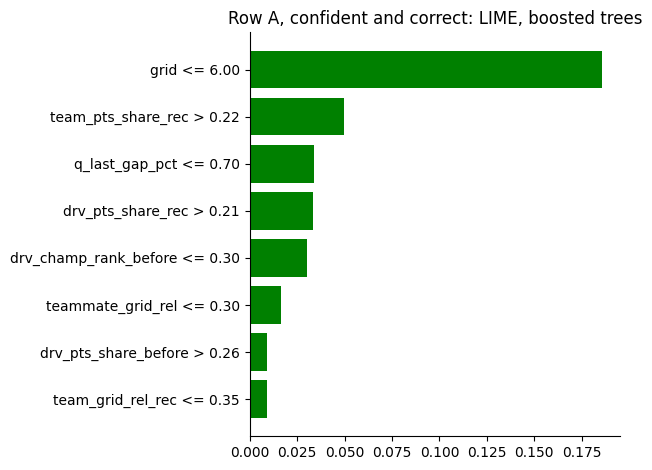

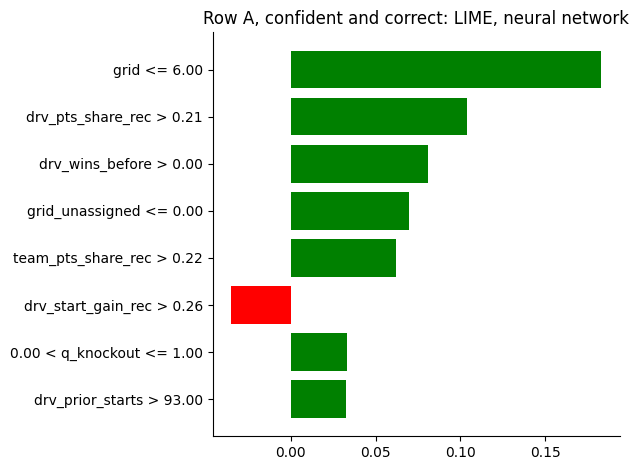


Row B, confident and wrong: 2024 Austrian Grand Prix, Verstappen, grid 1, finished on the podium: False
  boosted trees: predicted probability of a podium 0.849
  neural network: predicted probability of a podium 0.884


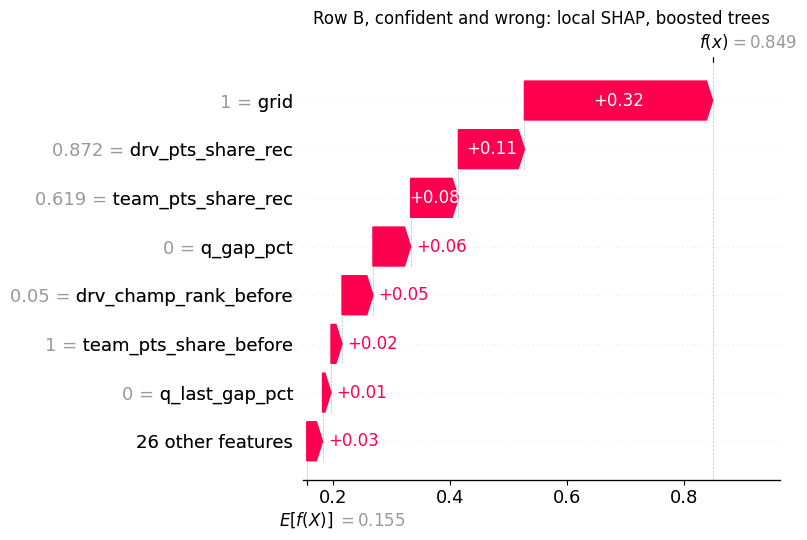

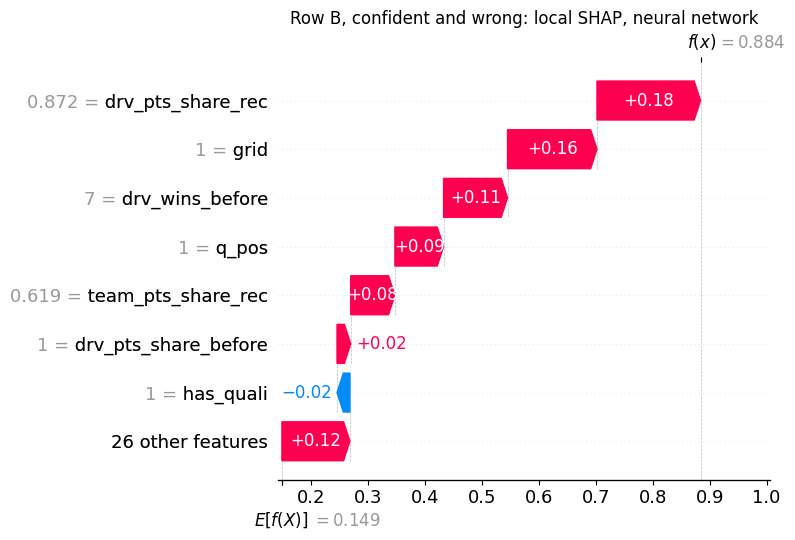

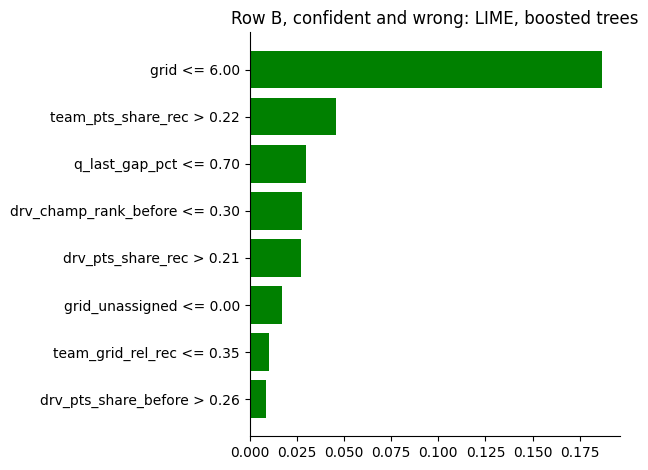

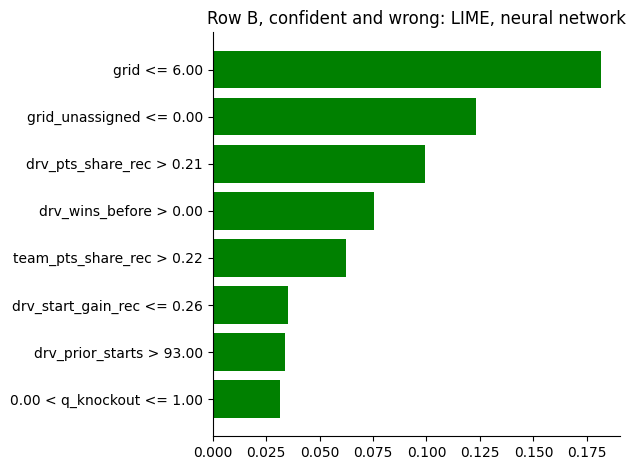

In [81]:
# raw (unscaled) values for the plots: gaps filled with the same medians the final preprocessing uses
med_tv = tv[MODEL_FEATURES].median()
raw_tv = tv[MODEL_FEATURES].fillna(med_tv).to_numpy(float)
raw_te = test_m[MODEL_FEATURES].fillna(med_tv).to_numpy(float)
to_model = lambda A: final_prep(pd.DataFrame(A, columns=MODEL_FEATURES))       # raw values -> the model's standardised inputs
lime_explainer = LimeTabularExplainer(raw_tv, feature_names=MODEL_FEATURES, class_names=["no podium", "podium"],
                                      discretize_continuous=True, random_state=SEED)
lime_fn = {name: (lambda A, f=f: np.column_stack([1 - f(to_model(A)), f(to_model(A))])) for name, f in MODELS.items()}   # LIME wants [P(no podium), P(podium)]

# 1. Choose the two rows by the rules above
sample_p = np.mean([f(Xte[rows_s]) for f in MODELS.values()], axis=0)
y_s = y["test"][rows_s]
podiums, others = np.where(y_s == 1)[0], np.where(y_s == 0)[0]
CASES = {"Row A, confident and correct": podiums[np.argmax(sample_p[podiums])],
         "Row B, confident and wrong": others[np.argmax(sample_p[others])]}

# 2. Explain each row: local SHAP and LIME for both models
for case, j in CASES.items():
    r = rows_s[j]                                  # position inside the test rows
    print(f"\n{case}: {test_m.loc[r, 'year']} {names[test_m.loc[r, 'raceId']]}, {surname[test_m.loc[r, 'driverId']]}, "
          f"grid {test_m.loc[r, 'grid']}, finished on the podium: {bool(test_m.loc[r, 'podium'])}")
    for name, f in MODELS.items():
        print(f"  {name}: predicted probability of a podium {float(f(Xte[[r]])[0]):.3f}")
    for name in MODELS:
        sv = sv_all[name][j]
        shap.plots.waterfall(shap.Explanation(values=sv.values, base_values=sv.base_values, data=raw_te[r], feature_names=MODEL_FEATURES),
                             max_display=8, show=False)
        plt.title(f"{case}: local SHAP, {name}"); plt.tight_layout(); plt.show()
    for name in MODELS:
        lime_result = lime_explainer.explain_instance(raw_te[r], lime_fn[name], num_features=8)   # changed from 10 (default) to 8: easier to read
        lime_result.as_pyplot_figure()
        plt.title(f"{case}: LIME, {name}"); plt.tight_layout(); plt.show()


**Reading the result.**

**Row A (2022 Japanese Grand Prix, Verstappen from pole, podium).** The trees give 0.901 and the network 0.891, starting from an average prediction of about 0.15. For the trees the pole position is the largest push (+0.32), followed by strong recent form (`drv_pts_share_rec` 0.765, +0.11), the team's points share (+0.08) and the zero gap to pole (+0.05). The network relies more on the season so far: recent form (+0.18) and 11 wins (+0.17) push most, then the grid slot (+0.13) and `q_pos = 1` (+0.08); `has_quali = 1` pushes slightly down (-0.03), the flag effect seen in 15.1. LIME tells the same story in raw values for both models: `grid <= 6` is by far the largest push, followed by a strong team (`team_pts_share_rec > 0.22`) and strong form (`drv_pts_share_rec > 0.21`); for the network, a high average gain on lap 1 (`drv_start_gain_rec > 0.26`) pushes slightly down.

**Row B (2024 Austrian Grand Prix, Verstappen from pole, no podium).** The trees give 0.849 and the network 0.884, and the explanations look almost the same as for row A: pole position (+0.32 for the trees, +0.16 for the network), strong form (`drv_pts_share_rec` 0.872, +0.11 and +0.18), 7 wins so far (+0.11 for the network), qualifying first and a top championship rank. The only push down is small (`has_quali`, -0.02 for the network). Nothing in the pre-race data warned of what happened: he finished 5th, so the podium was lost during the race itself. This is the limit of a pre-race model: crashes, failures and strategy are unknown at the cutoff.

**What the two rows show together.** The models are confident for the same reasons in both cases, and right in one and wrong in the other. A confident wrong prediction here is not a model error that better features could fix; it is the part of a race that cannot be known before the start.

## 16. Inference function: predicting one driver in one race

**What it does.** The function takes one raw record (the pre-race feature values of one driver in one race, with the names in `MODEL_FEATURES`, as a dictionary), prepares it with exactly the same preprocessing as the training data, and returns the final logistic regression's probability of a podium, the decision, and which values it had to fill. The final model is the logistic regression of 14.7 (trained on 1950-2021), and the threshold is the one frozen on the validation seasons (14.2).

**Same preprocessing as in training.** The record goes through `final_prep`, the recipe of 11.5 fitted in 14.7 (fill gaps with the training median, then standardise). Using the same object avoids a mismatch between training and prediction, a common source of silent errors.

**Missing values.** Any feature that is missing (absent from the dictionary or `None`) is filled with the training median, as in 11.2 and 11.3; the function lists which ones were filled. A filled value makes the driver look average on that feature. This can move the probability **up or down**: the direction depends on the sign of that feature's weight in the final model (15.1), and with overlapping features a weight can point the opposite way from what one would expect. The function does not guess: an unknown feature name raises an error. When a whole source is missing for the race (for example no qualifying data), its availability flag should be set to 0, as in training (9.6b); the demonstration below does this.

**Limits.** The function expects the feature values, not driver and race identifiers. Building them for a new race needs the feature pipeline of sections 5 to 9. All features are valid before the race (qualifying has finished), so the function can be used after qualifying and before the start.

In [82]:
final_lr = LogisticRegression(C=1.0, max_iter=3000).fit(Xtv, ytv, sample_weight=train_weights(tv))                 # the final model of 14.7
FINAL_THRESHOLD = best_threshold(y["validation"], p_lr["validation"])             # frozen on the validation seasons (14.2)

def predict_podium(record):
    """record: dict of raw pre-race feature values, with the names in MODEL_FEATURES. Missing or None values are allowed."""
    unknown = set(record) - set(MODEL_FEATURES)
    if unknown:
        raise ValueError(f"unknown feature names: {sorted(unknown)}")
    row = pd.DataFrame([{c: np.nan if record.get(c) is None else float(record[c]) for c in MODEL_FEATURES}])
    filled = [c for c in MODEL_FEATURES if row[c].isna().iloc[0]]
    x = final_prep(row)                                   # fill with the training median, then standardise (the preprocessing of 14.7)
    p = float(final_lr.predict_proba(x)[0, 1])
    return {"probability of a podium": round(p, 4),
            "decision": "podium" if p >= FINAL_THRESHOLD else "no podium",
            "threshold": round(FINAL_THRESHOLD, 4),
            "values filled with the training median": filled}

# --- demonstration on two records ---
complete_rows = test_m[test_m[MODEL_FEATURES].notna().all(axis=1) & (test_m["podium"] == 1)]
i = complete_rows.index[0]                                        # a real podium finisher whose values are all present
complete = test_m.loc[i, MODEL_FEATURES].to_dict()
Q_COLS = ("q_pos", "q_gap_pct", "q1_gap_pct", "q_last_gap_pct", "drv_vs_teammate_qgap")
partial = {k: v for k, v in complete.items() if k not in Q_COLS}   # qualifying values missing ...
partial["has_quali"] = 0                                            # ... and the flag says so, as it would for a race without qualifying data

print("complete record:", {k: round(v, 3) for k, v in complete.items()})
res_complete, res_partial = predict_podium(complete), predict_podium(partial)
display(pd.DataFrame({"complete record": res_complete, "partially missing record (qualifying absent)": res_partial}))

# check: the function gives the same probability as the batch prediction for that row
batch = float(final_lr.predict_proba(Xte[[test_m.index.get_loc(i)]])[0, 1])
print("function:", res_complete["probability of a podium"], "| batch prediction:", round(batch, 4))

complete record: {'grid': 5, 'grid_unassigned': 0, 'q_knockout': 1, 'has_quali': 1, 'has_lap_times': 1, 'has_team_standings': 1, 'has_driver_history': 1, 'has_teammate': 1, 'q_pos': 5.0, 'q_gap_pct': 0.541, 'q1_gap_pct': 0.89, 'q_last_gap_pct': 0.751, 'team_finish_rel_rec': 0.269, 'drv_pts_share_rec': 0.692, 'team_pts_share_rec': 0.545, 'drv_laps_share_rec': 0.974, 'teammate_grid_rel': 0.45, 'drv_vs_teammate_qgap': -0.225, 'teammate_form_rec': 0.684, 'drv_pts_share_before': 0.0, 'team_pts_share_before': 0.0, 'drv_champ_rank_before': 0.525, 'drv_wins_before': 0.0, 'drv_incident_rec': 0.05, 'team_grid_rel_rec': 0.223, 'grid_vs_usual': 0.087, 'team_pace_rec': 0.575, 'drv_pace_vs_team': -0.293, 'drv_start_gain_rec': 0.3, 'drv_lap_spread_rec': 0.026, 'age': 37.196, 'age2': 1383.575, 'drv_prior_starts': 288}


,complete record,partially missing record (qualifying absent)
probability of a podium,0.408,0.433
decision,podium,podium
threshold,0.3095,0.3095
values filled with the training median,[],"[q_pos, q_gap_pct, q1_gap_pct, q_last_gap_pct,..."


function: 0.408 | batch prediction: 0.408


**Reading the result.** The function gives exactly the batch prediction for the same row (0.408 both), so a record is prepared the same way as in training. The complete record (a real podium finisher from the test seasons: grid 5, qualified 5th, 0.54 % off pole) gets 0.408, above the frozen threshold of 0.3095, so the call is "podium". With the five qualifying values missing and `has_quali = 0` (as for a race without qualifying data), the values are filled with the training medians and the probability moves to 0.433. The changes pull in both directions (15.1): the filled `q_pos` (11 instead of 5) and `q_gap_pct` (1.97 % instead of 0.54 %) lower the prediction, while `has_quali = 0` (a negative weight, now switched off) and the twin `q1_gap_pct` (positive weight) raise it; here they almost cancel. A missing value never makes the function fail, but it can move the prediction either way, which is why the function reports which values it filled.

## 17. Summary and known limitations

**What this notebook established.**
1. **A clean table** with exactly one row per (race, driver): the duplicate rule (rule H, backed by the laps and endings of the repeated rows; it fails only when two drivers swapped cars, and those pairs are flagged), the Indy 500 exclusion and the treatment of non-starters are each backed by a table; all keys and foreign keys reconcile.
2. **48 candidate features in 16 concepts**, all valid at the pre-race cutoff; the history features passed the leak test (erasing the future changes nothing).
3. **Training on every season (8.2).** The models learn from every season from 1950 to 2019. Sources that do not exist in older seasons are marked by five availability flags (9.6b), and older seasons count less through recency weights with a half-life of 40 seasons (9.4b).
4. **A qualifying-format fix (7.3).** In single-session qualifying (1994-2005) `q_reached` was 1 for the whole field, pole-sitters included. These values are now missing and marked by `q_knockout`. The fix was found after the test seasons had been scored once (2003 version: test PR-AUC before the fix 0.7029 logistic, 0.6897 trees, 0.7005 network; after it 0.7046, 0.6913, 0.6974); it is based on the data definition, not on the test result.
5. **A final list of 24 units (33 columns with the 8 baseline columns and the square of age),** chosen on predictions of unseen seasons in two lenses: 10 of 16 concepts kept, near-copies removed. The p-value rule (Trial A, which silently drops to 5,757 complete rows) and one-at-a-time elimination (Trial B) are kept as trials (10.6). Two features (`team_pts_share_rec`, `drv_pts_share_rec`) carry most of the signal beyond the grid, but the full list is shown to add to them in the logistic lens (14.3).
6. **No later training start helps** (10.5; for the trees, starting in 2003 is measurably worse), **a preprocessing recipe** (median fill, then standardise; 11.4), and **a time-based split** whose score does not change with a random split (14.11).
7. **The three data-engineering questions** (section 13), answered with joins, figures and notes on grain, missingness and the cutoff.
8. **Three models on the same table** (logistic regression, boosted trees, a 32-16 network), all settings chosen without the test seasons, each refitted on 1950-2021 and scored once on test. Final test PR-AUC: logistic regression 0.707, trees 0.703, network 0.698. No model beats logistic regression with a range above 0, neither on validation nor on the rolling folds (14.6c), so the simplest, **logistic regression, is the final model**; the trees are slightly ahead on most scores, inside the noise. Its test scores: PR-AUC 0.707 (primary), F1 0.652 (secondary), ROC-AUC 0.920, precision 0.557, recall 0.784, top-3 hit rate 0.637, threshold 0.310.
9. **Ablation (14.9):** only the starting-position group as a whole (grid, qualifying, qualifying form) is measurably needed; the other groups overlap and can cover for each other.
10. **Explanations (section 15):** logistic regression is read from its weights; the trees and the network rely most on the grid slot, then on different measures of car and driver strength. Permutation importance and SHAP agree only moderately (Spearman 0.41 for the trees, 0.50 for the network), partly because SHAP compares test rows with training rows from older seasons, where the availability flags differ. **Importance is not causation.**
11. **Inference function (section 16):** predicts from a complete or partly missing record with the frozen preprocessing and threshold, and reports which values it filled.

**Known limitations.**
* **Extreme qualifying values on the test seasons (14.10).** A few laps that were not real attempts give `q_last_gap_pct` values far beyond anything in training (up to 69 sd). They cause all of the extra test log-loss of the qualifying columns; capping them would help the logistic regression (post-hoc check, not used). A future version should define the column more robustly or cap it, chosen on training data.
* **Overlapping features and flags.** Several columns measure car strength or starting position, and each flag works together with the filled values of its columns, so single weights and single importances must not be read alone (15.1).
* **The same races select and judge.** About 198 races of the rolling folds both chose the features and gave the evidence, so the gains are slightly optimistic; only gains above about 0.001 can be detected. The minimum gain (0.0005), the near-duplicate cut (0.9), `C = 1` and the "longest passing half-life" rule are judgements.
* **Few races in validation and test** (39 and 68): differences of a few thousandths between models are not meaningful.
* **Logistic regression is the more fragile model on extreme values** (14.10): the trees are unaffected by the extreme qualifying values that raise its test log-loss.
* **An information ceiling.** Other settings barely move the scores (14.4-14.5). What happens in the race (crashes, failures, strategy) cannot be known at the cutoff, as row B of 15.3 shows.
* **Era differences.** Qualifying data starts in 1994 and lap times in 1996, so for older seasons the models learn without them; the flags mark this but cannot replace the missing information. The 2022+ seasons follow regulations the model never saw. Renamed constructors reset team history.
* **Remaining tails.** Long tails stay because no treatment improved validation predictions; filling many rows with the median makes them look longer after scaling (11.5), and the tail screen misses symmetric heavy tails.
* **Sprint races** are not used: no training season has one (9.1); in 2021-22 their result is already in `grid`, from 2023 it is not.
* **The data-engineering answers are descriptive.** They use every season and no decision depends on them; the home-race and retirement answers are confounded by car strength and by how a status is worded (13.2, 13.3).